---
title: "Step 2.1. Cox preparation and evaluation: full-model discovery"
description: |
  This notebook begins the R Cox preparation and evaluation branch with a
  reproducible review of Table 1. It preserves the fixed development/holdout
  split, reproduces the historical descriptive export, and compares the current
  first development-only imputation with the authoritative manuscript.
  Changed published values require investigator review before downstream Cox
  work. The original full-model discovery, collinearity and NPH workflow is
  retained, with compact figures and cached objects. Sequential Full, VIF-reduced
  and discharge-stratified models have complete 5-fold/5-imputation C and IBS
  comparisons and 20-repeat/5-fold/5-imputation calibration. Predictive choices
  remain subject to investigator review before notebook 07.
date: last-modified
author: "Andres Gonzalez-Santa Cruz"
bibliography: [_lit/refs.bib]
csl: "_lit/american-medical-association.csl" # (Optional: citation style, e.g., APA)
toc: true
toc-location: left
toc-float: true
format:
  html:
    css: ["_lib/styles.scss", "_lib/prediction_metrics_compact.css"]
    code-fold: true
    embed-resources: true
    theme: 
      - journal #https://quarto.org/docs/output-formats/html-themes-more.html
    fig-cap-location: top  
    toc: true
    toc-location: left
execute:
  error: false       # Stop at the first execution error
  echo: true         # Show R code in the output
  warning: true      # Show warnings
  message: true      # Show messages from the code
  freeze: auto       # Use cache to speed up rendering if there are no changes
editor: source
execute-dir: project
lightbox: auto
---

<style>
.cell-output-stdout { max-height: 28rem; overflow-y: auto; }
</style>

Execution note: the server interruption on 2026-10-05 stopped computation after both Full and VIF-reduced comparisons and part of the stratified calibration. Completed signature-matched caches are reused. Fit counters describe only the current execution; the accompanying execution records preserve the interrupted segment. The final legacy status reports diagnostic fits separately from predictive CV/calibration fits.

## Accepted PH checkpoint and sequential stratification
The investigator accepted review signature `4bbfd50cae16` on 2026-10-04. The six checked Full-model eTable 10 values are retained as the current pipeline sources. Their p-value category remains <0.001; this decision does not imply unchanged predictive performance.
Stratification must follow the original sequence. At this Full-Cox stage, treatment modality is already a stratum. After the original collinearity reduction and the accepted first-imputation PH diagnostic, only rule-violation/undetermined discharge is moved from an ordinary coefficient to an additional stratum. Other significant PH terms are not automatically moved to strata. Later SHAP-informed and DeepSurv-derived models retain their own sequential diagnostic decisions.
The previous checkpoint and actual output inventory are recorded in [the diagnostics review](../docs/06_cox_diagnostics_checkpoint.md). The remaining diagnostic figures, the ten stratified Full-Cox fits and the original ancillary nested comparisons have now executed. The sequential stratification contract was verified in all ten saved stratified fits. Heavy CV/OOB/calibration remains unexecuted. The manuscript is unchanged.


Measured continuation: 72.33 seconds, peak R 2.02 GiB, 20 new Cox fits. A later presentation verification took 39.38 seconds with zero new fits. Current artifact signature: `714a6937a159`; this differs from the previous signature only because of plotting code. All cached numerical payloads were verified unchanged before reuse.


## Scope and current checkpoint
Table 1 is accepted. The original full-Cox discovery blocks follow in preparation mode. Encoding and descriptive checks can run; fitting, NPH figures and resampling await the resource checkpoint. No Word changes are permitted.


## Accepted Table 1 decision
The investigator explicitly accepted option A: adopt the current first-imputation Table 1 as the pipeline reference. The manuscript must never be edited by this pipeline. Counts and percentages describe the first completed dataset; no averaging across imputations is introduced here.
The guide configured as article2_table1_verification already retains this method. The clarification configured as article2_etable14_pooling_note concerns a separate comparison: eTable 14 averages and rounds stratum counts across the five imputations, whereas Table 1 uses the first. That note explicitly separates this explanation from the historical age discrepancy. The latter is documented, but its source will not be investigated again under this decision.
Notebook numbering follows the originally requested sequence: 00 preparation, 01-03 XGBoost, 04-05 reserved for DeepSurv, and 06 the first R Cox notebook. Reserved numbers do not indicate completed work or force the sensitivity branch to execute before the main Cox branch.

In [1]:
#| label: cox-config-and-environment
#| message: false
.t0 <- proc.time()
# Preserve Unicode labels when the Windows startup locale falls back to C.
if (.Platform$OS.type == "windows") stopifnot(nzchar(Sys.setlocale("LC_CTYPE", "English_United States.utf8")))
# Locate the only configuration file from either the project or notebook directory.
root <- normalizePath(getwd(), winslash = "/", mustWork = TRUE)
while (!file.exists(file.path(root, "config.yml"))) {
  parent <- dirname(root)
  if (identical(parent, root)) stop("config.yml was not found.", call. = FALSE)
  root <- parent
}
config <- yaml::read_yaml(file.path(root, "config.yml"))
resolve_path <- function(value) {
  absolute <- grepl("^([A-Za-z]:[/\\\\]|/|\\\\\\\\)", value)
  normalizePath(if (absolute) value else file.path(root, value), winslash = "/", mustWork = FALSE)
}
source_path <- function(name) resolve_path(config$sources[[name]])
object_dir <- resolve_path(config$paths$objects)
stopifnot(dir.exists(object_dir), identical(config$cox_table1$mode, "review"))
table_dir <- resolve_path(config$paths$tables)
# Limit threads before scientific namespaces load and verify the selected R environment.
threads <- as.integer(config$imputation$threads)
Sys.setenv(OMP_NUM_THREADS = threads, OPENBLAS_NUM_THREADS = threads, MKL_NUM_THREADS = threads, R_RANGER_NUM_THREADS = threads)
options(Ncpus = threads, ranger.num.threads = threads)
lock <- jsonlite::read_json(resolve_path(config$runtime$r_lock), simplifyVector = FALSE)
packages <- c("yaml", "jsonlite", "nanoparquet", "digest", "ps", "xml2", "future")
stopifnot(as.character(getRversion()) == lock$R$Version)
display_packages <- c("htmltools", "knitr", "IRdisplay")
for (package in c(packages, display_packages)) {
  if (!requireNamespace(package, quietly = TRUE)) stop("Missing package: ", package, call. = FALSE)
  expected <- lock$Packages[[package]]$Version
  if (is.null(expected) || utils::packageVersion(package) != base::package_version(expected)) stop("Package version differs from lock: ", package, call. = FALSE)
}
if (requireNamespace("future", quietly = TRUE)) future::plan(future::sequential)
set.seed(as.integer(config$imputation$seed))
written <- character()
run_started <- Sys.time()
# Reuse the original htmltools/knitr table pattern, with scrolling and immediate notebook display.
show_table <- function(data, caption) {
  widget <- htmltools::browsable(htmltools::tags$div(class = "article2-table", role = "region", tabindex = 0, `aria-label` = caption, style = "max-height:420px;overflow:auto;max-width:100%;border:1px solid #ddd;padding:0.4rem;margin-bottom:0.8rem;", htmltools::HTML(knitr::kable(data, format = "html", caption = caption, row.names = FALSE, digits = 4, escape = TRUE))))
  IRdisplay::display_html(as.character(widget))
  invisible(widget)
}
show_table(data.frame(Package = c(packages, display_packages), Version = vapply(c(packages, display_packages), function(x) as.character(utils::packageVersion(x)), character(1L))), "Verified execution packages")
memory <- ps::ps_system_memory()
show_table(data.frame(Item = c("Total RAM (GiB)", "Available RAM (GiB)", "Threads"), Value = c(memory$total / 1024^3, memory$avail / 1024^3, threads)), "Resources before execution")
cat("Kernel process:", Sys.getpid(), "\n")
cat("Mode: Table 1 review | Threads:", threads, "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Package,Version
yaml,2.3.10
jsonlite,1.9.1
nanoparquet,0.4.2
digest,0.6.37
ps,1.9.3
xml2,1.3.8
future,1.67.0
htmltools,0.5.8.1
knitr,1.50
IRdisplay,1.1


Item,Value
Total RAM (GiB),95.6941
Available RAM (GiB),59.9292
Threads,2.0000


Kernel process: 34872 


Mode: Table 1 review | Threads: 2 


Elapsed: 0.007 minutes


## Original Table 1 method
Use only the manuscript's mapped variables and levels. Continuous summaries use sample SD and type-7 quantiles. SMDs compare development minus holdout, with the original unweighted average of the two variances. Categorical SMDs are computed per reported level. The first-substance grouping is a descriptive copy; original datasets are not changed.

In [2]:
#| label: cox-table1-statistics-and-source-contract
#| message: false
.t0 <- proc.time()
# Preserve the original manuscript row mapping and first-imputation descriptive method.
mapping <- jsonlite::fromJSON("[{\"Word_row\": 4, \"Variable\": \"adm_age_rec3\", \"Level\": \"\", \"Statistic\": \"mean_sd\"}, {\"Word_row\": 5, \"Variable\": \"adm_age_rec3\", \"Level\": \"\", \"Statistic\": \"median_iqr\"}, {\"Word_row\": 6, \"Variable\": \"sex_rec\", \"Level\": \"woman\", \"Statistic\": \"binary\"}, {\"Word_row\": 8, \"Variable\": \"tenure_status_household\", \"Level\": \"stays temporarily with a relative\", \"Statistic\": \"binary\"}, {\"Word_row\": 9, \"Variable\": \"tenure_status_household\", \"Level\": \"owner/transferred dwellings/pays dividends\", \"Statistic\": \"binary\"}, {\"Word_row\": 10, \"Variable\": \"tenure_status_household\", \"Level\": \"renting\", \"Statistic\": \"binary\"}, {\"Word_row\": 11, \"Variable\": \"tenure_status_household\", \"Level\": \"illegal settlement\", \"Statistic\": \"binary\"}, {\"Word_row\": 12, \"Variable\": \"tenure_status_household\", \"Level\": \"others\", \"Statistic\": \"binary\"}, {\"Word_row\": 13, \"Variable\": \"tipo_de_vivienda_rec2\", \"Level\": \"other/unknown\", \"Statistic\": \"binary\"}, {\"Word_row\": 15, \"Variable\": \"occupation_condition_corr24\", \"Level\": \"employed\", \"Statistic\": \"binary\"}, {\"Word_row\": 16, \"Variable\": \"occupation_condition_corr24\", \"Level\": \"unemployed\", \"Statistic\": \"binary\"}, {\"Word_row\": 17, \"Variable\": \"occupation_condition_corr24\", \"Level\": \"inactive\", \"Statistic\": \"binary\"}, {\"Word_row\": 19, \"Variable\": \"marital_status_rec\", \"Level\": \"single\", \"Statistic\": \"binary\"}, {\"Word_row\": 20, \"Variable\": \"marital_status_rec\", \"Level\": \"married/cohabiting\", \"Statistic\": \"binary\"}, {\"Word_row\": 21, \"Variable\": \"marital_status_rec\", \"Level\": \"separated/divorced/annulled/widowed\", \"Statistic\": \"binary\"}, {\"Word_row\": 23, \"Variable\": \"porc_pobr\", \"Level\": \"\", \"Statistic\": \"mean_sd\"}, {\"Word_row\": 24, \"Variable\": \"porc_pobr\", \"Level\": \"\", \"Statistic\": \"median_iqr\"}, {\"Word_row\": 26, \"Variable\": \"urbanicity_cat\", \"Level\": \"3.Urban\", \"Statistic\": \"binary\"}, {\"Word_row\": 27, \"Variable\": \"urbanicity_cat\", \"Level\": \"2.Mixed\", \"Statistic\": \"binary\"}, {\"Word_row\": 28, \"Variable\": \"urbanicity_cat\", \"Level\": \"1.Rural\", \"Statistic\": \"binary\"}, {\"Word_row\": 30, \"Variable\": \"ed_attainment_corr\", \"Level\": \"3-Completed primary school or less\", \"Statistic\": \"binary\"}, {\"Word_row\": 31, \"Variable\": \"ed_attainment_corr\", \"Level\": \"2-Completed high school or less\", \"Statistic\": \"binary\"}, {\"Word_row\": 32, \"Variable\": \"ed_attainment_corr\", \"Level\": \"1-More than high school\", \"Statistic\": \"binary\"}, {\"Word_row\": 34, \"Variable\": \"cohabitation\", \"Level\": \"family of origin\", \"Statistic\": \"binary\"}, {\"Word_row\": 35, \"Variable\": \"cohabitation\", \"Level\": \"with couple/children\", \"Statistic\": \"binary\"}, {\"Word_row\": 36, \"Variable\": \"cohabitation\", \"Level\": \"alone\", \"Statistic\": \"binary\"}, {\"Word_row\": 37, \"Variable\": \"cohabitation\", \"Level\": \"Others\", \"Statistic\": \"binary\"}, {\"Word_row\": 38, \"Variable\": \"national_foreign\", \"Level\": \"1.0\", \"Statistic\": \"binary\"}, {\"Word_row\": 39, \"Variable\": \"ethnicity\", \"Level\": \"1.0\", \"Statistic\": \"binary\"}, {\"Word_row\": 40, \"Variable\": \"any_violence\", \"Level\": \"1.Domestic violence/sex abuse\", \"Statistic\": \"binary\"}, {\"Word_row\": 42, \"Variable\": \"first_sub_used\", \"Level\": \"alcohol\", \"Statistic\": \"binary\"}, {\"Word_row\": 43, \"Variable\": \"first_sub_used\", \"Level\": \"marijuana\", \"Statistic\": \"binary\"}, {\"Word_row\": 44, \"Variable\": \"first_sub_used\", \"Level\": \"cocaine paste\", \"Statistic\": \"binary\"}, {\"Word_row\": 45, \"Variable\": \"first_sub_used\", \"Level\": \"cocaine powder\", \"Statistic\": \"binary\"}, {\"Word_row\": 46, \"Variable\": \"first_sub_used\", \"Level\": \"other\", \"Statistic\": \"binary\"}, {\"Word_row\": 48, \"Variable\": \"dg_psiq_cie_10_dg\", \"Level\": \"True\", \"Statistic\": \"binary\"}, {\"Word_row\": 49, \"Variable\": \"dg_psiq_cie_10_instudy\", \"Level\": \"True\", \"Statistic\": \"binary\"}, {\"Word_row\": 50, \"Variable\": \"dx_f3_mood\", \"Level\": \"1.0\", \"Statistic\": \"binary\"}, {\"Word_row\": 51, \"Variable\": \"dx_f6_personality\", \"Level\": \"1.0\", \"Statistic\": \"binary\"}, {\"Word_row\": 52, \"Variable\": \"dx_f_any_severe_mental\", \"Level\": \"True\", \"Statistic\": \"binary\"}, {\"Word_row\": 53, \"Variable\": \"any_phys_dx\", \"Level\": \"True\", \"Statistic\": \"binary\"}, {\"Word_row\": 54, \"Variable\": \"sub_dep_icd10_status\", \"Level\": \"hazardous consumption\", \"Statistic\": \"binary\"}, {\"Word_row\": 56, \"Variable\": \"primary_sub_mod\", \"Level\": \"cocaine paste\", \"Statistic\": \"binary\"}, {\"Word_row\": 57, \"Variable\": \"primary_sub_mod\", \"Level\": \"alcohol\", \"Statistic\": \"binary\"}, {\"Word_row\": 58, \"Variable\": \"primary_sub_mod\", \"Level\": \"cocaine powder\", \"Statistic\": \"binary\"}, {\"Word_row\": 59, \"Variable\": \"primary_sub_mod\", \"Level\": \"marijuana\", \"Statistic\": \"binary\"}, {\"Word_row\": 60, \"Variable\": \"primary_sub_mod\", \"Level\": \"others\", \"Statistic\": \"binary\"}, {\"Word_row\": 62, \"Variable\": \"prim_sub_freq_rec\", \"Level\": \"3.Daily\", \"Statistic\": \"binary\"}, {\"Word_row\": 63, \"Variable\": \"prim_sub_freq_rec\", \"Level\": \"2.2\\u20136 days/wk\", \"Statistic\": \"binary\"}, {\"Word_row\": 64, \"Variable\": \"prim_sub_freq_rec\", \"Level\": \"1.\\u22641 day/wk\", \"Statistic\": \"binary\"}, {\"Word_row\": 65, \"Variable\": \"polysubstance_strict\", \"Level\": \"1.0\", \"Statistic\": \"binary\"}, {\"Word_row\": 68, \"Variable\": \"adm_motive\", \"Level\": \"spontaneous consultation\", \"Statistic\": \"binary\"}, {\"Word_row\": 69, \"Variable\": \"adm_motive\", \"Level\": \"sanitary sector\", \"Statistic\": \"binary\"}, {\"Word_row\": 70, \"Variable\": \"adm_motive\", \"Level\": \"justice sector\", \"Statistic\": \"binary\"}, {\"Word_row\": 71, \"Variable\": \"adm_motive\", \"Level\": \"another SUD facility/FONODROGAS/SENDA Previene\", \"Statistic\": \"binary\"}, {\"Word_row\": 72, \"Variable\": \"adm_motive\", \"Level\": \"other\", \"Statistic\": \"binary\"}, {\"Word_row\": 74, \"Variable\": \"plan_type_corr\", \"Level\": \"pg-pab\", \"Statistic\": \"binary\"}, {\"Word_row\": 75, \"Variable\": \"plan_type_corr\", \"Level\": \"pg-pai\", \"Statistic\": \"binary\"}, {\"Word_row\": 76, \"Variable\": \"plan_type_corr\", \"Level\": \"pg-pr\", \"Statistic\": \"binary\"}, {\"Word_row\": 77, \"Variable\": \"plan_type_corr\", \"Level\": \"m-pai\", \"Statistic\": \"binary\"}, {\"Word_row\": 78, \"Variable\": \"plan_type_corr\", \"Level\": \"m-pr\", \"Statistic\": \"binary\"}, {\"Word_row\": 80, \"Variable\": \"dit_m\", \"Level\": \"\", \"Statistic\": \"mean_sd\"}, {\"Word_row\": 81, \"Variable\": \"dit_m\", \"Level\": \"\", \"Statistic\": \"median_iqr\"}, {\"Word_row\": 83, \"Variable\": \"tr_outcome\", \"Level\": \"dropout\", \"Statistic\": \"binary\"}, {\"Word_row\": 84, \"Variable\": \"tr_outcome\", \"Level\": \"completion\", \"Statistic\": \"binary\"}, {\"Word_row\": 85, \"Variable\": \"tr_outcome\", \"Level\": \"referral\", \"Statistic\": \"binary\"}, {\"Word_row\": 86, \"Variable\": \"tr_outcome\", \"Level\": \"adm discharge - rule violation/undet\", \"Statistic\": \"binary\"}, {\"Word_row\": 87, \"Variable\": \"tr_outcome\", \"Level\": \"adm discharge - adm reasons\", \"Statistic\": \"binary\"}, {\"Word_row\": 89, \"Variable\": \"eva_consumo\", \"Level\": \"logro alto\", \"Statistic\": \"binary\"}, {\"Word_row\": 90, \"Variable\": \"eva_consumo\", \"Level\": \"logro intermedio\", \"Statistic\": \"binary\"}, {\"Word_row\": 91, \"Variable\": \"eva_consumo\", \"Level\": \"logro minimo\", \"Statistic\": \"binary\"}, {\"Word_row\": 93, \"Variable\": \"eva_fam\", \"Level\": \"logro alto\", \"Statistic\": \"binary\"}, {\"Word_row\": 94, \"Variable\": \"eva_fam\", \"Level\": \"logro intermedio\", \"Statistic\": \"binary\"}, {\"Word_row\": 95, \"Variable\": \"eva_fam\", \"Level\": \"logro minimo\", \"Statistic\": \"binary\"}, {\"Word_row\": 97, \"Variable\": \"eva_fisica\", \"Level\": \"logro alto\", \"Statistic\": \"binary\"}, {\"Word_row\": 98, \"Variable\": \"eva_fisica\", \"Level\": \"logro intermedio\", \"Statistic\": \"binary\"}, {\"Word_row\": 99, \"Variable\": \"eva_fisica\", \"Level\": \"logro minimo\", \"Statistic\": \"binary\"}, {\"Word_row\": 101, \"Variable\": \"eva_ocupacion\", \"Level\": \"logro alto\", \"Statistic\": \"binary\"}, {\"Word_row\": 102, \"Variable\": \"eva_ocupacion\", \"Level\": \"logro intermedio\", \"Statistic\": \"binary\"}, {\"Word_row\": 103, \"Variable\": \"eva_ocupacion\", \"Level\": \"logro minimo\", \"Statistic\": \"binary\"}, {\"Word_row\": 105, \"Variable\": \"eva_relinterp\", \"Level\": \"logro alto\", \"Statistic\": \"binary\"}, {\"Word_row\": 106, \"Variable\": \"eva_relinterp\", \"Level\": \"logro intermedio\", \"Statistic\": \"binary\"}, {\"Word_row\": 107, \"Variable\": \"eva_relinterp\", \"Level\": \"logro minimo\", \"Statistic\": \"binary\"}, {\"Word_row\": 109, \"Variable\": \"eva_sm\", \"Level\": \"logro alto\", \"Statistic\": \"binary\"}, {\"Word_row\": 110, \"Variable\": \"eva_sm\", \"Level\": \"logro intermedio\", \"Statistic\": \"binary\"}, {\"Word_row\": 111, \"Variable\": \"eva_sm\", \"Level\": \"logro minimo\", \"Statistic\": \"binary\"}, {\"Word_row\": 113, \"Variable\": \"eva_transgnorma\", \"Level\": \"logro alto\", \"Statistic\": \"binary\"}, {\"Word_row\": 114, \"Variable\": \"eva_transgnorma\", \"Level\": \"logro intermedio\", \"Statistic\": \"binary\"}, {\"Word_row\": 115, \"Variable\": \"eva_transgnorma\", \"Level\": \"logro minimo\", \"Statistic\": \"binary\"}, {\"Word_row\": 117, \"Variable\": \"evaluacindelprocesoteraputico\", \"Level\": \"logro alto\", \"Statistic\": \"binary\"}, {\"Word_row\": 118, \"Variable\": \"evaluacindelprocesoteraputico\", \"Level\": \"logro intermedio\", \"Statistic\": \"binary\"}, {\"Word_row\": 119, \"Variable\": \"evaluacindelprocesoteraputico\", \"Level\": \"logro minimo\", \"Statistic\": \"binary\"}, {\"Word_row\": 121, \"Variable\": \"readmit_event\", \"Level\": \"1.0\", \"Statistic\": \"binary\"}, {\"Word_row\": 122, \"Variable\": \"death_event\", \"Level\": \"1.0\", \"Statistic\": \"binary\"}]")
expected_labels <- jsonlite::fromJSON("[\"Characteristic\", \"Predisposing factors\", \"Age at admission (years)\", \"Mean (SD)\", \"Median [IQR]\", \"Sex (woman)\", \"Housing tenure\", \"Stays temporarily with a relative\", \"Owner/transferred/pays dividends\", \"Renting\", \"Illegal settlement\", \"Others\", \"Housing type (others/unknown)\", \"Occupational status\", \"Employed\", \"Unemployed\", \"Inactive\", \"Marital status\", \"Single\", \"Married/cohabiting/civil union\", \"Separated/divorced/widowed\", \"Communal poverty index\", \"Mean (SD)\", \"Median [IQR]\", \"Urbanization level\", \"Urban\", \"Mixed\", \"Rural\", \"Educational attainment\", \"Up to primary complete\", \"Up to secondary complete\", \"More than secondary complete\", \"Cohabitation status\", \"Family of origin\", \"With couple and/or children\", \"Alone\", \"Others\", \"Nationality (foreign)\", \"Ethnicity\", \"Domestic violence/sexual abuse\", \"First substance used\", \"Alcohol\", \"Marijuana\", \"Cocaine paste\", \"Cocaine powder\", \"Others\", \"Need-related factors\", \"Psychiatric comorbidity (ICD-10)\", \"Psychiatric comorbidity under study\", \"Mood disorders (F3)\", \"Personality disorders (F6)\", \"Severe mental disorders (F0, F2, F7\\u2013F9)\", \"Physical comorbidity\", \"SUD severity (problematic consumption)\", \"Primary substance at admission\", \"Cocaine paste\", \"Alcohol\", \"Cocaine powder\", \"Marijuana\", \"Others\", \"Primary-substance use frequency\", \"Daily\", \"2\\u20136 days a week\", \"\\u22641 day a week\", \"Polysubstance use\", \"Enabling and treatment-related factors\", \"Admission motive\", \"Spontaneous consultation\", \"Sanitary sector\", \"Justice sector\", \"SENDA network/other center\", \"Others\", \"Treatment modality\", \"Ambulatory basic general\", \"Ambulatory intensive general\", \"Residential general\", \"Ambulatory intensive women\", \"Residential women\", \"Length of stay in treatment (months)\", \"Mean (SD)\", \"Median [IQR]\", \"Treatment outcome\", \"Dropout\", \"Completion\", \"Referral\", \"Discharge due to rule violation of the treatment center\", \"Administrative discharge\", \"Evaluation at discharge: consumption pattern\", \"High achievement\", \"Intermediate achievement\", \"Minimum achievement\", \"Evaluation at discharge: family situation\", \"High achievement\", \"Intermediate achievement\", \"Minimum achievement\", \"Evaluation at discharge: physical health\", \"High achievement\", \"Intermediate achievement\", \"Minimum achievement\", \"Evaluation at discharge: occupational situation\", \"High achievement\", \"Intermediate achievement\", \"Minimum achievement\", \"Evaluation at discharge: interpersonal relations\", \"High achievement\", \"Intermediate achievement\", \"Minimum achievement\", \"Evaluation at discharge: mental health\", \"High achievement\", \"Intermediate achievement\", \"Minimum achievement\", \"Evaluation at discharge: social norm transgression\", \"High achievement\", \"Intermediate achievement\", \"Minimum achievement\", \"Evaluation at discharge: therapeutic process\", \"High achievement\", \"Intermediate achievement\", \"Minimum achievement\", \"Outcomes\", \"First treatment readmission\", \"All-cause death\"]")
stopifnot(nrow(mapping) == 94L, !anyDuplicated(mapping$Word_row), config$cox_table1$imputation_index == 1L)
prepare_descriptive <- function(data) {
  # Collapse only the original first-substance categories, on a descriptive copy.
  data$first_sub_used <- tolower(trimws(as.character(data$first_sub_used)))
  other <- c("hallucinogens", "opioids", "amphetamine-type stimulants", "tranquilizers/hypnotics", "inhalants", "others")
  data$first_sub_used[data$first_sub_used %in% other] <- "other"
  data
}
table1_values <- function(data, train) {
  stopifnot(length(train) == nrow(data), !anyNA(train), all(mapping$Variable %in% names(data)))
  rows <- lapply(seq_len(nrow(mapping)), function(i) {
    spec <- mapping[i, ]
    values <- data[[spec$Variable]]
    if (spec$Statistic == "binary") {
      target <- if (is.logical(values)) identical(spec$Level, "True") else if (is.numeric(values)) as.numeric(spec$Level) else spec$Level
      values <- if (is.logical(values) || is.numeric(values)) as.numeric(values == target) else as.numeric(trimws(as.character(values)) == target)
    } else {
      stopifnot(is.numeric(values))
    }
    x <- values[train & !is.na(values)]
    y <- values[!train & !is.na(values)]
    stopifnot(length(x) > 1L, length(y) > 1L, all(is.finite(c(x, y))))
    summarize <- function(z) {
      if (spec$Statistic == "binary") return(c(n = sum(z == 1), percent = 100 * mean(z)))
      if (spec$Statistic == "mean_sd") return(c(mean = mean(z), sd = stats::sd(z)))
      stats::setNames(as.numeric(stats::quantile(z, c(.5, .25, .75), type = 7, names = FALSE)), c("median", "q25", "q75"))
    }
    groups <- lapply(list(Development = x, Holdout = y), summarize)
    result <- do.call(rbind, lapply(names(groups), function(group) data.frame(Word_row = spec$Word_row, Variable = spec$Variable, Level = spec$Level, Statistic = spec$Statistic, Cohort = group, Metric = names(groups[[group]]), Value = as.numeric(groups[[group]]), Digits = ifelse(names(groups[[group]]) == "n", 0L, 1L))))
    if (spec$Statistic != "median_iqr") {
      denominator <- if (spec$Statistic == "binary") sqrt((mean(x) * (1 - mean(x)) + mean(y) * (1 - mean(y))) / 2) else sqrt((stats::var(x) + stats::var(y)) / 2)
      smd <- if (is.finite(denominator) && denominator > 0) (mean(x) - mean(y)) / denominator else NA_real_
      result <- rbind(result, data.frame(Word_row = spec$Word_row, Variable = spec$Variable, Level = spec$Level, Statistic = spec$Statistic, Cohort = "Between", Metric = "SMD", Value = smd, Digits = 3L))
    }
    result
  })
  result <- do.call(rbind, rows)
  stopifnot(!anyNA(result$Value), !anyDuplicated(result[c("Word_row", "Cohort", "Metric")]))
  rownames(result) <- NULL
  result
}
display_statistic <- function(values, row, group, digits = 1L, legacy = FALSE) {
  selected <- values[values$Word_row == row & values$Cohort == group, ]
  number <- function(metric) selected$Value[match(metric, selected$Metric)]
  if (group == "Between") return(sprintf("%.3f", number("SMD")))
  method <- unique(selected$Statistic)
  if (method == "binary") {
    count <- if (legacy) as.character(as.integer(number("n"))) else format(as.integer(number("n")), big.mark = ",", scientific = FALSE, trim = TRUE)
    return(paste0(count, " (", sprintf("%.1f", number("percent")), if (legacy) "%)" else ")"))
  }
  if (method == "mean_sd") return(sprintf(paste0("%.", digits, "f", if (legacy) " +/- " else " (", "%.", digits, "f", if (legacy) "" else ")"), number("mean"), number("sd")))
  sprintf(paste0("%.", digits, "f [%.", digits, "f, %.", digits, "f]"), number("median"), number("q25"), number("q75"))
}
# Fingerprint inputs and implemented methods; reuse only a matching descriptive bundle.
input_keys <- c("schema_reference", "split", "table1_reference", "clean_completed_reference", "manuscript", "clean_preparation_cache")
input_hashes <- stats::setNames(lapply(input_keys, function(key) digest::digest(file = source_path(key), algo = "sha256")), input_keys)
notebook_source <- jsonlite::read_json(source_path("cox_preparation_notebook"), simplifyVector = FALSE)
analysis_cells <- Filter(function(cell) identical(cell$cell_type, "code") && any(startsWith(unlist(cell$source), "#| label: cox-table1-")), notebook_source$cells)
contract <- list(inputs = input_hashes, method = "historical-first-imputation-v1", text_encoding = "UTF-8", source = lapply(analysis_cells, function(cell) paste(unlist(cell$source), collapse = "")), R = as.character(getRversion()))
table1_signature <- substr(digest::digest(contract, algo = "sha256"), 1L, 12L)
matches <- Sys.glob(file.path(object_dir, paste0("Table1_review_bundle_*_", table1_signature, ".rds")))
stopifnot(length(matches) <= 1L)
bundle_path <- if (length(matches)) matches[[1L]] else file.path(object_dir, paste0("Table1_review_bundle_", Sys.Date(), "_", table1_signature, ".rds"))
cache <- if (file.exists(bundle_path)) readRDS(bundle_path) else NULL
if (!is.null(cache)) stopifnot(identical(cache$contract, contract))
cat("Table 1 source signature:", table1_signature, "| Cached descriptive bundle:", !is.null(cache), "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Table 1 source signature: 1584a5c4e1ef | Cached descriptive bundle: TRUE 


Elapsed: 0.021 minutes


## Historical numerical control
The saved historical Parquet is used only to reproduce its Table 1 export. It is not an input for new model fitting. Execution stops if the R port fails to reproduce the original values.

In [3]:
#| label: cox-table1-historical-control
#| message: false
.t0 <- proc.time()
# Reproduce the saved historical export before using the new imputation.
split <- nanoparquet::read_parquet(source_path("split"))
split <- split[order(split$row_id), ]
stopifnot(identical(as.integer(split$row_id), seq_len(nrow(split))), !anyNA(split$is_train))
train <- as.logical(split$is_train)
legacy <- prepare_descriptive(nanoparquet::read_parquet(source_path("schema_reference")))
stopifnot(nrow(legacy) == nrow(split), isTRUE(all.equal(legacy$adm_age_rec3, split$adm_age_rec3, check.attributes = FALSE)))
historical_values <- if (is.null(cache)) table1_values(legacy, train) else cache$historical_values
reference <- utils::read.csv(source_path("table1_reference"), check.names = FALSE, stringsAsFactors = FALSE, encoding = "UTF-8")
reference$Level[is.na(reference$Level)] <- ""
stopifnot(nrow(reference) == 89L)
control <- do.call(rbind, lapply(seq_len(nrow(reference)), function(i) {
  reference_row <- reference[i, ]
  stat <- if (reference_row$Type == "Continuous") "mean_sd" else "binary"
  spec <- mapping[mapping$Variable == reference_row$Variable & mapping$Level == reference_row$Level & mapping$Statistic == stat, ]
  stopifnot(nrow(spec) == 1L)
  actual <- c(Train = display_statistic(historical_values, spec$Word_row, "Development", 2L, TRUE), Test = display_statistic(historical_values, spec$Word_row, "Holdout", 2L, TRUE))
  expected <- c(Train = reference_row$Train, Test = reference_row$Test)
  if (stat == "mean_sd") {
    median_row <- mapping$Word_row[mapping$Variable == spec$Variable & mapping$Statistic == "median_iqr"]
    actual <- c(actual, Train_Median_IQR = display_statistic(historical_values, median_row, "Development", 2L, TRUE), Test_Median_IQR = display_statistic(historical_values, median_row, "Holdout", 2L, TRUE))
    expected <- c(expected, Train_Median_IQR = reference_row$Train_Median_IQR, Test_Median_IQR = reference_row$Test_Median_IQR)
  }
  smd <- historical_values$Value[historical_values$Word_row == spec$Word_row & historical_values$Metric == "SMD"]
  missing <- c(mean(is.na(legacy[[spec$Variable]][train])), mean(is.na(legacy[[spec$Variable]][!train]))) * 100
  stopifnot(identical(unname(actual), unname(expected)), abs(smd - reference_row$SMD) < 1e-12, abs(abs(smd) - reference_row[["|SMD|"]]) < 1e-12, isTRUE(all.equal(round(missing, 2), c(reference_row[["%Missing_Train"]], reference_row[["%Missing_Test"]]), check.attributes = FALSE)))
  data.frame(Variable = spec$Variable, Level = spec$Level, Display_fields_verified = length(actual), SMD_absolute_difference = abs(smd - reference_row$SMD), Status = "pass")
}))
show_table(control, "Historical control: every stored Table 1 row must be reproduced before current results")
cat("Historical export reproduced:", nrow(control), "rows; maximum absolute SMD difference:", max(control$SMD_absolute_difference), "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Variable,Level,Display_fields_verified,SMD_absolute_difference,Status
adm_motive,another SUD facility/FONODROGAS/SENDA Previene,2,0,pass
adm_motive,justice sector,2,0,pass
adm_motive,sanitary sector,2,0,pass
adm_motive,other,2,0,pass
adm_motive,spontaneous consultation,2,0,pass
cohabitation,Others,2,0,pass
cohabitation,alone,2,0,pass
cohabitation,family of origin,2,0,pass
cohabitation,with couple/children,2,0,pass
ed_attainment_corr,3-Completed primary school or less,2,0,pass


Historical export reproduced: 89 rows; maximum absolute SMD difference: 1.734723e-18 


Elapsed: 0.004 minutes


## Authoritative manuscript
Read Table 1 directly from the configured Word document. Its labels, sample counts and numerical components are checked before comparison. The file is read only.

In [4]:
#| label: cox-table1-read-manuscript
#| message: false
.t0 <- proc.time()
# Read the authoritative manuscript without modifying its ZIP contents.
document_connection <- unz(source_path("manuscript"), "word/document.xml", open = "rb")
document <- xml2::read_xml(document_connection)
close(document_connection)
namespace <- c(w = "http://schemas.openxmlformats.org/wordprocessingml/2006/main")
table <- xml2::xml_find_all(document, "//w:body/w:p[starts-with(normalize-space(.), 'Table 1.')]/following-sibling::w:tbl[1]", namespace)
stopifnot(length(table) == 1L)
word_rows <- xml2::xml_find_all(table, "./w:tr", namespace)
word_matrix <- do.call(rbind, lapply(word_rows, function(row) vapply(xml2::xml_find_all(row, "./w:tc", namespace), function(cell) paste(xml2::xml_text(xml2::xml_find_all(cell, ".//w:t", namespace)), collapse = ""), character(1L))))
stopifnot(ncol(word_matrix) == 4L, identical(unname(word_matrix[, 1L]), expected_labels))
published <- data.frame(Word_row = seq_len(nrow(word_matrix)), Characteristic = word_matrix[, 1L], Development = word_matrix[, 2L], Holdout = word_matrix[, 3L], SMD = word_matrix[, 4L])
parse_numbers <- function(text) {
  text <- gsub(",", "", gsub("\u2212", "-", text, fixed = TRUE), fixed = TRUE)
  as.numeric(regmatches(text, gregexpr("-?[0-9]+(?:\\.[0-9]+)?", text, perl = TRUE))[[1L]])
}
stopifnot(identical(as.integer(c(sum(train), sum(!train))), as.integer(c(parse_numbers(published$Development[1L]), parse_numbers(published$Holdout[1L])))))
manuscript_values <- historical_values
for (i in seq_len(nrow(manuscript_values))) {
  row <- manuscript_values[i, ]
  column <- if (row$Cohort == "Between") "SMD" else row$Cohort
  numbers <- parse_numbers(published[[column]][row$Word_row])
  metrics <- if (row$Cohort == "Between") "SMD" else if (row$Statistic == "binary") c("n", "percent") else if (row$Statistic == "mean_sd") c("mean", "sd") else c("median", "q25", "q75")
  stopifnot(length(numbers) == length(metrics))
  manuscript_values$Value[i] <- numbers[match(row$Metric, metrics)]
}
show_table(published, "Table 1 as currently written in the authoritative manuscript")
cat("Manuscript file SHA256:", input_hashes$manuscript, "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Word_row,Characteristic,Development,Holdout,SMD
1,Characteristic,"Development Cohort (n = 70,521)","Held-Out Cohort (n = 17,631)",SMD
2,Predisposing factors,,,
3,Age at admission (years),,,
4,Mean (SD),35.7 (10.5),35.8 (10.4),−0.008
5,Median [IQR],"34.2 [27.4, 43.0]","34.1 [27.4, 42.9]",
6,Sex (woman),"18,082 (25.6)","4,535 (25.7)",−0.002
7,Housing tenure,,,
8,Stays temporarily with a relative,"29,014 (41.1)","7,307 (41.4)",−0.006
9,Owner/transferred/pays dividends,"25,731 (36.5)","6,291 (35.7)",0.017
10,Renting,"12,625 (17.9)","3,252 (18.4)",−0.014


Manuscript file SHA256: 3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a 


Elapsed: 0.002 minutes


## Current sample description
Reuse the first completed dataset from00, including the held-out observations completed with the frozen development imputer. This is a descriptive comparison; no holdout information is used to fit preprocessing, select variables or tune models here.

In [5]:
#| label: cox-table1-clean-cohort
#| message: false
.t0 <- proc.time()
# Use the first completed dataset from 00, preserving its participants and split exactly.
completed <- prepare_descriptive(nanoparquet::read_parquet(source_path("clean_completed_reference")))
stopifnot(nrow(completed) == nrow(split), identical(as.integer(completed$legacy_row_id), as.integer(split$row_id)), identical(as.logical(completed$is_train), train), !anyDuplicated(completed$original_row_id), !anyDuplicated(completed$hash_key))
# Compare full-precision outcomes with the historical data; the split manifest rounds time to two decimals.
endpoint_columns <- c("readmit_event", "readmit_time_from_disch_m", "death_event", "death_time_from_disch_m")
stopifnot(isTRUE(all.equal(completed$adm_age_rec3, legacy$adm_age_rec3, check.attributes = FALSE)), isTRUE(all.equal(completed[endpoint_columns], legacy[endpoint_columns], check.attributes = FALSE)), isTRUE(all.equal(round(completed$death_time_from_disch_m, 2), split$death_time_from_disch_m, check.attributes = FALSE)))
table1_variables <- unique(mapping$Variable)
stopifnot(all(table1_variables %in% names(completed)), !anyNA(completed[table1_variables]))
current_values <- if (is.null(cache)) table1_values(completed, train) else cache$current_values
candidate <- published
for (row in mapping$Word_row) {
  candidate$Development[row] <- display_statistic(current_values, row, "Development")
  candidate$Holdout[row] <- display_statistic(current_values, row, "Holdout")
  if (mapping$Statistic[match(row, mapping$Word_row)] != "median_iqr") candidate$SMD[row] <- display_statistic(current_values, row, "Between")
}
show_table(data.frame(Source = c("Development", "Holdout"), Participants = c(sum(train), sum(!train)), Readmissions = c(sum(completed$readmit_event[train]), sum(completed$readmit_event[!train])), Deaths = c(sum(completed$death_event[train]), sum(completed$death_event[!train]))), "Frozen sample and outcome counts; descriptive access does not fit preprocessing or models")
show_table(candidate, "Table 1 from the current first imputation; adoption status is reported at the checkpoint")
cat("Only Table 1 variables and the two reported endpoints were summarized. No exclusions, resplitting, imputation or model fitting were performed.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Source,Participants,Readmissions,Deaths
Development,70521,15247,3039
Holdout,17631,3813,760


Word_row,Characteristic,Development,Holdout,SMD
1,Characteristic,"Development Cohort (n = 70,521)","Held-Out Cohort (n = 17,631)",SMD
2,Predisposing factors,,,
3,Age at admission (years),,,
4,Mean (SD),35.7 (10.5),35.8 (10.4),-0.008
5,Median [IQR],"34.2 [27.4, 42.9]","34.2 [27.5, 43.1]",
6,Sex (woman),"18,082 (25.6)","4,535 (25.7)",-0.002
7,Housing tenure,,,
8,Stays temporarily with a relative,"28,823 (40.9)","7,286 (41.3)",-0.009
9,Owner/transferred/pays dividends,"25,574 (36.3)","6,239 (35.4)",0.018
10,Renting,"12,744 (18.1)","3,283 (18.6)",-0.014


Only Table 1 variables and the two reported endpoints were summarized. No exclusions, resplitting, imputation or model fitting were performed.


Elapsed: 0.003 minutes


## Why descriptive counts change
This diagnostic verifies that historical and current imputations preserve every originally observed Table 1 value. Only originally missing cells may differ. The separate historical-versus-manuscript comparison identifies discrepancies that predate the new imputation.

In [6]:
#| label: cox-table1-observed-value-control
#| message: false
.t0 <- proc.time()
# Align the saved raw partitions with the unchanged participant identities and split.
raw_partitions <- readRDS(source_path("clean_preparation_cache"))
stopifnot(identical(as.integer(completed$original_row_id), as.integer(raw_partitions$identity$original_row_id)), identical(train, as.logical(raw_partitions$identity$is_train)))
raw_table1 <- raw_partitions$development[rep(1L, nrow(completed)), , drop = FALSE]
raw_table1[train, ] <- raw_partitions$development
raw_table1[!train, ] <- raw_partitions$holdout
raw_table1 <- prepare_descriptive(raw_table1)
# Compare equivalent Boolean/category representations without changing any data value.
normalize_observed <- function(x) if (is.logical(x)) as.character(as.integer(x)) else as.character(x)
observed_control <- do.call(rbind, lapply(intersect(table1_variables, names(raw_table1)), function(variable) {
  raw_value <- normalize_observed(raw_table1[[variable]])
  old <- normalize_observed(legacy[[variable]])
  current <- normalize_observed(completed[[variable]])
  observed <- !is.na(raw_value)
  stopifnot(!anyNA(old), !anyNA(current))
  data.frame(Variable = variable, Originally_missing = sum(!observed), Changed_observed = sum(old[observed] != current[observed]), Changed_imputed = sum(old[!observed] != current[!observed]), Historical_vs_raw_observed = sum(old[observed] != raw_value[observed]), Current_vs_raw_observed = sum(current[observed] != raw_value[observed]))
}))
stopifnot(nrow(observed_control) == 36L, all(observed_control$Changed_observed == 0L), all(observed_control$Historical_vs_raw_observed == 0L), all(observed_control$Current_vs_raw_observed == 0L))
show_table(observed_control, "Origin of changes: observed values must be preserved; differences concern originally missing cells")
cat("Observed-value control:", jsonlite::toJSON(as.list(colSums(observed_control[, -1L])), auto_unbox = TRUE), "\n")
cat("These counts concern data cells, not participants. This diagnostic does not evaluate predictive performance.\n")
rm(raw_partitions, raw_table1)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Variable,Originally_missing,Changed_observed,Changed_imputed,Historical_vs_raw_observed,Current_vs_raw_observed
adm_age_rec3,0,0,0,0,0
sex_rec,2,0,0,0,0
tenure_status_household,4471,0,2916,0,0
tipo_de_vivienda_rec2,6411,0,1854,0,0
occupation_condition_corr24,0,0,0,0,0
marital_status_rec,163,0,53,0,0
porc_pobr,0,0,0,0,0
urbanicity_cat,0,0,0,0,0
ed_attainment_corr,379,0,244,0,0
cohabitation,0,0,0,0,0


Observed-value control: {"Originally_missing":36514,"Changed_observed":0,"Changed_imputed":16384,"Historical_vs_raw_observed":0,"Current_vs_raw_observed":0} 


These counts concern data cells, not participants. This diagnostic does not evaluate predictive performance.


Elapsed: 0.040 minutes


## Investigator checkpoint
The candidate table and all numerical comparisons are saved before the checkpoint. A change at the published precision is substantial under the study's review rule, even when it is small. Distinguish pre-existing manuscript/source discrepancies from changes associated with the reconstructed input data. No candidate value is automatically adopted.

In [7]:
#| label: cox-table1-compare-export-and-review
#| message: false
.t0 <- proc.time()
# Compare every numerical component at the manuscript's reported precision.
key <- c("Word_row", "Variable", "Level", "Statistic", "Cohort", "Metric", "Digits")
stopifnot(identical(current_values[key], historical_values[key]), identical(current_values[key], manuscript_values[key]))
comparison <- current_values[key]
comparison$Characteristic <- published$Characteristic[comparison$Word_row]
comparison$Previous_manuscript <- manuscript_values$Value
comparison$Historical_source <- historical_values$Value
comparison$New_pipeline <- current_values$Value
comparison$New_at_published_precision <- mapply(round, comparison$New_pipeline, comparison$Digits)
comparison$Difference_at_published_precision <- comparison$New_at_published_precision - comparison$Previous_manuscript
comparison$Difference_from_historical_source <- comparison$New_pipeline - comparison$Historical_source
comparison$Historical_differs_from_manuscript <- abs(mapply(round, comparison$Historical_source, comparison$Digits) - comparison$Previous_manuscript) > 1e-10
comparison$Classification <- ifelse(abs(comparison$Difference_at_published_precision) > 1e-10, "substantial", ifelse(abs(comparison$Difference_from_historical_source) > 1e-10, "trivial", "unchanged"))
comparison$Source_context <- ifelse(comparison$Historical_differs_from_manuscript, ifelse(abs(comparison$Difference_from_historical_source) <= 1e-10, "pre-existing manuscript/source mismatch; current and historical agree", "pre-existing manuscript/source mismatch plus new source change"), ifelse(abs(comparison$Difference_from_historical_source) > 1e-10, "current versus historical imputation source", "unchanged source"))
save_table <- function(data, stem) {
  matches <- Sys.glob(file.path(table_dir, paste0(stem, "_*_", table1_signature, ".csv")))
  stopifnot(length(matches) <= 1L)
  destination <- if (length(matches)) matches[[1L]] else file.path(table_dir, paste0(stem, "_", Sys.Date(), "_", table1_signature, ".csv"))
  if (file.exists(destination)) {
    restored <- utils::read.csv(destination, stringsAsFactors = FALSE, check.names = FALSE, encoding = "UTF-8")
    stopifnot(isTRUE(all.equal(restored, data, check.attributes = FALSE, tolerance = 1e-12)))
  } else {
    utils::write.csv(data, destination, row.names = FALSE, fileEncoding = "UTF-8", na = "")
    written <<- c(written, destination)
  }
  destination
}
source_path_table1 <- save_table(current_values, "Table1_clean_numeric_source")
candidate_path <- save_table(candidate, "Table1_clean_candidate")
comparison_path <- save_table(comparison, "Table1_previous_vs_clean")
control_path <- save_table(control, "Table1_historical_control")
if (is.null(cache)) {
  saveRDS(list(contract = contract, historical_values = historical_values, current_values = current_values, candidate = candidate, comparison = comparison, control = control), bundle_path, compress = "gzip")
  written <- c(written, bundle_path)
}
review_signature <- substr(digest::digest(list(table1_signature, comparison), algo = "sha256"), 1L, 12L)
needs_review <- any(comparison$Classification == "substantial") && !review_signature %in% config$cox_table1$accepted_discrepancy_signatures
show_table(as.data.frame(table(comparison$Classification), responseName = "Components"), "Classification of all numerical components")
show_table(comparison[comparison$Historical_differs_from_manuscript, ], "Pre-existing discrepancies: historical source versus manuscript")
show_table(comparison[comparison$Classification != "unchanged", ], "Previous manuscript, current result and differences: numerical review")
cat("Table 1 review signature:", review_signature, "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))
if (needs_review) stop(paste0("INVESTIGATOR REVIEW REQUIRED: Table 1 contains changes at published precision. No Cox model was fitted. Signature: ", review_signature), call. = FALSE)

Var1,Components
substantial,128
trivial,71
unchanged,274


Word_row,Variable,Level,Statistic,Cohort,Metric,Digits,Characteristic,Previous_manuscript,Historical_source,New_pipeline,New_at_published_precision,Difference_at_published_precision,Difference_from_historical_source,Historical_differs_from_manuscript,Classification,Source_context
5,adm_age_rec3,,median_iqr,Development,q75,1,Median [IQR],43.0,42.9400,42.9400,42.9,-0.1,0,TRUE,substantial,pre-existing manuscript/source mismatch; current and historical agree
5,adm_age_rec3,,median_iqr,Holdout,median,1,Median [IQR],34.1,34.2300,34.2300,34.2,0.1,0,TRUE,substantial,pre-existing manuscript/source mismatch; current and historical agree
5,adm_age_rec3,,median_iqr,Holdout,q25,1,Median [IQR],27.4,27.5000,27.5000,27.5,0.1,0,TRUE,substantial,pre-existing manuscript/source mismatch; current and historical agree
5,adm_age_rec3,,median_iqr,Holdout,q75,1,Median [IQR],42.9,43.1100,43.1100,43.1,0.2,0,TRUE,substantial,pre-existing manuscript/source mismatch; current and historical agree
81,dit_m,,median_iqr,Holdout,q75,1,Median [IQR],10.0,9.9355,9.9355,9.9,-0.1,0,TRUE,substantial,pre-existing manuscript/source mismatch; current and historical agree


Word_row,Variable,Level,Statistic,Cohort,Metric,Digits,Characteristic,Previous_manuscript,Historical_source,New_pipeline,New_at_published_precision,Difference_at_published_precision,Difference_from_historical_source,Historical_differs_from_manuscript,Classification,Source_context
5,adm_age_rec3,,median_iqr,Development,q75,1,Median [IQR],43.000,42.9400,42.9400,42.900,-0.100,0.0000,TRUE,substantial,pre-existing manuscript/source mismatch; current and historical agree
5,adm_age_rec3,,median_iqr,Holdout,median,1,Median [IQR],34.100,34.2300,34.2300,34.200,0.100,0.0000,TRUE,substantial,pre-existing manuscript/source mismatch; current and historical agree
5,adm_age_rec3,,median_iqr,Holdout,q25,1,Median [IQR],27.400,27.5000,27.5000,27.500,0.100,0.0000,TRUE,substantial,pre-existing manuscript/source mismatch; current and historical agree
5,adm_age_rec3,,median_iqr,Holdout,q75,1,Median [IQR],42.900,43.1100,43.1100,43.100,0.200,0.0000,TRUE,substantial,pre-existing manuscript/source mismatch; current and historical agree
8,tenure_status_household,stays temporarily with a relative,binary,Development,n,0,Stays temporarily with a relative,29014.000,29014.0000,28823.0000,28823.000,-191.000,-191.0000,FALSE,substantial,current versus historical imputation source
8,tenure_status_household,stays temporarily with a relative,binary,Development,percent,1,Stays temporarily with a relative,41.100,41.1424,40.8715,40.900,-0.200,-0.2708,FALSE,substantial,current versus historical imputation source
8,tenure_status_household,stays temporarily with a relative,binary,Holdout,n,0,Stays temporarily with a relative,7307.000,7307.0000,7286.0000,7286.000,-21.000,-21.0000,FALSE,substantial,current versus historical imputation source
8,tenure_status_household,stays temporarily with a relative,binary,Holdout,percent,1,Stays temporarily with a relative,41.400,41.4440,41.3249,41.300,-0.100,-0.1191,FALSE,substantial,current versus historical imputation source
8,tenure_status_household,stays temporarily with a relative,binary,Between,SMD,3,Stays temporarily with a relative,-0.006,-0.0061,-0.0092,-0.009,-0.003,-0.0031,FALSE,substantial,current versus historical imputation source
9,tenure_status_household,owner/transferred dwellings/pays dividends,binary,Development,n,0,Owner/transferred/pays dividends,25731.000,25731.0000,25574.0000,25574.000,-157.000,-157.0000,FALSE,substantial,current versus historical imputation source


Table 1 review signature: b72969a4e086 


Elapsed: 0.001 minutes


## Cox discovery: retained sequence and execution boundary
The accepted Table 1 is followed by the original sequence: development encoding, full Cox, collinearity, proportional-hazards diagnostics, discharge stratification and evaluation. Original inputs and decisions remain visible; this notebook does not impute again or redefine the sample.
The investigator retained NPH testing in the **first complete development imputation only**. These are model-building diagnostics, not out-of-fold tests. No five-imputation NPH sensitivity is added. The cost/benefit choice is recorded; similarity of NPH results across imputations has not been tested.
Mode **prepare** runs source, encoding and descriptive checks only. Fitting, association screening and resampling require a separate resource checkpoint. The diagnostics and requested predictive comparisons have now been executed; the prepare-mode description is retained to explain that optional mode. DeepSurv is a parallel sensitivity branch and is not a prerequisite for these full Cox models.


In [8]:
#| label: cox-discovery-contract
#| message: false
.t0 <- proc.time()
# Keep new computations explicitly disabled while preparing the notebook.
cox_settings <- config$cox_preparation
# Reject object directories inside cons before any Cox RDS cache write.
stopifnot(!grepl("(^|/)cons(/|$)", tolower(normalizePath(object_dir, winslash = "/", mustWork = TRUE))))
stopifnot(cox_settings$mode %in% c("prepare", "diagnostics", "historical_resampling"), cox_settings$nph_imputation == 1L, threads <= 2L)
run_cox <- cox_settings$mode %in% c("diagnostics", "historical_resampling")
run_resampling <- identical(cox_settings$mode, "historical_resampling")
cox_packages <- c("survival", "rms", "janitor", "mice", "ggplot2", "survminer", "vcd")
for (package in cox_packages) {
  if (!requireNamespace(package, quietly = TRUE)) stop("Missing original Cox package: ", package)
  stopifnot(utils::packageVersion(package) == base::package_version(lock$Packages[[package]]$Version))
}
options(repr.plot.width = 9, repr.plot.height = 5, repr.plot.res = 110, jupyter.plot_mimetypes = "image/png")
cox_fits_new <- 0L
cox_resampling_new <- 0L
cox_paths <- vapply(config$sources$clean_completed_datasets, resolve_path, character(1L))
stopifnot(length(cox_paths) == 5L, all(file.exists(cox_paths)))
cox_input_hashes <- vapply(cox_paths, function(p) digest::digest(file = p, algo = "sha256"), character(1L))
cox_notebook <- jsonlite::read_json(source_path("cox_preparation_notebook"), simplifyVector = FALSE)
cox_code <- vapply(cox_notebook$cells, function(cell) paste(unlist(cell$source), collapse = ""), character(1L))
cox_code <- cox_code[grepl("#\\| label: cox-", cox_code) & !grepl("#\\| label: cox-table1-", cox_code)]
cox_signature <- substr(digest::digest(list(cox_input_hashes, cox_code, digest::digest(file = source_path("schema_reference"), algo = "sha256"), digest::digest(file = source_path("split"), algo = "sha256"), lock), algo = "sha256"), 1L, 12L)
cox_written <- character()
cox_date <- format(Sys.Date(), "%Y-%m-%d")
# Every cache contains its computation contract; unchanged objects are reused.
cox_cache <- function(name, compute) {
  pattern <- paste0("^", name, "_[0-9-]+_", cox_signature, "\\.rds$")
  found <- list.files(object_dir, pattern = pattern, full.names = TRUE)
  if (length(found) > 1L) stop("Ambiguous Cox cache: ", name)
  if (length(found)) {
    value <- readRDS(found[[1L]])
    stopifnot(identical(value$signature, cox_signature))
    return(value$value)
  }
  value <- compute()
  destination <- file.path(object_dir, paste0(name, "_", cox_date, "_", cox_signature, ".rds"))
  saveRDS(list(signature = cox_signature, value = value), destination, compress = TRUE, version = 3L)
  cox_written <<- c(cox_written, destination)
  value
}
# A changed published value or retained decision stops before subsequent stages.
cox_review <- function(comparison, stage) {
  signature <- substr(digest::digest(list(stage, comparison), algo = "sha256"), 1L, 12L)
  show_table(comparison, paste(stage, "| review signature", signature))
  destination <- file.path(table_dir, paste0("eTable10_", stage, "_comparison_", cox_date, "_", cox_signature, ".csv"))
  utils::write.csv(comparison, destination, row.names = FALSE, fileEncoding = "UTF-8")
  cox_written <<- c(cox_written, destination)
  if (any(comparison$classification == "substantial") && !signature %in% unlist(cox_settings$accepted_discrepancy_signatures)) stop("Investigator review required at ", stage, "; signature ", signature, call. = FALSE)
  invisible(signature)
}
show_table(data.frame(Notebook = "06_prediction21_converted.ipynb", Language = "R", Environment = "r-main / ir", Mode = cox_settings$mode, NPH_imputation = 1L, Native_threads = threads, Parallel_workers = 1L), "Cox execution contract")
cat("No NPH tests across five imputations. No change to physical-predictor definitions.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Notebook,Language,Environment,Mode,NPH_imputation,Native_threads,Parallel_workers
06_prediction21_converted.ipynb,R,r-main / ir,diagnostics,1,2,1


No NPH tests across five imputations. No change to physical-predictor definitions.


Elapsed: 0.066 minutes


Elapsed: 0.000 minutes


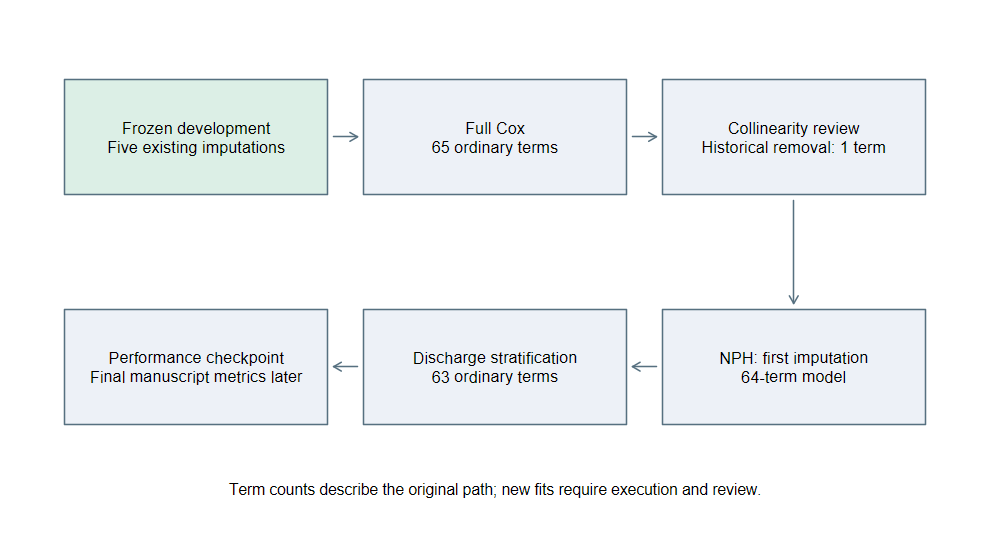

In [9]:
#| label: cox-discovery-flowchart
#| message: false
#| fig-cap: "Original Cox discovery sequence and current execution boundary."
.t0 <- proc.time()
# Draw the original decision path without claiming that pending decisions have been revalidated.
graphics::par(mar = c(0.5, 0.5, 1, 0.5))
graphics::plot.new()
graphics::plot.window(xlim = c(0, 3), ylim = c(0, 2.5))
labels <- c("Frozen development\nFive existing imputations", "Full Cox\n65 ordinary terms", "Collinearity review\nHistorical removal: 1 term", "NPH: first imputation\n64-term model", "Discharge stratification\n63 ordinary terms", "Performance checkpoint\nFinal manuscript metrics later")
x <- c(0.5, 1.5, 2.5, 2.5, 1.5, 0.5)
y <- c(2, 2, 2, 0.8, 0.8, 0.8)
for (i in seq_along(labels)) {
  graphics::rect(x[i] - 0.44, y[i] - 0.30, x[i] + 0.44, y[i] + 0.30, col = if (i == 1L) "#dcefe6" else "#edf1f7", border = "#567080")
  graphics::text(x[i], y[i], labels[i], cex = 0.86)
}
graphics::arrows(c(0.96, 1.96, 2.5, 2.04, 1.04), c(2, 2, 1.67, 0.8, 0.8), c(1.04, 2.04, 2.5, 1.96, 0.96), c(2, 2, 1.13, 0.8, 0.8), length = 0.08, col = "#567080")
graphics::text(1.5, 0.15, "Term counts describe the original path; new fits require execution and review.", cex = 0.82)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


## Physical comorbidity: two indicators, not three exclusive categories
The original **any_phys_dx** indicates at least one of four recorded physical-condition groups. **phys_dx_instudy** indicates an under-study entry in the chronological diagnosis series of the first qualifying treatment. An under-study entry alone does not make any_phys_dx positive; the series may contain both indicators without implying simultaneous diagnoses.
The original workflow removed phys_dx_instudy because of imputation uncertainty and retained any_phys_dx. Thus the reference group means **no selected physical-condition group recorded**, and can include under-study-only entries. It must not be labelled clinically healthy or proven disease-free. Recorded diagnoses are not independently confirmed clinical diagnoses.
The manuscript's wording "Any physical diagnosis under study" does not name the predictor actually fitted. We preserve the original predictor and clarify its meaning here; Word is untouched. The separate discharge evaluation eva_fisica is not a diagnostic-status category.


In [10]:
#| label: cox-physical-variable-orientation
#| message: false
.t0 <- proc.time()
# Show observed development records before imputation; do not refit or redefine these variables.
physical_raw <- readRDS(source_path("clean_preparation_cache"))$development[c("any_phys_dx", "phys_dx_instudy")]
physical_cross <- as.data.frame(table(Recorded_condition = physical_raw$any_phys_dx, Under_study_entry = physical_raw$phys_dx_instudy, useNA = "ifany"), stringsAsFactors = FALSE)
physical_cross <- physical_cross[physical_cross$Freq > 0L, , drop = FALSE]
names(physical_cross)[3L] <- "Participants"
stopifnot(sum(physical_cross$Participants) == sum(train))
show_table(physical_cross, "Observed development records before imputation: physical-condition indicators can overlap")
cat("Neither indicator is a three-level dummy variable. The under-study flag is not included among Cox predictors.\n")
rm(physical_raw)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Recorded_condition,Under_study_entry,Participants
FALSE,0,24760
TRUE,0,6242
FALSE,1,38925
TRUE,1,467
NA,NA,127


Neither indicator is a three-level dummy variable. The under-study flag is not included among Cox predictors.


Elapsed: 0.005 minutes


## Development encoding and fixed formulas
Reuse the original reference levels and dummy functions. Filter to the frozen development partition before encoding. The historical positive-time convention replaces nonpositive working survival times by 1e-6 months for Cox; it changes neither source files nor cohort membership. Immediate readmission remains eligible.
The formula path remains the historical one. Removing the overall minimum therapeutic-achievement indicator addresses collinearity. Moving only rule-violation/undetermined discharge to strata leaves other discharge coefficients in the model.


In [11]:
#| label: cox-encoding-functions
#| message: false
.t0 <- proc.time()
# Reuse the original reference categories, dummy construction and first-substance grouping.
cox_columns <- c(
"adm_age_rec3", "porc_pobr", "dit_m", "national_foreign", 
  "ethnicity", "dg_psiq_cie_10_instudy", "dg_psiq_cie_10_dg", 
  "dx_f3_mood", "dx_f6_personality", "dx_f_any_severe_mental", 
  "any_phys_dx", "polysubstance_strict",
  "sex_rec_woman", "cohabitation_family_of_origin", 
  "cohabitation_with_couple_children", "cohabitation_others", 
  "sub_dep_icd10_status_drug_dependence", 
  "any_violence_1_domestic_violence_sex_abuse", "tr_outcome_referral", 
  "tr_outcome_dropout", "tr_outcome_adm_discharge_rule_violation_undet", 
  "tr_outcome_adm_discharge_adm_reasons", 
  "adm_motive_sanitary_sector", "adm_motive_another_sud_facility_fonodrogas_senda_previene", 
  "adm_motive_justice_sector", "adm_motive_other", "first_sub_used_alcohol", 
  "first_sub_used_cocaine_paste", "first_sub_used_cocaine_powder", "first_sub_used_other",
  "primary_sub_mod_cocaine_paste", "primary_sub_mod_cocaine_powder", 
   "primary_sub_mod_alcohol", "primary_sub_mod_others", 
  "tipo_de_vivienda_rec2_other_unknown", "plan_type_corr_pg_pr", 
  "plan_type_corr_m_pr", "plan_type_corr_pg_pai", "plan_type_corr_m_pai", 
  "occupation_condition_corr24_unemployed", "occupation_condition_corr24_inactive", 
  "marital_status_rec_single", "marital_status_rec_separated_divorced_annulled_widowed", 
  "tenure_status_household_renting", 
  "tenure_status_household_others", 
  "tenure_status_household_stays_temporarily_with_a_relative", 
  "tenure_status_household_illegal_settlement",
  "urbanicity_cat_2_mixed", 
  "urbanicity_cat_1_rural",
  "evaluacindelprocesoteraputico_logro_intermedio", "evaluacindelprocesoteraputico_logro_minimo",
  "eva_consumo_logro_intermedio", "eva_consumo_logro_minimo",
  "eva_fam_logro_intermedio", "eva_fam_logro_minimo",
  "eva_relinterp_logro_intermedio", "eva_relinterp_logro_minimo",
  "eva_ocupacion_logro_intermedio", "eva_ocupacion_logro_minimo",
  "eva_sm_logro_intermedio", "eva_sm_logro_minimo",
  "eva_fisica_logro_intermedio", "eva_fisica_logro_minimo",
  "eva_transgnorma_logro_intermedio", "eva_transgnorma_logro_minimo",
  "prim_sub_freq_rec_2_2_6_days_wk", 
  "prim_sub_freq_rec_3_daily",
  "ed_attainment_corr_2_completed_high_school_or_less", 
  "ed_attainment_corr_3_completed_primary_school_or_less"
)
DUMMY_REFERENCE <- c(
sex_rec = "man",
  plan_type_corr = "pg-pab",
  marital_status_rec = "married/cohabiting",
  cohabitation = "alone",
  sub_dep_icd10_status = "hazardous consumption",
  tr_outcome = "completion",
  adm_motive = "spontaneous consultation",
  tipo_de_vivienda_rec2 = "formal housing",
  occupation_condition_corr24 = "employed",
  any_violence = "0.No domestic violence/sex abuse",
  first_sub_used = "marijuana",
  primary_sub_mod = "marijuana",
  tenure_status_household = "owner/transferred dwellings/pays dividends",
  urbanicity_cat = "3.Urban",
  evaluacindelprocesoteraputico = "logro alto",
  eva_consumo = "logro alto",
  eva_fam = "logro alto",
  eva_relinterp = "logro alto",
  eva_ocupacion = "logro alto",
  eva_sm = "logro alto",
  eva_fisica = "logro alto",
  eva_transgnorma = "logro alto",
  prim_sub_freq_rec = "1.\u22641 day/wk",
  ed_attainment_corr = "1-More than high school"
)
set_reference_levels <- function(df, refs = DUMMY_REFERENCE) {
  for (col in intersect(names(refs), names(df))) {
    values <- trimws(as.character(df[[col]]))
    ref <- refs[[col]]
    cats <- unique(values)
    df[[col]] <- if (ref %in% cats) {
      factor(values, levels = c(ref, cats[cats != ref]), ordered = FALSE)
    } else {
      factor(values, ordered = FALSE)
    }
  }
  df
}
make_dummies <- function(df) {
  cat_cols <- names(df)[vapply(df, function(x) is.character(x) || is.factor(x), logical(1))]
  if (!length(cat_cols)) return(df)
  cat_df <- as.data.frame(df[cat_cols], stringsAsFactors = FALSE)
  cat_df[] <- lapply(cat_df, function(x) {
    x <- factor(x)
    x <- addNA(x, ifany = TRUE)
    lev <- levels(x)
    lev[is.na(lev)] <- "__MISSING__"
    levels(x) <- paste0("_", lev)
    x
  })
  mm <- model.matrix(~ ., data = cat_df) |> as.data.frame(check.names = FALSE)
  mm[["(Intercept)"]] <- NULL
  cbind(df[setdiff(names(df), cat_cols)], mm)
}
collapse_first_sub_used_other <- function(df) {
  cols_to_group <- c(
    "first_sub_used_opioids", "first_sub_used_others",
    "first_sub_used_hallucinogens", "first_sub_used_inhalants",
    "first_sub_used_tranquilizers_hypnotics",
    "first_sub_used_amphetamine_type_stimulants"
  )
  cols_present <- intersect(cols_to_group, names(df))
  df$first_sub_used_other <- if (length(cols_present)) {
    as.integer(rowSums(df[cols_present], na.rm = TRUE) > 0)
  } else {
    0L
  }
  df
}
# Only model predictors enter dummy encoding; identities and outcomes remain metadata.
natural_predictors <- cox_columns[seq_len(12L)]
predictors <- setdiff(cox_columns, grep("^plan_type_corr_", cox_columns, value = TRUE))
endpoint_columns <- c("readmit_event", "readmit_time_from_disch_m", "death_event", "death_time_from_disch_m")
encode_development <- function(data, keep) {
  stopifnot(length(keep) == nrow(data), !anyNA(keep))
  input <- data[keep, unique(c(natural_predictors, names(DUMMY_REFERENCE))), drop = FALSE]
  stopifnot(!anyNA(input))
  encoded <- collapse_first_sub_used_other(janitor::clean_names(make_dummies(set_reference_levels(input))))
  missing <- setdiff(cox_columns, names(encoded))
  if (length(missing)) stop("Missing encoded Cox columns: ", paste(missing, collapse = ", "))
  encoded <- encoded[cox_columns]
  encoded[endpoint_columns] <- data[keep, endpoint_columns, drop = FALSE]
  # Preserve the original numeric metadata conversion without creating missing values.
  encoded$center_id <- as.numeric(as.character(data$center_id[keep]))
  stopifnot(identical(is.na(encoded$center_id), is.na(data$center_id[keep])))
  encoded$row_id <- which(keep)
  plan_columns <- grep("^plan_type_corr_", names(encoded), value = TRUE)
  stopifnot(all(rowSums(encoded[plan_columns]) <= 1))
  plan_from_dummies <- rep("pg-pab", nrow(encoded))
  for (plan in c("pg-pr", "m-pr", "pg-pai", "m-pai")) plan_from_dummies[encoded[[paste0("plan_type_corr_", gsub("-", "_", plan))]] == 1] <- plan
  stopifnot(identical(as.character(input$plan_type_corr), plan_from_dummies))
  encoded$plan_type_strata <- factor(plan_from_dummies)
  for (v in c("readmit_time_from_disch_m", "death_time_from_disch_m")) encoded[[v]][encoded[[v]] <= 0] <- 1e-6
  stopifnot(!anyNA(encoded[c(cox_columns, endpoint_columns, "plan_type_strata", "row_id")]), nrow(encoded) == sum(keep))
  encoded
}
# Bind strata in the formula environment: namespace-qualified strata inside the formula is not used.
formula_environment <- new.env(parent = asNamespace("survival"))
make_cox_formula <- function(outcome, terms = predictors, extra_stratum = FALSE) {
  response <- if (outcome == "readmission") "Surv(readmit_time_from_disch_m, readmit_event)" else "Surv(death_time_from_disch_m, death_event)"
  rhs <- c(terms, "strata(plan_type_strata)", if (extra_stratum) "strata(tr_outcome_adm_discharge_rule_violation_undet)")
  stats::as.formula(paste(response, "~", paste(rhs, collapse = " + ")), env = formula_environment)
}
removed_collinear <- "evaluacindelprocesoteraputico_logro_minimo"
discharge_stratum <- "tr_outcome_adm_discharge_rule_violation_undet"
cox_formulas <- lapply(c("readmission", "death"), function(outcome) list(full = make_cox_formula(outcome), reduced = make_cox_formula(outcome, setdiff(predictors, removed_collinear)), stratified = make_cox_formula(outcome, setdiff(predictors, c(removed_collinear, discharge_stratum)), TRUE)))
names(cox_formulas) <- c("readmission", "death")
stopifnot(length(predictors) == 65L, !"phys_dx_instudy" %in% predictors, "any_phys_dx" %in% predictors)
show_table(data.frame(Stage = c("Full", "Reduced after collinearity", "Discharge-stratified"), Ordinary_terms = c(65L, 64L, 63L), Strata = c("Treatment modality", "Treatment modality", "Treatment modality and rule-violation/undetermined discharge")), "Original formula sequence; pending verification on new imputations")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Stage,Ordinary_terms,Strata
Full,65,Treatment modality
Reduced after collinearity,64,Treatment modality
Discharge-stratified,63,Treatment modality and rule-violation/undetermined discharge


Elapsed: 0.000 minutes


## Predictor labels and reference categories
English figure and table labels are linked to the technical variables below. The dictionary preserves the distinction between diagnoses and discharge-achievement assessments. High achievement is the Cox reference; in the ML encoding, a higher achievement code means lower achievement. Treatment-plan indicators reconstruct strata rather than ordinary hazard-ratio coefficients. Labels are presentation metadata only.

In [12]:
#| label: presentation-variable-labels
#| message: false
.t0 <- proc.time()
# Apply English names only to display copies; technical names, coding and models stay intact.
variable_labels <- utils::read.csv(source_path("variable_labels"), stringsAsFactors = FALSE, check.names = FALSE, fileEncoding = "UTF-8")
stopifnot(!anyDuplicated(variable_labels$technical_name), all(cox_columns %in% variable_labels$technical_name), all(nzchar(variable_labels$display_label)))
term_labels <- stats::setNames(variable_labels$display_label, variable_labels$technical_name)
display_term <- function(x, width = NULL) {
  key <- sub("TRUE$", "", as.character(x))
  label <- unname(term_labels[key])
  label[is.na(label)] <- as.character(x)[is.na(label)]
  if (is.null(width)) return(label)
  vapply(label, function(value) paste(strwrap(value, width = width), collapse = "\n"), character(1L))
}
if (!exists("show_table_original", inherits = FALSE)) show_table_original <- show_table
show_table_original(variable_labels[c("technical_name", "display_label", "reference", "note")], "English display dictionary: technical names and reference levels retained for audit")
show_table <- function(data, caption) {
  for (column in intersect(c("Term", "Variable", "Variable1", "Variable2", "Predictor"), names(data))) data[[column]] <- display_term(data[[column]])
  show_table_original(data, caption)
}
# Render at a fixed size and discard temporary diagnostic images after display.
show_diagnostic_png <- function(draw, width, height) {
  image_path <- tempfile(fileext = ".png")
  on.exit(unlink(image_path), add = TRUE)
  grDevices::png(image_path, width = width, height = height, res = 110)
  tryCatch(draw(), finally = grDevices::dev.off())
  IRdisplay::display_png(file = image_path)
}
cat("Display dictionary covers all", length(cox_columns), "encoded columns. No predictor, category, reference level or model formula was changed.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

technical_name,display_label,reference,note
adm_age_rec3,"Age at admission, yr",,
porc_pobr,Communal poverty rate,,Codebook reports income-poverty linkage through 2021 and multidimensional poverty after 2021. Temporal-cohort consistency has not been re-audited in this display task.
dit_m,"Treatment episode length, mo",,
national_foreign,Foreign nationality,,
ethnicity,Recorded Indigenous ethnicity,,"Zero means no Indigenous ethnicity recorded in the source, not independently verified non-Indigenous identity."
dg_psiq_cie_10_instudy,Psychiatric diagnosis under study,,
dg_psiq_cie_10_dg,Recorded psychiatric diagnosis,,A diagnosis recorded in the linked data; the label does not imply independent clinical confirmation.
dx_f3_mood,Mood disorder (F30-F39),,
dx_f6_personality,Personality or adult-behaviour disorder (F60-F69),,
dx_f_any_severe_mental,"Severe mental disorder (F0, F2, F7-F9)",,"F0 organic, F2 psychotic, F7 intellectual disability, and F8-F9 neurodevelopmental groups. Broader display-label proposal awaits investigator choice; no recoding."


Display dictionary covers all 69 encoded columns. No predictor, category, reference level or model formula was changed.


Elapsed: 0.000 minutes


In [13]:
#| label: cox-format-development
#| message: false
.t0 <- proc.time()
# Save compact development matrices once; all five files must preserve identity, endpoints and observed values.
py_corrected_datasets <- cox_cache("cox_development_matrices", function() lapply(seq_along(cox_paths), function(i) {
  data <- nanoparquet::read_parquet(cox_paths[[i]])
  stopifnot(identical(as.integer(data$legacy_row_id), as.integer(split$row_id)), identical(as.logical(data$is_train), train), identical(as.integer(data$original_row_id), as.integer(completed$original_row_id)))
  stopifnot(isTRUE(all.equal(data[endpoint_columns], legacy[endpoint_columns], check.attributes = FALSE)))
  stopifnot(isTRUE(all.equal(as.numeric(as.character(data$center_id)), as.numeric(as.character(legacy$center_id)), check.attributes = FALSE)))
  encode_development(data, train)
}))
stopifnot(length(py_corrected_datasets) == 5L, all(vapply(py_corrected_datasets, nrow, integer(1L)) == sum(train)))
matrix_names <- names(py_corrected_datasets[[1L]])
stopifnot(all(vapply(py_corrected_datasets, function(d) identical(names(d), matrix_names), logical(1L))))
# A separate historical matrix anchors later fitted diagnostics, without fitting anything in prepare mode.
historical_cox <- encode_development(nanoparquet::read_parquet(source_path("schema_reference")), train)
stopifnot(identical(names(historical_cox), matrix_names))
working_times <- do.call(rbind, lapply(c("readmit_time_from_disch_m", "death_time_from_disch_m"), function(v) data.frame(Endpoint = v, Nonpositive_source_times = sum(completed[[v]][train] <= 0), Working_time = 1e-6)))
show_table(working_times, "Original Cox time convention retained on working copies")
show_table(data.frame(Imputation = seq_along(py_corrected_datasets), Development_rows = vapply(py_corrected_datasets, nrow, integer(1L)), Columns = vapply(py_corrected_datasets, ncol, integer(1L)), Missing_predictor_or_outcome_cells = vapply(py_corrected_datasets, function(d) sum(is.na(d[c(predictors, endpoint_columns)])), integer(1L)), Missing_center_metadata = vapply(py_corrected_datasets, function(d) sum(is.na(d$center_id)), integer(1L))), "Prepared development matrices; no model or preprocessing fitted")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Endpoint,Nonpositive_source_times,Working_time
readmit_time_from_disch_m,4067,0
death_time_from_disch_m,4027,0


Imputation,Development_rows,Columns,Missing_predictor_or_outcome_cells,Missing_center_metadata
1,70521,76,0,16
2,70521,76,0,16
3,70521,76,0,16
4,70521,76,0,16
5,70521,76,0,16


Elapsed: 0.034 minutes


## Collinearity: inspection before removal
The original association display used Spearman association for numeric pairs, Cramer's V for categorical pairs, and the correlation ratio for mixed pairs. Its threshold above 0.20 was descriptive, not a selection rule. The new display restricts the same calculations to predictors, omitting identifiers and outcomes.
VIF is calculated from the first-imputation full Cox fits. The historical removed term is shown against the same threshold of 10. Changed threshold decisions require review. AICc and pooled nested-model D1 reuse cached fits instead of repeatedly fitting the same models.


In [14]:
#| label: cox-fit-and-diagnostic-functions
#| message: false
.t0 <- proc.time()
# Cache every formula/outcome/imputation once and keep first-imputation design matrices for PH.
fit_cox_once <- function(data, formula, name, keep_design = FALSE) cox_cache(name, function() {
  fit <- survival::coxph(formula, data = data, ties = "efron", x = keep_design, y = TRUE, model = keep_design)
  cox_fits_new <<- cox_fits_new + 1L
  if (anyNA(stats::coef(fit)) || any(!is.finite(stats::coef(fit)))) stop("Non-estimable Cox coefficients: ", name)
  fit
})
cox_aicc <- function(fits) {
  per_imputation <- do.call(rbind, lapply(seq_along(fits), function(i) {
    fit <- fits[[i]]
    k <- length(stats::coef(fit))
    n <- fit$nevent
    stopifnot(n > k + 1L)
    data.frame(Imputation = i, Terms = k, Events = n, AIC = stats::AIC(fit), AICc = stats::AIC(fit) + 2 * k * (k + 1) / (n - k - 1))
  }))
  list(mean_aicc = mean(per_imputation$AICc), per_imputation = per_imputation)
}
cox_vif <- function(fit) {
  value <- rms::vif(fit)
  result <- data.frame(Term = sub("TRUE$", "", names(value)), VIF = as.numeric(value))
  result[order(-result$VIF), , drop = FALSE]
}
cox_ph_table <- function(test, outcome) {
  tab <- as.data.frame(test$table)
  data.frame(Outcome = outcome, Term = sub("TRUE$", "", rownames(tab)), Chi_square = tab$chisq, df = tab$df, p = tab$p, row.names = NULL)
}
# These historical values are read from eTable 10 and matched to the stored original PH outputs.
historical_ph_reference <- data.frame(Outcome = c(rep("readmission", 3L), rep("death", 3L)), Term = c("GLOBAL", discharge_stratum, "adm_motive_justice_sector", "GLOBAL", discharge_stratum, "any_phys_dx"), Previous = c(281.07, 60.65, 43.08, 178.78, 82.43, 15.15), df = c(64L, 1L, 1L, 64L, 1L, 1L))
compare_ph <- function(tests) {
  current <- do.call(rbind, lapply(names(tests), function(outcome) cox_ph_table(tests[[outcome]], outcome)))
  result <- merge(historical_ph_reference, current, by = c("Outcome", "Term", "df"), all.x = TRUE, sort = FALSE)
  stopifnot(nrow(result) == nrow(historical_ph_reference), !anyNA(result$Chi_square))
  result$Difference <- result$Chi_square - result$Previous
  result$classification <- ifelse(round(result$Chi_square, 2) == result$Previous, ifelse(abs(result$Difference) < 1e-10, "unchanged", "trivial"), "substantial")
  result
}
cat("Functions defined. No Cox models have been fitted by this cell.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Functions defined. No Cox models have been fitted by this cell.


Elapsed: 0.000 minutes


## Sequential predictive comparisons
The initial Full candidate, removal of the high-VIF term, and subsequent NPH stratification are evaluated separately. Review their performance at the opening of **07**, before deciding which specification advances. If later interactions are retained, subsequent functional-form tests keep those interactions.
C and IBS use horizon risk and the canonical scoring definitions from prediction225_converted_mod. Readmission C/IBS here score **net predictions**; readmission calibration uses **CIF against Aalen-Johansen**, following the corrected historical workflow. These prediction definitions are not interchangeable.
**Retained limitation of internal CV.** The five missRanger imputations were fitted once on the complete development sample, without outcome or follow-up variables, before survival-model cross-validation. Predictors from each internal validation fold therefore contributed to learning the imputer, although that fold is excluded from fitting its survival model. This CV does not independently validate the complete preprocessing-and-model-selection workflow. missRanger OOB diagnostics assess the imputation forests and do not remove this dependence. The direction and magnitude of its effect on the retained workflow have not been isolated by the available comparisons. The investigator explicitly retained this scope on 2026-10-05.
**Separate holdout boundary.** Holdout rows and outcomes were excluded from fitting the development imputers, ML tuning and SHAP screening. However, notebook 00's descriptive early-death audit inspected holdout outcomes, and inherited discovery decisions remain documented. Do not describe the entire historical and reconstructed workflow as wholly independent of the holdout.
**Accepted fold decision (2026-10-05).** Retain the executed historical C/IBS partitions: assignments differ between imputations and are shared by all candidate specifications within each imputation. Predictions are aligned by participant and averaged across imputations before scoring. Calibration retains its historical twenty repetitions of five folds across five imputations, with assignments shared across imputations within each repetition and calibration engine. The branch-specific ML folds in 01-03 are unchanged.
**Meaning of this decision.** Fixed assignments across imputations are also a valid design choice; retaining the historical alternative preserves the executed method. Neither choice removes the shared-imputation limitation. The earlier guide wording is corrected and the methodological pause is closed. Full predictive execution still requires its planned resource pilot; no comparative predictive result has been selected.

In [15]:
#| label: performance-contract
#| message: true
.t0 <- proc.time()
# Separate predictive-evaluation caches from unchanged diagnostic caches.
performance_settings <- config$cox_performance
stopifnot(performance_settings$mode %in% c("prepare", "full"), length(py_corrected_datasets) == 5L)
performance_horizons <- as.numeric(unlist(performance_settings$horizons_months))
performance_grid <- sort(unique(c(0, seq(0.25, max(performance_horizons), by = performance_settings$ibs_grid_step_months), performance_horizons)))
performance_code <- vapply(cox_notebook$cells, function(cell) paste(unlist(cell$source), collapse = ""), character(1L))
performance_code <- performance_code[grepl("#\\| label: performance-", performance_code)]
performance_signature <- substr(digest::digest(list(cox_signature, performance_code, performance_settings[c("fold_contract", "folds", "n_imputations", "calibration_repeats", "horizons_months", "ibs_grid_step_months", "seed")]), algo = "sha256"), 1L, 12L)
performance_new_fits <- 0L
performance_results <- list()
performance_calibration <- list()
record_performance_fits <- function(n) performance_new_fits <<- performance_new_fits + as.integer(n)
performance_cache <- function(name, compute) {
  found <- list.files(object_dir, pattern = paste0("^perf06_", name, "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE)
  stopifnot(length(found) <= 1L)
  if (length(found)) {
    cached <- readRDS(found[[1L]])
    stopifnot(identical(cached$signature, performance_signature))
    return(cached$value)
  }
  started <- Sys.time()
  value <- compute()
  destination <- file.path(object_dir, paste0("perf06_", name, "_", cox_date, "_", performance_signature, ".rds"))
  saveRDS(list(signature = performance_signature, value = value), destination, compress = TRUE, version = 3L)
  written <<- c(written, destination)
  cat(format(Sys.time(), "%H:%M:%S"), "| saved", name, "| seconds", round(as.numeric(difftime(Sys.time(), started, units = "secs")), 2), "\n")
  flush.console()
  value
}
performance_packages <- c("pec", "riskRegression", "prodlim", "future.apply")
for (package in performance_packages) stopifnot(utils::packageVersion(package) == base::package_version(lock$Packages[[package]]$Version))
future::plan(future::sequential)
show_table(data.frame(Stage = c("full", "reduced", "stratified"), Historical_key = c("base", "updated", "updated2"), Ordinary_terms = c(65L, 64L, 63L), Change = c("Initial full specification with treatment-modality strata", "Remove minimum therapeutic achievement only", "Additionally move rule-violation/undetermined discharge to strata")), "Sequential candidates; selection remains pending for the opening of 07")
show_table(data.frame(Component = c("C", "IBS", "Readmission calibration", "Mortality calibration"), Definition = c("Uno C on 1-S(h), pooled OOF predictions across five imputations", "Classical Graf integral from zero; 0.25-month grid; pooled-development censoring G", "Predicted CIF versus Aalen-Johansen; 20 x 5 x 5", "Predicted all-cause risk versus Kaplan-Meier; 20 x 5 x 5")), "Evaluation contract; no paired delta bootstrap at this stage")
cat("Fold contract:", performance_settings$fold_contract, "| Mode:", performance_settings$mode, "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Stage,Historical_key,Ordinary_terms,Change
full,base,65,Initial full specification with treatment-modality strata
reduced,updated,64,Remove minimum therapeutic achievement only
stratified,updated2,63,Additionally move rule-violation/undetermined discharge to strata


Component,Definition
C,"Uno C on 1-S(h), pooled OOF predictions across five imputations"
IBS,Classical Graf integral from zero; 0.25-month grid; pooled-development censoring G
Readmission calibration,Predicted CIF versus Aalen-Johansen; 20 x 5 x 5
Mortality calibration,Predicted all-cause risk versus Kaplan-Meier; 20 x 5 x 5


Fold contract: historical_imputation_specific | Mode: full 


Elapsed: 0.001 minutes


In [16]:
#| label: performance-classical-metric-functions
#| message: true
.t0 <- proc.time()
# Preserve the original scoring definition: .ibc_to01
.ibc_to01 <- function(x) if (is.logical(x)) as.integer(x) else as.integer(as.numeric(x) > 0)
# Preserve the original scoring definition: ibs_classical_grid
ibs_classical_grid <- function(max_horizon = 60, step = 0.25, horizons = NULL) {
    stopifnot(step > 0, max_horizon > 0)
    sort(unique(c(0, seq(step, max_horizon, by = step), max_horizon, horizons)))
}
# Preserve the original scoring definition: .ibc_G_train
.ibc_G_train <- function(time_train, event_train, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time_train, 1 - .ibc_to01(event_train)) ~ 1)
    tau <- {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe))
            max(safe)
        else Inf
    }
    list(tau = tau, at = function(tt) {
        req <- pmax(as.numeric(tt), 0)
        u <- sort(unique(req))
        g <- as.numeric(summary(sf, times = u, extend = TRUE)$surv)
        if (length(g) != length(u)) stop("Censoring lookup returned an unexpected length.", call. = FALSE)
        i <- match(req, u)
        if (anyNA(i)) stop("Censoring lookup could not restore request order.", call. = FALSE)
        pmax(g[i], g_min)
    })
}
# Preserve the original scoring definition: .ibc_contrib
.ibc_contrib <- function(G, time_te, event_te, surv_te, grid_pos, eps = 1e-08) {
    Tt <- as.numeric(time_te)
    Dt <- .ibc_to01(event_te)
    stopifnot(ncol(surv_te) == length(grid_pos), nrow(surv_te) == length(Tt))
    g_event <- G$at(pmax(Tt - eps, 0))
    out <- matrix(0, length(Tt), length(grid_pos))
    for (j in seq_along(grid_pos)) {
        t0 <- grid_pos[j]
        S0 <- surv_te[, j]
        Y0 <- as.numeric(Tt > t0)
        w <- ifelse(Tt <= t0 & Dt == 1L, 1/g_event, ifelse(Tt > t0, 1/G$at(t0), 0))
        out[, j] <- w * (Y0 - S0)^2
    }
    out
}
# Preserve the original scoring definition: .ibc_trap_weights
.ibc_trap_weights <- function(grid_pos, horizons) {
    W <- matrix(0, length(grid_pos), length(horizons))
    for (k in seq_along(horizons)) {
        keep <- which(grid_pos <= horizons[k] + 1e-12)
        if (!length(keep))
            next
        d <- diff(c(0, grid_pos[keep]))
        m <- length(d)
        w <- d/2
        if (m > 1L)
            w[seq_len(m - 1L)] <- w[seq_len(m - 1L)] + d[-1L]/2
        W[keep, k] <- w
    }
    W
}
# Preserve the original scoring definition: ibs_classical_point
ibs_classical_point <- function(pred, horizons = c(3, 6, 12, 36, 60), g_min = 0.05) {
    grid <- pred$grid
    pos <- which(grid > 0)
    grid_pos <- grid[pos]
    G <- .ibc_G_train(pred$y_train$time, pred$y_train$event, g_min = g_min)
    usable <- horizons <= min(G$tau, max(pred$y_train$time, na.rm = TRUE))
    C <- .ibc_contrib(G, pred$y_test$time, pred$y_test$event, pred$S[, pos, drop = FALSE], grid_pos)
    W <- .ibc_trap_weights(grid_pos, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons,
        tau_ipcw = G$tau, brier_curve = data.frame(time_months = grid_pos, brier = colMeans(C)))
}
# Preserve the original scoring definition: ibs_classical_readmit
ibs_classical_readmit <- function(pred, horizons = c(3, 6, 12, 36, 60), method = c("aalen-johansen", "ipcw"), g_min = 0.05,
    eps = 1e-08) {
    method <- match.arg(method)
    stopifnot(exists(".ibsb_contrib_readmit_aj", mode = "function"))
    cc <- if (method == "aalen-johansen") {
        .ibsb_contrib_readmit_aj(pred$S, pred$rt_val, pred$re_val, pred$dt_val, pred$de_val, pred$rt_tr, pred$re_tr, pred$dt_tr,
            pred$de_tr, pred$grid, g_min, eps)
    }
    else {
        .ibsb_contrib_readmit_ipcw(pred$S, pred$rt_val, pred$re_val, pred$rt_tr, pred$re_tr, pred$grid, g_min, eps)
    }
    pos <- which(cc$grid > 0)
    gp <- cc$grid[pos]
    C <- cc$C[, pos, drop = FALSE]
    usable <- horizons <= max(gp) + 1e-08
    W <- .ibc_trap_weights(gp, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons,
        method = method, grid_max_kept = max(gp), brier_curve = data.frame(time_months = gp, brier = colMeans(C)))
}
# Preserve the original scoring definition: %||%
`%||%` <- function(a, b) if (is.null(a) || length(a) == 0L) b else a
# Preserve the original scoring definition: .ibsb_to01
.ibsb_to01 <- function(x) as.integer(as.numeric(x) > 0)
# Preserve the original scoring definition: .ibsb_G_fun
.ibsb_G_fun <- function(time, cens_event, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time, cens_event) ~ 1)
    list(fun = function(tt) {
        requested_times <- pmax(as.numeric(tt), 0)
        unique_times <- sort(unique(requested_times))
        g_unique <- as.numeric(summary(sf, times = unique_times, extend = TRUE)$surv)
        if (length(g_unique) != length(unique_times)) stop("Censoring-survival lookup returned an unexpected length.", call. = FALSE)
        lookup_index <- match(requested_times, unique_times)
        if (anyNA(lookup_index)) stop("Censoring-survival lookup could not restore request order.", call. = FALSE)
        pmax(g_unique[lookup_index], g_min)
    }, tau = {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe)) max(safe) else NA_real_
    })
}
# Preserve the original scoring definition: .ibsb_cr
.ibsb_cr <- function(readmit_time, readmit_event, death_time, death_event) {
    rt <- as.numeric(readmit_time)
    re <- .ibsb_to01(readmit_event)
    dt <- as.numeric(death_time)
    de <- .ibsb_to01(death_event)
    ftime <- pmin(rt, dt)
    r_first <- re == 1L & is.finite(ftime) & abs(rt - ftime) <= 1e-08
    d_first <- de == 1L & is.finite(ftime) & abs(dt - ftime) <= 1e-08
    fstatus <- rep(0L, length(ftime))
    fstatus[r_first & !d_first] <- 1L
    fstatus[d_first & !r_first] <- 2L
    fstatus[r_first & d_first] <- 2L
    list(ftime = ftime, fstatus = fstatus)
}
# Preserve the original scoring definition: .ibsb_contrib_readmit_aj
.ibsb_contrib_readmit_aj <- function(surv_val, rt_val, re_val, dt_val, de_val, rt_tr, re_tr, dt_tr, de_tr, grid, g_min, eps) {
    cr_v <- .ibsb_cr(rt_val, re_val, dt_val, de_val)
    cr_t <- .ibsb_cr(rt_tr, re_tr, dt_tr, de_tr)
    G <- .ibsb_G_fun(cr_t$ftime, as.integer(cr_t$fstatus == 0L), g_min = g_min)
    tau <- G$tau %||% NA_real_
    tmax_train <- max(cr_t$ftime, na.rm = TRUE)
    keep <- grid <= (if (is.finite(tau))
        tau
    else max(grid)) & grid <= tmax_train
    gk <- grid[keep]
    ft <- cr_v$ftime
    fs <- cr_v$fstatus
    C <- matrix(0, nrow = length(ft), ncol = length(gk))
    for (j in seq_along(gk)) {
        t0 <- gk[j]
        is_readmit <- fs == 1L & ft <= t0
        is_death <- fs == 2L & ft <= t0
        is_efree <- ft > t0
        Y0 <- as.numeric(!is_readmit)
        w <- ifelse(is_readmit | is_death, 1/G$fun(pmax(ft - eps, 0)), ifelse(is_efree, 1/G$fun(t0), 0))
        C[, j] <- w * (Y0 - surv_val[, which(keep)[j]])^2
    }
    list(C = C, grid = gk)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [17]:
#| label: performance-corrected-aj-calibration-engine
.calibration_definition_start <- proc.time()
# Define the historical calibration engine with resumable tasks and completeness guards.
calibrate_cscox_aj_grouped_corr <- function(formula_readmit, formula_death = NULL, data, times = c(12, 36, 60), readmit_time_var = "readmit_time_from_disch_m",
    readmit_event_var = "readmit_event", death_time_var = "death_time_from_disch_m", death_event_var = "death_event", n_imputations = NULL,
    validation = c("apparent", "cv"), folds = 5L, n_repeats = 10L, g = 10L, min_bin_n = 20L, compute_ici = FALSE, ici_times = NULL,
    ici_df = 4L, seed = 2125L, tie_action = c("death_first", "readmit_first", "drop", "error"), verbose = TRUE, make_plots = TRUE,
    parallel_cv = TRUE, parallel_calibration = parallel_cv, future_scheduling = 2, debug_fit = FALSE, ici_span = 0.75, cache_prefix = NULL) {
    if (!is.null(cache_prefix) && isTRUE(parallel_cv))
        stop("Calibration task caching requires parallel_cv = FALSE.", call. = FALSE)
    if (!requireNamespace("survival", quietly = TRUE))
        stop("Package 'survival' is required.")
    if (!requireNamespace("riskRegression", quietly = TRUE))
        stop("Package 'riskRegression' is required.")
    if (!requireNamespace("prodlim", quietly = TRUE))
        stop("Package 'prodlim' is required.")
    if (isTRUE(compute_ici) && !requireNamespace("splines", quietly = TRUE))
        stop("Package 'splines' is required when compute_ici = TRUE.")
    if (!inherits(formula_readmit, "formula"))
        stop("'formula_readmit' must be a formula.")
    if (!is.null(formula_death) && !inherits(formula_death, "formula"))
        stop("'formula_death' must be NULL or a formula.")
    validation <- match.arg(validation)
    tie_action <- match.arg(tie_action)
    if (!is.numeric(times) || length(times) == 0L || any(!is.finite(times)) || any(times < 0)) {
        stop("'times' must be a non-empty numeric vector of non-negative finite values.")
    }
    times <- sort(unique(as.numeric(times)))
    folds <- as.integer(folds)
    n_repeats <- as.integer(n_repeats)
    g <- as.integer(g)
    min_bin_n <- as.integer(min_bin_n)
    ici_df <- as.integer(ici_df)
    if (is.null(ici_times)) {
        ici_times <- times
    }
    else {
        if (!is.numeric(ici_times) || any(!is.finite(ici_times)))
            stop("'ici_times' must be numeric.")
        ici_times <- sort(unique(as.numeric(ici_times)))
    }
    if (any(!ici_times %in% times))
        stop("'ici_times' must be a subset of 'times'.")
    if (validation == "cv" && folds < 2L)
        stop("'folds' must be >= 2 when validation = 'cv'.")
    if (n_repeats < 1L)
        stop("'n_repeats' must be >= 1.")
    if (g < 1L)
        stop("'g' must be >= 1.")
    if (min_bin_n < 1L)
        stop("'min_bin_n' must be >= 1.")
    if (ici_df < 1L)
        stop("'ici_df' must be >= 1.")
    if (validation == "apparent" && n_repeats != 1L) {
        if (isTRUE(verbose))
            message("validation = 'apparent': using a single run and ignoring n_repeats > 1.")
        n_repeats <- 1L
    }
    .msg <- function(...) {
        if (isTRUE(verbose))
            message(...)
    }
    .as_df_list <- function(x, n_imputations = NULL) {
        if (is.data.frame(x)) {
            out <- list(as.data.frame(x))
        }
        else if (is.list(x) && length(x) > 0L && all(vapply(x, is.data.frame, logical(1)))) {
            out <- lapply(x, as.data.frame)
        }
        else {
            stop("'data' must be a data.frame or a list of data.frames.")
        }
        if (!is.null(n_imputations)) {
            out <- out[seq_len(min(as.integer(n_imputations), length(out)))]
        }
        out
    }
    .run_stats <- function(x, probs = c(0.025, 0.975), type = 8) {
        x <- x[is.finite(x)]
        n <- length(x)
        if (n == 0L) {
            return(c(mean = NA_real_, sd = NA_real_, min = NA_real_, p025 = NA_real_, p975 = NA_real_, max = NA_real_, n = 0L))
        }
        q <- stats::quantile(x, probs = c(0, probs, 1), na.rm = TRUE, names = FALSE, type = type)
        c(mean = mean(x), sd = if (n > 1L) stats::sd(x) else 0, min = q[1], p025 = q[2], p975 = q[3], max = q[4], n = n)
    }
    .coerce_event01 <- function(x, varname) {
        if (is.logical(x))
            return(as.integer(x))
        if (is.factor(x))
            x <- as.character(x)
        if (is.character(x)) {
            out <- rep(NA_integer_, length(x))
            ok <- !is.na(x)
            x0 <- trimws(tolower(x[ok]))
            out_ok <- ifelse(x0 %in% c("1", "true", "yes", "y"), 1L, ifelse(x0 %in% c("0", "false", "no", "n"), 0L, NA_integer_))
            bad_nonmissing <- is.na(out_ok)
            if (any(bad_nonmissing)) {
                bad_vals <- unique(x[ok][bad_nonmissing])
                stop("Variable '", varname, "' contains non-missing values that cannot be coerced to 0/1: ", paste(utils::head(bad_vals,
                  10), collapse = ", "))
            }
            out[ok] <- out_ok
            return(out)
        }
        if (is.numeric(x) || is.integer(x)) {
            ux <- unique(stats::na.omit(x))
            if (!all(ux %in% c(0, 1))) {
                stop("Variable '", varname, "' must contain only 0/1 values (besides NA).")
            }
            return(as.integer(x))
        }
        stop("Variable '", varname, "' must be logical, numeric/integer 0/1, factor, or character.")
    }
    .rhs_formula <- function(formula_obj) {
        f_rhs <- stats::formula(stats::delete.response(stats::terms(formula_obj)))
        environment(f_rhs) <- environment(formula_obj)
        f_rhs
    }
    .build_hist_formula <- function(rhs_formula) {
        f_hist <- stats::update.formula(rhs_formula, prodlim::Hist(.ftime, .fstatus) ~ .)
        env <- new.env(parent = globalenv())
        env$strata <- survival::strata
        if (exists("strat", envir = asNamespace("riskRegression"), inherits = FALSE)) {
            env$strat <- get("strat", envir = asNamespace("riskRegression"), inherits = FALSE)
        }
        environment(f_hist) <- env
        f_hist
    }
    .make_first_event_data <- function(d) {
        req <- c(readmit_time_var, readmit_event_var, death_time_var, death_event_var)
        miss <- setdiff(req, names(d))
        if (length(miss) > 0L)
            stop("Missing required columns: ", paste(miss, collapse = ", "))
        tr <- d[[readmit_time_var]]
        td <- d[[death_time_var]]
        er <- .coerce_event01(d[[readmit_event_var]], readmit_event_var)
        ed <- .coerce_event01(d[[death_event_var]], death_event_var)
        if (!is.numeric(tr) || !is.numeric(td))
            stop("Time variables must be numeric.")
        if (any(tr < 0, na.rm = TRUE) || any(td < 0, na.rm = TRUE))
            stop("Negative follow-up times are not allowed.")
        d$.tr_raw <- tr
        d$.td_raw <- td
        d$.er_raw <- er
        d$.ed_raw <- ed
        .ftime <- pmin(tr, td)
        r_at_first <- (er == 1L) & !is.na(er) & !is.na(.ftime) & (abs(tr - .ftime) <= 1e-08)
        d_at_first <- (ed == 1L) & !is.na(ed) & !is.na(.ftime) & (abs(td - .ftime) <= 1e-08)
        .fstatus <- rep(0L, length(.ftime))
        .fstatus[r_at_first & !d_at_first] <- 1L
        .fstatus[d_at_first & !r_at_first] <- 2L
        both_at_first <- r_at_first & d_at_first
        n_ties <- sum(both_at_first, na.rm = TRUE)
        if (n_ties > 0L) {
            if (tie_action == "error") {
                stop("Found ", n_ties, " simultaneous readmission/death first events.")
            }
            else if (tie_action == "death_first") {
                .msg("Found ", n_ties, " ties; assigning them to death-first.")
                .fstatus[both_at_first] <- 2L
            }
            else if (tie_action == "readmit_first") {
                .msg("Found ", n_ties, " ties; assigning them to readmission-first.")
                .fstatus[both_at_first] <- 1L
            }
            else if (tie_action == "drop") {
                .msg("Found ", n_ties, " ties; they will be dropped by unified filtering.")
                .fstatus[both_at_first] <- NA_integer_
            }
        }
        d$.ftime <- .ftime
        d$.fstatus <- .fstatus
        d
    }
    .analysis_mask <- function(d0, rhs_readmit, rhs_death) {
        mf_readmit <- stats::model.frame(rhs_readmit, data = d0, na.action = stats::na.pass)
        mf_death <- stats::model.frame(rhs_death, data = d0, na.action = stats::na.pass)
        stats::complete.cases(d0[, c(".ftime", ".fstatus"), drop = FALSE]) & stats::complete.cases(mf_readmit) & stats::complete.cases(mf_death)
    }
    .validate_analysis_data <- function(dcc, validation, folds) {
        n <- nrow(dcc)
        n1 <- sum(dcc$.fstatus == 1L, na.rm = TRUE)
        n2 <- sum(dcc$.fstatus == 2L, na.rm = TRUE)
        if (n == 0L)
            stop("No complete cases remain after unified filtering.")
        if (n1 < 1L)
            stop("No readmission-first events remain in the analysis cohort.")
        if (n2 < 1L)
            stop("No death-first events remain in the analysis cohort.")
        if (validation == "cv") {
            if (folds > n)
                stop("'folds' cannot exceed the analysis sample size.")
            if (n1 < 2L)
                stop("Cross-validation is not feasible: fewer than 2 readmission-first events remain.")
            if (n2 < 2L)
                stop("Cross-validation is not feasible: fewer than 2 death-first events remain.")
        }
        invisible(TRUE)
    }
    .make_stratified_folds <- function(status, folds, seed_local) {
        set.seed(seed_local)
        n <- length(status)
        if (folds > n)
            stop("'folds' cannot exceed sample size.")
        fold_id <- integer(n)
        classes <- sort(unique(status))
        offset <- 0L
        for (cl in classes) {
            idx <- which(status == cl)
            idx <- sample(idx, length(idx), replace = FALSE)
            assign <- ((seq_along(idx) - 1L + offset)%%folds) + 1L
            fold_id[idx] <- assign
            offset <- (offset + length(idx))%%folds
        }
        tab <- tabulate(fold_id, nbins = folds)
        while (any(tab == 0L)) {
            empty_fold <- which(tab == 0L)[1L]
            donor_fold <- which.max(tab)
            donor_idx <- which(fold_id == donor_fold)
            move_idx <- sample(donor_idx, 1L)
            fold_id[move_idx] <- empty_fold
            tab <- tabulate(fold_id, nbins = folds)
        }
        for (k in seq_len(folds)) {
            tr_status <- status[fold_id != k]
            if (sum(tr_status == 1L, na.rm = TRUE) == 0L)
                stop("Invalid fold split: training fold ", k, " has zero readmission-first events.")
            if (sum(tr_status == 2L, na.rm = TRUE) == 0L)
                stop("Invalid fold split: training fold ", k, " has zero death-first events.")
            if (sum(fold_id == k) == 0L)
                stop("Invalid fold split: test fold ", k, " is empty.")
        }
        fold_id
    }
    .fit_csc_and_predict <- function(train_data, test_data, f1, f2, times) {
        fit <- tryCatch(riskRegression::CSC(list(f1, f2), data = train_data), error = function(e) stop("riskRegression::CSC failed.\nOriginal error: ",
            e$message))
        pred <- riskRegression::predictRisk(object = fit, newdata = test_data, times = times, cause = 1)
        if (is.null(dim(pred))) {
            pred <- matrix(pred, nrow = nrow(test_data), byrow = TRUE)
        }
        else {
            pred <- as.matrix(pred)
        }
        if (nrow(pred) != nrow(test_data) || ncol(pred) != length(times)) {
            stop("Predicted matrix has wrong dimensions: expected ", nrow(test_data), "x", length(times), ", got ", nrow(pred),
                "x", ncol(pred), ".")
        }
        if (any(!is.finite(pred)))
            stop("Non-finite predicted risks were produced. Calibration would be invalid.")
        pred <- pmin(pmax(pred, 0), 1)
        colnames(pred) <- paste0("t_", times)
        pred
    }
    .run_one_fold_csc <- function(task, analysis_data, times, M, f1, f2) {
        compute <- function() {
            tr_idx <- task$tr_idx
            te_idx <- task$te_idx
            pred_sum <- matrix(0, nrow = length(te_idx), ncol = length(times))
            for (m in seq_len(M)) {
                pred_m <- tryCatch(.fit_csc_and_predict(train_data = analysis_data[[m]][tr_idx, , drop = FALSE], test_data = analysis_data[[m]][te_idx,
                  , drop = FALSE], f1 = f1, f2 = f2, times = times), error = function(e) {
                  stop("Parallel task failed at repetition=", task$r, ", fold=", task$k, ", imputation=", m, ": ", conditionMessage(e),
                    call. = FALSE)
                })
                pred_sum <- pred_sum + pred_m
            }
            value <- list(r = task$r, te_idx = te_idx, pred_fold_avg = pred_sum/M)
            record_performance_fits(2L * M)
            value
        }
        task_name <- paste0(if (is.null(cache_prefix))
            "cal_readmission"
        else cache_prefix, "_r", sprintf("%02d", task$r), "_f", sprintf("%02d", task$k))
        cat(sprintf("[%s] %s start (fit or cache)\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value <- if (is.null(cache_prefix))
            compute()
        else performance_cache(task_name, compute)
        cat(sprintf("[%s] %s complete\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value
    }
    .run_one_calibration_repetition <- function(rep_obj, rep_total, times, reference_data, reference_observed, common_cutpoints,
        common_bin_maps, min_bin_n, compute_ici, ici_times, ici_df, n_input, n_analysis, n_dropped, n_readmit, n_death, M) {
        r <- rep_obj$repetition
        pred_r <- rep_obj$pred
        curves_rep <- list()
        metrics_rep <- list()
        for (j in seq_along(times)) {
            t_horizon <- times[j]
            pred_vec <- pred_r[, j]
            calib_obj <- .grouped_calibration(d = reference_data, pred_vec = pred_vec, t_horizon = t_horizon, cutpoints = common_cutpoints[[j]],
                bin_map = common_bin_maps[[j]], min_bin_n = min_bin_n)
            calib_df <- calib_obj$curve
            if (is.null(calib_df) || nrow(calib_df) == 0L) {
                warning("No calibration bins survived for repetition ", r, " at time ", t_horizon, ".", call. = FALSE)
                next
            }
            obs_row <- reference_observed[reference_observed$time_months == t_horizon, , drop = FALSE]
            ece <- stats::weighted.mean(abs(calib_df$mean_predicted - calib_df$observed), w = calib_df$n_patients, na.rm = TRUE)
            if (isTRUE(compute_ici) && t_horizon %in% ici_times && length(calib_obj$obs_lookup) > 0L) {
                ici_obj <- .compute_ici_loess(pred_vec = pred_vec, bins = calib_obj$bins, obs_lookup = calib_obj$obs_lookup,
                  loess_span = ici_span)
            }
            else {
                ici_obj <- list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_)
            }
            mean_pred <- mean(pred_vec, na.rm = TRUE)
            eo_ratio <- if (is.na(obs_row$observed[1]) || obs_row$observed[1] <= 0)
                NA_real_
            else mean_pred/obs_row$observed[1]
            calib_df$repetition <- r
            calib_df$time_months <- t_horizon
            curves_rep[[length(curves_rep) + 1L]] <- calib_df
            metrics_rep[[length(metrics_rep) + 1L]] <- data.frame(repetition = r, time_months = t_horizon, ici = ici_obj$ici,
                e50 = ici_obj$e50, e90 = ici_obj$e90, emax = ici_obj$emax, ece = ece, eo_ratio = eo_ratio, mean_predicted = mean_pred,
                observed = obs_row$observed[1], observed_lower = obs_row$observed_lower[1], observed_upper = obs_row$observed_upper[1],
                n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit, n_death = n_death,
                n_used_calibration = calib_obj$n_used, n_excluded_calibration = calib_obj$n_excluded, n_bins = nrow(calib_df),
                n_imputations = M, stringsAsFactors = FALSE)
        }
        list(repetition = r, rep_total = rep_total, curves = curves_rep, metrics = metrics_rep)
    }
    .make_cutpoints <- function(x, g = 10L) {
        x <- x[is.finite(x)]
        if (length(x) == 0L)
            return(numeric(0))
        if (length(unique(x)) == 1L)
            return(numeric(0))
        probs <- seq(0, 1, length.out = g + 1L)
        q <- stats::quantile(x, probs = probs, na.rm = TRUE, names = FALSE, type = 8)
        unique(q[-c(1, length(q))])
    }
    .assign_bins <- function(x, cutpoints) {
        bins <- rep(NA_integer_, length(x))
        ok <- is.finite(x)
        if (!any(ok))
            return(bins)
        if (length(cutpoints) == 0L) {
            bins[ok] <- 1L
        }
        else {
            bins[ok] <- findInterval(x[ok], vec = cutpoints, all.inside = TRUE) + 1L
        }
        bins
    }
    .build_global_bin_map <- function(x, cutpoints, min_bin_n) {
        bins0 <- .assign_bins(x, cutpoints)
        levs <- sort(unique(stats::na.omit(bins0)))
        if (length(levs) == 0L)
            return(integer(0))
        groups <- lapply(levs, function(z) z)
        counts_full <- tabulate(bins0[!is.na(bins0)], nbins = max(levs))
        counts <- as.numeric(counts_full[levs])
        repeat {
            n_groups <- length(groups)
            if (n_groups == 1L)
                break
            small <- which(counts < min_bin_n)
            if (length(small) == 0L)
                break
            g_idx <- small[1L]
            if (g_idx == 1L) {
                target <- 2L
            }
            else if (g_idx == n_groups) {
                target <- n_groups - 1L
            }
            else {
                target <- if (counts[g_idx - 1L] <= counts[g_idx + 1L])
                  g_idx - 1L
                else g_idx + 1L
            }
            groups[[target]] <- sort(c(groups[[target]], groups[[g_idx]]))
            counts[target] <- counts[target] + counts[g_idx]
            keep <- setdiff(seq_len(n_groups), g_idx)
            groups <- groups[keep]
            counts <- counts[keep]
        }
        n_orig_bins <- if (length(cutpoints) == 0L)
            1L
        else length(cutpoints) + 1L
        bin_map <- rep(NA_integer_, n_orig_bins)
        if (length(groups) == 1L && counts[1L] < min_bin_n)
            return(bin_map)
        for (i in seq_along(groups)) {
            bin_map[unlist(groups[[i]], use.names = FALSE)] <- i
        }
        bin_map
    }
    .apply_bin_map <- function(bins, bin_map) {
        out <- rep(NA_integer_, length(bins))
        ok <- !is.na(bins) & bins >= 1L & bins <= length(bin_map)
        if (any(ok))
            out[ok] <- bin_map[bins[ok]]
        out
    }
    .state_position <- function(pstate_obj, states, target) {
        cn <- if (is.null(dim(pstate_obj)))
            names(pstate_obj)
        else colnames(pstate_obj)
        if (!is.null(cn)) {
            idx <- match(target, cn)
            if (!is.na(idx))
                return(idx)
        }
        idx <- match(target, states)
        if (is.na(idx))
            stop("Could not locate state '", target, "' in survfit output.")
        ncols <- if (is.null(dim(pstate_obj)))
            length(pstate_obj)
        else ncol(pstate_obj)
        if (ncols == length(states) + 1L)
            return(idx + 1L)
        if (ncols == length(states))
            return(idx)
        stop("Unexpected pstate structure: ", ncols, " columns for ", length(states), " states.")
    }
    .aj_cif_readmit <- function(d, t_horizon) {
        d$.status_factor <- factor(d$.fstatus, levels = 0:2, labels = c("censor", "readmit", "death"))
        fit <- survival::survfit(survival::Surv(.ftime, .status_factor) ~ 1, data = d, conf.int = 0.95)
        s <- summary(fit, times = t_horizon, extend = TRUE)
        if (length(s$pstate) == 0L)
            return(list(risk = 0, lower = 0, upper = 0))
        state_pos <- .state_position(s$pstate, fit$states, "readmit")
        if (is.null(dim(s$pstate))) {
            risk <- as.numeric(s$pstate[state_pos])
            lower <- if (!is.null(s$lower) && length(s$lower) >= state_pos)
                as.numeric(s$lower[state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && length(s$upper) >= state_pos)
                as.numeric(s$upper[state_pos])
            else NA_real_
        }
        else {
            risk <- as.numeric(s$pstate[1, state_pos])
            lower <- if (!is.null(s$lower) && ncol(s$lower) >= state_pos)
                as.numeric(s$lower[1, state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && ncol(s$upper) >= state_pos)
                as.numeric(s$upper[1, state_pos])
            else NA_real_
        }
        if (is.na(lower))
            lower <- risk
        if (is.na(upper))
            upper <- risk
        list(risk = pmin(pmax(risk, 0), 1), lower = pmin(pmax(lower, 0), 1), upper = pmin(pmax(upper, 0), 1))
    }
    .grouped_calibration <- function(d, pred_vec, t_horizon, cutpoints, bin_map, min_bin_n) {
        bins0 <- .assign_bins(pred_vec, cutpoints)
        bins <- .apply_bin_map(bins0, bin_map)
        levs <- sort(unique(stats::na.omit(bins)))
        if (length(levs) == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec)), bins = bins, obs_lookup = numeric(0)))
        }
        out <- vector("list", length(levs))
        keep_idx <- 0L
        for (b in levs) {
            idx <- which(bins == b)
            if (length(idx) < min_bin_n)
                next
            obs <- .aj_cif_readmit(d[idx, , drop = FALSE], t_horizon)
            keep_idx <- keep_idx + 1L
            out[[keep_idx]] <- data.frame(bin = b, mean_predicted = mean(pred_vec[idx], na.rm = TRUE), observed = obs$risk,
                n_patients = length(idx), stringsAsFactors = FALSE)
        }
        if (keep_idx == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec)), bins = bins, obs_lookup = numeric(0)))
        }
        curve <- do.call(rbind, out[seq_len(keep_idx)])
        obs_lookup <- stats::setNames(curve$observed, as.character(curve$bin))
        list(curve = curve, n_used = sum(curve$n_patients), n_excluded = sum(is.finite(pred_vec)) - sum(curve$n_patients),
            bins = bins, obs_lookup = obs_lookup)
    }
    .compute_ici_loess <- function(pred_vec, bins, obs_lookup, loess_span = 0.75) {
        obs_individual <- obs_lookup[as.character(bins)]
        valid <- !is.na(obs_individual) & is.finite(pred_vec)
        if (sum(valid) < 10L) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_))
        }
        pv <- pred_vec[valid]
        ov <- as.numeric(obs_individual[valid])
        lo <- tryCatch(stats::loess(ov ~ pv, span = loess_span, control = stats::loess.control(surface = "interpolate")),
            error = function(e) NULL)
        if (is.null(lo)) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_))
        }
        abs_err <- abs(stats::fitted(lo) - pv)
        list(ici = mean(abs_err, na.rm = TRUE), e50 = as.numeric(stats::quantile(abs_err, probs = 0.5, na.rm = TRUE, names = FALSE,
            type = 8)), e90 = as.numeric(stats::quantile(abs_err, probs = 0.9, na.rm = TRUE, names = FALSE, type = 8)), emax = max(abs_err,
            na.rm = TRUE))
    }
    .pool_summary <- function(by_repetition) {
        if (nrow(by_repetition) == 0L)
            return(by_repetition)
        time_levels <- sort(unique(by_repetition$time_months))
        out <- lapply(time_levels, function(tt) {
            z <- by_repetition[by_repetition$time_months == tt, , drop = FALSE]
            ici_st <- .run_stats(z$ici)
            e50_st <- .run_stats(z$e50)
            e90_st <- .run_stats(z$e90)
            emax_st <- .run_stats(z$emax)
            ece_st <- .run_stats(z$ece)
            eo_st <- .run_stats(z$eo_ratio)
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = tt, ici_mean = unname(ici_st["mean"]), ici_sd = unname(ici_st["sd"]), ici_min = unname(ici_st["min"]),
                ici_p025 = unname(ici_st["p025"]), ici_p975 = unname(ici_st["p975"]), ici_max = unname(ici_st["max"]), e50_mean = unname(e50_st["mean"]),
                e50_sd = unname(e50_st["sd"]), e50_min = unname(e50_st["min"]), e50_p025 = unname(e50_st["p025"]), e50_p975 = unname(e50_st["p975"]),
                e50_max = unname(e50_st["max"]), e90_mean = unname(e90_st["mean"]), e90_sd = unname(e90_st["sd"]), e90_min = unname(e90_st["min"]),
                e90_p025 = unname(e90_st["p025"]), e90_p975 = unname(e90_st["p975"]), e90_max = unname(e90_st["max"]), emax_mean = unname(emax_st["mean"]),
                emax_sd = unname(emax_st["sd"]), emax_min = unname(emax_st["min"]), emax_p025 = unname(emax_st["p025"]),
                emax_p975 = unname(emax_st["p975"]), emax_max = unname(emax_st["max"]), ece_mean = unname(ece_st["mean"]),
                ece_sd = unname(ece_st["sd"]), ece_min = unname(ece_st["min"]), ece_p025 = unname(ece_st["p025"]), ece_p975 = unname(ece_st["p975"]),
                ece_max = unname(ece_st["max"]), eo_mean = unname(eo_st["mean"]), eo_sd = unname(eo_st["sd"]), eo_min = unname(eo_st["min"]),
                eo_p025 = unname(eo_st["p025"]), eo_p975 = unname(eo_st["p975"]), eo_max = unname(eo_st["max"]), mean_pred = unname(mp_st["mean"]),
                mean_pred_sd = unname(mp_st["sd"]), mean_pred_min = unname(mp_st["min"]), mean_pred_p025 = unname(mp_st["p025"]),
                mean_pred_p975 = unname(mp_st["p975"]), mean_pred_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]),
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]),
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_runs = nrow(z), n_imp = M,
                stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months), , drop = FALSE]
    }
    .pool_curves <- function(curves_df) {
        if (nrow(curves_df) == 0L)
            return(curves_df)
        key <- paste(curves_df$time_months, curves_df$bin, sep = "___")
        spl <- split(curves_df, key)
        out <- lapply(spl, function(z) {
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = unique(z$time_months), bin = unique(z$bin), mean_predicted = unname(mp_st["mean"]),
                mean_predicted_sd = unname(mp_st["sd"]), mean_predicted_min = unname(mp_st["min"]), mean_predicted_p025 = unname(mp_st["p025"]),
                mean_predicted_p975 = unname(mp_st["p975"]), mean_predicted_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]),
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]),
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_total = sum(z$n_patients,
                  na.rm = TRUE), n_runs = nrow(z), n_imp = M, stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months, out$bin), , drop = FALSE]
    }
    data_list <- .as_df_list(data, n_imputations = n_imputations)
    M <- length(data_list)
    rhs_readmit <- .rhs_formula(formula_readmit)
    rhs_death <- if (is.null(formula_death))
        .rhs_formula(formula_readmit)
    else .rhs_formula(formula_death)
    f_readmit <- .build_hist_formula(rhs_readmit)
    f_death <- .build_hist_formula(rhs_death)
    effective_repeats <- if (validation == "cv")
        n_repeats
    else 1L
    .msg("Using ", M, " imputed dataset(s).")
    .msg("Validation: ", validation)
    if (validation == "cv")
        .msg("Repetitions: ", effective_repeats, " | same fold split across imputations within each repetition.")
    if (isTRUE(compute_ici)) {
        .msg("ICI: enabled at horizons ", paste(ici_times, collapse = ", "), ".")
    }
    else {
        .msg("ICI: disabled.")
    }
    d0_list <- lapply(data_list, .make_first_event_data)
    if (M > 1L) {
        ref0 <- d0_list[[1L]]
        for (m in 2:M) {
            if (nrow(d0_list[[m]]) != nrow(ref0))
                stop("All imputations must have the same number of rows and row order.")
            same_ftime <- isTRUE(all.equal(ref0$.ftime, d0_list[[m]]$.ftime, tolerance = 1e-08, check.attributes = FALSE))
            same_fstatus <- identical(ref0$.fstatus, d0_list[[m]]$.fstatus)
            if (!same_ftime || !same_fstatus) {
                stop("Outcome/time information differs across imputations. This workflow assumes only predictors were imputed.")
            }
        }
    }
    mask_list <- lapply(d0_list, function(d0) .analysis_mask(d0, rhs_readmit, rhs_death))
    keep_all <- Reduce(`&`, mask_list)
    n_input <- nrow(d0_list[[1L]])
    n_analysis <- sum(keep_all)
    n_dropped <- n_input - n_analysis
    if (n_dropped > 0L) {
        .msg("Dropping ", n_dropped, " rows due to missing outcomes/times/model covariates in at least one imputation.")
    }
    analysis_data <- lapply(d0_list, function(d0) {
        out <- d0[keep_all, , drop = FALSE]
        rownames(out) <- NULL
        out
    })
    .needed_cols <- unique(c(".ftime", ".fstatus", all.vars(rhs_readmit), all.vars(rhs_death)))
    analysis_data <- lapply(analysis_data, function(d) {
        d[, intersect(.needed_cols, names(d)), drop = FALSE]
    })
    reference_data <- analysis_data[[1L]]
    .validate_analysis_data(reference_data, validation, folds)
    n_readmit <- sum(reference_data$.fstatus == 1L, na.rm = TRUE)
    n_death <- sum(reference_data$.fstatus == 2L, na.rm = TRUE)
    reference_observed <- do.call(rbind, lapply(times, function(tt) {
        obs <- .aj_cif_readmit(reference_data, tt)
        data.frame(time_months = tt, observed = obs$risk, observed_lower = obs$lower, observed_upper = obs$upper, stringsAsFactors = FALSE)
    }))
    reference_data <- reference_data[, c(".ftime", ".fstatus"), drop = FALSE]
    pred_rep_list <- list()
    if (validation == "apparent") {
        .msg("Fitting apparent predictions averaged across imputations...", appendLF = FALSE)
        pred_sum <- matrix(0, nrow = n_analysis, ncol = length(times))
        for (m in seq_len(M)) {
            pred_sum <- pred_sum + .fit_csc_and_predict(train_data = analysis_data[[m]], test_data = analysis_data[[m]],
                f1 = f_readmit, f2 = f_death, times = times)
        }
        pred_avg <- pred_sum/M
        colnames(pred_avg) <- paste0("t_", times)
        pred_rep_list[[1L]] <- list(repetition = 1L, pred = pred_avg)
        .msg(" done")
    }
    else {
        task_list <- unlist(lapply(seq_len(effective_repeats), function(r) {
            fold_id <- .make_stratified_folds(reference_data$.fstatus, folds = folds, seed_local = seed + r)
            lapply(seq_len(folds), function(k) {
                list(r = r, k = k, tr_idx = which(fold_id != k), te_idx = which(fold_id == k))
            })
        }), recursive = FALSE)
        if (parallel_cv) {
            if (!requireNamespace("future.apply", quietly = TRUE)) {
                stop("Package 'future.apply' is required when parallel_cv = TRUE.")
            }
            .msg("Running CV predictions in parallel across ", length(task_list), " repetition x fold tasks...", appendLF = FALSE)
            task_results <- future.apply::future_lapply(X = task_list, FUN = .run_one_fold_csc, analysis_data = analysis_data,
                times = times, M = M, f1 = f_readmit, f2 = f_death, future.seed = TRUE, future.globals = FALSE, future.packages = c("survival",
                  "riskRegression", "prodlim"), future.scheduling = future_scheduling)
            .msg(" done")
        }
        else {
            .msg("Running CV predictions sequentially across ", length(task_list), " repetition x fold tasks...", appendLF = FALSE)
            task_results <- lapply(X = task_list, FUN = .run_one_fold_csc, analysis_data = analysis_data, times = times,
                M = M, f1 = f_readmit, f2 = f_death)
            .msg(" done")
        }
        for (r in seq_len(effective_repeats)) {
            pred_avg <- matrix(NA_real_, nrow = n_analysis, ncol = length(times))
            r_hits <- task_results[vapply(task_results, function(x) x$r, integer(1L)) == r]
            for (res in r_hits) {
                pred_avg[res$te_idx, ] <- res$pred_fold_avg
            }
            if (any(!is.finite(pred_avg)))
                stop("Non-finite predictions remained after averaging across imputations in repetition ", r, ".")
            colnames(pred_avg) <- paste0("t_", times)
            pred_rep_list[[length(pred_rep_list) + 1L]] <- list(repetition = r, pred = pred_avg)
        }
    }
    common_cutpoints <- vector("list", length(times))
    common_bin_maps <- vector("list", length(times))
    names(common_cutpoints) <- paste0("t_", times)
    names(common_bin_maps) <- paste0("t_", times)
    for (j in seq_along(times)) {
        pooled_preds_j <- unlist(lapply(pred_rep_list, function(obj) obj$pred[, j]), use.names = FALSE)
        cuts_j <- .make_cutpoints(pooled_preds_j, g = g)
        common_cutpoints[[j]] <- cuts_j
        common_bin_maps[[j]] <- .build_global_bin_map(x = pooled_preds_j, cutpoints = cuts_j, min_bin_n = min_bin_n)
    }
    if (isTRUE(parallel_calibration) && length(pred_rep_list) > 1L) {
        if (!requireNamespace("future.apply", quietly = TRUE)) {
            stop("Package 'future.apply' is required when parallel_calibration = TRUE.")
        }
        .msg("Calibrating ", length(pred_rep_list), " repetitions in parallel...", appendLF = FALSE)
        rep_results <- future.apply::future_lapply(X = pred_rep_list, FUN = .run_one_calibration_repetition, rep_total = length(pred_rep_list),
            times = times, reference_data = reference_data, reference_observed = reference_observed, common_cutpoints = common_cutpoints,
            common_bin_maps = common_bin_maps, min_bin_n = min_bin_n, compute_ici = compute_ici, ici_times = ici_times, ici_df = ici_df,
            n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit, n_death = n_death,
            M = M, future.seed = TRUE, future.globals = FALSE, future.packages = c("survival"), future.scheduling = future_scheduling)
        .msg(" done")
    }
    else {
        rep_results <- vector("list", length(pred_rep_list))
        for (rep_idx in seq_along(pred_rep_list)) {
            rep_obj <- pred_rep_list[[rep_idx]]
            r <- rep_obj$repetition
            .msg("Calibrating repetition ", r, "/", length(pred_rep_list), "...", appendLF = FALSE)
            rep_results[[rep_idx]] <- .run_one_calibration_repetition(rep_obj = rep_obj, rep_total = length(pred_rep_list),
                times = times, reference_data = reference_data, reference_observed = reference_observed, common_cutpoints = common_cutpoints,
                common_bin_maps = common_bin_maps, min_bin_n = min_bin_n, compute_ici = compute_ici, ici_times = ici_times,
                ici_df = ici_df, n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit,
                n_death = n_death, M = M)
            .msg(" done")
        }
    }
    curves_all <- do.call(c, lapply(rep_results, function(x) x$curves))
    metrics_all <- do.call(c, lapply(rep_results, function(x) x$metrics))
    if (is.null(curves_all))
        curves_all <- list()
    if (is.null(metrics_all))
        metrics_all <- list()
    by_repetition <- if (length(metrics_all) > 0L)
        do.call(rbind, metrics_all)
    else data.frame()
    curves_df <- if (length(curves_all) > 0L)
        do.call(rbind, curves_all)
    else data.frame()
    if (isTRUE(compute_ici) && nrow(by_repetition) > 0L) {
        ici_rows <- by_repetition$time_months %in% ici_times
        if (any(ici_rows) && all(is.na(by_repetition$ici[ici_rows]))) {
            warning("ICI/E50/E90/Emax could not be computed for the requested ICI horizons.", call. = FALSE)
        }
    }
    pooled_summary <- if (nrow(by_repetition) > 0L)
        .pool_summary(by_repetition)
    else data.frame()
    pooled_curves <- if (nrow(curves_df) > 0L)
        .pool_curves(curves_df)
    else data.frame()
    plot_list <- list()
    combined_plot <- NULL
    if (isTRUE(make_plots) && nrow(pooled_curves) > 0L && requireNamespace("ggplot2", quietly = TRUE)) {
        for (tt in times) {
            pdat <- pooled_curves[pooled_curves$time_months == tt, , drop = FALSE]
            rdat <- curves_df[curves_df$time_months == tt, , drop = FALSE]
            if (nrow(pdat) == 0L)
                next
            lim_max <- max(c(rdat$mean_predicted, rdat$observed, pdat$mean_predicted_p975, pdat$observed_p975), na.rm = TRUE)
            lim_max <- max(0.05, lim_max * 1.05)
            srow <- pooled_summary[pooled_summary$time_months == tt, , drop = FALSE]
            subtxt <- if (nrow(srow) == 1L) {
                paste0("Validation: ", validation, if (validation == "cv")
                  paste0(" | repetitions = ", effective_repeats)
                else "", if (M > 1L)
                  paste0(" | imputations averaged = ", M)
                else "", if (isTRUE(compute_ici) && tt %in% ici_times) {
                  paste0(" | ICI mean = ", formatC(srow$ici_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$ici_sd,
                    digits = 4, format = "f"))
                }
                else {
                  " | ICI not computed"
                }, " | E/O mean = ", formatC(srow$eo_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$eo_sd, digits = 4,
                  format = "f"))
            }
            else {
                paste0("Validation: ", validation)
            }
            p <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
                ggplot2::geom_line(data = rdat, ggplot2::aes(x = mean_predicted, y = observed, group = repetition), color = "gray70",
                  alpha = 0.55, linewidth = 0.4) + ggplot2::geom_ribbon(data = pdat, ggplot2::aes(x = mean_predicted, ymin = observed_p025,
                ymax = observed_p975, group = 1), fill = "gray70", alpha = 0.25) + ggplot2::geom_line(data = pdat, ggplot2::aes(x = mean_predicted,
                y = observed, group = 1), color = "steelblue", linewidth = 0.9) + ggplot2::geom_point(data = pdat, ggplot2::aes(x = mean_predicted,
                y = observed), size = 2.5, shape = 21, fill = "white", color = "steelblue") + ggplot2::coord_equal(xlim = c(0,
                lim_max), ylim = c(0, lim_max)) + ggplot2::labs(title = paste0(tt, " months"), subtitle = subtxt, x = "Predicted CIF of readmission",
                y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
            plot_list[[paste0("month_", tt)]] <- p
        }
        combined_plot <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
            ggplot2::geom_line(data = curves_df, ggplot2::aes(x = mean_predicted, y = observed, group = interaction(time_months,
                repetition)), color = "gray70", alpha = 0.5, linewidth = 0.35) + ggplot2::geom_ribbon(data = pooled_curves,
            ggplot2::aes(x = mean_predicted, ymin = observed_p025, ymax = observed_p975, group = time_months), fill = "gray70",
            alpha = 0.25) + ggplot2::geom_line(data = pooled_curves, ggplot2::aes(x = mean_predicted, y = observed, group = time_months),
            color = "steelblue", linewidth = 0.85) + ggplot2::geom_point(data = pooled_curves, ggplot2::aes(x = mean_predicted,
            y = observed), size = 1.8, color = "steelblue") + ggplot2::facet_wrap(~time_months, scales = "free") + ggplot2::labs(title = "Grouped calibration of cause-specific Cox predictions",
            subtitle = paste0("Gray lines = repetitions | Gray ribbon = pointwise 2.5th-97.5th percentile across repetitions | Blue = mean",
                if (validation == "cv")
                  paste0(" | repeated ", folds, "-fold CV x ", effective_repeats)
                else ""), x = "Predicted CIF of readmission", y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
    }
    structure(list(by_repetition = by_repetition, by_run = by_repetition, pooled_summary = pooled_summary, calibration_curves = pooled_curves,
        raw_curves = curves_df, reference_observed = reference_observed, plots = plot_list, combined_plot = combined_plot,
        cutpoints = common_cutpoints, bin_maps = common_bin_maps, settings = list(times = times, readmit_time_var = readmit_time_var,
            readmit_event_var = readmit_event_var, death_time_var = death_time_var, death_event_var = death_event_var, n_imputations = M,
            validation = validation, folds = if (validation == "cv") folds else NA_integer_, n_repeats = effective_repeats,
            n_runs_total = effective_repeats, g = g, min_bin_n = min_bin_n, compute_ici = isTRUE(compute_ici), ici_times = ici_times,
            ici_df = ici_df, tie_action = tie_action, parallel_cv = parallel_cv, parallel_calibration = parallel_calibration,
            future_scheduling = future_scheduling, debug_fit = debug_fit, workflow = "parallel by repetition x fold for prediction; optional parallel calibration by repetition; same folds across imputations; average held-out predictions across imputations; variability across repetitions")),
        class = "cscox_aj_grouped_calibration_corr")
}
print.cscox_aj_grouped_calibration_corr <- function(x, ...) {
    cat("Grouped calibration: cause-specific Cox vs Aalen-Johansen\n")
    cat("========================================================\n")
    cat("Validation :", x$settings$validation, "\n")
    if (!is.na(x$settings$folds))
        cat("Folds      :", x$settings$folds, "\n")
    if (!is.null(x$settings$n_repeats))
        cat("Repetitions:", x$settings$n_repeats, "\n")
    cat("Imputations:", x$settings$n_imputations, "\n")
    if (!is.null(x$settings$n_runs_total))
        cat("Runs total :", x$settings$n_runs_total, "\n")
    cat("Groups     :", x$settings$g, "\n")
    cat("Min bin n  :", x$settings$min_bin_n, "\n")
    cat("ICI        :", if (isTRUE(x$settings$compute_ici))
        "enabled"
    else "disabled", "\n")
    if (isTRUE(x$settings$compute_ici)) {
        cat("ICI times  :", paste(x$settings$ici_times, collapse = ", "), "\n")
        cat("ICI df     :", x$settings$ici_df, "\n")
    }
    cat("\n")
    if (is.null(x$pooled_summary) || nrow(x$pooled_summary) == 0L) {
        cat("No pooled summary available.\n")
        return(invisible(x))
    }
    cat("Variability across repetitions:\n")
    print(x$pooled_summary[, c("time_months", "ici_mean", "ici_sd", "ici_p025", "ici_p975", "e50_mean", "e50_sd", "e50_p025",
        "e50_p975", "e90_mean", "e90_sd", "e90_p025", "e90_p975", "ece_mean", "ece_sd", "ece_p025", "ece_p975", "eo_mean",
        "eo_sd", "eo_p025", "eo_p975", "n_runs", "n_imp")], row.names = FALSE)
    cat("\nNotes:\n")
    cat("  - Each repetition uses the same fold split across all imputations.\n")
    cat("  - Models are fit separately within each imputation; held-out predictions are averaged across imputations.\n")
    cat("  - Thin gray lines are repetition-specific calibration curves.\n")
    cat("  - Gray ribbon is the pointwise 2.5th-97.5th percentile band across repetitions.\n")
    cat("  - Blue points/line are the mean calibration curve across repetitions.\n")
    cat("  - ICI, E50, and E90 are only computed when requested.\n")
    cat("  - These summaries describe split-to-split variability, not formal bootstrap optimism correction.\n")
    cat("  - ECE is grouped expected calibration error.\n")
    cat("  - E/O is mean predicted / observed probability.\n")
    invisible(x)
}
plot.cscox_aj_grouped_calibration_corr <- function(x, horizon = NULL, ...) {
    if (is.null(horizon)) {
        if (is.null(x$combined_plot))
            stop("No combined plot stored in object.")
        return(x$combined_plot)
    }
    nm <- paste0("month_", horizon)
    if (!nm %in% names(x$plots))
        stop("Requested horizon not found.")
    x$plots[[nm]]
}
cat(sprintf("Definition time: %.3f minutes\n", (proc.time()[[3L]] - .calibration_definition_start[[3L]]) / 60))

Definition time: 0.000 minutes


In [18]:
#| label: performance-corrected-death-calibration-engine
.calibration_definition_start <- proc.time()
# Define the historical calibration engine with resumable tasks and completeness guards.
calibrate_death_km_grouped <- function(formula, data, times = c(6, 12, 36, 60), time_col = "death_time_from_disch_m", event_col = "death_event",
    validation = "cv", folds = 5L, n_repeats = 20L, g = 10L, min_bin_n = 20L, loess_span = 0.75, parallel_cv = TRUE, verbose = TRUE,
    seed = NULL, cache_prefix = NULL) {
    if (!is.null(cache_prefix) && isTRUE(parallel_cv))
        stop("Calibration task caching requires parallel_cv = FALSE.", call. = FALSE)
    stopifnot(requireNamespace("survival", quietly = TRUE))
    stopifnot(requireNamespace("riskRegression", quietly = TRUE))
    stopifnot(requireNamespace("prodlim", quietly = TRUE))
    stopifnot(requireNamespace("future.apply", quietly = TRUE))
    if (!identical(validation, "cv"))
        stop("Only validation = 'cv' is implemented.", call. = FALSE)
    if (!is.list(data) || length(data) == 0L)
        stop("'data' must be a non-empty list of imputed data frames.", call. = FALSE)
    folds <- as.integer(folds)
    n_repeats <- as.integer(n_repeats)
    g <- as.integer(g)
    n_imp <- length(data)
    needed_cols <- unique(c(all.vars(formula), time_col, event_col))
    formula_str <- paste(deparse(formula, width.cutoff = 500L), collapse = " ")
    rm(formula)
    data_trimmed <- lapply(data, function(d) {
        df <- as.data.frame(d)
        df[, intersect(needed_cols, names(df)), drop = FALSE]
    })
    rm(data)
    n_obs <- nrow(data_trimmed[[1L]])
    time_obs <- data_trimmed[[1L]][[time_col]]
    event_obs <- as.integer(data_trimmed[[1L]][[event_col]])
    .make_folds <- function(n, k, rep_seed) {
        if (!is.null(rep_seed))
            set.seed(rep_seed)
        ids <- sample(rep(seq_len(k), length.out = n))
        lapply(seq_len(k), function(f) which(ids == f))
    }
    fold_assignments <- lapply(seq_len(n_repeats), function(r) {
        .make_folds(n_obs, folds, if (!is.null(seed))
            seed + r
        else NULL)
    })
    .metrics_at_time <- function(pred_vec, t_horizon) {
        cuts <- unique(stats::quantile(pred_vec, probs = seq(0, 1, length.out = g + 1L), na.rm = TRUE, names = FALSE, type = 8))
        cuts <- cuts[-c(1L, length(cuts))]
        bins <- if (length(cuts) > 0L)
            findInterval(pred_vec, cuts, all.inside = TRUE) + 1L
        else rep(1L, length(pred_vec))
        sf_all <- survival::survfit(survival::Surv(time_obs, event_obs) ~ 1)
        obs_at_t <- summary(sf_all, times = t_horizon, extend = TRUE)$surv
        obs_overall <- if (length(obs_at_t) > 0L)
            1 - obs_at_t[[1L]]
        else NA_real_
        unique_bins <- sort(unique(bins))
        obs_by_bin <- vapply(unique_bins, function(b) {
            idx <- which(bins == b)
            if (length(idx) < min_bin_n)
                return(NA_real_)
            sf_b <- survival::survfit(survival::Surv(time_obs[idx], event_obs[idx]) ~ 1)
            obs_b <- summary(sf_b, times = t_horizon, extend = TRUE)$surv
            if (length(obs_b) > 0L)
                1 - obs_b[[1L]]
            else NA_real_
        }, numeric(1L))
        bin_pred <- vapply(unique_bins, function(b) mean(pred_vec[bins == b], na.rm = TRUE), numeric(1L))
        bin_n <- vapply(unique_bins, function(b) sum(bins == b), integer(1L))
        keep <- !is.na(obs_by_bin) & bin_n >= min_bin_n
        ece <- if (any(keep))
            stats::weighted.mean(abs(bin_pred[keep] - obs_by_bin[keep]), w = bin_n[keep], na.rm = TRUE)
        else NA_real_
        obs_individual <- obs_by_bin[match(bins, unique_bins)]
        ici <- tryCatch({
            valid <- !is.na(obs_individual) & is.finite(pred_vec)
            if (sum(valid) < 10L) {
                NA_real_
            }
            else {
                lo <- stats::loess(obs_individual[valid] ~ pred_vec[valid], span = loess_span, control = stats::loess.control(surface = "interpolate"))
                mean(abs(stats::fitted(lo) - pred_vec[valid]), na.rm = TRUE)
            }
        }, error = function(e) NA_real_)
        eo_ratio <- if (!is.na(obs_overall) && obs_overall > 0)
            mean(pred_vec, na.rm = TRUE)/obs_overall
        else NA_real_
        list(ici = ici, ece = ece, eo_ratio = eo_ratio, mean_pred = mean(pred_vec, na.rm = TRUE), observed = obs_overall,
            n_bins = sum(keep), curve_data = data.frame(bin = unique_bins[keep], mean_predicted = bin_pred[keep], observed = obs_by_bin[keep],
                n_patients = bin_n[keep], stringsAsFactors = FALSE))
    }
    tasks <- vector("list", n_repeats * folds)
    k <- 0L
    for (r in seq_len(n_repeats)) {
        for (fi in seq_len(folds)) {
            k <- k + 1L
            tasks[[k]] <- list(r = r, fi = fi)
        }
    }
    if (verbose) {
        cat(sprintf("\ncalibrate_death_km_grouped: %d repeats x %d folds x %d imputations = %d fits (%d tasks)\n", n_repeats,
            folds, n_imp, n_repeats * folds * n_imp, length(tasks)))
        flush.console()
    }
    .run_task <- function(task) {
        compute <- function() {
            value <- tryCatch({
                r <- task$r
                fi <- task$fi
                test_idx <- fold_assignments[[r]][[fi]]
                train_idx <- setdiff(seq_len(n_obs), test_idx)
                formula_local <- stats::as.formula(formula_str, env = asNamespace("survival"))
                risk_sum <- matrix(0, nrow = length(test_idx), ncol = length(times))
                n_valid <- 0L
                for (mi in seq_along(data_trimmed)) {
                  df_imp <- data_trimmed[[mi]]
                  fit <- tryCatch(survival::coxph(formula_local, data = df_imp[train_idx, , drop = FALSE], x = TRUE, y = TRUE,
                    model = TRUE), error = function(e) {
                    warning(sprintf("[r=%d fi=%d mi=%d] coxph failed: %s", r, fi, mi, conditionMessage(e)))
                    NULL
                  })
                  if (is.null(fit))
                    next
                  risk_hat <- tryCatch(riskRegression::predictRisk(fit, newdata = df_imp[test_idx, , drop = FALSE], times = times),
                    error = function(e) {
                      warning(sprintf("[r=%d fi=%d mi=%d] predictRisk: %s", r, fi, mi, conditionMessage(e)))
                      NULL
                    })
                  if (is.null(risk_hat))
                    next
                  risk_sum <- risk_sum + risk_hat
                  n_valid <- n_valid + 1L
                }
                if (n_valid != n_imp)
                  stop(sprintf("Incomplete mortality calibration task: %d of %d imputations succeeded.", n_valid, n_imp),
                    call. = FALSE)
                if (n_valid == 0L)
                  return(NULL)
                list(r = r, fi = fi, test_idx = test_idx, risk_mat = risk_sum/n_valid)
            }, error = function(e) {
                warning(sprintf("[TASK r=%d fi=%d] FATAL: %s", task$r, task$fi, conditionMessage(e)))
                NULL
            })
            if (is.null(value))
                stop("Incomplete mortality calibration task; no result was cached.", call. = FALSE)
            record_performance_fits(n_imp)
            value
        }
        task_name <- paste0(if (is.null(cache_prefix))
            "cal_death"
        else cache_prefix, "_r", sprintf("%02d", task$r), "_f", sprintf("%02d", task$fi))
        cat(sprintf("[%s] %s start (fit or cache)\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value <- if (is.null(cache_prefix))
            compute()
        else performance_cache(task_name, compute)
        cat(sprintf("[%s] %s complete\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value
    }
    if (verbose) {
        cat("  Pre-flight: running task 1 sequentially...\n")
        flush.console()
        pf <- tryCatch(.run_task(tasks[[1L]]), error = function(e) e)
        if (inherits(pf, "error")) {
            stop(sprintf("Pre-flight task 1 FAILED: %s", conditionMessage(pf)), call. = FALSE)
        }
        else if (is.null(pf)) {
            warning("Pre-flight task 1 returned NULL (n_valid=0). Check formula variables and data.")
        }
        else {
            cat(sprintf("  Pre-flight OK: risk_mat dim=%dx%d\n", nrow(pf$risk_mat), ncol(pf$risk_mat)))
            flush.console()
        }
    }
    .prev_maxsize <- getOption("future.globals.maxSize")
    options(future.globals.maxSize = +Inf)
    on.exit(options(future.globals.maxSize = .prev_maxsize), add = TRUE)
    if (parallel_cv) {
        task_results <- future.apply::future_lapply(tasks, .run_task, future.seed = if (!is.null(seed))
            seed
        else TRUE, future.globals = FALSE, future.packages = c("survival", "splines", "riskRegression", "prodlim"), future.chunk.size = ceiling(length(tasks)/20L))
    }
    else {
        task_results <- lapply(tasks, .run_task)
    }
    n_failed <- sum(vapply(task_results, is.null, logical(1L)))
    if (n_failed != 0L)
        stop("Incomplete mortality calibration tasks; pooled results were not computed.", call. = FALSE)
    if (verbose && n_failed > 0L)
        message(sprintf("  WARNING: %d/%d tasks returned NULL (coxph failed)", n_failed, length(tasks)))
    all_reps <- lapply(seq_len(n_repeats), function(r) {
        rep_tasks <- Filter(function(res) !is.null(res) && res$r == r, task_results)
        if (length(rep_tasks) == 0L)
            return(NULL)
        risk_final <- matrix(NA_real_, nrow = n_obs, ncol = length(times))
        for (res in rep_tasks) risk_final[res$test_idx, ] <- res$risk_mat
        if (anyNA(risk_final))
            return(NULL)
        if (verbose) {
            cat(sprintf("  Pooling repetition %d/%d\r", r, n_repeats))
            flush.console()
        }
        horizon_out <- lapply(seq_along(times), function(j) {
            m <- .metrics_at_time(risk_final[, j], times[j])
            metrics <- data.frame(time_months = times[j], ici = m$ici, ece = m$ece, eo_ratio = m$eo_ratio, mean_pred = m$mean_pred,
                observed = m$observed, n_bins = m$n_bins, stringsAsFactors = FALSE)
            curves <- if (nrow(m$curve_data) > 0L)
                cbind(data.frame(time_months = times[j], repetition = r, stringsAsFactors = FALSE), m$curve_data)
            else NULL
            list(metrics = metrics, curves = curves)
        })
        list(metrics = do.call(rbind.data.frame, lapply(horizon_out, `[[`, "metrics")), curves = do.call(rbind.data.frame,
            Filter(Negate(is.null), lapply(horizon_out, `[[`, "curves"))))
    })
    if (verbose)
        cat("\n")
    all_reps <- Filter(Negate(is.null), all_reps)
    if (length(all_reps) != n_repeats)
        stop("Incomplete mortality calibration repetitions; pooled results were not computed.", call. = FALSE)
    if (length(all_reps) == 0L)
        stop(sprintf("All %d repetitions failed. %d/%d tasks returned NULL. Verify formula variables exist in data.", n_repeats,
            n_failed, length(tasks)), call. = FALSE)
    all_df <- do.call(rbind.data.frame, lapply(all_reps, `[[`, "metrics"))
    all_curves_raw <- do.call(rbind.data.frame, Filter(Negate(is.null), lapply(all_reps, `[[`, "curves")))
    pooled <- do.call(rbind.data.frame, lapply(times, function(t) {
        sub <- all_df[all_df$time_months == t, , drop = FALSE]
        data.frame(time_months = t, ici_mean = mean(sub$ici, na.rm = TRUE), ici_sd = if (nrow(sub) > 1L)
            stats::sd(sub$ici, na.rm = TRUE)
        else 0, ici_median = stats::median(sub$ici, na.rm = TRUE), ece_mean = mean(sub$ece, na.rm = TRUE), ece_sd = if (nrow(sub) >
            1L)
            stats::sd(sub$ece, na.rm = TRUE)
        else 0, eo_mean = mean(sub$eo_ratio, na.rm = TRUE), eo_sd = if (nrow(sub) > 1L)
            stats::sd(sub$eo_ratio, na.rm = TRUE)
        else 0, mean_pred_mean = mean(sub$mean_pred, na.rm = TRUE), observed_mean = mean(sub$observed, na.rm = TRUE), n_bins_mean = mean(sub$n_bins,
            na.rm = TRUE), n_reps = sum(!is.na(sub$ici)), stringsAsFactors = FALSE)
    }))
    if (verbose) {
        cat("\n  Pooled calibration summary:\n")
        print(pooled[, c("time_months", "ici_mean", "ici_sd", "ece_mean", "eo_mean")])
        flush.console()
    }
    flat <- data.frame(time_months = pooled$time_months, ici = pooled$ici_mean, ici_sd = pooled$ici_sd, ece = pooled$ece_mean,
        ece_sd = pooled$ece_sd, eo_ratio = pooled$eo_mean, eo_ratio_sd = pooled$eo_sd, mean_pred = pooled$mean_pred_mean,
        observed = pooled$observed_mean, n_bins = pooled$n_bins_mean, stringsAsFactors = FALSE)
    calibration_curves <- if (nrow(all_curves_raw) > 0L) {
        key <- paste(all_curves_raw$time_months, all_curves_raw$bin, sep = "___")
        spl <- split(all_curves_raw, key)
        out_curves <- lapply(spl, function(z) {
            mp <- z$mean_predicted
            ob <- z$observed
            data.frame(time_months = unique(z$time_months), bin = unique(z$bin), mean_predicted = mean(mp, na.rm = TRUE),
                observed = mean(ob, na.rm = TRUE), observed_sd = if (length(ob) > 1L)
                  stats::sd(ob, na.rm = TRUE)
                else 0, observed_lower = as.numeric(stats::quantile(ob, 0.025, na.rm = TRUE)), observed_upper = as.numeric(stats::quantile(ob,
                  0.975, na.rm = TRUE)), n_patients = mean(z$n_patients, na.rm = TRUE), n_reps = sum(!is.na(ob)), stringsAsFactors = FALSE)
        })
        out_curves <- do.call(rbind.data.frame, out_curves)
        out_curves[order(out_curves$time_months, out_curves$mean_predicted), , drop = FALSE]
    }
    else {
        data.frame()
    }
    list(pooled_summary = pooled, rep_results = all_df, flat = flat, calibration_curves = calibration_curves)
}
cat(sprintf("Definition time: %.3f minutes\n", (proc.time()[[3L]] - .calibration_definition_start[[3L]]) / 60))

Definition time: 0.000 minutes


In [19]:
#| label: performance-calibration-pilot-definition
.calibration_pilot_definition_start <- proc.time()
calibration_score_pilot <- function(stage, outcome, completed_data, formulas, cache_prefix = NULL) {
  # Use each calibration engine's own folds; pilot metrics are not reportable results.
  stopifnot(outcome %in% c("readmission", "death"), length(completed_data) == 5L, stage %in% names(formulas[[outcome]]))
  if (is.null(cache_prefix)) cache_prefix <- paste0("cal_", outcome, "_", stage)
  started <- proc.time()[[3L]]
  if (outcome == "readmission") {
    result <- calibrate_cscox_aj_grouped_corr(formula_readmit = formulas$readmission[[stage]], formula_death = formulas$death[[stage]], data = completed_data, times = c(6, 12, 36, 60), n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = 1L, compute_ici = TRUE, ici_times = c(6, 12, 36, 60), g = 10L, min_bin_n = 20L, ici_span = 0.75, tie_action = "death_first", seed = 2125L, make_plots = FALSE, parallel_cv = FALSE, parallel_calibration = FALSE, debug_fit = FALSE, verbose = FALSE, cache_prefix = cache_prefix)
  } else {
    result <- calibrate_death_km_grouped(formula = formulas$death[[stage]], data = completed_data, times = c(6, 12, 36, 60), time_col = "death_time_from_disch_m", event_col = "death_event", validation = "cv", folds = 5L, n_repeats = 1L, g = 10L, min_bin_n = 20L, loess_span = 0.75, seed = 2125L, parallel_cv = FALSE, verbose = FALSE, cache_prefix = cache_prefix)
  }
  elapsed_seconds <- proc.time()[[3L]] - started
  cat(sprintf("Calibration timing pilot: %s / %s, %.1f seconds; one repetition, not the final calibration.\n", stage, outcome, elapsed_seconds))
  flush.console()
  invisible(list(scope = "Timing only; final AJ calibration requires all 20 repetitions in one call.", stage = stage, outcome = outcome, elapsed_seconds = elapsed_seconds, result = result))
}
cat(sprintf("Definition time: %.3f minutes\n", (proc.time()[[3L]] - .calibration_pilot_definition_start[[3L]]) / 60))

Definition time: 0.000 minutes


In [20]:
#| label: performance-historical-metric-control
#| message: true
.t0 <- proc.time()
# Re-score saved risks before trusting clean-data metrics; no historical refits or bootstrap.
historical_risk <- readRDS(source_path("cox_c_control"))
historical_ibs <- readRDS(source_path("cox_ibs_control"))$points
historical_ibs_extension <- readRDS(source_path("cox_ibs_extension_control"))$points
historical_c_reference <- utils::read.csv(source_path("cox_c_reference"), stringsAsFactors = FALSE)
historical_ibs_reference <- utils::read.csv(source_path("cox_ibs_reference"), stringsAsFactors = FALSE)
stage_keys <- c(full = "base", reduced = "updated", stratified = "updated2")
metric_control <- list()
previous_metrics <- list()
historical_rt <- as.numeric(historical_risk$time$readmission)
historical_re <- as.numeric(historical_risk$event$readmission)
historical_dt <- as.numeric(historical_risk$time$death)
historical_de <- as.numeric(historical_risk$event$death)
for (outcome in c("readmission", "death")) for (stage in names(stage_keys)) {
  key <- stage_keys[[stage]]
  arm <- if (outcome == "readmission") paste0("readmission::", key, "::net-risk") else paste0("mortality::", if (stage == "stratified") "full-death" else key)
  point <- if (arm %in% names(historical_ibs_extension)) historical_ibs_extension[[arm]] else historical_ibs[[arm]]
  stopifnot(!is.null(point))
  # Match actual model terms, not just historical object names.
  expected_terms <- attr(stats::terms(stats::as.formula(historical_risk$f_txt[[outcome]][[key]], env = asNamespace("survival"))), "term.labels")
  stopifnot(setequal(expected_terms, attr(stats::terms(cox_formulas[[outcome]][[stage]]), "term.labels")))
  marker_matrix <- historical_risk$risk[[outcome]][[key]]
  if (outcome == "death") {
    brier <- .ibc_contrib(.ibc_G_train(historical_dt, historical_de), historical_dt, historical_de, 1 - marker_matrix, historical_risk$eval_times)
  } else {
    brier <- .ibsb_contrib_readmit_aj(1 - marker_matrix, historical_rt, historical_re, historical_dt, historical_de, historical_rt, historical_re, historical_dt, historical_de, historical_risk$eval_times, 0.05, 1e-8)$C
  }
  brier_previous <- point$brier_curve$brier[match(historical_risk$eval_times, point$brier_curve$time_months)]
  metric_control[[length(metric_control) + 1L]] <- data.frame(Outcome = outcome, Stage = stage, Component = "Brier with re-estimated G", Maximum_absolute_difference = max(abs(colMeans(brier) - brier_previous)))
  integrated <- as.numeric(point$brier_curve$brier %*% .ibc_trap_weights(point$brier_curve$time_months, performance_horizons)) / performance_horizons
  reference_ibs <- historical_ibs_reference[historical_ibs_reference$arm == arm, , drop = FALSE]
  expected_ibs <- reference_ibs$ibs_oof[match(performance_horizons, reference_ibs$horizon_months)]
  metric_control[[length(metric_control) + 1L]] <- data.frame(Outcome = outcome, Stage = stage, Component = "IBS integration", Maximum_absolute_difference = max(abs(integrated - expected_ibs)))
  keep <- Reduce(function(a, b) a & b, historical_risk$ok[[outcome]]) & is.finite(historical_risk$time[[outcome]]) & is.finite(historical_risk$event[[outcome]])
  tm <- as.numeric(historical_risk$time[[outcome]][keep])
  ev <- as.numeric(historical_risk$event[[outcome]][keep])
  previous_c <- numeric(length(performance_horizons))
  for (j in seq_along(performance_horizons)) {
    horizon <- performance_horizons[j]
    marker <- as.numeric(marker_matrix[keep, match(horizon, historical_risk$eval_times)])
    recomputed <- unname(survival::concordance(survival::Surv(tm, ev) ~ marker, timewt = "n/G2", reverse = TRUE, ymax = horizon)$concordance)
    expected <- historical_c_reference$C[historical_c_reference$outcome == outcome & historical_c_reference$model == key & historical_c_reference$horizon == horizon]
    stopifnot(length(expected) == 1L)
    previous_c[j] <- expected
    metric_control[[length(metric_control) + 1L]] <- data.frame(Outcome = outcome, Stage = stage, Component = paste("Risk C at", horizon, "months"), Maximum_absolute_difference = abs(recomputed - expected))
  }
  previous_metrics[[length(previous_metrics) + 1L]] <- data.frame(Outcome = outcome, Stage = stage, Horizon = performance_horizons, C = previous_c, IBS = expected_ibs)
}
metric_control <- do.call(rbind, metric_control)
previous_metrics <- do.call(rbind, previous_metrics)
stopifnot(all(is.finite(metric_control$Maximum_absolute_difference)), max(metric_control$Maximum_absolute_difference) < 1e-8)
show_table(metric_control, "Historical numerical control: C, censoring weights/Brier at saved horizons, and dense-grid integration")
# Restore historical CV partitions by row index and verify outcome/order alignment.
historical_dual <- readRDS(source_path("cox_fold_control"))
historical_folds <- lapply(seq_len(5L), function(i) lapply(seq_len(5L), function(k) {
  hits <- Filter(function(x) x$imp_idx == i && x$fold_idx == k, historical_dual$raw_predictions)
  stopifnot(length(hits) == 1L)
  as.integer(hits[[1L]]$original_val_idx)
}))
for (fm in historical_folds) stopifnot(identical(sort(unlist(fm)), seq_len(nrow(py_corrected_datasets[[1L]]))))
for (d in py_corrected_datasets) stopifnot(identical(as.numeric(d$readmit_time_from_disch_m), historical_rt), identical(as.numeric(d$death_time_from_disch_m), historical_dt), identical(as.numeric(d$readmit_event), historical_re), identical(as.numeric(d$death_event), historical_de))
cat("Numerical controls passed. Historical partitions restored; every candidate uses the same partitions.\n")
rm(historical_risk, historical_ibs, historical_ibs_extension, historical_dual, marker_matrix, brier)
invisible(gc())
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Stage,Component,Maximum_absolute_difference
readmission,full,Brier with re-estimated G,0
readmission,full,IBS integration,0
readmission,full,Risk C at 6 months,0
readmission,full,Risk C at 12 months,0
readmission,full,Risk C at 36 months,0
readmission,full,Risk C at 60 months,0
readmission,reduced,Brier with re-estimated G,0
readmission,reduced,IBS integration,0
readmission,reduced,Risk C at 6 months,0
readmission,reduced,Risk C at 12 months,0


Numerical controls passed. Historical partitions restored; every candidate uses the same partitions.


Elapsed: 0.085 minutes


In [21]:
#| label: performance-historical-calibration-control
#| message: true
.t0 <- proc.time()
calibration_control_path <- source_path("cox_calibration_control")
.control_start <- proc.time()
# Reaggregate saved repetition-level calibration metrics without refitting any model.
stopifnot(identical(digest::digest(file = calibration_control_path, algo = "sha256"), "3637c87c68af9785136b528647cb87d52ed544418dbafaea658ced9bc47310db"))
historical_calibration <- readRDS(calibration_control_path)
calibration_stage_map <- c(full = "base", reduced = "updated", stratified = "full_ph")
calibration_control_rows <- list()
for (outcome in c("readmission", "death")) {
  for (stage in names(calibration_stage_map)) {
    key <- calibration_stage_map[[stage]]
    result <- if (outcome == "readmission") historical_calibration$cal_readmit[[key]] else historical_calibration$cal_death_full[[key]]
    runs <- if (outcome == "readmission") result$by_repetition else result$rep_results
    pooled <- result$pooled_summary
    stopifnot(identical(as.integer(pooled$time_months), c(6L, 12L, 36L, 60L)))
    if (outcome == "readmission") stopifnot(result$settings$n_imputations == 5L, result$settings$folds == 5L, result$settings$n_repeats == 20L, all(pooled$n_runs == 20L), all(pooled$n_imp == 5L))
    if (outcome == "death") stopifnot(all(pooled$n_reps == 20L))
    for (horizon in pooled$time_months) {
      at_time <- runs[runs$time_months == horizon, c("ici", "ece", "eo_ratio"), drop = FALSE]
      stopifnot(nrow(at_time) == 20L, all(is.finite(as.matrix(at_time))))
      restored <- colMeans(at_time)
      stored <- unlist(pooled[pooled$time_months == horizon, c("ici_mean", "ece_mean", "eo_mean"), drop = FALSE], use.names = FALSE)
      stopifnot(isTRUE(all.equal(unname(restored), stored, tolerance = 1e-12)))
      calibration_control_rows[[length(calibration_control_rows) + 1L]] <- data.frame(outcome = outcome, stage = stage, source_model = key, months = horizon, ICI = restored[[1L]], ECE = restored[[2L]], E_O = restored[[3L]], max_abs_difference = max(abs(restored - stored)))
    }
  }
}
calibration_historical_control <- do.call(rbind, calibration_control_rows)
show_table(calibration_historical_control, "Historical calibration control: reaggregate all 20 saved repetitions")
cat(sprintf("Control time: %.3f minutes\n", (proc.time()[[3L]] - .control_start[[3L]]) / 60))
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

outcome,stage,source_model,months,ICI,ECE,E_O,max_abs_difference
readmission,full,base,6,0.0060,0.0022,0.9912,0
readmission,full,base,12,0.0075,0.0027,0.9911,0
readmission,full,base,36,0.0095,0.0039,0.9882,0
readmission,full,base,60,0.0103,0.0054,0.9839,0
readmission,reduced,updated,6,0.0060,0.0022,0.9913,0
readmission,reduced,updated,12,0.0075,0.0026,0.9911,0
readmission,reduced,updated,36,0.0095,0.0040,0.9882,0
readmission,reduced,updated,60,0.0103,0.0054,0.9839,0
readmission,stratified,full_ph,6,0.0065,0.0022,0.9898,0
readmission,stratified,full_ph,12,0.0080,0.0027,0.9900,0


Control time: 0.015 minutes


Elapsed: 0.015 minutes


In [22]:
#| label: performance-evaluation-functions
#| message: true
.t0 <- proc.time()
# Refit one stage/outcome on the historical partitions and pool survival before scoring.
performance_oof <- function(outcome, stage) performance_cache(paste("oof", outcome, stage, sep = "_"), function() {
  stopifnot(identical(performance_settings$fold_contract, "historical_imputation_specific"))
  accumulated <- matrix(0, nrow(py_corrected_datasets[[1L]]), length(performance_grid))
  expected_strata <- if (stage == "stratified") nlevels(interaction(py_corrected_datasets[[1L]]$plan_type_strata, py_corrected_datasets[[1L]][[discharge_stratum]], drop = TRUE)) else nlevels(droplevels(py_corrected_datasets[[1L]]$plan_type_strata))
  for (i in seq_along(py_corrected_datasets)) for (k in seq_along(historical_folds[[i]])) {
    validation_rows <- historical_folds[[i]][[k]]
    d <- py_corrected_datasets[[i]]
    fit <- survival::coxph(cox_formulas[[outcome]][[stage]], data = d[-validation_rows, , drop = FALSE], ties = "efron", x = TRUE, y = TRUE, model = TRUE)
    stopifnot(all(is.finite(stats::coef(fit))))
    baseline <- survival::basehaz(fit, centered = FALSE)
    n_strata <- if (is.null(baseline$strata)) 1L else nlevels(droplevels(factor(baseline$strata)))
    stopifnot(n_strata == expected_strata)
    predicted <- as.matrix(pec::predictSurvProb(fit, newdata = d[validation_rows, , drop = FALSE], times = performance_grid))
    stopifnot(identical(dim(predicted), c(length(validation_rows), length(performance_grid))), all(is.finite(predicted)), min(predicted) >= 0, max(predicted) <= 1)
    accumulated[validation_rows, ] <- accumulated[validation_rows, ] + predicted
    record_performance_fits(1L)
    cat(format(Sys.time(), "%H:%M:%S"), "|", outcome, stage, "| imputation", i, "| fold", k, "\n")
    flush.console()
  }
  accumulated / length(py_corrected_datasets)
})
performance_score <- function(outcome, stage) {
  survival_matrix <- performance_oof(outcome, stage)
  d <- py_corrected_datasets[[1L]]
  if (outcome == "readmission") {
    time <- d$readmit_time_from_disch_m
    event <- as.integer(d$readmit_event)
    pred <- list(S = survival_matrix, grid = performance_grid, rt_val = time, re_val = event, dt_val = d$death_time_from_disch_m, de_val = as.integer(d$death_event), rt_tr = time, re_tr = event, dt_tr = d$death_time_from_disch_m, de_tr = as.integer(d$death_event))
    scored <- ibs_classical_readmit(pred, performance_horizons, method = "aalen-johansen")
  } else {
    time <- d$death_time_from_disch_m
    event <- as.integer(d$death_event)
    pred <- list(S = survival_matrix, grid = performance_grid, y_train = list(time = time, event = event), y_test = list(time = time, event = event))
    scored <- ibs_classical_point(pred, performance_horizons)
  }
  concordance <- vapply(performance_horizons, function(h) {
    marker <- 1 - survival_matrix[, match(h, performance_grid)]
    unname(survival::concordance(survival::Surv(time, event) ~ marker, timewt = "n/G2", reverse = TRUE, ymax = h)$concordance)
  }, numeric(1L))
  stopifnot(all(is.finite(concordance)), all(is.finite(scored$ibs$ibs)))
  list(table = data.frame(Outcome = outcome, Stage = stage, Horizon = performance_horizons, C = concordance, IBS = scored$ibs$ibs), scored_ibs = scored)
}
# Keep all repetitions together so the AJ engine retains its common calibration cutpoints.
performance_run_stage <- function(stage) {
  if (!identical(performance_settings$mode, "full")) {
    cat("Prepared only:", stage, "predictive evaluation has not run.\n")
    return(invisible(NULL))
  }
  stopifnot(identical(performance_settings$fold_contract, "historical_imputation_specific"), max(metric_control$Maximum_absolute_difference) < 1e-8)
  for (outcome in c("readmission", "death")) {
    result <- performance_cache(paste("metrics", outcome, stage, sep = "_"), function() performance_score(outcome, stage))
    performance_results[[paste(outcome, stage, sep = "_")]] <<- result$table
    show_table(result$table, paste(outcome, stage, "OOF horizon-risk C and classical IBS"))
  }
  performance_calibration[[stage]] <<- performance_cache(paste0("calibration_", stage), function() {
    readm <- calibrate_cscox_aj_grouped_corr(formula_readmit = cox_formulas$readmission[[stage]], formula_death = cox_formulas$death[[stage]], data = py_corrected_datasets, times = performance_horizons, validation = "cv", folds = 5L, n_repeats = performance_settings$calibration_repeats, compute_ici = TRUE, ici_times = performance_horizons, seed = performance_settings$seed, make_plots = FALSE, parallel_cv = FALSE, parallel_calibration = FALSE, verbose = FALSE, cache_prefix = paste0("cal_readmission_", stage))
    death <- calibrate_death_km_grouped(formula = cox_formulas$death[[stage]], data = py_corrected_datasets, times = performance_horizons, validation = "cv", folds = 5L, n_repeats = performance_settings$calibration_repeats, seed = performance_settings$seed, parallel_cv = FALSE, verbose = FALSE, cache_prefix = paste0("cal_death_", stage))
    stopifnot(readm$settings$n_imputations == 5L, readm$settings$n_repeats == 20L, nrow(readm$by_repetition) == 80L, all(death$pooled_summary$n_reps == 20L))
    for (item in list(readm$pooled_summary, death$pooled_summary)) stopifnot(all(is.finite(as.matrix(item[, c("ici_mean", "ece_mean", "eo_mean")]))))
    list(readmission = readm, death = death)
  })
  for (outcome in c("readmission", "death")) show_table(performance_calibration[[stage]][[outcome]]$pooled_summary, paste(outcome, stage, "calibration: 20 repetitions x 5 folds x 5 imputations"))
  invisible(NULL)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [23]:
#| label: cox-exploratory-cv-engine
#| message: false
.t0 <- proc.time()
# Define the original exploratory engine without running any analysis.
to01 <- function(x) {
    if (is.logical(x)) {
        return(as.integer(x))
    }
    if (is.factor(x)) {
        x <- as.character(x)
    }
    x_num <- suppressWarnings(as.numeric(x))
    vals <- x_num[!is.na(x_num)]
    if (length(vals) == 0L) {
        stop("event_col has no non-missing values.")
    }
    if (all(vals %in% c(0, 1))) {
        return(as.integer(x_num))
    }
    if (all(vals %in% c(1, 2))) {
        return(as.integer(x_num - 1L))
    }
    stop("event_col must be binary 0/1 (or 1/2).")
}
ibs_ipcw_train <- function(df_train, df_test, surv_mat, times, time_col, event_col, eps = 1e-08, g_min = 0.05) {
    ev_train <- to01(df_train[[event_col]])
    sf_cens <- survival::survfit(survival::Surv(df_train[[time_col]], 1 - ev_train) ~ 1)
    safe_times <- sf_cens$time[sf_cens$surv >= g_min]
    tau_ipcw <- if (length(safe_times)) 
        max(safe_times)
    else max(times)
    keep <- times <= tau_ipcw
    if (sum(keep) < 2L) {
        return(NA_real_)
    }
    times_use <- times[keep]
    surv_use <- surv_mat[, keep, drop = FALSE]
    G_at <- function(tt) {
        requested_times <- pmax(as.numeric(tt), 0)
        unique_times <- sort(unique(requested_times))
        g_unique <- as.numeric(summary(sf_cens, times = unique_times, extend = TRUE)$surv)
        if (length(g_unique) != length(unique_times)) {
            stop("Censoring-survival lookup returned an unexpected length.")
        }
        lookup_index <- match(requested_times, unique_times)
        if (anyNA(lookup_index)) {
            stop("Censoring-survival lookup could not restore request order.")
        }
        pmax(g_unique[lookup_index], g_min)
    }
    Tt <- as.numeric(df_test[[time_col]])
    Dt <- to01(df_test[[event_col]])
    bs_t <- vapply(seq_along(times_use), function(j) {
        t0 <- times_use[j]
        S0 <- surv_use[, j]
        Y0 <- as.numeric(Tt > t0)
        w <- ifelse(Tt <= t0 & Dt == 1L, 1/G_at(pmax(Tt - eps, 0)), ifelse(Tt > t0, 1/G_at(t0), 0))
        mean(w * (Y0 - S0)^2, na.rm = TRUE)
    }, numeric(1))
    denom <- max(times_use) - min(times_use)
    if (!is.finite(denom) || denom <= 0) {
        return(NA_real_)
    }
    as.numeric(sum(diff(times_use) * (head(bs_t, -1L) + tail(bs_t, -1L))/2)/denom)
}
.mi_cv_normalize_call_name <- function(fun_expr) {
    txt <- paste(deparse(fun_expr, width.cutoff = 500L), collapse = "")
    txt <- gsub("`", "", txt, fixed = TRUE)
    sub("^.*::+", "", txt)
}
.mi_cv_rewrite_strata_calls <- function(expr) {
    if (!is.call(expr)) {
        return(expr)
    }
    node_name <- .mi_cv_normalize_call_name(expr[[1L]])
    if (node_name %in% c("strat", "strata")) {
        expr[[1L]] <- as.name("strata")
    }
    for (i in seq_along(expr)) {
        expr[[i]] <- .mi_cv_rewrite_strata_calls(expr[[i]])
    }
    expr
}
.mi_cv_collect_explicit_factor_vars <- function(expr) {
    vars <- character(0)
    walk <- function(node) {
        if (!is.call(node)) {
            return(invisible(NULL))
        }
        node_name <- .mi_cv_normalize_call_name(node[[1L]])
        if (node_name %in% c("factor", "as.factor")) {
            factor_vars <- unique(all.vars(node[[2L]]))
            if (length(factor_vars) != 1L) {
                stop("Explicit categorical coercion must reference exactly one column in term '", paste(deparse(node, width.cutoff = 500L), 
                  collapse = ""), "'.", call. = FALSE)
            }
            vars <<- c(vars, factor_vars)
        }
        if (length(node) >= 2L) {
            for (i in 2L:length(node)) {
                walk(node[[i]])
            }
        }
        invisible(NULL)
    }
    walk(expr)
    unique(vars)
}
.mi_cv_collect_observed_levels <- function(x) {
    raw <- as.character(x)
    sort(unique(raw[!is.na(x)]), method = "radix")
}
.mi_cv_format_level_sets <- function(level_sets) {
    paste(vapply(seq_along(level_sets), function(i) {
        sprintf("imputation %d: [%s]", i, paste(level_sets[[i]], collapse = ", "))
    }, character(1)), collapse = "; ")
}
.mi_cv_sanitize_level_name <- function(var, level) {
    paste0(var, "__", make.names(as.character(level)))
}
.mi_cv_build_level_mapping <- function(var, raw_levels) {
    sanitized <- vapply(raw_levels, function(level) .mi_cv_sanitize_level_name(var, level), character(1))
    sanitized <- make.unique(sanitized, sep = "__dup")
    stats::setNames(sanitized, raw_levels)
}
.mi_cv_prepare_model_split <- function(train, test, categorical_formula_vars) {
    train_out <- train
    test_out <- test
    for (var in categorical_formula_vars) {
        if (!var %in% names(train_out)) {
            next
        }
        train_raw <- train_out[[var]]
        test_raw <- test_out[[var]]
        train_chr <- as.character(train_raw)
        test_chr <- as.character(test_raw)
        train_levels <- .mi_cv_collect_observed_levels(train_raw)
        if (length(train_levels) == 0L) {
            next
        }
        unseen <- !is.na(test_raw) & !(test_chr %in% train_levels)
        if (any(unseen)) {
            return(list(train = train_out, test = test_out, error = paste0("unseen_factor_level:", var)))
        }
        mapping <- .mi_cv_build_level_mapping(var, train_levels)
        train_sanitized <- rep(NA_character_, length(train_chr))
        test_sanitized <- rep(NA_character_, length(test_chr))
        train_non_missing <- !is.na(train_raw)
        test_non_missing <- !is.na(test_raw)
        train_sanitized[train_non_missing] <- unname(mapping[train_chr[train_non_missing]])
        test_sanitized[test_non_missing] <- unname(mapping[test_chr[test_non_missing]])
        train_out[[var]] <- factor(train_sanitized, levels = unname(mapping))
        test_out[[var]] <- factor(test_sanitized, levels = unname(mapping))
    }
    list(train = train_out, test = test_out, error = "")
}
.mi_cv_mean_or_na <- function(x) {
    x <- x[is.finite(x)]
    if (length(x) == 0L) {
        NA_real_
    }
    else {
        mean(x)
    }
}
.mi_cv_quantile_or_na <- function(x, probs) {
    x <- x[is.finite(x)]
    if (length(x) == 0L) {
        rep(NA_real_, length(probs))
    }
    else {
        as.numeric(stats::quantile(x, probs = probs, na.rm = TRUE, names = FALSE))
    }
}
.mi_cv_expr_label <- function(expr) {
    paste(deparse(expr, width.cutoff = 500L), collapse = "")
}
.mi_cv_collect_strata_term_labels <- function(expr) {
    labels <- character(0)
    walk <- function(node) {
        if (!is.call(node)) {
            return(invisible(NULL))
        }
        node_name <- .mi_cv_normalize_call_name(node[[1L]])
        if (node_name %in% c("strat", "strata")) {
            labels <<- c(labels, .mi_cv_expr_label(node))
        }
        if (length(node) >= 2L) {
            for (i in 2L:length(node)) {
                walk(node[[i]])
            }
        }
        invisible(NULL)
    }
    walk(expr)
    unique(labels)
}
.mi_cv_extract_strata_args <- function(term_expr, term_label) {
    expr <- .mi_cv_rewrite_strata_calls(term_expr)
    if (!is.call(expr) || .mi_cv_normalize_call_name(expr[[1L]]) != "strata") {
        stop("Invalid strata term label: ", term_label, call. = FALSE)
    }
    if (length(expr) < 2L) {
        stop("Strata term has no arguments: ", term_label, call. = FALSE)
    }
    as.list(expr)[-1L]
}
.mi_cv_coerce_rowwise_value <- function(value, n_rows, term_label, arg_index) {
    if (is.data.frame(value)) {
        if (ncol(value) != 1L) {
            stop("Strata term '", term_label, "' argument ", arg_index, " produced a data frame with ", ncol(value), " columns; expected one row-wise value per row.", 
                call. = FALSE)
        }
        value <- value[[1L]]
    }
    else if (is.matrix(value) || is.array(value)) {
        if (length(dim(value)) != 2L || dim(value)[2L] != 1L) {
            stop("Strata term '", term_label, "' argument ", arg_index, " produced a matrix/array with incompatible dimensions.", 
                call. = FALSE)
        }
        value <- value[, 1L, drop = TRUE]
    }
    if (is.list(value) && !is.object(value)) {
        if (length(value) != n_rows) {
            stop("Strata term '", term_label, "' argument ", arg_index, " produced length ", length(value), " but expected ", 
                n_rows, ".", call. = FALSE)
        }
        out <- vapply(value, function(x) paste(as.character(x), collapse = ","), character(1))
    }
    else {
        if (length(value) != n_rows) {
            stop("Strata term '", term_label, "' argument ", arg_index, " produced length ", length(value), " but expected ", 
                n_rows, ".", call. = FALSE)
        }
        out <- as.character(value)
    }
    if (length(out) != n_rows) {
        stop("Strata term '", term_label, "' argument ", arg_index, " did not coerce to one value per row.", call. = FALSE)
    }
    out
}
.mi_cv_make_strata_signature_safe <- function(data, strata_term_labels, formula_env, na_token = ".__NA__.") {
    if (length(strata_term_labels) == 0L) {
        return(rep.int(".__no_strata__", nrow(data)))
    }
    n_rows <- nrow(data)
    sig_parts <- lapply(strata_term_labels, function(term_label) {
        term_expr <- str2lang(term_label)
        arg_exprs <- .mi_cv_extract_strata_args(term_expr, term_label)
        arg_keys <- lapply(seq_along(arg_exprs), function(arg_index) {
            arg_expr <- arg_exprs[[arg_index]]
            value <- tryCatch(eval(arg_expr, envir = data, enclos = formula_env), error = function(e) {
                stop("Failed to evaluate strata term '", term_label, "' argument ", arg_index, ": ", conditionMessage(e), 
                  call. = FALSE)
            })
            out <- .mi_cv_coerce_rowwise_value(value, n_rows, term_label, arg_index)
            out[is.na(out)] <- na_token
            out
        })
        if (length(arg_keys) == 1L) {
            arg_keys[[1L]]
        }
        else {
            do.call(paste, c(arg_keys, sep = "\f"))
        }
    })
    out <- do.call(paste, c(sig_parts, sep = "\r"))
    if (length(out) != n_rows) {
        stop("Safe strata signature construction did not return one value per row.", call. = FALSE)
    }
    out
}
evaluate_mi_cv_safe_strata <- function(formula, imputed_list, time_col, event_col, cv_strata_col = "plan_type_strata", k = 5, 
    seed = 2125, n_eval_times = 100, n_repeats = 20, cpus = 16, id_col = NULL, verbose = FALSE, log_every = 100L) {
    horizons_month <- c(12, 36, 60)
    is_pos_int <- function(x) {
        is.numeric(x) && length(x) == 1L && !is.na(x) && x > 0 && x == as.integer(x)
    }
    normalize_time <- function(x, varname) {
        if (!is.numeric(x)) {
            stop("Variable '", varname, "' must be numeric.")
        }
        x <- as.numeric(x)
        non_missing <- !is.na(x)
        if (any(!is.finite(x[non_missing]))) {
            stop("Variable '", varname, "' contains non-finite values.")
        }
        if (any(x[non_missing] < 0)) {
            stop("Variable '", varname, "' contains negative follow-up times.")
        }
        x
    }
    t_start <- Sys.time()
    if (!inherits(formula, "formula")) {
        formula <- stats::as.formula(formula, env = parent.frame())
    }
    if (!is.list(imputed_list) || length(imputed_list) == 0L) {
        stop("imputed_list must be a non-empty list.")
    }
    if (!is.character(time_col) || length(time_col) != 1L) {
        stop("time_col must be a single column name.")
    }
    if (!is.character(event_col) || length(event_col) != 1L) {
        stop("event_col must be a single column name.")
    }
    if (!is.character(cv_strata_col) || length(cv_strata_col) != 1L) {
        stop("cv_strata_col must be a single column name.")
    }
    if (!is_pos_int(k) || as.integer(k) < 2L) {
        stop("k must be an integer >= 2.")
    }
    if (!is_pos_int(n_repeats)) {
        stop("n_repeats must be a positive integer.")
    }
    if (!is_pos_int(n_eval_times) || as.integer(n_eval_times) < 2L) {
        stop("n_eval_times must be an integer >= 2.")
    }
    if (!is_pos_int(cpus)) {
        stop("cpus must be a positive integer.")
    }
    k <- as.integer(k)
    n_repeats <- as.integer(n_repeats)
    n_eval_times <- as.integer(n_eval_times)
    cpus <- as.integer(cpus)
    log_every <- as.integer(log_every)
    if (!is.finite(log_every) || log_every < 1L) {
        log_every <- 100L
    }
    df_list_raw <- lapply(imputed_list, as.data.frame)
    M <- length(df_list_raw)
    n_by_imp <- vapply(df_list_raw, nrow, integer(1))
    if (length(unique(n_by_imp)) != 1L) {
        stop("All imputations must have same number of rows.")
    }
    n <- n_by_imp[1L]
    if (k > n) {
        stop("k cannot exceed the number of rows.")
    }
    rhs_expr <- formula[[length(formula)]]
    rhs_vars <- unique(all.vars(rhs_expr))
    required_cols <- unique(c(rhs_vars, time_col, event_col, cv_strata_col))
    missing_by_imp <- lapply(df_list_raw, function(df) setdiff(required_cols, names(df)))
    bad <- which(lengths(missing_by_imp) > 0L)
    if (length(bad)) {
        detail <- paste(vapply(bad, function(i) {
            sprintf("imputation %d missing: %s", i, paste(missing_by_imp[[i]], collapse = ", "))
        }, character(1)), collapse = "\n")
        stop(sprintf("Input schema mismatch.\nRequired vars: %s\n%s", paste(required_cols, collapse = ", "), detail), call. = FALSE)
    }
    if (!is.null(id_col)) {
        if (!is.character(id_col) || length(id_col) != 1L) {
            stop("id_col must be NULL or a single column name.")
        }
        if (!all(vapply(df_list_raw, function(d) id_col %in% names(d), logical(1)))) {
            stop("id_col not found in at least one imputation.")
        }
        ref_id <- df_list_raw[[1L]][[id_col]]
        same_order <- vapply(df_list_raw, function(d) identical(d[[id_col]], ref_id), logical(1))
        if (!all(same_order)) {
            stop("Row order differs across imputations (checked with id_col).")
        }
    }
    df_list <- lapply(df_list_raw, function(d) {
        d <- as.data.frame(d)
        d[[time_col]] <- normalize_time(d[[time_col]], time_col)
        d[[event_col]] <- to01(d[[event_col]])
        d
    })
    if (M > 1L) {
        ref_time <- df_list[[1L]][[time_col]]
        ref_event <- df_list[[1L]][[event_col]]
        same_time <- vapply(df_list[-1L], function(d) isTRUE(all.equal(d[[time_col]], ref_time, tolerance = 1e-12, check.attributes = FALSE)), 
            logical(1))
        same_event <- vapply(df_list[-1L], function(d) identical(d[[event_col]], ref_event), logical(1))
        if (!all(same_time) || !all(same_event)) {
            stop("Outcome/time information differs across imputations. ", "This workflow assumes only predictors were imputed.")
        }
    }
    model_formula <- .mi_cv_rewrite_strata_calls(formula)
    class(model_formula) <- class(formula)
    formula_parent <- environment(formula)
    if (is.null(formula_parent)) {
        formula_parent <- parent.frame()
    }
    model_formula_env <- new.env(parent = formula_parent)
    model_formula_env$strata <- survival::strata
    model_formula_env$Surv <- survival::Surv
    environment(model_formula) <- model_formula_env
    strata_term_labels <- .mi_cv_collect_strata_term_labels(rhs_expr)
    explicit_factor_vars <- .mi_cv_collect_explicit_factor_vars(rhs_expr)
    character_factor_vars <- rhs_vars[vapply(rhs_vars, function(var) {
        any(vapply(df_list_raw, function(d) is.factor(d[[var]]) || is.character(d[[var]]), logical(1)))
    }, logical(1))]
    categorical_formula_vars <- unique(c(explicit_factor_vars, character_factor_vars))
    if (length(categorical_formula_vars) > 0L) {
        mismatches <- character(0)
        for (var in categorical_formula_vars) {
            level_sets <- lapply(df_list_raw, function(d) .mi_cv_collect_observed_levels(d[[var]]))
            ref_levels <- level_sets[[1L]]
            same_levels <- vapply(level_sets[-1L], identical, logical(1), ref_levels)
            if (!all(same_levels)) {
                mismatches <- c(mismatches, paste0(var, " -> ", .mi_cv_format_level_sets(level_sets)))
            }
        }
        if (length(mismatches) > 0L) {
            stop(paste0("Categorical formula variables have inconsistent observed levels across imputations. ", paste(mismatches, 
                collapse = " | ")), call. = FALSE)
        }
    }
    df_list <- lapply(df_list, function(d) d[, intersect(required_cols, names(d)), drop = FALSE])
    rm(df_list_raw)
    rm(imputed_list)
    tau <- as.numeric(stats::quantile(df_list[[1L]][[time_col]], probs = 0.9, na.rm = TRUE))
    if (!is.numeric(tau) || length(tau) != 1L || !is.finite(tau) || tau <= 0) {
        stop("tau must resolve to a finite positive scalar.")
    }
    c_tau <- tau * 0.95
    t0_min <- min(1e-06, tau/1000)
    eval_times <- seq(t0_min, tau, length.out = n_eval_times)
    pred_times <- sort(unique(c(eval_times, horizons_month)))
    eval_idx <- match(eval_times, pred_times)
    preflight_split <- .mi_cv_prepare_model_split(df_list[[1L]], df_list[[1L]], categorical_formula_vars)
    if (nzchar(preflight_split$error)) {
        stop("Preflight categorical preparation failed: ", preflight_split$error, call. = FALSE)
    }
    if (length(strata_term_labels) > 0L) {
        preflight_strata <- .mi_cv_make_strata_signature_safe(data = preflight_split$train, strata_term_labels = strata_term_labels, 
            formula_env = environment(model_formula))
        if (length(preflight_strata) != nrow(preflight_split$train)) {
            stop("Preflight safe strata signature failed for terms: ", paste(strata_term_labels, collapse = ", "), call. = FALSE)
        }
    }
    preflight_error <- tryCatch({
        fit <- survival::coxph(model_formula, data = preflight_split$train, x = TRUE, y = TRUE, model = TRUE)
        tmp <- pec::predictSurvProb(fit, newdata = preflight_split$test[1L, , drop = FALSE], times = pred_times[1:2])
        invisible(tmp)
        NULL
    }, error = function(e) conditionMessage(e))
    if (!is.null(preflight_error)) {
        stop("Preflight coxph/predictSurvProb failed: ", preflight_error, call. = FALSE)
    }
    total_models <- M * k * n_repeats
    cat(sprintf("Starting Evaluation: %d Imputations x %d Folds x %d Repeats = %d Total Models\n", M, k, n_repeats, total_models))
    cat("------------------------------------------------------------\n")
    cat(sprintf("Global evaluation tau: %.2f months | C-tau: %.2f months\n", tau, c_tau))
    cv_strata <- interaction(df_list[[1L]][[event_col]], df_list[[1L]][[cv_strata_col]], drop = TRUE, lex.order = TRUE)
    seeds <- seed + seq_len(n_repeats) - 1L
    folds_by_repeat <- lapply(seq_len(n_repeats), function(rep_id) {
        set.seed(seeds[rep_id])
        sv <- as.integer(cv_strata)
        fold_assign <- integer(length(sv))
        for (s in unique(sv)) {
            idx <- which(sv == s)
            fold_assign[idx] <- sample(rep(seq_len(k), length.out = length(idx)))
        }
        lapply(seq_len(k), function(f) sort(which(fold_assign == f)))
    })
    fold_sizes_by_repeat <- lapply(folds_by_repeat, function(folds) vapply(folds, length, integer(1)))
    folds_first <- folds_by_repeat[[1L]]
    fold_id_first <- integer(length(cv_strata))
    for (ii in seq_along(folds_first)) {
        fold_id_first[folds_first[[ii]]] <- ii
    }
    cv_strata_table <- as.data.frame(table(cv_strata), stringsAsFactors = FALSE)
    names(cv_strata_table) <- c("cv_strata", "n")
    cv_strata_by_fold <- as.data.frame(table(fold = fold_id_first, cv_strata = cv_strata), stringsAsFactors = FALSE)
    c_array <- array(NA_real_, dim = c(n_repeats, M, k))
    unoC_array <- array(NA_real_, dim = c(n_repeats, M, k))
    ibs_array <- array(NA_real_, dim = c(n_repeats, M, k))
    ibs_ipcw_array <- array(NA_real_, dim = c(n_repeats, M, k))
    c_horizon <- array(NA_real_, dim = c(n_repeats, M, k, length(horizons_month)), dimnames = list(NULL, NULL, NULL, paste0("t", 
        horizons_month)))
    task_grid <- expand.grid(r = seq_len(n_repeats), m = seq_len(M), i = seq_len(k), KEEP.OUT.ATTRS = FALSE, stringsAsFactors = FALSE)
    detected <- suppressWarnings(parallel::detectCores(logical = TRUE))
    if (!is.numeric(detected) || length(detected) != 1L || !is.finite(detected) || detected < 1L) {
        detected <- 1L
    }
    n_cores <- as.integer(max(1L, min(cpus, nrow(task_grid), max(1L, detected - 1L))))
    cat(sprintf("Booting up %d CPU cores using future backend...\n", n_cores))
    old_plan <- future::plan()
    on.exit(future::plan(old_plan), add = TRUE)
    if (n_cores > 1L) {
        options(parallelly.makeNodePSOCK.rscript_args = "--no-init-file", parallelly.makeNodePSOCK.rscript_libs = .libPaths())
        future::plan(future::multisession, workers = n_cores)
    }
    else {
        future::plan(future::sequential)
    }
    all_results <- future.apply::future_lapply(X = seq_len(nrow(task_grid)), FUN = function(row_id) {
        rep_id <- task_grid$r[row_id]
        imp_id <- task_grid$m[row_id]
        fold_id <- task_grid$i[row_id]
        tryCatch({
            test_idx <- folds_by_repeat[[rep_id]][[fold_id]]
            df_train <- df_list[[imp_id]][-test_idx, , drop = FALSE]
            df_test <- df_list[[imp_id]][test_idx, , drop = FALSE]
            prepared <- .mi_cv_prepare_model_split(df_train, df_test, categorical_formula_vars)
            if (nzchar(prepared$error)) {
                return(list(r = rep_id, m = imp_id, i = fold_id, c_uno = NA_real_, unoC = NA_real_, ibs = NA_real_, ibs_ipcw = NA_real_, 
                  c_horizons = rep(NA_real_, length(horizons_month)), fail = prepared$error))
            }
            df_train <- prepared$train
            df_test <- prepared$test
            if (length(strata_term_labels) > 0L) {
                train_strata <- .mi_cv_make_strata_signature_safe(df_train, strata_term_labels, environment(model_formula))
                test_strata <- .mi_cv_make_strata_signature_safe(df_test, strata_term_labels, environment(model_formula))
                train_keys <- unique(train_strata)
                keep <- test_strata %in% train_keys
                dropped <- sum(!keep)
                if (!any(keep)) {
                  return(list(r = rep_id, m = imp_id, i = fold_id, c_uno = NA_real_, unoC = NA_real_, ibs = NA_real_, ibs_ipcw = NA_real_, 
                    c_horizons = rep(NA_real_, length(horizons_month)), fail = "all_test_rows_unseen_strata"))
                }
                if (dropped > 0L) {
                  df_test <- df_test[keep, , drop = FALSE]
                }
                if (verbose && dropped > 0L && (row_id == 1L || row_id%%log_every == 0L)) {
                  message(sprintf("Rep %d Imp %d Fold %d | filtered %d rows with unseen strata combinations", rep_id, imp_id, 
                    fold_id, dropped))
                }
            }
            if (nrow(df_test) < 10L) {
                return(list(r = rep_id, m = imp_id, i = fold_id, c_uno = NA_real_, unoC = NA_real_, ibs = NA_real_, ibs_ipcw = NA_real_, 
                  c_horizons = rep(NA_real_, length(horizons_month)), fail = "too_few_test_rows_after_filter"))
            }
            cv_model <- survival::coxph(model_formula, data = df_train, x = TRUE, y = TRUE, model = TRUE)
            surv_mat_all <- pec::predictSurvProb(cv_model, newdata = df_test, times = pred_times)
            if (is.null(dim(surv_mat_all))) {
                surv_mat_all <- matrix(surv_mat_all, nrow = nrow(df_test), ncol = length(pred_times), byrow = TRUE)
            }
            if (nrow(surv_mat_all) != nrow(df_test) || ncol(surv_mat_all) != length(pred_times)) {
                stop("Survival matrix dimensions do not match test data.")
            }
            surv_mat_eval <- surv_mat_all[, eval_idx, drop = FALSE]
            if (any(!is.finite(surv_mat_eval))) {
                stop("Non-finite survival predictions were produced.")
            }
            intervals <- diff(eval_times)
            rmst_score <- as.numeric(surv_mat_eval[, -ncol(surv_mat_eval), drop = FALSE] %*% intervals)
            risk_score <- -rmst_score
            df_test$rmst_score <- rmst_score
            df_test$risk_score <- risk_score
            ev_train <- df_train[[event_col]]
            ev_test <- df_test[[event_col]]
            ok_c <- is.finite(risk_score) & is.finite(df_test[[time_col]]) & is.finite(ev_test)
            c_uno_val <- if (sum(ok_c) >= 2L) {
                tryCatch(survival::concordance(survival::Surv(df_test[[time_col]][ok_c], ev_test[ok_c]) ~ risk_score[ok_c], 
                  timewt = "n/G2", ymax = c_tau, reverse = TRUE)$concordance, error = function(e) NA_real_)
            }
            else {
                NA_real_
            }
            y_true_test <- survival::Surv(df_test[[time_col]], ev_test)
            ibs_val <- tryCatch(survex::integrated_brier_score(y_true = y_true_test, surv = surv_mat_eval, times = eval_times), 
                error = function(e) NA_real_)
            ibs_ipcw_val <- tryCatch(ibs_ipcw_train(df_train = df_train, df_test = df_test, surv_mat = surv_mat_eval, times = eval_times, 
                time_col = time_col, event_col = event_col), error = function(e) NA_real_)
            ok_uno <- ok_c & complete.cases(surv_mat_eval)
            sf_cens <- survival::survfit(survival::Surv(df_train[[time_col]], 1 - ev_train) ~ 1)
            g_ctau <- tryCatch(summary(sf_cens, times = c_tau, extend = TRUE)$surv, error = function(e) NA_real_)
            tau_uno <- c_tau
            if (!is.finite(g_ctau) || g_ctau <= 1e-06) {
                tt <- sf_cens$time[sf_cens$surv > 1e-06]
                tau_uno <- if (length(tt)) 
                  min(c_tau, max(tt))
                else NA_real_
            }
            unoC_val <- NA_real_
            n_evt_tau <- NA_integer_
            if (any(ok_uno) && is.finite(tau_uno) && tau_uno > 0) {
                n_evt_tau <- sum(ev_test[ok_uno] == 1L & df_test[[time_col]][ok_uno] <= tau_uno, na.rm = TRUE)
                if (verbose && n_evt_tau < 50L) {
                  message(sprintf("Rep %d Imp %d Fold %d | UnoC computed with only %d events <= tau_uno", rep_id, imp_id, 
                    fold_id, n_evt_tau))
                }
                lp_u <- rank(risk_score[ok_uno], ties.method = "average")
                unoC_val <- tryCatch(withCallingHandlers(survAUC::UnoC(survival::Surv(df_train[[time_col]], ev_train), survival::Surv(df_test[[time_col]][ok_uno], 
                  ev_test[ok_uno]), lp_u, time = tau_uno), warning = function(w) {
                  if (verbose) {
                    message(sprintf("Rep %d Imp %d Fold %d | UnoC warning: %s", rep_id, imp_id, fold_id, conditionMessage(w)))
                  }
                  invokeRestart("muffleWarning")
                }), error = function(e) NA_real_)
            }
            if (verbose && (row_id == 1L || row_id%%log_every == 0L)) {
                surv_f <- surv_mat_eval[is.finite(surv_mat_eval)]
                surv_min <- if (length(surv_f)) 
                  min(surv_f)
                else NA_real_
                surv_max <- if (length(surv_f)) 
                  max(surv_f)
                else NA_real_
                rmst_min <- .mi_cv_mean_or_na(c(min(df_test$rmst_score, na.rm = TRUE)))
                rmst_max <- .mi_cv_mean_or_na(c(max(df_test$rmst_score, na.rm = TRUE)))
                message(sprintf("Rep %d Imp %d Fold %d | surv=[%.4f, %.4f] | RMST=[%.2f, %.2f] | G(c_tau)=%.3g | tau_uno=%.3f | UnoC=%s", 
                  rep_id, imp_id, fold_id, surv_min, surv_max, rmst_min, rmst_max, g_ctau, tau_uno, format(unoC_val, digits = 6)))
            }
            c_horizons_vec <- rep(NA_real_, length(horizons_month))
            for (h in seq_along(horizons_month)) {
                t_h <- horizons_month[h]
                idx_h <- which(pred_times <= t_h)
                if (length(idx_h) < 2L) {
                  next
                }
                rmst_t0 <- as.numeric(surv_mat_all[, idx_h[-length(idx_h)], drop = FALSE] %*% diff(pred_times[idx_h]))
                risk_t0 <- -rmst_t0
                ok_h <- is.finite(risk_t0) & is.finite(df_test[[time_col]]) & is.finite(ev_test)
                c_horizons_vec[h] <- if (sum(ok_h) >= 2L) {
                  tryCatch(survival::concordance(survival::Surv(df_test[[time_col]][ok_h], ev_test[ok_h]) ~ risk_t0[ok_h], 
                    timewt = "n/G2", ymax = t_h, reverse = TRUE)$concordance, error = function(e) NA_real_)
                }
                else {
                  NA_real_
                }
            }
            list(r = rep_id, m = imp_id, i = fold_id, c_uno = c_uno_val, unoC = unoC_val, ibs = ibs_val, ibs_ipcw = ibs_ipcw_val, 
                c_horizons = c_horizons_vec, fail = "")
        }, error = function(e) {
            list(r = rep_id, m = imp_id, i = fold_id, c_uno = NA_real_, unoC = NA_real_, ibs = NA_real_, ibs_ipcw = NA_real_, 
                c_horizons = rep(NA_real_, length(horizons_month)), fail = paste0("fold_error:", conditionMessage(e)))
        })
    }, future.seed = TRUE, future.globals = list(to01 = to01, ibs_ipcw_train = ibs_ipcw_train, .mi_cv_mean_or_na = .mi_cv_mean_or_na, 
        .mi_cv_prepare_model_split = .mi_cv_prepare_model_split, .mi_cv_collect_observed_levels = .mi_cv_collect_observed_levels, 
        .mi_cv_build_level_mapping = .mi_cv_build_level_mapping, .mi_cv_sanitize_level_name = .mi_cv_sanitize_level_name, 
        .mi_cv_make_strata_signature_safe = .mi_cv_make_strata_signature_safe, .mi_cv_extract_strata_args = .mi_cv_extract_strata_args, 
        .mi_cv_rewrite_strata_calls = .mi_cv_rewrite_strata_calls, .mi_cv_normalize_call_name = .mi_cv_normalize_call_name, 
        .mi_cv_coerce_rowwise_value = .mi_cv_coerce_rowwise_value), future.packages = c("survival", "pec", "survex", "survAUC"))
    for (res in all_results) {
        c_array[res$r, res$m, res$i] <- res$c_uno
        unoC_array[res$r, res$m, res$i] <- res$unoC
        ibs_array[res$r, res$m, res$i] <- res$ibs
        ibs_ipcw_array[res$r, res$m, res$i] <- res$ibs_ipcw
        c_horizon[res$r, res$m, res$i, ] <- res$c_horizons
    }
    task_failures <- do.call(rbind, lapply(all_results, function(res) {
        data.frame(repetition = res$r, imputation = res$m, fold = res$i, error = res$fail, stringsAsFactors = FALSE)
    }))
    task_failures <- task_failures[nzchar(task_failures$error), , drop = FALSE]
    rep_mean <- function(arr3) {
        vapply(seq_len(dim(arr3)[1L]), function(rep_id) {
            .mi_cv_mean_or_na(as.numeric(arr3[rep_id, , ]))
        }, numeric(1))
    }
    c_rep <- rep_mean(c_array)
    unoC_rep <- rep_mean(unoC_array)
    ibs_rep <- rep_mean(ibs_array)
    ibs_ipcw_rep <- rep_mean(ibs_ipcw_array)
    ci95_c <- .mi_cv_quantile_or_na(c_rep, c(0.025, 0.975))
    ci95_unoC <- .mi_cv_quantile_or_na(unoC_rep, c(0.025, 0.975))
    ci95_ibs <- .mi_cv_quantile_or_na(ibs_rep, c(0.025, 0.975))
    ci95_ibs_ipcw <- .mi_cv_quantile_or_na(ibs_ipcw_rep, c(0.025, 0.975))
    final_pooled_c <- .mi_cv_mean_or_na(c_rep)
    final_pooled_unoC <- .mi_cv_mean_or_na(unoC_rep)
    final_pooled_ibs <- .mi_cv_mean_or_na(ibs_rep)
    final_pooled_ibs_ipcw <- .mi_cv_mean_or_na(ibs_ipcw_rep)
    h_rep <- vapply(seq_len(length(horizons_month)), function(h) {
        vapply(seq_len(n_repeats), function(rep_id) {
            .mi_cv_mean_or_na(as.numeric(c_horizon[rep_id, , , h]))
        }, numeric(1))
    }, numeric(n_repeats))
    if (n_repeats == 1L) {
        h_rep <- matrix(h_rep, nrow = 1L)
    }
    rmst_h_summary <- data.frame(horizon_month = horizons_month, c_mean = vapply(seq_len(length(horizons_month)), function(h) .mi_cv_mean_or_na(h_rep[, 
        h]), numeric(1)), ci95_lower = vapply(seq_len(length(horizons_month)), function(h) .mi_cv_quantile_or_na(h_rep[, 
        h], 0.025), numeric(1)), ci95_upper = vapply(seq_len(length(horizons_month)), function(h) .mi_cv_quantile_or_na(h_rep[, 
        h], 0.975), numeric(1)), valid_repeats = vapply(seq_len(length(horizons_month)), function(h) sum(is.finite(h_rep[, 
        h])), integer(1)), stringsAsFactors = FALSE)
    cat("\n============================================================\n")
    cat("FINAL POOLED RESULTS (Cross-Validated + Multiply Imputed)\n")
    cat("============================================================\n")
    cat(sprintf("Global Evaluation Time (tau): %.2f months\n", tau))
    cat(sprintf("Pooled Uno's C-Index: %.4f (repeat-quantile interval %.4f-%.4f)\n", final_pooled_c, ci95_c[1L], ci95_c[2L]))
    cat(sprintf("Pooled UnoC (survAUC::UnoC): %.4f (repeat-quantile interval %.4f-%.4f)\n", final_pooled_unoC, ci95_unoC[1L], 
        ci95_unoC[2L]))
    cat(sprintf("Pooled IBS: %.4f (repeat-quantile interval %.4f-%.4f)\n", final_pooled_ibs, ci95_ibs[1L], ci95_ibs[2L]))
    cat(sprintf("Pooled IBS (IPCW-train): %.4f (repeat-quantile interval %.4f-%.4f)\n", final_pooled_ibs_ipcw, ci95_ibs_ipcw[1L], 
        ci95_ibs_ipcw[2L]))
    cat("RMST-based Uno C-index by horizon:\n")
    for (hh in seq_len(nrow(rmst_h_summary))) {
        cat(sprintf("  t=%d m: C=%.4f (repeat-quantile interval %.4f-%.4f, valid repeats=%d)\n", rmst_h_summary$horizon_month[hh], 
            rmst_h_summary$c_mean[hh], rmst_h_summary$ci95_lower[hh], rmst_h_summary$ci95_upper[hh], rmst_h_summary$valid_repeats[hh]))
    }
    cat("============================================================\n")
    si <- utils::sessionInfo()
    other_pkgs <- if (is.null(si$otherPkgs)) 
        character(0)
    else names(si$otherPkgs)
    t_end <- Sys.time()
    elapsed_sec <- as.numeric(difftime(t_end, t_start, units = "secs"))
    cat(sprintf("\nTotal runtime: %.2f sec (%.2f min)\n", elapsed_sec, elapsed_sec/60))
    invisible(list(raw_c_array = c_array, raw_unoC_array = unoC_array, raw_ibs_array = ibs_array, raw_ibs_ipcw_array = ibs_ipcw_array, 
        ci95_pooled_c = unname(ci95_c), ci95_pooled_unoC = unname(ci95_unoC), ci95_pooled_ibs = unname(ci95_ibs), ci95_pooled_ibs_ipcw = unname(ci95_ibs_ipcw), 
        repeat_values = list(c = c_rep, unoC = unoC_rep, ibs = ibs_rep, ibs_ipcw = ibs_ipcw_rep), raw_failures = task_failures, 
        reproducibility = list(call = match.call(), seed = seed, repeat_seeds = seeds, k = k, M = M, n_repeats = n_repeats, 
            time_col = time_col, event_col = event_col, formula = paste(deparse(formula, width.cutoff = 500L), collapse = " "), 
            tau = tau, c_tau = c_tau, n_eval_times = n_eval_times, eval_times = eval_times, prediction_times = pred_times, 
            fold_sizes = fold_sizes_by_repeat[[1L]], fold_sizes_by_repeat = fold_sizes_by_repeat, folds_by_repeat = folds_by_repeat, 
            rmst_unoC_by_horizon = c_horizon, rmst_unoC_summary = rmst_h_summary, cv_strata_table = cv_strata_table, cv_strata_by_fold = cv_strata_by_fold, 
            categorical_formula_vars = categorical_formula_vars, strata_terms = strata_term_labels, timestamp = as.character(Sys.time()), 
            R_version = R.version.string, attached_packages = other_pkgs)))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [24]:
#| label: cox-exploratory-oob-engine
#| message: false
.t0 <- proc.time()
# Define the original exploratory engine without running any analysis.
cph_evaluate_boot_oob_mi_corrected <- function(formula, imputed_list, time_col, event_col, tau = NULL, B = 200, n_eval_times = 100, 
    seed = 2125, cpus = 8, verbose = TRUE, min_oob_n = 10, min_oob_events = 3, min_valid_imputations = NULL, id_col = NULL, 
    min_strata_events = 1L) {
    stop_design_validation <- function(msg) {
        stop(paste0("design_validation_error:", msg), call. = FALSE)
    }
    is_pos_int <- function(x) {
        is.numeric(x) && length(x) == 1L && !is.na(x) && x > 0 && x == as.integer(x)
    }
    normalize_call_name <- function(fun_expr) {
        txt <- paste(deparse(fun_expr, width.cutoff = 500L), collapse = "")
        txt <- gsub("`", "", txt, fixed = TRUE)
        sub("^.*::+", "", txt)
    }
    collect_special_single_vars <- function(expr, specials) {
        vars <- character(0)
        walk <- function(node) {
            if (!is.call(node)) 
                return(invisible(NULL))
            node_name <- normalize_call_name(node[[1L]])
            if (node_name %in% specials) {
                if (length(node) == 2L && is.symbol(node[[2L]])) {
                  vars <<- c(vars, as.character(node[[2L]]))
                }
                return(invisible(NULL))
            }
            if (length(node) >= 2L) {
                for (i in 2L:length(node)) walk(node[[i]])
            }
            invisible(NULL)
        }
        walk(expr)
        unique(vars)
    }
    collect_explicit_factor_vars <- function(expr) {
        vars <- character(0)
        walk <- function(node) {
            if (!is.call(node)) 
                return(invisible(NULL))
            node_name <- normalize_call_name(node[[1L]])
            if (node_name %in% c("factor", "as.factor")) {
                factor_vars <- unique(all.vars(node[[2L]]))
                if (length(factor_vars) == 1L) 
                  vars <<- c(vars, factor_vars)
            }
            if (length(node) >= 2L) {
                for (i in 2L:length(node)) walk(node[[i]])
            }
            invisible(NULL)
        }
        walk(expr)
        unique(vars)
    }
    rewrite_explicit_factor_calls <- function(expr) {
        if (!is.call(expr)) 
            return(expr)
        node_name <- normalize_call_name(expr[[1L]])
        if (node_name %in% c("factor", "as.factor")) {
            factor_vars <- unique(all.vars(expr[[2L]]))
            if (length(factor_vars) == 1L) 
                return(as.name(factor_vars))
        }
        for (i in seq_along(expr)) {
            expr[[i]] <- rewrite_explicit_factor_calls(expr[[i]])
        }
        expr
    }
    convert_strata_to_strat <- function(expr) {
        if (!is.call(expr)) 
            return(expr)
        node_name <- normalize_call_name(expr[[1L]])
        if (node_name == "strata") {
            expr[[1L]] <- as.name("strat")
        }
        for (i in seq_along(expr)) {
            expr[[i]] <- convert_strata_to_strat(expr[[i]])
        }
        expr
    }
    collect_observed_levels <- function(x) {
        raw <- as.character(x)
        sort(unique(raw[!is.na(x)]), method = "radix")
    }
    to01 <- function(x) {
        if (is.logical(x)) 
            return(as.integer(x))
        if (is.factor(x)) 
            x <- as.character(x)
        x_num <- suppressWarnings(as.numeric(x))
        vals <- x_num[!is.na(x_num)]
        if (length(vals) == 0L) 
            stop("event_col has no non-missing values.")
        if (all(vals %in% c(0, 1))) 
            return(as.integer(x_num))
        if (all(vals %in% c(1, 2))) 
            return(as.integer(x_num - 1L))
        stop("event_col must be binary 0/1 (or 1/2).")
    }
    cph_boot_event01 <- function(x, varname) {
        if (is.logical(x)) 
            return(as.integer(x))
        if (is.factor(x)) 
            x <- as.character(x)
        x_num <- suppressWarnings(as.numeric(x))
        vals <- x_num[!is.na(x_num)]
        if (length(vals) == 0L) 
            stop("No non-missing event values in '", varname, "'.")
        if (all(vals %in% c(0, 1))) 
            return(as.integer(x_num))
        if (all(vals %in% c(1, 2))) 
            return(as.integer(x_num - 1L))
        stop("Variable '", varname, "' must be binary 0/1 (or 1/2).")
    }
    cph_boot_normalize_time <- function(x, varname) {
        if (!is.numeric(x)) 
            stop("'", varname, "' must be numeric.")
        x <- as.numeric(x)
        non_missing <- !is.na(x)
        if (any(!is.finite(x[non_missing]))) 
            stop("'", varname, "' contains non-finite values.")
        if (any(x[non_missing] < 0)) 
            stop("'", varname, "' contains negative times.")
        x
    }
    sanitize_level_name <- function(var, level) {
        paste0(var, "__", make.names(as.character(level)))
    }
    build_level_mapping <- function(var, raw_levels) {
        sanitized <- vapply(raw_levels, function(level) sanitize_level_name(var, level), character(1))
        sanitized <- make.unique(sanitized, sep = "__dup")
        stats::setNames(sanitized, raw_levels)
    }
    cph_boot_prepare_model_split <- function(train, test, categorical_formula_vars) {
        train_out <- train
        test_out <- test
        for (var in categorical_formula_vars) {
            if (!var %in% names(train_out)) 
                next
            train_raw <- train_out[[var]]
            test_raw <- test_out[[var]]
            train_chr <- as.character(train_raw)
            test_chr <- as.character(test_raw)
            train_levels <- collect_observed_levels(train_raw)
            if (length(train_levels) == 0L) 
                next
            unseen <- !is.na(test_raw) & !(test_chr %in% train_levels)
            if (any(unseen)) {
                return(list(train = train_out, test = test_out, error = paste0("unseen_factor_level:", var)))
            }
            mapping <- build_level_mapping(var, train_levels)
            train_sanitized <- rep(NA_character_, length(train_chr))
            test_sanitized <- rep(NA_character_, length(test_chr))
            train_non_missing <- !is.na(train_raw)
            test_non_missing <- !is.na(test_raw)
            train_sanitized[train_non_missing] <- unname(mapping[train_chr[train_non_missing]])
            test_sanitized[test_non_missing] <- unname(mapping[test_chr[test_non_missing]])
            train_out[[var]] <- factor(train_sanitized, levels = unname(mapping))
            test_out[[var]] <- factor(test_sanitized, levels = unname(mapping))
        }
        list(train = train_out, test = test_out, error = "")
    }
    ibs_ipcw_train <- function(df_train, df_test, surv_mat, times, time_col, event_col, eps = 1e-08, g_min = 0.05) {
        ev_train <- to01(df_train[[event_col]])
        sf_cens <- survival::survfit(survival::Surv(df_train[[time_col]], 1 - ev_train) ~ 1)
        safe_times <- sf_cens$time[sf_cens$surv >= g_min]
        tau_ipcw <- if (length(safe_times)) 
            max(safe_times)
        else max(times)
        keep <- times <= tau_ipcw
        if (sum(keep) < 2L) 
            return(NA_real_)
        times_use <- times[keep]
        surv_use <- surv_mat[, keep, drop = FALSE]
        G_at <- function(tt) {
            requested_times <- pmax(as.numeric(tt), 0)
            unique_times <- sort(unique(requested_times))
            g_unique <- as.numeric(summary(sf_cens, times = unique_times, extend = TRUE)$surv)
            if (length(g_unique) != length(unique_times)) {
                stop("Censoring-survival lookup returned an unexpected length.")
            }
            lookup_index <- match(requested_times, unique_times)
            if (anyNA(lookup_index)) {
                stop("Censoring-survival lookup could not restore request order.")
            }
            pmax(g_unique[lookup_index], g_min)
        }
        Tt <- as.numeric(df_test[[time_col]])
        Dt <- to01(df_test[[event_col]])
        bs_t <- vapply(seq_along(times_use), function(j) {
            t0 <- times_use[j]
            S0 <- surv_use[, j]
            Y0 <- as.numeric(Tt > t0)
            w <- ifelse(Tt <= t0 & Dt == 1L, 1/G_at(pmax(Tt - eps, 0)), ifelse(Tt > t0, 1/G_at(t0), 0))
            mean(w * (Y0 - S0)^2, na.rm = TRUE)
        }, numeric(1))
        denom <- max(times_use) - min(times_use)
        if (!is.finite(denom) || denom <= 0) 
            return(NA_real_)
        as.numeric(sum(diff(times_use) * (head(bs_t, -1L) + tail(bs_t, -1L))/2)/denom)
    }
    cph_boot_worker <- function(b, state) {
        tryCatch({
            row_ibs <- rep(NA_real_, state$M)
            row_fails <- rep("", state$M)
            split_fail <- ""
            idx_train <- sample.int(n = state$n, size = state$n, replace = TRUE)
            idx_test <- setdiff(seq_len(state$n), unique(idx_train))
            if (length(idx_test) < state$min_oob_n) {
                split_fail <- "too_few_oob_rows"
                return(list(ibs = row_ibs, fails = row_fails, split_fail = split_fail))
            }
            for (m in seq_len(state$M)) {
                oob_events <- sum(state$event_indicator[[m]][idx_test] == 1L, na.rm = TRUE)
                if (oob_events < state$min_oob_events) {
                  row_fails[m] <- "too_few_oob_events"
                  next
                }
                n_evt_tau <- sum(state$event_indicator[[m]][idx_test] == 1L & state$df_list[[m]][idx_test, state$time_col] <= 
                  state$tau, na.rm = TRUE)
                if (n_evt_tau < 1L) {
                  row_fails[m] <- "no_events_before_tau"
                  next
                }
                df_train <- state$df_list[[m]][idx_train, , drop = FALSE]
                df_test <- state$df_list[[m]][idx_test, , drop = FALSE]
                prepared <- cph_boot_prepare_model_split(df_train, df_test, state$categorical_formula_vars)
                if (nzchar(prepared$error)) {
                  row_fails[m] <- prepared$error
                  next
                }
                df_train <- prepared$train
                df_test <- prepared$test
                res <- tryCatch({
                  fit <- rms::cph(state$model_formula, data = df_train, x = TRUE, y = TRUE, surv = TRUE, se.fit = FALSE)
                  surv_mat <- pec::predictSurvProb(fit, newdata = df_test, times = state$eval_times)
                  if (is.null(dim(surv_mat))) {
                    surv_mat <- matrix(surv_mat, nrow = nrow(df_test), ncol = length(state$eval_times), byrow = TRUE)
                  }
                  else {
                    surv_mat <- as.matrix(surv_mat)
                  }
                  if (nrow(surv_mat) != nrow(df_test) || ncol(surv_mat) != length(state$eval_times)) {
                    list(value = NA_real_, err = "dimension_mismatch")
                  }
                  else {
                    ibs_val <- ibs_ipcw_train(df_train, df_test, surv_mat, state$eval_times, state$time_col, state$event_col)
                    if (is.finite(ibs_val)) {
                      list(value = ibs_val, err = "")
                    }
                    else {
                      list(value = NA_real_, err = "non_finite_ibs")
                    }
                  }
                }, error = function(e) {
                  list(value = NA_real_, err = paste0("cph_error:", conditionMessage(e)))
                })
                row_ibs[m] <- res$value
                if (nzchar(res$err)) 
                  row_fails[m] <- res$err
            }
            list(ibs = row_ibs, fails = row_fails, split_fail = split_fail)
        }, error = function(e) {
            list(ibs = rep(NA_real_, state$M), fails = rep("", state$M), split_fail = paste0("worker_error:", conditionMessage(e)))
        })
    }
    t_start <- Sys.time()
    if (!inherits(formula, "formula")) 
        stop("formula must be a formula.")
    if (!is.list(imputed_list) || length(imputed_list) == 0L) 
        stop("imputed_list must be non-empty.")
    B <- as.integer(B)
    min_oob_n <- as.integer(min_oob_n)
    min_oob_events <- as.integer(min_oob_events)
    n_eval_times <- as.integer(n_eval_times)
    cpus <- as.integer(cpus)
    df_list_raw <- lapply(imputed_list, as.data.frame)
    M <- length(df_list_raw)
    if (is.null(min_valid_imputations)) 
        min_valid_imputations <- M
    min_valid_imputations <- as.integer(min_valid_imputations)
    n_by_imp <- vapply(df_list_raw, nrow, integer(1))
    if (length(unique(n_by_imp)) != 1L) 
        stop("All imputations must have same number of rows.")
    n <- n_by_imp[1L]
    rhs_expr <- formula[[length(formula)]]
    strata_vars <- collect_special_single_vars(rhs_expr, c("strat", "strata"))
    explicit_factor_vars <- collect_explicit_factor_vars(rhs_expr)
    character_factor_vars <- unique(unlist(lapply(df_list_raw, function(d) {
        names(d)[vapply(d, function(x) is.factor(x) || is.character(x), logical(1))]
    })))
    character_factor_vars <- intersect(character_factor_vars, all.vars(formula))
    categorical_formula_vars <- unique(c(strata_vars, explicit_factor_vars, character_factor_vars))
    df_list <- lapply(df_list_raw, function(d) {
        d <- as.data.frame(d)
        d[[time_col]] <- cph_boot_normalize_time(d[[time_col]], time_col)
        d[[event_col]] <- cph_boot_event01(d[[event_col]], event_col)
        d
    })
    if (M > 1L) {
        ref_time <- df_list[[1L]][[time_col]]
        ref_event <- df_list[[1L]][[event_col]]
        same_time <- vapply(df_list[-1L], function(d) {
            isTRUE(all.equal(d[[time_col]], ref_time, tolerance = 1e-12))
        }, logical(1))
        same_event <- vapply(df_list[-1L], function(d) identical(d[[event_col]], ref_event), logical(1))
        if (!all(same_time) || !all(same_event)) {
            stop("Outcome/time information differs across imputations.")
        }
    }
    event_value <- 1L
    event_indicator <- lapply(df_list, function(d) d[[event_col]])
    if (is.null(tau)) {
        all_times <- unlist(lapply(df_list, function(d) d[[time_col]]), use.names = FALSE)
        tau <- as.numeric(stats::quantile(all_times, probs = 0.9, na.rm = TRUE))
        if (verbose) 
            message("Auto-selected tau (90th percentile): ", round(tau, 2))
    }
    if (!is.numeric(tau) || length(tau) != 1L || !is.finite(tau) || tau <= 0) {
        stop("tau must be a finite positive scalar.")
    }
    eval_times <- seq(1e-06, tau, length.out = n_eval_times)
    model_formula_expr <- convert_strata_to_strat(rewrite_explicit_factor_calls(formula))
    model_formula_txt <- paste(deparse(model_formula_expr, width.cutoff = 500L), collapse = " ")
    model_formula <- stats::as.formula(model_formula_txt, env = environment(formula))
    has_strata <- length(strata_vars) > 0L
    preflight_split <- cph_boot_prepare_model_split(df_list[[1L]], df_list[[1L]], categorical_formula_vars)
    if (nzchar(preflight_split$error)) 
        stop(paste0("Preflight failed: ", preflight_split$error))
    preflight_err <- tryCatch({
        fit <- rms::cph(model_formula, data = preflight_split$train, x = TRUE, y = TRUE, surv = TRUE, se.fit = FALSE)
        pec::predictSurvProb(fit, newdata = preflight_split$test[1:5, , drop = FALSE], times = eval_times[1:2])
        NULL
    }, error = function(e) conditionMessage(e))
    if (!is.null(preflight_err)) 
        stop(paste0("Preflight cph/predictSurvProb failed: ", preflight_err))
    detected <- suppressWarnings(parallel::detectCores(logical = TRUE))
    detected <- if (is.numeric(detected) && length(detected) == 1 && is.finite(detected) && detected >= 1) 
        detected
    else 1L
    n_cores <- as.integer(max(1L, min(cpus, B, detected - 1L)))
    old_plan <- future::plan()
    on.exit(future::plan(old_plan), add = TRUE)
    if (n_cores > 1L) {
        options(parallelly.makeNodePSOCK.rscript_args = "--no-init-file", parallelly.makeNodePSOCK.rscript_libs = .libPaths())
        future::plan(future::multisession, workers = n_cores)
    }
    else {
        future::plan(future::sequential)
    }
    if (verbose) {
        if (has_strata) 
            message("Strata: ", paste(strata_vars, collapse = ", "))
        cat(sprintf("Bootstrap OOB + MI: B=%d, M=%d, tau=%.2f, cores=%d\n", B, M, tau, n_cores))
    }
    needed_cols <- unique(c(all.vars(formula), time_col, event_col))
    df_list <- lapply(df_list, function(d) d[, intersect(needed_cols, names(d)), drop = FALSE])
    rm(df_list_raw)
    rm(imputed_list)
    worker_state <- list(M = M, n = n, min_oob_n = min_oob_n, min_oob_events = min_oob_events, tau = tau, time_col = time_col, 
        event_col = event_col, event_indicator = event_indicator, df_list = df_list, categorical_formula_vars = categorical_formula_vars, 
        model_formula = model_formula, eval_times = eval_times)
    rm(df_list)
    boot_results <- future.apply::future_lapply(X = seq_len(B), FUN = cph_boot_worker, state = worker_state, future.seed = seed, 
        future.packages = c("survival", "pec", "rms"), future.chunk.size = ceiling(B/n_cores), future.globals = structure(TRUE, 
            add = list(cph_boot_worker = cph_boot_worker, cph_boot_prepare_model_split = cph_boot_prepare_model_split, ibs_ipcw_train = ibs_ipcw_train, 
                to01 = to01, collect_observed_levels = collect_observed_levels, sanitize_level_name = sanitize_level_name, 
                build_level_mapping = build_level_mapping)))
    results_matrix <- do.call(rbind, lapply(boot_results, `[[`, "ibs"))
    fail_matrix <- do.call(rbind, lapply(boot_results, `[[`, "fails"))
    split_fail_reason <- vapply(boot_results, `[[`, "", "split_fail")
    boot_pooled <- apply(results_matrix, 1L, function(x) {
        valid <- x[is.finite(x)]
        if (length(valid) < min_valid_imputations) 
            NA_real_
        else mean(valid)
    })
    boot_pooled <- boot_pooled[is.finite(boot_pooled)]
    if (length(boot_pooled) < max(1L, min(2L, B))) {
        cat("\n[!] CRITICAL FAILURE\n")
        all_fails <- c(as.vector(fail_matrix[fail_matrix != ""]), split_fail_reason[split_fail_reason != ""])
        if (length(all_fails) > 0L) 
            print(sort(table(all_fails), decreasing = TRUE))
        stop("Too few valid bootstrap replicates.")
    }
    pooled_ibs <- mean(boot_pooled)
    ci <- stats::quantile(boot_pooled, probs = c(0.025, 0.975), na.rm = TRUE, names = FALSE)
    if (verbose) {
        cat("\n============================================================\n")
        cat(sprintf("Pooled OOB IBS: %.4f (95%% CI: %.4f - %.4f)\n", pooled_ibs, ci[1L], ci[2L]))
        cat(sprintf("Valid replicates: %d / %d\n", length(boot_pooled), B))
        cat("============================================================\n")
    }
    invisible(list(pooled_ibs = pooled_ibs, ci_95 = c(lower = ci[1L], upper = ci[2L]), boot_pooled = boot_pooled, raw_matrix = results_matrix, 
        fail_matrix = fail_matrix))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [25]:
#| label: cox-exploratory-net-calibration-engine
#| message: false
.t0 <- proc.time()
# Define the original exploratory engine without running any analysis.
calibrate_cph_grouped <- function(formula, data, times = c(12, 36, 60), n_imputations = NULL, validation = c("apparent", 
    "cv"), folds = 5L, n_repeats = 10L, g = 10L, min_bin_n = 20L, compute_ici = FALSE, ici_times = NULL, ici_df = 4L, seed = 2125L, 
    ties = "efron", verbose = TRUE, make_plots = TRUE) {
    if (!requireNamespace("survival", quietly = TRUE)) 
        stop("Package 'survival' is required.")
    if (isTRUE(compute_ici) && !requireNamespace("splines", quietly = TRUE)) {
        stop("Package 'splines' is required when compute_ici = TRUE.")
    }
    if (!inherits(formula, "formula")) 
        stop("'formula' must be a formula.")
    validation <- match.arg(validation)
    if (!is.numeric(times) || length(times) == 0L || any(!is.finite(times)) || any(times < 0)) {
        stop("'times' must be a non-empty numeric vector of non-negative finite values.")
    }
    times <- sort(unique(as.numeric(times)))
    folds <- as.integer(folds)
    n_repeats <- as.integer(n_repeats)
    g <- as.integer(g)
    min_bin_n <- as.integer(min_bin_n)
    ici_df <- as.integer(ici_df)
    if (is.null(ici_times)) {
        ici_times <- times
    }
    else {
        if (!is.numeric(ici_times) || any(!is.finite(ici_times))) 
            stop("'ici_times' must be numeric.")
        ici_times <- sort(unique(as.numeric(ici_times)))
    }
    if (any(!ici_times %in% times)) 
        stop("'ici_times' must be a subset of 'times'.")
    if (validation == "cv" && folds < 2L) 
        stop("'folds' must be >= 2 when validation = 'cv'.")
    if (n_repeats < 1L) 
        stop("'n_repeats' must be >= 1.")
    if (g < 1L) 
        stop("'g' must be >= 1.")
    if (min_bin_n < 1L) 
        stop("'min_bin_n' must be >= 1.")
    if (ici_df < 1L) 
        stop("'ici_df' must be >= 1.")
    if (validation == "apparent" && n_repeats != 1L) {
        if (isTRUE(verbose)) 
            message("validation = 'apparent': using a single run and ignoring n_repeats > 1.")
        n_repeats <- 1L
    }
    .msg <- function(...) {
        if (isTRUE(verbose)) 
            message(...)
    }
    .safe_mean <- function(x) {
        if (length(x) == 0L || all(is.na(x))) 
            NA_real_
        else mean(x, na.rm = TRUE)
    }
    .safe_sd <- function(x) {
        x <- x[is.finite(x)]
        if (length(x) == 0L) 
            return(NA_real_)
        if (length(x) == 1L) 
            return(0)
        stats::sd(x)
    }
    .run_stats <- function(x, probs = c(0.025, 0.975), type = 8) {
        x <- x[is.finite(x)]
        n <- length(x)
        if (n == 0L) {
            return(c(mean = NA_real_, sd = NA_real_, min = NA_real_, p025 = NA_real_, p975 = NA_real_, max = NA_real_, n = 0L))
        }
        q <- stats::quantile(x, probs = c(0, probs, 1), na.rm = TRUE, names = FALSE, type = type)
        c(mean = mean(x), sd = if (n > 1L) stats::sd(x) else 0, min = q[1], p025 = q[2], p975 = q[3], max = q[4], n = n)
    }
    .parse_surv_formula <- function(formula) {
        surv_call <- formula[[2]]
        if (!inherits(surv_call, "call")) 
            stop("Formula must have a Surv() response.")
        surv_fun <- as.character(surv_call[[1]])
        if (!(surv_fun %in% c("Surv", "survival::Surv"))) {
            stop("Formula must have a Surv() response variable.")
        }
        if (length(surv_call) != 3L) {
            stop("This function supports only right-censored Surv(time, event) formulas.")
        }
        list(time_var = as.character(surv_call[[2]]), event_var = as.character(surv_call[[3]]))
    }
    .rhs_formula <- function(formula_obj) {
        f_rhs <- stats::formula(stats::delete.response(stats::terms(formula_obj)))
        environment(f_rhs) <- environment(formula_obj)
        f_rhs
    }
    .as_df_list <- function(x, n_imputations = NULL) {
        if (is.data.frame(x)) {
            out <- list(as.data.frame(x))
        }
        else if (is.list(x) && length(x) > 0L && all(vapply(x, is.data.frame, logical(1)))) {
            out <- lapply(x, as.data.frame)
        }
        else {
            stop("'data' must be a data.frame or a list of data.frames.")
        }
        if (!is.null(n_imputations)) {
            out <- out[seq_len(min(as.integer(n_imputations), length(out)))]
        }
        out
    }
    .coerce_event01 <- function(x, varname) {
        if (is.logical(x)) 
            return(as.integer(x))
        if (is.factor(x)) 
            x <- as.character(x)
        if (is.character(x)) {
            out <- rep(NA_integer_, length(x))
            ok <- !is.na(x)
            x0 <- trimws(tolower(x[ok]))
            out_ok <- ifelse(x0 %in% c("1", "true", "yes", "y"), 1L, ifelse(x0 %in% c("0", "false", "no", "n"), 0L, NA_integer_))
            bad_nonmissing <- is.na(out_ok)
            if (any(bad_nonmissing)) {
                bad_vals <- unique(x[ok][bad_nonmissing])
                stop("Variable '", varname, "' contains non-missing values that cannot be coerced to 0/1: ", paste(utils::head(bad_vals, 
                  10), collapse = ", "))
            }
            out[ok] <- out_ok
            return(out)
        }
        if (is.numeric(x) || is.integer(x)) {
            ux <- unique(stats::na.omit(x))
            if (!all(ux %in% c(0, 1))) {
                stop("Variable '", varname, "' must contain only 0/1 values (besides NA).")
            }
            return(as.integer(x))
        }
        stop("Variable '", varname, "' must be logical, numeric/integer 0/1, factor, or character.")
    }
    .prepare_survival_data <- function(d, time_var, event_var) {
        req <- c(time_var, event_var)
        miss <- setdiff(req, names(d))
        if (length(miss) > 0L) 
            stop("Missing required columns: ", paste(miss, collapse = ", "))
        tt <- d[[time_var]]
        ee <- .coerce_event01(d[[event_var]], event_var)
        if (!is.numeric(tt)) 
            stop("Time variable must be numeric.")
        if (any(tt < 0, na.rm = TRUE)) 
            stop("Negative follow-up times are not allowed.")
        d$.ftime <- tt
        d$.status <- ee
        d
    }
    .analysis_mask <- function(d0, rhs_formula, time_var, event_var) {
        mf_rhs <- stats::model.frame(rhs_formula, data = d0, na.action = stats::na.pass)
        stats::complete.cases(d0[, c(time_var, event_var, ".ftime", ".status"), drop = FALSE]) & stats::complete.cases(mf_rhs)
    }
    .validate_analysis_data <- function(dcc, validation, folds) {
        n <- nrow(dcc)
        n_events <- sum(dcc$.status == 1L, na.rm = TRUE)
        if (n == 0L) 
            stop("No complete cases remain after unified filtering.")
        if (n_events < 1L) 
            stop("No events remain in the analysis cohort.")
        if (validation == "cv") {
            if (folds > n) 
                stop("'folds' cannot exceed the analysis sample size.")
            if (n_events < 2L) 
                stop("Cross-validation is not feasible: fewer than 2 events remain.")
        }
        invisible(TRUE)
    }
    .make_stratified_folds <- function(status, folds, seed_local) {
        set.seed(seed_local)
        n <- length(status)
        if (folds > n) 
            stop("'folds' cannot exceed sample size.")
        fold_id <- integer(n)
        classes <- sort(unique(status))
        offset <- 0L
        for (cl in classes) {
            idx <- which(status == cl)
            idx <- sample(idx, length(idx), replace = FALSE)
            assign <- ((seq_along(idx) - 1L + offset)%%folds) + 1L
            fold_id[idx] <- assign
            offset <- (offset + length(idx))%%folds
        }
        tab <- tabulate(fold_id, nbins = folds)
        while (any(tab == 0L)) {
            empty_fold <- which(tab == 0L)[1L]
            donor_fold <- which.max(tab)
            donor_idx <- which(fold_id == donor_fold)
            move_idx <- sample(donor_idx, 1L)
            fold_id[move_idx] <- empty_fold
            tab <- tabulate(fold_id, nbins = folds)
        }
        for (k in seq_len(folds)) {
            tr_status <- status[fold_id != k]
            if (sum(tr_status == 1L, na.rm = TRUE) == 0L) {
                stop("Invalid fold split: training fold ", k, " has zero events.")
            }
            if (sum(fold_id == k) == 0L) {
                stop("Invalid fold split: test fold ", k, " is empty.")
            }
        }
        fold_id
    }
    .fit_cox_and_predict <- function(train_data, test_data, formula, time_var, t_horizon, ties = "efron") {
        fit <- survival::coxph(formula, data = train_data, x = TRUE, y = TRUE, ties = ties)
        dtemp <- test_data
        dtemp[[time_var]] <- t_horizon
        cumhaz <- stats::predict(fit, newdata = dtemp, type = "expected")
        risk <- 1 - exp(-cumhaz)
        risk[!is.finite(risk)] <- NA_real_
        pmin(pmax(risk, 0), 1)
    }
    .make_cutpoints <- function(x, g = 10L) {
        x <- x[is.finite(x)]
        if (length(x) == 0L) 
            return(numeric(0))
        if (length(unique(x)) == 1L) 
            return(numeric(0))
        probs <- seq(0, 1, length.out = g + 1L)
        q <- stats::quantile(x, probs = probs, na.rm = TRUE, names = FALSE, type = 8)
        unique(q[-c(1, length(q))])
    }
    .assign_bins <- function(x, cutpoints) {
        bins <- rep(NA_integer_, length(x))
        ok <- is.finite(x)
        if (!any(ok)) 
            return(bins)
        if (length(cutpoints) == 0L) {
            bins[ok] <- 1L
        }
        else {
            bins[ok] <- findInterval(x[ok], vec = cutpoints, all.inside = TRUE) + 1L
        }
        bins
    }
    .build_global_bin_map <- function(x, cutpoints, min_bin_n) {
        bins0 <- .assign_bins(x, cutpoints)
        levs <- sort(unique(stats::na.omit(bins0)))
        if (length(levs) == 0L) 
            return(integer(0))
        groups <- lapply(levs, function(z) z)
        counts_full <- tabulate(bins0[!is.na(bins0)], nbins = max(levs))
        counts <- as.numeric(counts_full[levs])
        repeat {
            n_groups <- length(groups)
            if (n_groups == 1L) 
                break
            small <- which(counts < min_bin_n)
            if (length(small) == 0L) 
                break
            g_idx <- small[1L]
            if (g_idx == 1L) {
                target <- 2L
            }
            else if (g_idx == n_groups) {
                target <- n_groups - 1L
            }
            else {
                target <- if (counts[g_idx - 1L] <= counts[g_idx + 1L]) 
                  g_idx - 1L
                else g_idx + 1L
            }
            groups[[target]] <- sort(c(groups[[target]], groups[[g_idx]]))
            counts[target] <- counts[target] + counts[g_idx]
            keep <- setdiff(seq_len(n_groups), g_idx)
            groups <- groups[keep]
            counts <- counts[keep]
        }
        n_orig_bins <- if (length(cutpoints) == 0L) 
            1L
        else length(cutpoints) + 1L
        bin_map <- rep(NA_integer_, n_orig_bins)
        if (length(groups) == 1L && counts[1L] < min_bin_n) 
            return(bin_map)
        for (i in seq_along(groups)) {
            bin_map[unlist(groups[[i]], use.names = FALSE)] <- i
        }
        bin_map
    }
    .apply_bin_map <- function(bins, bin_map) {
        out <- rep(NA_integer_, length(bins))
        ok <- !is.na(bins) & bins >= 1L & bins <= length(bin_map)
        if (any(ok)) 
            out[ok] <- bin_map[bins[ok]]
        out
    }
    .km_risk_at_time <- function(time, event, t_horizon) {
        fit <- survival::survfit(survival::Surv(time, event) ~ 1)
        s <- summary(fit, times = t_horizon, extend = TRUE)
        if (length(s$surv) == 0L || is.na(s$surv[1])) {
            return(list(risk = NA_real_, lower = NA_real_, upper = NA_real_))
        }
        surv_t <- as.numeric(s$surv[1])
        lower_s <- if (!is.null(s$lower) && length(s$lower) > 0L) 
            as.numeric(s$lower[1])
        else surv_t
        upper_s <- if (!is.null(s$upper) && length(s$upper) > 0L) 
            as.numeric(s$upper[1])
        else surv_t
        list(risk = 1 - surv_t, lower = 1 - upper_s, upper = 1 - lower_s)
    }
    .grouped_calibration <- function(d, pred_vec, t_horizon, cutpoints, bin_map, min_bin_n) {
        bins0 <- .assign_bins(pred_vec, cutpoints)
        bins <- .apply_bin_map(bins0, bin_map)
        levs <- sort(unique(stats::na.omit(bins)))
        if (length(levs) == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec))))
        }
        out <- vector("list", length(levs))
        keep_idx <- 0L
        for (b in levs) {
            idx <- which(bins == b)
            if (length(idx) < min_bin_n) 
                next
            km <- .km_risk_at_time(time = d$.ftime[idx], event = d$.status[idx], t_horizon = t_horizon)
            keep_idx <- keep_idx + 1L
            out[[keep_idx]] <- data.frame(bin = b, mean_predicted = mean(pred_vec[idx], na.rm = TRUE), observed = km$risk, 
                observed_lower = km$lower, observed_upper = km$upper, n_patients = length(idx), stringsAsFactors = FALSE)
        }
        if (keep_idx == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec))))
        }
        curve <- do.call(rbind, out[seq_len(keep_idx)])
        list(curve = curve, n_used = sum(curve$n_patients), n_excluded = sum(is.finite(pred_vec)) - sum(curve$n_patients))
    }
    .smooth_calibration_metrics_surv <- function(d, pred_vec, t_horizon, ici_df = 4L, eps = 1e-06) {
        pred_use <- pmin(pmax(pred_vec, eps), 1 - eps)
        z <- log(-log(1 - pred_use))
        if (any(!is.finite(z))) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_, smoothed_observed = rep(NA_real_, 
                length(pred_vec))))
        }
        fit_once <- function(df_use) {
            d_fit <- d
            d_fit$.cll_pred <- z
            if (df_use <= 1L || length(unique(z)) <= 3L) {
                f_cal <- survival::Surv(.ftime, .status) ~ .cll_pred
            }
            else {
                df_eff <- min(as.integer(df_use), length(unique(z)) - 1L)
                basis <- as.data.frame(splines::ns(z, df = df_eff))
                names(basis) <- paste0("ici_s", seq_len(ncol(basis)))
                d_fit[names(basis)] <- basis
                rhs <- paste(names(basis), collapse = " + ")
                f_cal <- stats::as.formula(paste0("survival::Surv(.ftime, .status) ~ ", rhs))
            }
            fit <- survival::coxph(f_cal, data = d_fit, x = TRUE, y = TRUE)
            lp <- stats::predict(fit, newdata = d_fit, type = "lp")
            bh <- survival::basehaz(fit, centered = FALSE)
            H0_t <- stats::approx(x = bh$time, y = bh$hazard, xout = t_horizon, method = "constant", rule = 2, f = 0)$y
            risk_t <- 1 - exp(-H0_t * exp(lp))
            list(risk_t = risk_t)
        }
        fit_obj <- tryCatch(fit_once(ici_df), error = function(e1) {
            tryCatch(fit_once(1L), error = function(e2) {
                warning("Survival ICI smoother failed at time ", t_horizon, ": ", conditionMessage(e1), call. = FALSE)
                NULL
            })
        })
        if (is.null(fit_obj)) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_, smoothed_observed = rep(NA_real_, 
                length(pred_vec))))
        }
        obs_smooth <- fit_obj$risk_t
        if (length(obs_smooth) != length(pred_vec) || any(!is.finite(obs_smooth))) {
            warning("Survival ICI prediction failed at time ", t_horizon, ".", call. = FALSE)
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_, smoothed_observed = rep(NA_real_, 
                length(pred_vec))))
        }
        abs_err <- abs(obs_smooth - pred_vec)
        list(ici = mean(abs_err, na.rm = TRUE), e50 = as.numeric(stats::quantile(abs_err, probs = 0.5, na.rm = TRUE, names = FALSE, 
            type = 8)), e90 = as.numeric(stats::quantile(abs_err, probs = 0.9, na.rm = TRUE, names = FALSE, type = 8)), emax = max(abs_err, 
            na.rm = TRUE), smoothed_observed = obs_smooth)
    }
    .pool_summary <- function(by_repetition) {
        if (nrow(by_repetition) == 0L) 
            return(by_repetition)
        time_levels <- sort(unique(by_repetition$time_months))
        out <- lapply(time_levels, function(tt) {
            z <- by_repetition[by_repetition$time_months == tt, , drop = FALSE]
            ici_st <- .run_stats(z$ici)
            e50_st <- .run_stats(z$e50)
            e90_st <- .run_stats(z$e90)
            emax_st <- .run_stats(z$emax)
            ece_st <- .run_stats(z$ece)
            eo_st <- .run_stats(z$eo_ratio)
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = tt, ici_mean = unname(ici_st["mean"]), ici_sd = unname(ici_st["sd"]), ici_min = unname(ici_st["min"]), 
                ici_p025 = unname(ici_st["p025"]), ici_p975 = unname(ici_st["p975"]), ici_max = unname(ici_st["max"]), e50_mean = unname(e50_st["mean"]), 
                e50_sd = unname(e50_st["sd"]), e50_min = unname(e50_st["min"]), e50_p025 = unname(e50_st["p025"]), e50_p975 = unname(e50_st["p975"]), 
                e50_max = unname(e50_st["max"]), e90_mean = unname(e90_st["mean"]), e90_sd = unname(e90_st["sd"]), e90_min = unname(e90_st["min"]), 
                e90_p025 = unname(e90_st["p025"]), e90_p975 = unname(e90_st["p975"]), e90_max = unname(e90_st["max"]), emax_mean = unname(emax_st["mean"]), 
                emax_sd = unname(emax_st["sd"]), emax_min = unname(emax_st["min"]), emax_p025 = unname(emax_st["p025"]), 
                emax_p975 = unname(emax_st["p975"]), emax_max = unname(emax_st["max"]), ece_mean = unname(ece_st["mean"]), 
                ece_sd = unname(ece_st["sd"]), ece_min = unname(ece_st["min"]), ece_p025 = unname(ece_st["p025"]), ece_p975 = unname(ece_st["p975"]), 
                ece_max = unname(ece_st["max"]), eo_mean = unname(eo_st["mean"]), eo_sd = unname(eo_st["sd"]), eo_min = unname(eo_st["min"]), 
                eo_p025 = unname(eo_st["p025"]), eo_p975 = unname(eo_st["p975"]), eo_max = unname(eo_st["max"]), mean_pred = unname(mp_st["mean"]), 
                mean_pred_sd = unname(mp_st["sd"]), mean_pred_min = unname(mp_st["min"]), mean_pred_p025 = unname(mp_st["p025"]), 
                mean_pred_p975 = unname(mp_st["p975"]), mean_pred_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]), 
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]), 
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_runs = nrow(z), n_imp = M, 
                stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months), , drop = FALSE]
    }
    .pool_curves <- function(curves_df) {
        if (nrow(curves_df) == 0L) 
            return(curves_df)
        key <- paste(curves_df$time_months, curves_df$bin, sep = "___")
        spl <- split(curves_df, key)
        out <- lapply(spl, function(z) {
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            low_st <- .run_stats(z$observed_lower)
            upp_st <- .run_stats(z$observed_upper)
            data.frame(time_months = unique(z$time_months), bin = unique(z$bin), mean_predicted = unname(mp_st["mean"]), 
                mean_predicted_sd = unname(mp_st["sd"]), mean_predicted_min = unname(mp_st["min"]), mean_predicted_p025 = unname(mp_st["p025"]), 
                mean_predicted_p975 = unname(mp_st["p975"]), mean_predicted_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]), 
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]), 
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), observed_lower = unname(low_st["mean"]), 
                observed_upper = unname(upp_st["mean"]), n_total = sum(z$n_patients, na.rm = TRUE), n_runs = nrow(z), n_imp = M, 
                stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months, out$bin), , drop = FALSE]
    }
    surv_info <- .parse_surv_formula(formula)
    time_var <- surv_info$time_var
    event_var <- surv_info$event_var
    rhs_formula <- .rhs_formula(formula)
    data_list <- .as_df_list(data, n_imputations = n_imputations)
    M <- length(data_list)
    effective_repeats <- if (validation == "cv") 
        n_repeats
    else 1L
    .msg("Detected time variable: ", time_var)
    .msg("Detected event variable: ", event_var)
    .msg("Using ", M, " imputed dataset(s).")
    .msg("Validation: ", validation)
    if (validation == "cv") {
        .msg("Repetitions: ", effective_repeats, " | same fold split across imputations within each repetition.")
    }
    if (isTRUE(compute_ici)) {
        .msg("ICI: enabled at horizons ", paste(ici_times, collapse = ", "), ".")
    }
    else {
        .msg("ICI: disabled.")
    }
    d0_list <- lapply(data_list, function(dd) .prepare_survival_data(as.data.frame(dd), time_var, event_var))
    if (M > 1L) {
        ref0 <- d0_list[[1L]]
        for (m in 2:M) {
            if (nrow(d0_list[[m]]) != nrow(ref0)) 
                stop("All imputations must have the same number of rows and row order.")
            same_time <- isTRUE(all.equal(ref0$.ftime, d0_list[[m]]$.ftime, tolerance = 1e-08, check.attributes = FALSE))
            same_status <- identical(ref0$.status, d0_list[[m]]$.status)
            if (!same_time || !same_status) {
                stop("Outcome/time information differs across imputations. This workflow assumes only predictors were imputed.")
            }
        }
    }
    mask_list <- lapply(d0_list, function(d0) .analysis_mask(d0, rhs_formula, time_var, event_var))
    keep_all <- Reduce(`&`, mask_list)
    n_input <- nrow(d0_list[[1L]])
    n_analysis <- sum(keep_all)
    n_dropped <- n_input - n_analysis
    if (n_dropped > 0L) {
        .msg("Dropping ", n_dropped, " rows due to missing outcomes/times/model covariates in at least one imputation.")
    }
    analysis_data <- lapply(d0_list, function(d0) {
        out <- d0[keep_all, , drop = FALSE]
        rownames(out) <- NULL
        out
    })
    reference_data <- analysis_data[[1L]]
    .validate_analysis_data(reference_data, validation, folds)
    n_events_total <- sum(reference_data$.status == 1L, na.rm = TRUE)
    reference_observed <- do.call(rbind, lapply(times, function(tt) {
        km <- .km_risk_at_time(reference_data$.ftime, reference_data$.status, tt)
        data.frame(time_months = tt, observed = km$risk, observed_lower = km$lower, observed_upper = km$upper, stringsAsFactors = FALSE)
    }))
    pred_rep_list <- list()
    if (validation == "apparent") {
        .msg("Fitting apparent predictions averaged across imputations...", appendLF = FALSE)
        pred_sum <- matrix(0, nrow = n_analysis, ncol = length(times))
        for (m in seq_len(M)) {
            pred_m <- sapply(times, function(tt) {
                .fit_cox_and_predict(train_data = analysis_data[[m]], test_data = analysis_data[[m]], formula = formula, 
                  time_var = time_var, t_horizon = tt, ties = ties)
            })
            if (is.vector(pred_m)) 
                pred_m <- matrix(pred_m, ncol = 1L)
            pred_sum <- pred_sum + pred_m
        }
        pred_avg <- pred_sum/M
        colnames(pred_avg) <- paste0("t_", times)
        pred_rep_list[[1L]] <- list(repetition = 1L, pred = pred_avg)
        .msg(" done")
    }
    else {
        for (r in seq_len(effective_repeats)) {
            .msg("Predicting repetition ", r, "/", effective_repeats, "...", appendLF = FALSE)
            fold_id <- .make_stratified_folds(reference_data$.status, folds = folds, seed_local = seed + r)
            pred_avg <- matrix(NA_real_, nrow = n_analysis, ncol = length(times))
            for (k in seq_len(folds)) {
                tr_idx <- which(fold_id != k)
                te_idx <- which(fold_id == k)
                pred_sum <- matrix(0, nrow = length(te_idx), ncol = length(times))
                for (m in seq_len(M)) {
                  pred_m <- sapply(times, function(tt) {
                    .fit_cox_and_predict(train_data = analysis_data[[m]][tr_idx, , drop = FALSE], test_data = analysis_data[[m]][te_idx, 
                      , drop = FALSE], formula = formula, time_var = time_var, t_horizon = tt, ties = ties)
                  })
                  if (is.vector(pred_m)) 
                    pred_m <- matrix(pred_m, ncol = 1L)
                  pred_sum <- pred_sum + pred_m
                }
                pred_avg[te_idx, ] <- pred_sum/M
            }
            if (any(!is.finite(pred_avg))) {
                stop("Non-finite predictions remained after averaging across imputations in repetition ", r, ".")
            }
            colnames(pred_avg) <- paste0("t_", times)
            pred_rep_list[[length(pred_rep_list) + 1L]] <- list(repetition = r, pred = pred_avg)
            .msg(" done")
        }
    }
    common_cutpoints <- vector("list", length(times))
    common_bin_maps <- vector("list", length(times))
    names(common_cutpoints) <- paste0("t_", times)
    names(common_bin_maps) <- paste0("t_", times)
    for (j in seq_along(times)) {
        pooled_preds_j <- unlist(lapply(pred_rep_list, function(obj) obj$pred[, j]), use.names = FALSE)
        cuts_j <- .make_cutpoints(pooled_preds_j, g = g)
        common_cutpoints[[j]] <- cuts_j
        common_bin_maps[[j]] <- .build_global_bin_map(x = pooled_preds_j, cutpoints = cuts_j, min_bin_n = min_bin_n)
    }
    curves_all <- list()
    metrics_all <- list()
    for (rep_idx in seq_along(pred_rep_list)) {
        rep_obj <- pred_rep_list[[rep_idx]]
        r <- rep_obj$repetition
        pred_r <- rep_obj$pred
        .msg("Calibrating repetition ", r, "/", length(pred_rep_list), "...", appendLF = FALSE)
        for (j in seq_along(times)) {
            t_horizon <- times[j]
            pred_vec <- pred_r[, j]
            calib_obj <- .grouped_calibration(d = reference_data, pred_vec = pred_vec, t_horizon = t_horizon, cutpoints = common_cutpoints[[j]], 
                bin_map = common_bin_maps[[j]], min_bin_n = min_bin_n)
            calib_df <- calib_obj$curve
            if (is.null(calib_df) || nrow(calib_df) == 0L) {
                warning("No calibration bins survived for repetition ", r, " at time ", t_horizon, ".", call. = FALSE)
                next
            }
            obs_row <- reference_observed[reference_observed$time_months == t_horizon, , drop = FALSE]
            ece <- stats::weighted.mean(abs(calib_df$mean_predicted - calib_df$observed), w = calib_df$n_patients, na.rm = TRUE)
            if (isTRUE(compute_ici) && t_horizon %in% ici_times) {
                ici_obj <- .smooth_calibration_metrics_surv(d = reference_data, pred_vec = pred_vec, t_horizon = t_horizon, 
                  ici_df = ici_df)
            }
            else {
                ici_obj <- list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_)
            }
            mean_pred <- mean(pred_vec, na.rm = TRUE)
            eo_ratio <- if (is.na(obs_row$observed[1]) || obs_row$observed[1] <= 0) 
                NA_real_
            else mean_pred/obs_row$observed[1]
            n_events <- sum(reference_data$.ftime <= t_horizon & reference_data$.status == 1L, na.rm = TRUE)
            calib_df$repetition <- r
            calib_df$time_months <- t_horizon
            curves_all[[length(curves_all) + 1L]] <- calib_df
            metrics_all[[length(metrics_all) + 1L]] <- data.frame(repetition = r, time_months = t_horizon, ici = ici_obj$ici, 
                e50 = ici_obj$e50, e90 = ici_obj$e90, emax = ici_obj$emax, ece = ece, eo_ratio = eo_ratio, mean_predicted = mean_pred, 
                observed = obs_row$observed[1], observed_lower = obs_row$observed_lower[1], observed_upper = obs_row$observed_upper[1], 
                n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_events = n_events, n_events_total = n_events_total, 
                n_used_calibration = calib_obj$n_used, n_excluded_calibration = calib_obj$n_excluded, n_bins = nrow(calib_df), 
                n_imputations = M, stringsAsFactors = FALSE)
        }
        .msg(" done")
    }
    by_repetition <- if (length(metrics_all) > 0L) 
        do.call(rbind, metrics_all)
    else data.frame()
    curves_df <- if (length(curves_all) > 0L) 
        do.call(rbind, curves_all)
    else data.frame()
    if (isTRUE(compute_ici) && nrow(by_repetition) > 0L) {
        ici_rows <- by_repetition$time_months %in% ici_times
        if (any(ici_rows) && all(is.na(by_repetition$ici[ici_rows]))) {
            warning("ICI/E50/E90/Emax could not be computed for the requested ICI horizons.", call. = FALSE)
        }
    }
    pooled_summary <- if (nrow(by_repetition) > 0L) 
        .pool_summary(by_repetition)
    else data.frame()
    pooled_curves <- if (nrow(curves_df) > 0L) 
        .pool_curves(curves_df)
    else data.frame()
    plot_list <- list()
    combined_plot <- NULL
    if (isTRUE(make_plots) && nrow(pooled_curves) > 0L && requireNamespace("ggplot2", quietly = TRUE)) {
        for (tt in times) {
            pdat <- pooled_curves[pooled_curves$time_months == tt, , drop = FALSE]
            rdat <- curves_df[curves_df$time_months == tt, , drop = FALSE]
            if (nrow(pdat) == 0L) 
                next
            lim_max <- max(c(rdat$mean_predicted, rdat$observed, pdat$mean_predicted_p975, pdat$observed_p975), na.rm = TRUE)
            lim_max <- max(0.05, lim_max * 1.05)
            srow <- pooled_summary[pooled_summary$time_months == tt, , drop = FALSE]
            subtxt <- if (nrow(srow) == 1L) {
                paste0("Validation: ", validation, if (validation == "cv") 
                  paste0(" | repetitions = ", effective_repeats)
                else "", if (M > 1L) 
                  paste0(" | imputations averaged = ", M)
                else "", if (isTRUE(compute_ici) && tt %in% ici_times) {
                  paste0(" | ICI mean = ", formatC(srow$ici_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$ici_sd, 
                    digits = 4, format = "f"))
                }
                else {
                  " | ICI not computed"
                }, " | E/O mean = ", formatC(srow$eo_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$eo_sd, digits = 4, 
                  format = "f"))
            }
            else {
                paste0("Validation: ", validation)
            }
            p <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") + 
                ggplot2::geom_line(data = rdat, ggplot2::aes(x = mean_predicted, y = observed, group = repetition), color = "gray70", 
                  alpha = 0.55, linewidth = 0.4) + ggplot2::geom_ribbon(data = pdat, ggplot2::aes(x = mean_predicted, ymin = observed_p025, 
                ymax = observed_p975, group = 1), fill = "gray70", alpha = 0.25) + ggplot2::geom_line(data = pdat, ggplot2::aes(x = mean_predicted, 
                y = observed, group = 1), color = "steelblue", linewidth = 0.9) + ggplot2::geom_point(data = pdat, ggplot2::aes(x = mean_predicted, 
                y = observed), size = 2.5, shape = 21, fill = "white", color = "steelblue") + ggplot2::coord_equal(xlim = c(0, 
                lim_max), ylim = c(0, lim_max)) + ggplot2::labs(title = paste0(tt, " months"), subtitle = subtxt, x = "Predicted probability of death", 
                y = "Observed KM risk of death") + ggplot2::theme_minimal()
            plot_list[[paste0("month_", tt)]] <- p
        }
        combined_plot <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") + 
            ggplot2::geom_line(data = curves_df, ggplot2::aes(x = mean_predicted, y = observed, group = interaction(time_months, 
                repetition)), color = "gray70", alpha = 0.5, linewidth = 0.35) + ggplot2::geom_ribbon(data = pooled_curves, 
            ggplot2::aes(x = mean_predicted, ymin = observed_p025, ymax = observed_p975, group = time_months), fill = "gray70", 
            alpha = 0.25) + ggplot2::geom_line(data = pooled_curves, ggplot2::aes(x = mean_predicted, y = observed, group = time_months), 
            color = "steelblue", linewidth = 0.85) + ggplot2::geom_point(data = pooled_curves, ggplot2::aes(x = mean_predicted, 
            y = observed), size = 1.8, color = "steelblue") + ggplot2::facet_wrap(~time_months, scales = "free") + ggplot2::labs(title = "Grouped calibration of Cox death predictions", 
            subtitle = paste0("Gray lines = repetitions | Gray ribbon = pointwise 2.5th-97.5th percentile across repetitions | Blue = mean", 
                if (validation == "cv") 
                  paste0(" | repeated ", folds, "-fold CV x ", effective_repeats)
                else ""), x = "Predicted probability of death", y = "Observed KM risk of death") + ggplot2::theme_minimal()
    }
    structure(list(by_repetition = by_repetition, by_run = by_repetition, pooled_summary = pooled_summary, calibration_curves = pooled_curves, 
        raw_curves = curves_df, reference_observed = reference_observed, plots = plot_list, combined_plot = combined_plot, 
        cutpoints = common_cutpoints, bin_maps = common_bin_maps, variable_names = list(time = time_var, event = event_var), 
        settings = list(times = times, n_imputations = M, validation = validation, folds = if (validation == "cv") folds else NA_integer_, 
            n_repeats = effective_repeats, n_runs_total = effective_repeats, g = g, min_bin_n = min_bin_n, compute_ici = isTRUE(compute_ici), 
            ici_times = ici_times, ici_df = ici_df, ties = ties, workflow = "same folds across imputations; average held-out predictions across imputations; variability across repetitions")), 
        class = "cph_grouped_calibration")
}
print.cph_grouped_calibration <- function(x, ...) {
    cat("Cox Death Calibration Analysis\n")
    cat("==============================\n")
    cat("Time variable: ", x$variable_names$time, "\n", sep = "")
    cat("Event variable: ", x$variable_names$event, "\n", sep = "")
    cat("Validation: ", x$settings$validation, "\n", sep = "")
    if (!is.na(x$settings$folds)) 
        cat("Folds: ", x$settings$folds, "\n", sep = "")
    if (!is.null(x$settings$n_repeats)) 
        cat("Repetitions: ", x$settings$n_repeats, "\n", sep = "")
    cat("Imputations: ", x$settings$n_imputations, "\n", sep = "")
    cat("Runs total: ", x$settings$n_runs_total, "\n", sep = "")
    cat("Groups: ", x$settings$g, "\n", sep = "")
    cat("Min bin n: ", x$settings$min_bin_n, "\n", sep = "")
    cat("ICI: ", if (isTRUE(x$settings$compute_ici)) 
        "enabled"
    else "disabled", "\n", sep = "")
    if (isTRUE(x$settings$compute_ici)) {
        cat("ICI times: ", paste(x$settings$ici_times, collapse = ", "), "\n", sep = "")
        cat("ICI df: ", x$settings$ici_df, "\n", sep = "")
    }
    cat("\n")
    if (is.null(x$pooled_summary) || nrow(x$pooled_summary) == 0L) {
        cat("No pooled summary available.\n")
        return(invisible(x))
    }
    if (isTRUE(x$settings$compute_ici)) {
        cols <- c("time_months", "ici_mean", "ici_sd", "ici_p025", "ici_p975", "e50_mean", "e50_sd", "e50_p025", "e50_p975", 
            "e90_mean", "e90_sd", "e90_p025", "e90_p975", "emax_mean", "emax_sd", "emax_p025", "emax_p975", "ece_mean", "ece_sd", 
            "ece_p025", "ece_p975", "eo_mean", "eo_sd", "eo_p025", "eo_p975", "n_runs", "n_imp")
    }
    else {
        cols <- c("time_months", "ece_mean", "ece_sd", "ece_p025", "ece_p975", "eo_mean", "eo_sd", "eo_p025", "eo_p975", 
            "mean_pred", "observed", "n_runs", "n_imp")
    }
    cat("Variability across repetitions:\n")
    print(x$pooled_summary[, cols], row.names = FALSE)
    cat("\nNotes:\n")
    cat("  - Each repetition uses the same fold split across all imputations.\n")
    cat("  - Models are fit separately within each imputation; held-out predictions are averaged across imputations.\n")
    cat("  - Thin gray lines are repetition-specific calibration curves.\n")
    cat("  - Gray ribbon is the pointwise 2.5th-97.5th percentile band across repetitions.\n")
    cat("  - Blue points/line are the mean calibration curve across repetitions.\n")
    cat("  - Grouped observed risk is estimated with Kaplan-Meier.\n")
    cat("  - ICI, E50, E90, and Emax are from a Cox-based smooth calibration model.\n")
    cat("  - These summaries describe split-to-split variability, not formal bootstrap optimism correction.\n")
    cat("  - ECE is grouped expected calibration error.\n")
    cat("  - E/O is mean predicted / observed probability.\n")
    invisible(x)
}
plot.cph_grouped_calibration <- function(x, horizon = NULL, ...) {
    if (is.null(horizon)) {
        if (is.null(x$combined_plot)) 
            stop("No combined plot stored in object.")
        return(x$combined_plot)
    }
    nm <- paste0("month_", horizon)
    if (!nm %in% names(x$plots)) 
        stop("Requested horizon not found.")
    x$plots[[nm]]
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [26]:
#| label: cox-exploratory-aj-calibration-engine
#| message: false
.t0 <- proc.time()
# Define the original exploratory engine without running any analysis.
calibrate_cscox_aj_grouped <- function(formula_readmit, formula_death = NULL, data, times = c(12, 36, 60), readmit_time_var = "readmit_time_from_disch_m", 
    readmit_event_var = "readmit_event", death_time_var = "death_time_from_disch_m", death_event_var = "death_event", n_imputations = NULL, 
    validation = c("apparent", "cv"), folds = 5L, n_repeats = 10L, g = 10L, min_bin_n = 20L, compute_ici = FALSE, ici_times = NULL, 
    ici_df = 4L, seed = 2125L, tie_action = c("death_first", "readmit_first", "drop", "error"), verbose = TRUE, make_plots = TRUE) {
    if (!requireNamespace("survival", quietly = TRUE)) 
        stop("Package 'survival' is required.")
    if (!requireNamespace("riskRegression", quietly = TRUE)) 
        stop("Package 'riskRegression' is required.")
    if (!requireNamespace("prodlim", quietly = TRUE)) 
        stop("Package 'prodlim' is required.")
    if (isTRUE(compute_ici) && !requireNamespace("splines", quietly = TRUE)) 
        stop("Package 'splines' is required when compute_ici = TRUE.")
    if (!inherits(formula_readmit, "formula")) 
        stop("'formula_readmit' must be a formula.")
    if (!is.null(formula_death) && !inherits(formula_death, "formula")) 
        stop("'formula_death' must be NULL or a formula.")
    validation <- match.arg(validation)
    tie_action <- match.arg(tie_action)
    if (!is.numeric(times) || length(times) == 0L || any(!is.finite(times)) || any(times < 0)) {
        stop("'times' must be a non-empty numeric vector of non-negative finite values.")
    }
    times <- sort(unique(as.numeric(times)))
    folds <- as.integer(folds)
    n_repeats <- as.integer(n_repeats)
    g <- as.integer(g)
    min_bin_n <- as.integer(min_bin_n)
    ici_df <- as.integer(ici_df)
    if (is.null(ici_times)) {
        ici_times <- times
    }
    else {
        if (!is.numeric(ici_times) || any(!is.finite(ici_times))) 
            stop("'ici_times' must be numeric.")
        ici_times <- sort(unique(as.numeric(ici_times)))
    }
    if (any(!ici_times %in% times)) 
        stop("'ici_times' must be a subset of 'times'.")
    if (validation == "cv" && folds < 2L) 
        stop("'folds' must be >= 2 when validation = 'cv'.")
    if (n_repeats < 1L) 
        stop("'n_repeats' must be >= 1.")
    if (g < 1L) 
        stop("'g' must be >= 1.")
    if (min_bin_n < 1L) 
        stop("'min_bin_n' must be >= 1.")
    if (ici_df < 1L) 
        stop("'ici_df' must be >= 1.")
    if (validation == "apparent" && n_repeats != 1L) {
        if (isTRUE(verbose)) 
            message("validation = 'apparent': using a single run and ignoring n_repeats > 1.")
        n_repeats <- 1L
    }
    .msg <- function(...) {
        if (isTRUE(verbose)) 
            message(...)
    }
    .as_df_list <- function(x, n_imputations = NULL) {
        if (is.data.frame(x)) {
            out <- list(as.data.frame(x))
        }
        else if (is.list(x) && length(x) > 0L && all(vapply(x, is.data.frame, logical(1)))) {
            out <- lapply(x, as.data.frame)
        }
        else {
            stop("'data' must be a data.frame or a list of data.frames.")
        }
        if (!is.null(n_imputations)) {
            out <- out[seq_len(min(as.integer(n_imputations), length(out)))]
        }
        out
    }
    .run_stats <- function(x, probs = c(0.025, 0.975), type = 8) {
        x <- x[is.finite(x)]
        n <- length(x)
        if (n == 0L) {
            return(c(mean = NA_real_, sd = NA_real_, min = NA_real_, p025 = NA_real_, p975 = NA_real_, max = NA_real_, n = 0L))
        }
        q <- stats::quantile(x, probs = c(0, probs, 1), na.rm = TRUE, names = FALSE, type = type)
        c(mean = mean(x), sd = if (n > 1L) stats::sd(x) else 0, min = q[1], p025 = q[2], p975 = q[3], max = q[4], n = n)
    }
    .coerce_event01 <- function(x, varname) {
        if (is.logical(x)) 
            return(as.integer(x))
        if (is.factor(x)) 
            x <- as.character(x)
        if (is.character(x)) {
            out <- rep(NA_integer_, length(x))
            ok <- !is.na(x)
            x0 <- trimws(tolower(x[ok]))
            out_ok <- ifelse(x0 %in% c("1", "true", "yes", "y"), 1L, ifelse(x0 %in% c("0", "false", "no", "n"), 0L, NA_integer_))
            bad_nonmissing <- is.na(out_ok)
            if (any(bad_nonmissing)) {
                bad_vals <- unique(x[ok][bad_nonmissing])
                stop("Variable '", varname, "' contains non-missing values that cannot be coerced to 0/1: ", paste(utils::head(bad_vals, 
                  10), collapse = ", "))
            }
            out[ok] <- out_ok
            return(out)
        }
        if (is.numeric(x) || is.integer(x)) {
            ux <- unique(stats::na.omit(x))
            if (!all(ux %in% c(0, 1))) {
                stop("Variable '", varname, "' must contain only 0/1 values (besides NA).")
            }
            return(as.integer(x))
        }
        stop("Variable '", varname, "' must be logical, numeric/integer 0/1, factor, or character.")
    }
    .rhs_formula <- function(formula_obj) {
        f_rhs <- stats::formula(stats::delete.response(stats::terms(formula_obj)))
        environment(f_rhs) <- environment(formula_obj)
        f_rhs
    }
    .build_hist_formula <- function(rhs_formula) {
        f_hist <- stats::update.formula(rhs_formula, prodlim::Hist(.ftime, .fstatus) ~ .)
        environment(f_hist) <- environment(rhs_formula)
        f_hist
    }
    .make_first_event_data <- function(d) {
        req <- c(readmit_time_var, readmit_event_var, death_time_var, death_event_var)
        miss <- setdiff(req, names(d))
        if (length(miss) > 0L) 
            stop("Missing required columns: ", paste(miss, collapse = ", "))
        tr <- d[[readmit_time_var]]
        td <- d[[death_time_var]]
        er <- .coerce_event01(d[[readmit_event_var]], readmit_event_var)
        ed <- .coerce_event01(d[[death_event_var]], death_event_var)
        if (!is.numeric(tr) || !is.numeric(td)) 
            stop("Time variables must be numeric.")
        if (any(tr < 0, na.rm = TRUE) || any(td < 0, na.rm = TRUE)) 
            stop("Negative follow-up times are not allowed.")
        d$.tr_raw <- tr
        d$.td_raw <- td
        d$.er_raw <- er
        d$.ed_raw <- ed
        .ftime <- pmin(tr, td)
        r_at_first <- (er == 1L) & !is.na(er) & !is.na(.ftime) & (abs(tr - .ftime) <= 1e-08)
        d_at_first <- (ed == 1L) & !is.na(ed) & !is.na(.ftime) & (abs(td - .ftime) <= 1e-08)
        .fstatus <- rep(0L, length(.ftime))
        .fstatus[r_at_first & !d_at_first] <- 1L
        .fstatus[d_at_first & !r_at_first] <- 2L
        both_at_first <- r_at_first & d_at_first
        n_ties <- sum(both_at_first, na.rm = TRUE)
        if (n_ties > 0L) {
            if (tie_action == "error") {
                stop("Found ", n_ties, " simultaneous readmission/death first events.")
            }
            else if (tie_action == "death_first") {
                .msg("Found ", n_ties, " ties; assigning them to death-first.")
                .fstatus[both_at_first] <- 2L
            }
            else if (tie_action == "readmit_first") {
                .msg("Found ", n_ties, " ties; assigning them to readmission-first.")
                .fstatus[both_at_first] <- 1L
            }
            else if (tie_action == "drop") {
                .msg("Found ", n_ties, " ties; they will be dropped by unified filtering.")
                .fstatus[both_at_first] <- NA_integer_
            }
        }
        d$.ftime <- .ftime
        d$.fstatus <- .fstatus
        d
    }
    .analysis_mask <- function(d0, rhs_readmit, rhs_death) {
        mf_readmit <- stats::model.frame(rhs_readmit, data = d0, na.action = stats::na.pass)
        mf_death <- stats::model.frame(rhs_death, data = d0, na.action = stats::na.pass)
        stats::complete.cases(d0[, c(".ftime", ".fstatus"), drop = FALSE]) & stats::complete.cases(mf_readmit) & stats::complete.cases(mf_death)
    }
    .validate_analysis_data <- function(dcc, validation, folds) {
        n <- nrow(dcc)
        n1 <- sum(dcc$.fstatus == 1L, na.rm = TRUE)
        n2 <- sum(dcc$.fstatus == 2L, na.rm = TRUE)
        if (n == 0L) 
            stop("No complete cases remain after unified filtering.")
        if (n1 < 1L) 
            stop("No readmission-first events remain in the analysis cohort.")
        if (n2 < 1L) 
            stop("No death-first events remain in the analysis cohort.")
        if (validation == "cv") {
            if (folds > n) 
                stop("'folds' cannot exceed the analysis sample size.")
            if (n1 < 2L) 
                stop("Cross-validation is not feasible: fewer than 2 readmission-first events remain.")
            if (n2 < 2L) 
                stop("Cross-validation is not feasible: fewer than 2 death-first events remain.")
        }
        invisible(TRUE)
    }
    .make_stratified_folds <- function(status, folds, seed_local) {
        set.seed(seed_local)
        n <- length(status)
        if (folds > n) 
            stop("'folds' cannot exceed sample size.")
        fold_id <- integer(n)
        classes <- sort(unique(status))
        offset <- 0L
        for (cl in classes) {
            idx <- which(status == cl)
            idx <- sample(idx, length(idx), replace = FALSE)
            assign <- ((seq_along(idx) - 1L + offset)%%folds) + 1L
            fold_id[idx] <- assign
            offset <- (offset + length(idx))%%folds
        }
        tab <- tabulate(fold_id, nbins = folds)
        while (any(tab == 0L)) {
            empty_fold <- which(tab == 0L)[1L]
            donor_fold <- which.max(tab)
            donor_idx <- which(fold_id == donor_fold)
            move_idx <- sample(donor_idx, 1L)
            fold_id[move_idx] <- empty_fold
            tab <- tabulate(fold_id, nbins = folds)
        }
        for (k in seq_len(folds)) {
            tr_status <- status[fold_id != k]
            if (sum(tr_status == 1L, na.rm = TRUE) == 0L) 
                stop("Invalid fold split: training fold ", k, " has zero readmission-first events.")
            if (sum(tr_status == 2L, na.rm = TRUE) == 0L) 
                stop("Invalid fold split: training fold ", k, " has zero death-first events.")
            if (sum(fold_id == k) == 0L) 
                stop("Invalid fold split: test fold ", k, " is empty.")
        }
        fold_id
    }
    .fit_csc_and_predict <- function(train_data, test_data, f1, f2, times) {
        fit <- tryCatch(riskRegression::CSC(list(f1, f2), data = train_data), error = function(e) stop("riskRegression::CSC failed.\nOriginal error: ", 
            e$message))
        pred <- riskRegression::predictRisk(object = fit, newdata = test_data, times = times, cause = 1)
        if (is.null(dim(pred))) {
            pred <- matrix(pred, nrow = nrow(test_data), byrow = TRUE)
        }
        else {
            pred <- as.matrix(pred)
        }
        if (nrow(pred) != nrow(test_data) || ncol(pred) != length(times)) {
            stop("Predicted matrix has wrong dimensions: expected ", nrow(test_data), "x", length(times), ", got ", nrow(pred), 
                "x", ncol(pred), ".")
        }
        if (any(!is.finite(pred))) 
            stop("Non-finite predicted risks were produced. Calibration would be invalid.")
        pred <- pmin(pmax(pred, 0), 1)
        colnames(pred) <- paste0("t_", times)
        pred
    }
    .make_cutpoints <- function(x, g = 10L) {
        x <- x[is.finite(x)]
        if (length(x) == 0L) 
            return(numeric(0))
        if (length(unique(x)) == 1L) 
            return(numeric(0))
        probs <- seq(0, 1, length.out = g + 1L)
        q <- stats::quantile(x, probs = probs, na.rm = TRUE, names = FALSE, type = 8)
        unique(q[-c(1, length(q))])
    }
    .assign_bins <- function(x, cutpoints) {
        bins <- rep(NA_integer_, length(x))
        ok <- is.finite(x)
        if (!any(ok)) 
            return(bins)
        if (length(cutpoints) == 0L) {
            bins[ok] <- 1L
        }
        else {
            bins[ok] <- findInterval(x[ok], vec = cutpoints, all.inside = TRUE) + 1L
        }
        bins
    }
    .build_global_bin_map <- function(x, cutpoints, min_bin_n) {
        bins0 <- .assign_bins(x, cutpoints)
        levs <- sort(unique(stats::na.omit(bins0)))
        if (length(levs) == 0L) 
            return(integer(0))
        groups <- lapply(levs, function(z) z)
        counts_full <- tabulate(bins0[!is.na(bins0)], nbins = max(levs))
        counts <- as.numeric(counts_full[levs])
        repeat {
            n_groups <- length(groups)
            if (n_groups == 1L) 
                break
            small <- which(counts < min_bin_n)
            if (length(small) == 0L) 
                break
            g_idx <- small[1L]
            if (g_idx == 1L) {
                target <- 2L
            }
            else if (g_idx == n_groups) {
                target <- n_groups - 1L
            }
            else {
                target <- if (counts[g_idx - 1L] <= counts[g_idx + 1L]) 
                  g_idx - 1L
                else g_idx + 1L
            }
            groups[[target]] <- sort(c(groups[[target]], groups[[g_idx]]))
            counts[target] <- counts[target] + counts[g_idx]
            keep <- setdiff(seq_len(n_groups), g_idx)
            groups <- groups[keep]
            counts <- counts[keep]
        }
        n_orig_bins <- if (length(cutpoints) == 0L) 
            1L
        else length(cutpoints) + 1L
        bin_map <- rep(NA_integer_, n_orig_bins)
        if (length(groups) == 1L && counts[1L] < min_bin_n) 
            return(bin_map)
        for (i in seq_along(groups)) {
            bin_map[unlist(groups[[i]], use.names = FALSE)] <- i
        }
        bin_map
    }
    .apply_bin_map <- function(bins, bin_map) {
        out <- rep(NA_integer_, length(bins))
        ok <- !is.na(bins) & bins >= 1L & bins <= length(bin_map)
        if (any(ok)) 
            out[ok] <- bin_map[bins[ok]]
        out
    }
    .state_position <- function(pstate_obj, states, target) {
        cn <- if (is.null(dim(pstate_obj))) 
            names(pstate_obj)
        else colnames(pstate_obj)
        if (!is.null(cn)) {
            idx <- match(target, cn)
            if (!is.na(idx)) 
                return(idx)
        }
        idx <- match(target, states)
        if (is.na(idx)) 
            stop("Could not locate state '", target, "' in survfit output.")
        ncols <- if (is.null(dim(pstate_obj))) 
            length(pstate_obj)
        else ncol(pstate_obj)
        if (ncols == length(states) + 1L) 
            return(idx + 1L)
        if (ncols == length(states)) 
            return(idx)
        stop("Unexpected pstate structure: ", ncols, " columns for ", length(states), " states.")
    }
    .aj_cif_readmit <- function(d, t_horizon) {
        d$.status_factor <- factor(d$.fstatus, levels = 0:2, labels = c("censor", "readmit", "death"))
        fit <- survival::survfit(survival::Surv(.ftime, .status_factor) ~ 1, data = d, conf.int = 0.95)
        s <- summary(fit, times = t_horizon, extend = TRUE)
        if (length(s$pstate) == 0L) 
            return(list(risk = 0, lower = 0, upper = 0))
        state_pos <- .state_position(s$pstate, fit$states, "readmit")
        if (is.null(dim(s$pstate))) {
            risk <- as.numeric(s$pstate[state_pos])
            lower <- if (!is.null(s$lower) && length(s$lower) >= state_pos) 
                as.numeric(s$lower[state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && length(s$upper) >= state_pos) 
                as.numeric(s$upper[state_pos])
            else NA_real_
        }
        else {
            risk <- as.numeric(s$pstate[1, state_pos])
            lower <- if (!is.null(s$lower) && ncol(s$lower) >= state_pos) 
                as.numeric(s$lower[1, state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && ncol(s$upper) >= state_pos) 
                as.numeric(s$upper[1, state_pos])
            else NA_real_
        }
        if (is.na(lower)) 
            lower <- risk
        if (is.na(upper)) 
            upper <- risk
        list(risk = pmin(pmax(risk, 0), 1), lower = pmin(pmax(lower, 0), 1), upper = pmin(pmax(upper, 0), 1))
    }
    .grouped_calibration <- function(d, pred_vec, t_horizon, cutpoints, bin_map, min_bin_n) {
        bins0 <- .assign_bins(pred_vec, cutpoints)
        bins <- .apply_bin_map(bins0, bin_map)
        levs <- sort(unique(stats::na.omit(bins)))
        if (length(levs) == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec))))
        }
        out <- vector("list", length(levs))
        keep_idx <- 0L
        for (b in levs) {
            idx <- which(bins == b)
            if (length(idx) < min_bin_n) 
                next
            obs <- .aj_cif_readmit(d[idx, , drop = FALSE], t_horizon)
            keep_idx <- keep_idx + 1L
            out[[keep_idx]] <- data.frame(bin = b, mean_predicted = mean(pred_vec[idx], na.rm = TRUE), observed = obs$risk, 
                n_patients = length(idx), stringsAsFactors = FALSE)
        }
        if (keep_idx == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec))))
        }
        curve <- do.call(rbind, out[seq_len(keep_idx)])
        list(curve = curve, n_used = sum(curve$n_patients), n_excluded = sum(is.finite(pred_vec)) - sum(curve$n_patients))
    }
    .smooth_calibration_metrics <- function(d, pred_vec, t_horizon, ici_df = 4L, eps = 1e-06) {
        pred_use <- pmin(pmax(pred_vec, eps), 1 - eps)
        z <- log(-log(1 - pred_use))
        if (any(!is.finite(z))) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_, smoothed_observed = rep(NA_real_, 
                length(pred_vec))))
        }
        fit_once <- function(df_use) {
            d_fit <- d
            d_fit$.cll_pred <- z
            if (df_use <= 1L || length(unique(z)) <= 3L) {
                f_cal <- prodlim::Hist(.ftime, .fstatus) ~ .cll_pred
            }
            else {
                df_eff <- min(as.integer(df_use), length(unique(z)) - 1L)
                basis <- as.data.frame(splines::ns(z, df = df_eff))
                names(basis) <- paste0("ici_s", seq_len(ncol(basis)))
                d_fit[names(basis)] <- basis
                rhs <- paste(names(basis), collapse = " + ")
                f_cal <- stats::as.formula(paste0("prodlim::Hist(.ftime, .fstatus) ~ ", rhs))
            }
            list(fit = riskRegression::FGR(formula = f_cal, data = d_fit, cause = 1), newdata = d_fit)
        }
        fit_obj <- tryCatch(fit_once(ici_df), error = function(e1) {
            tryCatch(fit_once(1L), error = function(e2) {
                warning("ICI smoother failed at time ", t_horizon, ": ", conditionMessage(e1), call. = FALSE)
                NULL
            })
        })
        if (is.null(fit_obj)) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_, smoothed_observed = rep(NA_real_, 
                length(pred_vec))))
        }
        obs_smooth <- riskRegression::predictRisk(object = fit_obj$fit, newdata = fit_obj$newdata, times = t_horizon, cause = 1)
        if (!is.null(dim(obs_smooth))) {
            obs_smooth <- as.numeric(obs_smooth[, 1L])
        }
        else {
            obs_smooth <- as.numeric(obs_smooth)
        }
        if (length(obs_smooth) != length(pred_vec) || any(!is.finite(obs_smooth))) {
            warning("ICI prediction failed at time ", t_horizon, ".", call. = FALSE)
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_, smoothed_observed = rep(NA_real_, 
                length(pred_vec))))
        }
        abs_err <- abs(obs_smooth - pred_vec)
        list(ici = mean(abs_err, na.rm = TRUE), e50 = as.numeric(stats::quantile(abs_err, probs = 0.5, na.rm = TRUE, names = FALSE, 
            type = 8)), e90 = as.numeric(stats::quantile(abs_err, probs = 0.9, na.rm = TRUE, names = FALSE, type = 8)), emax = max(abs_err, 
            na.rm = TRUE), smoothed_observed = obs_smooth)
    }
    .pool_summary <- function(by_repetition) {
        if (nrow(by_repetition) == 0L) 
            return(by_repetition)
        time_levels <- sort(unique(by_repetition$time_months))
        out <- lapply(time_levels, function(tt) {
            z <- by_repetition[by_repetition$time_months == tt, , drop = FALSE]
            ici_st <- .run_stats(z$ici)
            e50_st <- .run_stats(z$e50)
            e90_st <- .run_stats(z$e90)
            emax_st <- .run_stats(z$emax)
            ece_st <- .run_stats(z$ece)
            eo_st <- .run_stats(z$eo_ratio)
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = tt, ici_mean = unname(ici_st["mean"]), ici_sd = unname(ici_st["sd"]), ici_min = unname(ici_st["min"]), 
                ici_p025 = unname(ici_st["p025"]), ici_p975 = unname(ici_st["p975"]), ici_max = unname(ici_st["max"]), e50_mean = unname(e50_st["mean"]), 
                e50_sd = unname(e50_st["sd"]), e50_min = unname(e50_st["min"]), e50_p025 = unname(e50_st["p025"]), e50_p975 = unname(e50_st["p975"]), 
                e50_max = unname(e50_st["max"]), e90_mean = unname(e90_st["mean"]), e90_sd = unname(e90_st["sd"]), e90_min = unname(e90_st["min"]), 
                e90_p025 = unname(e90_st["p025"]), e90_p975 = unname(e90_st["p975"]), e90_max = unname(e90_st["max"]), emax_mean = unname(emax_st["mean"]), 
                emax_sd = unname(emax_st["sd"]), emax_min = unname(emax_st["min"]), emax_p025 = unname(emax_st["p025"]), 
                emax_p975 = unname(emax_st["p975"]), emax_max = unname(emax_st["max"]), ece_mean = unname(ece_st["mean"]), 
                ece_sd = unname(ece_st["sd"]), ece_min = unname(ece_st["min"]), ece_p025 = unname(ece_st["p025"]), ece_p975 = unname(ece_st["p975"]), 
                ece_max = unname(ece_st["max"]), eo_mean = unname(eo_st["mean"]), eo_sd = unname(eo_st["sd"]), eo_min = unname(eo_st["min"]), 
                eo_p025 = unname(eo_st["p025"]), eo_p975 = unname(eo_st["p975"]), eo_max = unname(eo_st["max"]), mean_pred = unname(mp_st["mean"]), 
                mean_pred_sd = unname(mp_st["sd"]), mean_pred_min = unname(mp_st["min"]), mean_pred_p025 = unname(mp_st["p025"]), 
                mean_pred_p975 = unname(mp_st["p975"]), mean_pred_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]), 
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]), 
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_runs = nrow(z), n_imp = M, 
                stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months), , drop = FALSE]
    }
    .pool_curves <- function(curves_df) {
        if (nrow(curves_df) == 0L) 
            return(curves_df)
        key <- paste(curves_df$time_months, curves_df$bin, sep = "___")
        spl <- split(curves_df, key)
        out <- lapply(spl, function(z) {
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = unique(z$time_months), bin = unique(z$bin), mean_predicted = unname(mp_st["mean"]), 
                mean_predicted_sd = unname(mp_st["sd"]), mean_predicted_min = unname(mp_st["min"]), mean_predicted_p025 = unname(mp_st["p025"]), 
                mean_predicted_p975 = unname(mp_st["p975"]), mean_predicted_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]), 
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]), 
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_total = sum(z$n_patients, 
                  na.rm = TRUE), n_runs = nrow(z), n_imp = M, stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months, out$bin), , drop = FALSE]
    }
    data_list <- .as_df_list(data, n_imputations = n_imputations)
    M <- length(data_list)
    rhs_readmit <- .rhs_formula(formula_readmit)
    rhs_death <- if (is.null(formula_death)) 
        .rhs_formula(formula_readmit)
    else .rhs_formula(formula_death)
    f_readmit <- .build_hist_formula(rhs_readmit)
    f_death <- .build_hist_formula(rhs_death)
    effective_repeats <- if (validation == "cv") 
        n_repeats
    else 1L
    .msg("Using ", M, " imputed dataset(s).")
    .msg("Validation: ", validation)
    if (validation == "cv") 
        .msg("Repetitions: ", effective_repeats, " | same fold split across imputations within each repetition.")
    if (isTRUE(compute_ici)) {
        .msg("ICI: enabled at horizons ", paste(ici_times, collapse = ", "), ".")
    }
    else {
        .msg("ICI: disabled.")
    }
    d0_list <- lapply(data_list, .make_first_event_data)
    if (M > 1L) {
        ref0 <- d0_list[[1L]]
        for (m in 2:M) {
            if (nrow(d0_list[[m]]) != nrow(ref0)) 
                stop("All imputations must have the same number of rows and row order.")
            same_ftime <- isTRUE(all.equal(ref0$.ftime, d0_list[[m]]$.ftime, tolerance = 1e-08, check.attributes = FALSE))
            same_fstatus <- identical(ref0$.fstatus, d0_list[[m]]$.fstatus)
            if (!same_ftime || !same_fstatus) {
                stop("Outcome/time information differs across imputations. This workflow assumes only predictors were imputed.")
            }
        }
    }
    mask_list <- lapply(d0_list, function(d0) .analysis_mask(d0, rhs_readmit, rhs_death))
    keep_all <- Reduce(`&`, mask_list)
    n_input <- nrow(d0_list[[1L]])
    n_analysis <- sum(keep_all)
    n_dropped <- n_input - n_analysis
    if (n_dropped > 0L) {
        .msg("Dropping ", n_dropped, " rows due to missing outcomes/times/model covariates in at least one imputation.")
    }
    analysis_data <- lapply(d0_list, function(d0) {
        out <- d0[keep_all, , drop = FALSE]
        rownames(out) <- NULL
        out
    })
    reference_data <- analysis_data[[1L]]
    .validate_analysis_data(reference_data, validation, folds)
    n_readmit <- sum(reference_data$.fstatus == 1L, na.rm = TRUE)
    n_death <- sum(reference_data$.fstatus == 2L, na.rm = TRUE)
    reference_observed <- do.call(rbind, lapply(times, function(tt) {
        obs <- .aj_cif_readmit(reference_data, tt)
        data.frame(time_months = tt, observed = obs$risk, observed_lower = obs$lower, observed_upper = obs$upper, stringsAsFactors = FALSE)
    }))
    pred_rep_list <- list()
    if (validation == "apparent") {
        .msg("Fitting apparent predictions averaged across imputations...", appendLF = FALSE)
        pred_sum <- matrix(0, nrow = n_analysis, ncol = length(times))
        for (m in seq_len(M)) {
            pred_sum <- pred_sum + .fit_csc_and_predict(train_data = analysis_data[[m]], test_data = analysis_data[[m]], 
                f1 = f_readmit, f2 = f_death, times = times)
        }
        pred_avg <- pred_sum/M
        colnames(pred_avg) <- paste0("t_", times)
        pred_rep_list[[1L]] <- list(repetition = 1L, pred = pred_avg)
        .msg(" done")
    }
    else {
        for (r in seq_len(effective_repeats)) {
            .msg("Predicting repetition ", r, "/", effective_repeats, "...", appendLF = FALSE)
            fold_id <- .make_stratified_folds(reference_data$.fstatus, folds = folds, seed_local = seed + r)
            pred_avg <- matrix(NA_real_, nrow = n_analysis, ncol = length(times))
            for (k in seq_len(folds)) {
                tr_idx <- which(fold_id != k)
                te_idx <- which(fold_id == k)
                pred_sum <- matrix(0, nrow = length(te_idx), ncol = length(times))
                for (m in seq_len(M)) {
                  pred_sum <- pred_sum + .fit_csc_and_predict(train_data = analysis_data[[m]][tr_idx, , drop = FALSE], test_data = analysis_data[[m]][te_idx, 
                    , drop = FALSE], f1 = f_readmit, f2 = f_death, times = times)
                }
                pred_avg[te_idx, ] <- pred_sum/M
            }
            if (any(!is.finite(pred_avg))) 
                stop("Non-finite predictions remained after averaging across imputations in repetition ", r, ".")
            colnames(pred_avg) <- paste0("t_", times)
            pred_rep_list[[length(pred_rep_list) + 1L]] <- list(repetition = r, pred = pred_avg)
            .msg(" done")
        }
    }
    common_cutpoints <- vector("list", length(times))
    common_bin_maps <- vector("list", length(times))
    names(common_cutpoints) <- paste0("t_", times)
    names(common_bin_maps) <- paste0("t_", times)
    for (j in seq_along(times)) {
        pooled_preds_j <- unlist(lapply(pred_rep_list, function(obj) obj$pred[, j]), use.names = FALSE)
        cuts_j <- .make_cutpoints(pooled_preds_j, g = g)
        common_cutpoints[[j]] <- cuts_j
        common_bin_maps[[j]] <- .build_global_bin_map(x = pooled_preds_j, cutpoints = cuts_j, min_bin_n = min_bin_n)
    }
    curves_all <- list()
    metrics_all <- list()
    for (rep_idx in seq_along(pred_rep_list)) {
        rep_obj <- pred_rep_list[[rep_idx]]
        r <- rep_obj$repetition
        pred_r <- rep_obj$pred
        .msg("Calibrating repetition ", r, "/", length(pred_rep_list), "...", appendLF = FALSE)
        for (j in seq_along(times)) {
            t_horizon <- times[j]
            pred_vec <- pred_r[, j]
            calib_obj <- .grouped_calibration(d = reference_data, pred_vec = pred_vec, t_horizon = t_horizon, cutpoints = common_cutpoints[[j]], 
                bin_map = common_bin_maps[[j]], min_bin_n = min_bin_n)
            calib_df <- calib_obj$curve
            if (is.null(calib_df) || nrow(calib_df) == 0L) {
                warning("No calibration bins survived for repetition ", r, " at time ", t_horizon, ".", call. = FALSE)
                next
            }
            obs_row <- reference_observed[reference_observed$time_months == t_horizon, , drop = FALSE]
            ece <- stats::weighted.mean(abs(calib_df$mean_predicted - calib_df$observed), w = calib_df$n_patients, na.rm = TRUE)
            if (isTRUE(compute_ici) && t_horizon %in% ici_times) {
                ici_obj <- .smooth_calibration_metrics(d = reference_data, pred_vec = pred_vec, t_horizon = t_horizon, ici_df = ici_df)
            }
            else {
                ici_obj <- list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_)
            }
            mean_pred <- mean(pred_vec, na.rm = TRUE)
            eo_ratio <- if (is.na(obs_row$observed[1]) || obs_row$observed[1] <= 0) 
                NA_real_
            else mean_pred/obs_row$observed[1]
            calib_df$repetition <- r
            calib_df$time_months <- t_horizon
            curves_all[[length(curves_all) + 1L]] <- calib_df
            metrics_all[[length(metrics_all) + 1L]] <- data.frame(repetition = r, time_months = t_horizon, ici = ici_obj$ici, 
                e50 = ici_obj$e50, e90 = ici_obj$e90, emax = ici_obj$emax, ece = ece, eo_ratio = eo_ratio, mean_predicted = mean_pred, 
                observed = obs_row$observed[1], observed_lower = obs_row$observed_lower[1], observed_upper = obs_row$observed_upper[1], 
                n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit, n_death = n_death, 
                n_used_calibration = calib_obj$n_used, n_excluded_calibration = calib_obj$n_excluded, n_bins = nrow(calib_df), 
                n_imputations = M, stringsAsFactors = FALSE)
        }
        .msg(" done")
    }
    by_repetition <- if (length(metrics_all) > 0L) 
        do.call(rbind, metrics_all)
    else data.frame()
    curves_df <- if (length(curves_all) > 0L) 
        do.call(rbind, curves_all)
    else data.frame()
    if (isTRUE(compute_ici) && nrow(by_repetition) > 0L) {
        ici_rows <- by_repetition$time_months %in% ici_times
        if (any(ici_rows) && all(is.na(by_repetition$ici[ici_rows]))) {
            warning("ICI/E50/E90/Emax could not be computed for the requested ICI horizons.", call. = FALSE)
        }
    }
    pooled_summary <- if (nrow(by_repetition) > 0L) 
        .pool_summary(by_repetition)
    else data.frame()
    pooled_curves <- if (nrow(curves_df) > 0L) 
        .pool_curves(curves_df)
    else data.frame()
    plot_list <- list()
    combined_plot <- NULL
    if (isTRUE(make_plots) && nrow(pooled_curves) > 0L && requireNamespace("ggplot2", quietly = TRUE)) {
        for (tt in times) {
            pdat <- pooled_curves[pooled_curves$time_months == tt, , drop = FALSE]
            rdat <- curves_df[curves_df$time_months == tt, , drop = FALSE]
            if (nrow(pdat) == 0L) 
                next
            lim_max <- max(c(rdat$mean_predicted, rdat$observed, pdat$mean_predicted_p975, pdat$observed_p975), na.rm = TRUE)
            lim_max <- max(0.05, lim_max * 1.05)
            srow <- pooled_summary[pooled_summary$time_months == tt, , drop = FALSE]
            subtxt <- if (nrow(srow) == 1L) {
                paste0("Validation: ", validation, if (validation == "cv") 
                  paste0(" | repetitions = ", effective_repeats)
                else "", if (M > 1L) 
                  paste0(" | imputations averaged = ", M)
                else "", if (isTRUE(compute_ici) && tt %in% ici_times) {
                  paste0(" | ICI mean = ", formatC(srow$ici_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$ici_sd, 
                    digits = 4, format = "f"))
                }
                else {
                  " | ICI not computed"
                }, " | E/O mean = ", formatC(srow$eo_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$eo_sd, digits = 4, 
                  format = "f"))
            }
            else {
                paste0("Validation: ", validation)
            }
            p <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") + 
                ggplot2::geom_line(data = rdat, ggplot2::aes(x = mean_predicted, y = observed, group = repetition), color = "gray70", 
                  alpha = 0.55, linewidth = 0.4) + ggplot2::geom_ribbon(data = pdat, ggplot2::aes(x = mean_predicted, ymin = observed_p025, 
                ymax = observed_p975, group = 1), fill = "gray70", alpha = 0.25) + ggplot2::geom_line(data = pdat, ggplot2::aes(x = mean_predicted, 
                y = observed, group = 1), color = "steelblue", linewidth = 0.9) + ggplot2::geom_point(data = pdat, ggplot2::aes(x = mean_predicted, 
                y = observed), size = 2.5, shape = 21, fill = "white", color = "steelblue") + ggplot2::coord_equal(xlim = c(0, 
                lim_max), ylim = c(0, lim_max)) + ggplot2::labs(title = paste0(tt, " months"), subtitle = subtxt, x = "Predicted CIF of readmission", 
                y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
            plot_list[[paste0("month_", tt)]] <- p
        }
        combined_plot <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") + 
            ggplot2::geom_line(data = curves_df, ggplot2::aes(x = mean_predicted, y = observed, group = interaction(time_months, 
                repetition)), color = "gray70", alpha = 0.5, linewidth = 0.35) + ggplot2::geom_ribbon(data = pooled_curves, 
            ggplot2::aes(x = mean_predicted, ymin = observed_p025, ymax = observed_p975, group = time_months), fill = "gray70", 
            alpha = 0.25) + ggplot2::geom_line(data = pooled_curves, ggplot2::aes(x = mean_predicted, y = observed, group = time_months), 
            color = "steelblue", linewidth = 0.85) + ggplot2::geom_point(data = pooled_curves, ggplot2::aes(x = mean_predicted, 
            y = observed), size = 1.8, color = "steelblue") + ggplot2::facet_wrap(~time_months, scales = "free") + ggplot2::labs(title = "Grouped calibration of cause-specific Cox predictions", 
            subtitle = paste0("Gray lines = repetitions | Gray ribbon = pointwise 2.5th-97.5th percentile across repetitions | Blue = mean", 
                if (validation == "cv") 
                  paste0(" | repeated ", folds, "-fold CV x ", effective_repeats)
                else ""), x = "Predicted CIF of readmission", y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
    }
    structure(list(by_repetition = by_repetition, by_run = by_repetition, pooled_summary = pooled_summary, calibration_curves = pooled_curves, 
        raw_curves = curves_df, reference_observed = reference_observed, plots = plot_list, combined_plot = combined_plot, 
        cutpoints = common_cutpoints, bin_maps = common_bin_maps, settings = list(times = times, readmit_time_var = readmit_time_var, 
            readmit_event_var = readmit_event_var, death_time_var = death_time_var, death_event_var = death_event_var, n_imputations = M, 
            validation = validation, folds = if (validation == "cv") folds else NA_integer_, n_repeats = effective_repeats, 
            n_runs_total = effective_repeats, g = g, min_bin_n = min_bin_n, compute_ici = isTRUE(compute_ici), ici_times = ici_times, 
            ici_df = ici_df, tie_action = tie_action, workflow = "same folds across imputations; average held-out predictions across imputations; variability across repetitions")), 
        class = "cscox_aj_grouped_calibration")
}
print.cscox_aj_grouped_calibration <- function(x, ...) {
    cat("Grouped calibration: cause-specific Cox vs Aalen-Johansen\n")
    cat("========================================================\n")
    cat("Validation :", x$settings$validation, "\n")
    if (!is.na(x$settings$folds)) 
        cat("Folds      :", x$settings$folds, "\n")
    if (!is.null(x$settings$n_repeats)) 
        cat("Repetitions:", x$settings$n_repeats, "\n")
    cat("Imputations:", x$settings$n_imputations, "\n")
    if (!is.null(x$settings$n_runs_total)) 
        cat("Runs total :", x$settings$n_runs_total, "\n")
    cat("Groups     :", x$settings$g, "\n")
    cat("Min bin n  :", x$settings$min_bin_n, "\n")
    cat("ICI        :", if (isTRUE(x$settings$compute_ici)) 
        "enabled"
    else "disabled", "\n")
    if (isTRUE(x$settings$compute_ici)) {
        cat("ICI times  :", paste(x$settings$ici_times, collapse = ", "), "\n")
        cat("ICI df     :", x$settings$ici_df, "\n")
    }
    cat("\n")
    if (is.null(x$pooled_summary) || nrow(x$pooled_summary) == 0L) {
        cat("No pooled summary available.\n")
        return(invisible(x))
    }
    cat("Variability across repetitions:\n")
    print(x$pooled_summary[, c("time_months", "ici_mean", "ici_sd", "ici_p025", "ici_p975", "e50_mean", "e50_sd", "e50_p025", 
        "e50_p975", "e90_mean", "e90_sd", "e90_p025", "e90_p975", "ece_mean", "ece_sd", "ece_p025", "ece_p975", "eo_mean", 
        "eo_sd", "eo_p025", "eo_p975", "n_runs", "n_imp")], row.names = FALSE)
    cat("\nNotes:\n")
    cat("  - Each repetition uses the same fold split across all imputations.\n")
    cat("  - Models are fit separately within each imputation; held-out predictions are averaged across imputations.\n")
    cat("  - Thin gray lines are repetition-specific calibration curves.\n")
    cat("  - Gray ribbon is the pointwise 2.5th-97.5th percentile band across repetitions.\n")
    cat("  - Blue points/line are the mean calibration curve across repetitions.\n")
    cat("  - ICI, E50, and E90 are only computed when requested.\n")
    cat("  - These summaries describe split-to-split variability, not formal bootstrap optimism correction.\n")
    cat("  - ECE is grouped expected calibration error.\n")
    cat("  - E/O is mean predicted / observed probability.\n")
    invisible(x)
}
plot.cscox_aj_grouped_calibration <- function(x, horizon = NULL, ...) {
    if (is.null(horizon)) {
        if (is.null(x$combined_plot)) 
            stop("No combined plot stored in object.")
        return(x$combined_plot)
    }
    nm <- paste0("month_", horizon)
    if (!nm %in% names(x$plots)) 
        stop("Requested horizon not found.")
    x$plots[[nm]]
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [27]:
#| label: cox-exploratory-evaluation-functions
#| message: false
.t0 <- proc.time()
# Preserve optional original engines without treating their metrics as final manuscript estimates.
exploratory_evaluation <- function(stage) {
  if (!run_resampling) {
    cat("Prepared only:", stage, "historical CV/OOB/calibration not run.\n")
    return(invisible(NULL))
  }
  stopifnot(historical_control_passed, threads <= 2L)
  if (!isTRUE(cox_settings$historical_metric_control_verified)) stop("Historical exploratory metric source-version reproduction is pending; do not run clean-data metrics before that control.")
  for (outcome in names(cox_formulas)) {
    time_col <- if (outcome == "readmission") "readmit_time_from_disch_m" else "death_time_from_disch_m"
    event_col <- if (outcome == "readmission") "readmit_event" else "death_event"
    formula <- cox_formulas[[outcome]][[stage]]
    result <- cox_cache(paste0("cox_exploratory_", outcome, "_", stage), function() {
      cox_resampling_new <<- cox_resampling_new + 1L
      future::plan(future::sequential)
      cv <- evaluate_mi_cv_safe_strata(formula, py_corrected_datasets, time_col, event_col, k = 5L, n_repeats = 20L, seed = 2125L, cpus = 1L)
      oob <- cph_evaluate_boot_oob_mi_corrected(formula, py_corrected_datasets, time_col, event_col, tau = if (outcome == "readmission") 99 else 107, B = 500L, seed = 2125L, cpus = 1L, min_strata_events = 1L)
      calibration <- calibrate_cph_grouped(formula, py_corrected_datasets, times = c(12, 36, 60, 96), n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = 20L, compute_ici = TRUE, ici_times = 60, seed = 2125L, make_plots = TRUE)
      list(cv = cv, oob = oob, calibration = calibration)
    })
    show_table(data.frame(Metric = names(result$cv$repeat_values), Mean = vapply(result$cv$repeat_values, mean, numeric(1L), na.rm = TRUE)), paste(outcome, stage, "historical exploratory CV; not final Table 2"))
    print(result$oob[c("pooled_ibs", "ci_95")])
    show_table(result$calibration$pooled_summary, paste(outcome, stage, "original grouped calibration"))
    print(plot(result$calibration))
  }
  invisible(NULL)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Elapsed: 0.000 minutes


In [28]:
#| label: cox-historical-model-control
#| message: false
.t0 <- proc.time()
# Reproduce the old fitted diagnostics before considering any clean-data result reportable.
historical_control_passed <- FALSE
if (run_cox) {
  old_full <- old_reduced <- old_ph <- list()
  for (outcome in names(cox_formulas)) {
    old_full[[outcome]] <- fit_cox_once(historical_cox, cox_formulas[[outcome]]$full, paste0("cox_historical_", outcome, "_full"), TRUE)
    old_reduced[[outcome]] <- fit_cox_once(historical_cox, cox_formulas[[outcome]]$reduced, paste0("cox_historical_", outcome, "_reduced"), TRUE)
    old_ph[[outcome]] <- survival::cox.zph(old_reduced[[outcome]])
  }
  control_ph <- compare_ph(old_ph)
  show_table(control_ph, "Historical control: original full-development PH values must reproduce at published precision")
  stopifnot(!any(control_ph$classification == "substantial"))
  old_vif <- cox_vif(old_full$readmission)
  control_vif <- old_vif$VIF[old_vif$Term == removed_collinear]
  stopifnot(length(control_vif) == 1L, abs(control_vif - 13.036483) < 0.000001)
  historical_control_passed <- TRUE
  rm(old_full, old_reduced, old_ph)
} else cat("Prepared only: historical Cox/VIF/PH numerical reproduction has not run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Outcome,Term,df,Previous,Chi_square,p,Difference,classification
readmission,GLOBAL,64,281.07,281.0691,0e+00,-0.0009,trivial
readmission,Administrative discharge: rule violation or undetermined reason,1,60.65,60.6506,0e+00,0.0006,trivial
readmission,Referred from justice sector,1,43.08,43.0764,0e+00,-0.0036,trivial
death,GLOBAL,64,178.78,178.7787,0e+00,-0.0013,trivial
death,Administrative discharge: rule violation or undetermined reason,1,82.43,82.4340,0e+00,0.0040,trivial
death,Any selected physical comorbidity recorded,1,15.15,15.1475,1e-04,-0.0025,trivial


Elapsed: 0.026 minutes


Variable1,Variable2,Association
"Discharge evaluation, therapeutic process: minimum achievement","Discharge evaluation, substance use: minimum achievement",0.8369
"Discharge evaluation, therapeutic process: minimum achievement","Discharge evaluation, mental health: minimum achievement",0.8025
"Use frequency, primary substance: 2-6 days/week","Use frequency, primary substance: daily",0.7931
"Discharge evaluation, therapeutic process: minimum achievement","Discharge evaluation, interpersonal: minimum achievement",0.7751
"Discharge evaluation, interpersonal: minimum achievement","Discharge evaluation, mental health: minimum achievement",0.7681
"Discharge evaluation, mental health: minimum achievement","Discharge evaluation, physical health: minimum achievement",0.7673
"Discharge evaluation, family: minimum achievement","Discharge evaluation, interpersonal: minimum achievement",0.7663
"Discharge evaluation, substance use: minimum achievement","Discharge evaluation, mental health: minimum achievement",0.7622
"Discharge evaluation, therapeutic process: minimum achievement","Discharge evaluation, family: minimum achievement",0.7614
"Discharge evaluation, family: minimum achievement","Discharge evaluation, mental health: minimum achievement",0.7335


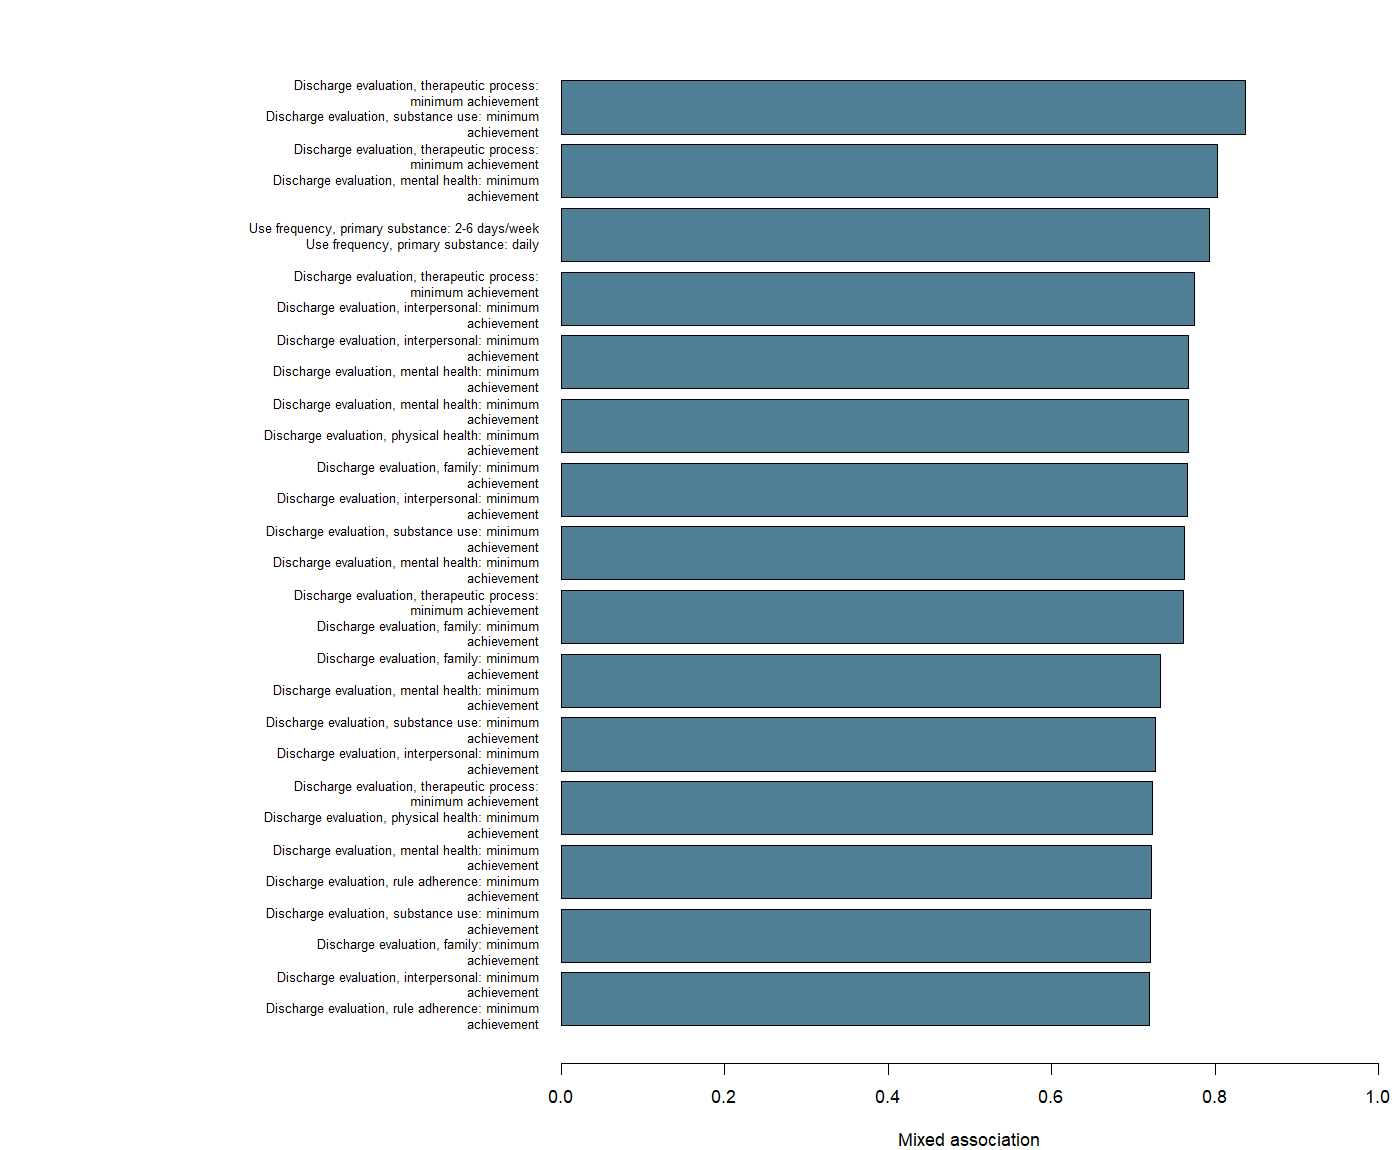

Elapsed: 0.001 minutes


In [29]:
#| label: cox-predictor-associations
#| message: false
#| fig-cap: "Largest predictor associations; no variable is removed by this display."
.t0 <- proc.time()
# Retain the original mixed-association measures and threshold, excluding outcomes and identifiers.
if (run_cox) {
  associations <- cox_cache("cox_predictor_associations", function() {
    data <- py_corrected_datasets[[1L]][predictors]
    mixed_association <- function(x, y) {
      num_x <- is.numeric(x) || is.integer(x)
      num_y <- is.numeric(y) || is.integer(y)
      if (num_x && num_y) return(abs(stats::cor(x, y, method = "spearman")))
      if (!num_x && !num_y) return(as.numeric(vcd::assocstats(table(x, y))$cramer))
      numeric <- if (num_x) x else y
      category <- factor(if (num_x) y else x)
      sqrt(max(summary(stats::lm(numeric ~ category))$r.squared, 0))
    }
    pairs <- utils::combn(predictors, 2L)
    result <- data.frame(Variable1 = pairs[1L, ], Variable2 = pairs[2L, ], Association = vapply(seq_len(ncol(pairs)), function(i) mixed_association(data[[pairs[1L, i]]], data[[pairs[2L, i]]]), numeric(1L)))
    result <- result[is.finite(result$Association) & result$Association > 0.20, , drop = FALSE]
    result[order(-result$Association), , drop = FALSE]
  })
  show_table(associations, "Predictor associations above 0.20; descriptive only")
  top <- head(associations, 15L)
  show_diagnostic_png(function() {
  graphics::par(mar = c(4, 26, 2, 1))
  graphics::barplot(rev(top$Association), names.arg = rev(paste(display_term(top$Variable1, 48L), display_term(top$Variable2, 48L), sep = "\n")), horiz = TRUE, las = 1, cex.names = 0.72, col = "#507e94", xlab = "Mixed association", xlim = c(0, 1))
  }, 1400L, 1150L)
} else cat("Prepared only: the original pairwise association screen has not run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Term,VIF
"Discharge evaluation, therapeutic process: minimum achievement",13.0349
Recorded psychiatric diagnosis,9.3510
"Discharge evaluation, mental health: minimum achievement",9.3070
"Discharge evaluation, interpersonal: minimum achievement",7.9381
Personality or adult-behaviour disorder (F60-F69),7.6205
"Discharge evaluation, therapeutic process: intermediate achievement",7.5160
"Discharge evaluation, substance use: minimum achievement",7.0265
"Discharge evaluation, family: minimum achievement",6.7699
"Discharge evaluation, mental health: intermediate achievement",5.3770
Cocaine paste (primary at admission),5.2195


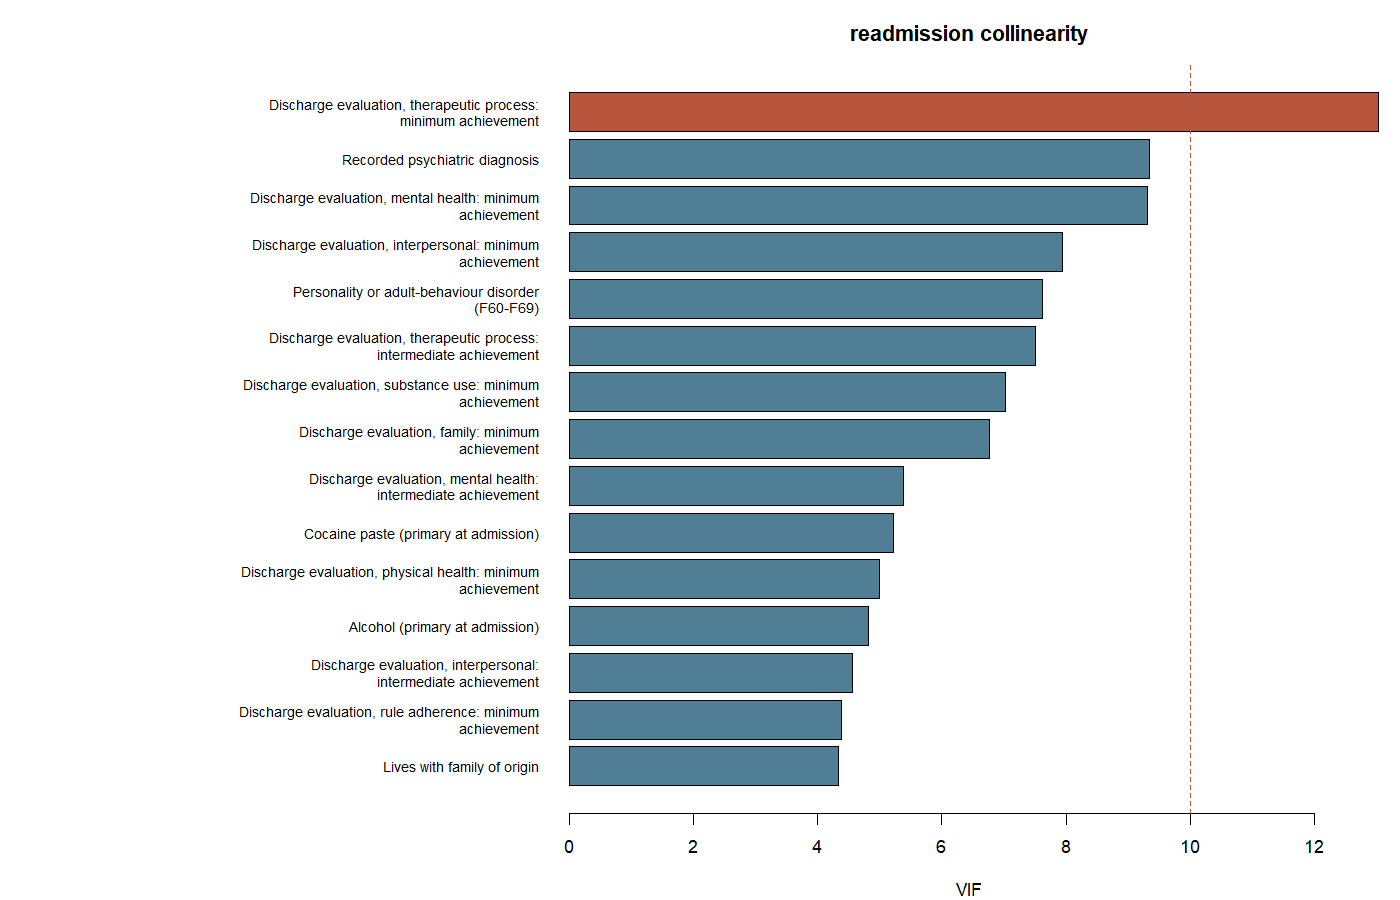

Term,VIF
"Discharge evaluation, therapeutic process: minimum achievement",13.2006
"Discharge evaluation, mental health: minimum achievement",9.6861
Recorded psychiatric diagnosis,8.5647
"Discharge evaluation, interpersonal: minimum achievement",8.1531
Alcohol (primary at admission),7.8975
"Discharge evaluation, therapeutic process: intermediate achievement",7.4963
"Discharge evaluation, substance use: minimum achievement",6.9562
"Discharge evaluation, family: minimum achievement",6.7803
Personality or adult-behaviour disorder (F60-F69),6.4753
Cocaine paste (primary at admission),6.2242


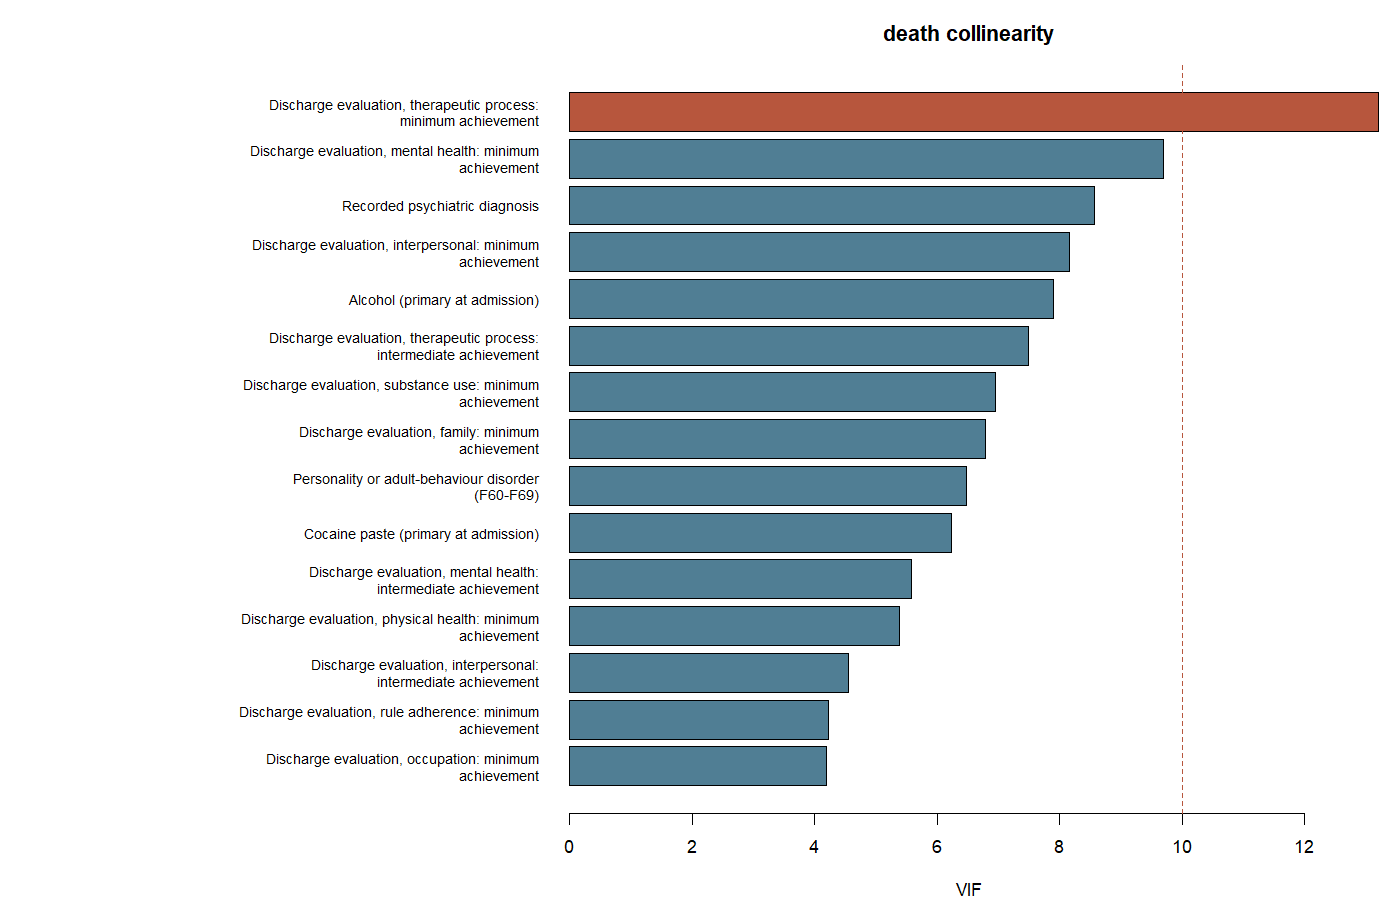

Elapsed: 0.013 minutes


In [30]:
#| label: cox-full-models-and-vif
#| message: false
.t0 <- proc.time()
# Fit the full models once per imputation and reuse their first-imputation fits for VIF.
cox_fits <- list(readmission = list(), death = list())
if (run_cox) {
  stopifnot(historical_control_passed)
  for (outcome in names(cox_formulas)) {
    cox_fits[[outcome]]$full <- lapply(seq_along(py_corrected_datasets), function(i) fit_cox_once(py_corrected_datasets[[i]], cox_formulas[[outcome]]$full, paste0("cox_", outcome, "_full_imp", i), i == 1L))
    vifs <- cox_vif(cox_fits[[outcome]]$full[[1L]])
    show_table(vifs, paste(outcome, "full Cox VIF: first development imputation"))
    top <- head(vifs, 15L)
    show_diagnostic_png(function() {
    graphics::par(mar = c(4, 26, 3, 1))
    graphics::barplot(rev(top$VIF), names.arg = rev(display_term(top$Term, 48L)), horiz = TRUE, las = 1, cex.names = 0.78, col = ifelse(rev(top$Term) == removed_collinear, "#b7563d", "#507e94"), main = paste(outcome, "collinearity"), xlab = "VIF")
    graphics::abline(v = 10, lty = 2, col = "#b7563d")
    }, 1400L, 900L)
    if (outcome == "readmission" && !setequal(vifs$Term[vifs$VIF >= 10], removed_collinear)) stop("The original VIF threshold decision changed; investigator review is required.")
  }
} else cat("Prepared only: full Cox models and VIF figures have not run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


In [31]:
#| label: cox-full-exploratory-evaluation
#| message: false
.t0 <- proc.time()
# Retain this original comparison checkpoint; heavy execution remains gated.
exploratory_evaluation("full")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Prepared only: full historical CV/OOB/calibration not run.


Elapsed: 0.000 minutes


In [32]:
#| label: performance-full-comparison
#| message: true
.t0 <- proc.time()
# Evaluate the candidate at its original discovery step.
performance_run_stage("full")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Stage,Horizon,C,IBS
readmission,full,6,0.6426,0.0387
readmission,full,12,0.6309,0.0610
readmission,full,36,0.6147,0.1085
readmission,full,60,0.6095,0.1333


Outcome,Stage,Horizon,C,IBS
death,full,6,0.7659,0.0045
death,full,12,0.7591,0.0065
death,full,36,0.7640,0.0144
death,full,60,0.7632,0.0219


time_months,ici_mean,ici_sd,ici_min,ici_p025,ici_p975,ici_max,e50_mean,e50_sd,e50_min,e50_p025,e50_p975,e50_max,e90_mean,e90_sd,e90_min,e90_p025,e90_p975,e90_max,emax_mean,emax_sd,emax_min,emax_p025,emax_p975,emax_max,ece_mean,ece_sd,ece_min,ece_p025,ece_p975,ece_max,eo_mean,eo_sd,eo_min,eo_p025,eo_p975,eo_max,mean_pred,mean_pred_sd,mean_pred_min,mean_pred_p025,mean_pred_p975,mean_pred_max,observed,observed_sd,observed_min,observed_p025,observed_p975,observed_max,n_runs,n_imp
6,0.0060,1e-04,0.0059,0.0059,0.0062,0.0062,0.0015,3e-04,0.0010,0.0010,0.0020,0.0020,0.0192,4e-04,0.0185,0.0185,0.0199,0.0199,0.3691,0.0150,0.3443,0.3443,0.3973,0.3973,0.0021,4e-04,0.0015,0.0015,0.0033,0.0033,0.9913,2e-04,0.9910,0.9910,0.9916,0.9916,0.0719,0,0.0719,0.0719,0.0719,0.0719,0.0726,0,0.0726,0.0726,0.0726,0.0726,20,5
12,0.0075,1e-04,0.0072,0.0072,0.0077,0.0077,0.0020,4e-04,0.0011,0.0011,0.0025,0.0025,0.0210,4e-04,0.0204,0.0204,0.0217,0.0217,0.4659,0.0172,0.4358,0.4358,0.4962,0.4962,0.0026,6e-04,0.0018,0.0018,0.0039,0.0039,0.9912,2e-04,0.9908,0.9908,0.9914,0.9914,0.1135,0,0.1135,0.1135,0.1136,0.1136,0.1146,0,0.1146,0.1146,0.1146,0.1146,20,5
36,0.0095,3e-04,0.0090,0.0090,0.0099,0.0099,0.0036,5e-04,0.0026,0.0026,0.0045,0.0045,0.0210,6e-04,0.0202,0.0202,0.0225,0.0225,0.5588,0.0157,0.5333,0.5333,0.5852,0.5852,0.0038,8e-04,0.0027,0.0027,0.0055,0.0055,0.9883,1e-04,0.9880,0.9880,0.9886,0.9886,0.1995,0,0.1994,0.1994,0.1995,0.1995,0.2019,0,0.2019,0.2019,0.2019,0.2019,20,5
60,0.0103,3e-04,0.0098,0.0098,0.0107,0.0107,0.0052,4e-04,0.0044,0.0044,0.0059,0.0059,0.0200,4e-04,0.0189,0.0189,0.0210,0.0210,0.5707,0.0157,0.5465,0.5465,0.5952,0.5952,0.0052,7e-04,0.0042,0.0042,0.0064,0.0064,0.9840,1e-04,0.9837,0.9837,0.9842,0.9842,0.2423,0,0.2422,0.2422,0.2424,0.2424,0.2462,0,0.2462,0.2462,0.2462,0.2462,20,5


time_months,ici_mean,ici_sd,ici_median,ece_mean,ece_sd,eo_mean,eo_sd,mean_pred_mean,observed_mean,n_bins_mean,n_reps
6,0.0016,1e-04,0.0016,0.0006,1e-04,1.0079,7e-04,0.0069,0.0069,8,20
12,0.0027,1e-04,0.0027,0.0011,1e-04,1.0099,7e-04,0.0108,0.0107,8,20
36,0.0066,1e-04,0.0066,0.0024,2e-04,1.0117,5e-04,0.0289,0.0286,8,20
60,0.0089,2e-04,0.0089,0.0026,3e-04,1.0191,5e-04,0.0461,0.0452,8,20


Elapsed: 0.002 minutes


In [33]:
#| label: cox-collinearity-comparison
#| message: false
.t0 <- proc.time()
# Retain the historical single-term removal; reuse cached fits for AICc and nested D1.
if (run_cox) {
  for (outcome in names(cox_formulas)) {
    cox_fits[[outcome]]$reduced <- lapply(seq_along(py_corrected_datasets), function(i) fit_cox_once(py_corrected_datasets[[i]], cox_formulas[[outcome]]$reduced, paste0("cox_", outcome, "_reduced_imp", i), i == 1L))
    full_aicc <- cox_aicc(cox_fits[[outcome]]$full)
    reduced_aicc <- cox_aicc(cox_fits[[outcome]]$reduced)
    show_table(data.frame(Outcome = outcome, Full_AICc = full_aicc$mean_aicc, Reduced_AICc = reduced_aicc$mean_aicc, Delta_AICc = reduced_aicc$mean_aicc - full_aicc$mean_aicc), "Mean AICc across five imputations; the original partial-name access also returned AICc")
    d1 <- mice::D1(mice::as.mira(cox_fits[[outcome]]$full), mice::as.mira(cox_fits[[outcome]]$reduced))
    print(d1)
  }
} else cat("Prepared only: reduced models, AICc and nested D1 have not run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Outcome,Full_AICc,Reduced_AICc,Delta_AICc
readmission,282688.3,282686.3,-1.9387


Outcome,Full_AICc,Reduced_AICc,Delta_AICc
death,53929.18,53927.1,-2.0844


   test  statistic df1 df2 dfcom   p.value          riv
 1 ~~ 2 0.07840598   1   4 15182 0.7933532 7.723296e-05
   test   statistic df1 df2 dfcom   p.value          riv
 1 ~~ 2 0.003736108   1   4  2974 0.9541929 0.0003712682


Elapsed: 0.015 minutes


In [34]:
#| label: cox-reduced-exploratory-evaluation
#| message: false
.t0 <- proc.time()
# Retain this original comparison checkpoint; heavy execution remains gated.
exploratory_evaluation("reduced")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Prepared only: reduced historical CV/OOB/calibration not run.


Elapsed: 0.000 minutes


In [35]:
#| label: performance-reduced-comparison
#| message: true
.t0 <- proc.time()
# Evaluate the candidate at its original discovery step.
performance_run_stage("reduced")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Stage,Horizon,C,IBS
readmission,reduced,6,0.6426,0.0387
readmission,reduced,12,0.6310,0.0610
readmission,reduced,36,0.6148,0.1085
readmission,reduced,60,0.6096,0.1333


Outcome,Stage,Horizon,C,IBS
death,reduced,6,0.7661,0.0045
death,reduced,12,0.7593,0.0065
death,reduced,36,0.7641,0.0144
death,reduced,60,0.7633,0.0219


time_months,ici_mean,ici_sd,ici_min,ici_p025,ici_p975,ici_max,e50_mean,e50_sd,e50_min,e50_p025,e50_p975,e50_max,e90_mean,e90_sd,e90_min,e90_p025,e90_p975,e90_max,emax_mean,emax_sd,emax_min,emax_p025,emax_p975,emax_max,ece_mean,ece_sd,ece_min,ece_p025,ece_p975,ece_max,eo_mean,eo_sd,eo_min,eo_p025,eo_p975,eo_max,mean_pred,mean_pred_sd,mean_pred_min,mean_pred_p025,mean_pred_p975,mean_pred_max,observed,observed_sd,observed_min,observed_p025,observed_p975,observed_max,n_runs,n_imp
6,0.0060,1e-04,0.0058,0.0058,0.0062,0.0062,0.0015,3e-04,0.0010,0.0010,0.0020,0.0020,0.0192,3e-04,0.0186,0.0186,0.0198,0.0198,0.3695,0.0151,0.3440,0.3440,0.3977,0.3977,0.0021,4e-04,0.0014,0.0014,0.0030,0.0030,0.9913,2e-04,0.9910,0.9910,0.9916,0.9916,0.0719,0,0.0719,0.0719,0.0719,0.0719,0.0726,0,0.0726,0.0726,0.0726,0.0726,20,5
12,0.0075,1e-04,0.0073,0.0073,0.0078,0.0078,0.0019,4e-04,0.0011,0.0011,0.0025,0.0025,0.0211,3e-04,0.0206,0.0206,0.0217,0.0217,0.4661,0.0172,0.4357,0.4357,0.4963,0.4963,0.0025,6e-04,0.0018,0.0018,0.0041,0.0041,0.9912,2e-04,0.9908,0.9908,0.9914,0.9914,0.1135,0,0.1135,0.1135,0.1136,0.1136,0.1146,0,0.1146,0.1146,0.1146,0.1146,20,5
36,0.0095,3e-04,0.0089,0.0089,0.0098,0.0098,0.0036,5e-04,0.0028,0.0028,0.0044,0.0044,0.0211,5e-04,0.0201,0.0201,0.0221,0.0221,0.5591,0.0158,0.5329,0.5329,0.5855,0.5855,0.0038,7e-04,0.0028,0.0028,0.0052,0.0052,0.9883,1e-04,0.9880,0.9880,0.9886,0.9886,0.1995,0,0.1994,0.1994,0.1995,0.1995,0.2019,0,0.2019,0.2019,0.2019,0.2019,20,5
60,0.0103,3e-04,0.0100,0.0100,0.0107,0.0107,0.0052,4e-04,0.0043,0.0043,0.0058,0.0058,0.0200,4e-04,0.0189,0.0189,0.0209,0.0209,0.5711,0.0158,0.5471,0.5471,0.5965,0.5965,0.0051,6e-04,0.0042,0.0042,0.0063,0.0063,0.9840,1e-04,0.9837,0.9837,0.9842,0.9842,0.2423,0,0.2422,0.2422,0.2424,0.2424,0.2462,0,0.2462,0.2462,0.2462,0.2462,20,5


time_months,ici_mean,ici_sd,ici_median,ece_mean,ece_sd,eo_mean,eo_sd,mean_pred_mean,observed_mean,n_bins_mean,n_reps
6,0.0016,1e-04,0.0016,0.0006,1e-04,1.0078,7e-04,0.0069,0.0069,8,20
12,0.0027,1e-04,0.0027,0.0011,1e-04,1.0098,7e-04,0.0108,0.0107,8,20
36,0.0067,1e-04,0.0066,0.0024,2e-04,1.0117,6e-04,0.0289,0.0286,8,20
60,0.0089,2e-04,0.0089,0.0026,3e-04,1.0191,5e-04,0.0461,0.0452,8,20


Elapsed: 0.002 minutes


## Proportional hazards: retained first-imputation diagnostic
The original cox.zph test uses its default KM time transformation on the reduced model fitted to the complete first development imputation. The full table remains browsable. Focus plots retain the original 10th–90th percentile time window, LOESS span 0.50, supersmoother and zero reference.
The full-model plots supply **panel A only** of eFigures 3 and 4. SHAP-informed and DeepSurv panels belong to later notebooks. Statistical calculations retain all relevant observations; compact PNG display sizes prevent embedded output from dominating notebook size.


In [36]:
#| label: cox-ph-tests-and-checkpoint
#| message: false
.t0 <- proc.time()
# Reuse reduced fits; never recompute NPH across all five imputations.
ph_tests <- list()
if (run_cox) {
  for (outcome in names(cox_formulas)) {
    ph_tests[[outcome]] <- survival::cox.zph(cox_fits[[outcome]]$reduced[[1L]])
    show_table(cox_ph_table(ph_tests[[outcome]], outcome), paste(outcome, "PH tests: complete first development imputation"))
  }
  ph_comparison <- compare_ph(ph_tests)
  cox_review(ph_comparison, "full_PH")
} else cat("Prepared only: NPH tests and eTable 10 comparison have not run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Outcome,Term,Chi_square,df,p
readmission,"Age at admission, yr",5.5092,1,0.0189
readmission,Communal poverty rate,0.5441,1,0.4607
readmission,"Treatment episode length, mo",21.8458,1,0.0000
readmission,Foreign nationality,0.7668,1,0.3812
readmission,Recorded Indigenous ethnicity,4.3783,1,0.0364
readmission,Psychiatric diagnosis under study,23.3688,1,0.0000
readmission,Recorded psychiatric diagnosis,0.3591,1,0.5490
readmission,Mood disorder (F30-F39),0.0263,1,0.8711
readmission,Personality or adult-behaviour disorder (F60-F69),1.0792,1,0.2989
readmission,"Severe mental disorder (F0, F2, F7-F9)",0.0010,1,0.9743


Outcome,Term,Chi_square,df,p
death,"Age at admission, yr",0.0026,1,0.9595
death,Communal poverty rate,5.5200,1,0.0188
death,"Treatment episode length, mo",0.7868,1,0.3751
death,Foreign nationality,0.5284,1,0.4673
death,Recorded Indigenous ethnicity,1.2081,1,0.2717
death,Psychiatric diagnosis under study,7.0370,1,0.0080
death,Recorded psychiatric diagnosis,0.1745,1,0.6761
death,Mood disorder (F30-F39),2.4349,1,0.1187
death,Personality or adult-behaviour disorder (F60-F69),0.2002,1,0.6546
death,"Severe mental disorder (F0, F2, F7-F9)",0.4955,1,0.4815


Outcome,Term,df,Previous,Chi_square,p,Difference,classification
readmission,GLOBAL,64,281.07,279.2018,0e+00,-1.8682,substantial
readmission,Administrative discharge: rule violation or undetermined reason,1,60.65,60.6597,0e+00,0.0097,substantial
readmission,Referred from justice sector,1,43.08,43.0105,0e+00,-0.0695,substantial
death,GLOBAL,64,178.78,180.1393,0e+00,1.3593,substantial
death,Administrative discharge: rule violation or undetermined reason,1,82.43,82.9605,0e+00,0.5305,substantial
death,Any selected physical comorbidity recorded,1,15.15,14.6785,1e-04,-0.4715,substantial


Elapsed: 0.016 minutes


Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
"collapsing to unique 'x' values"


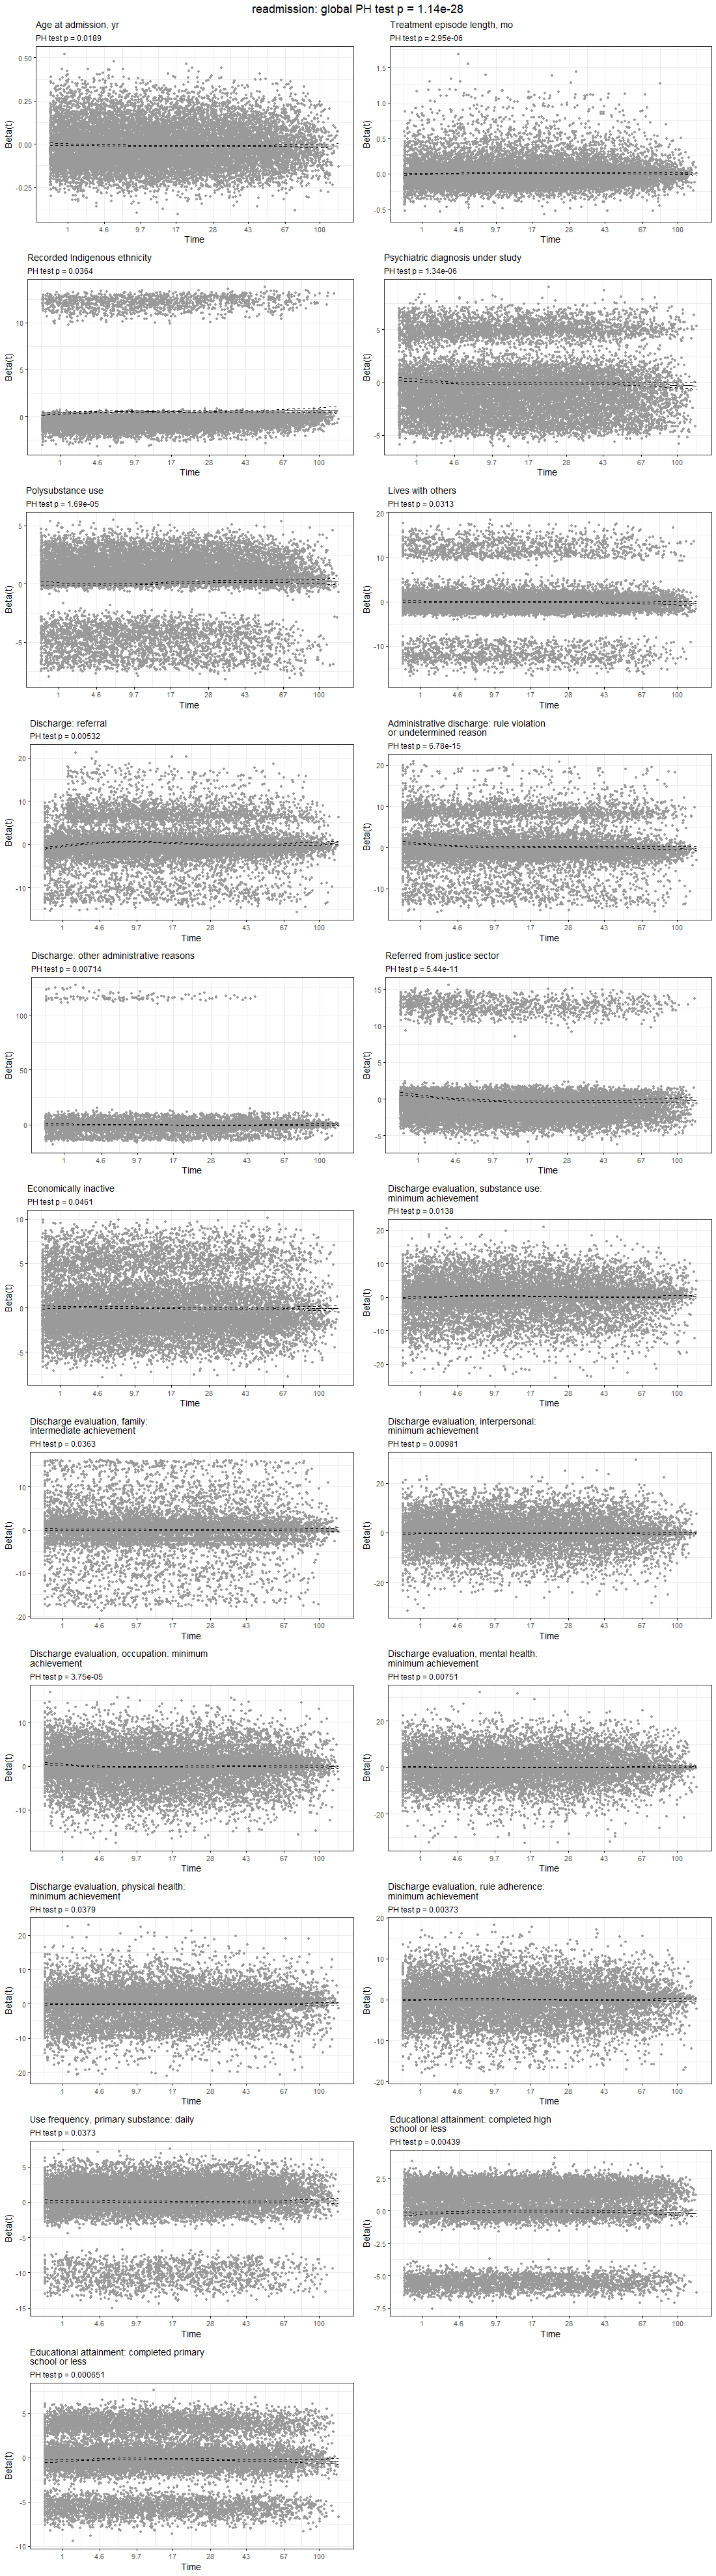

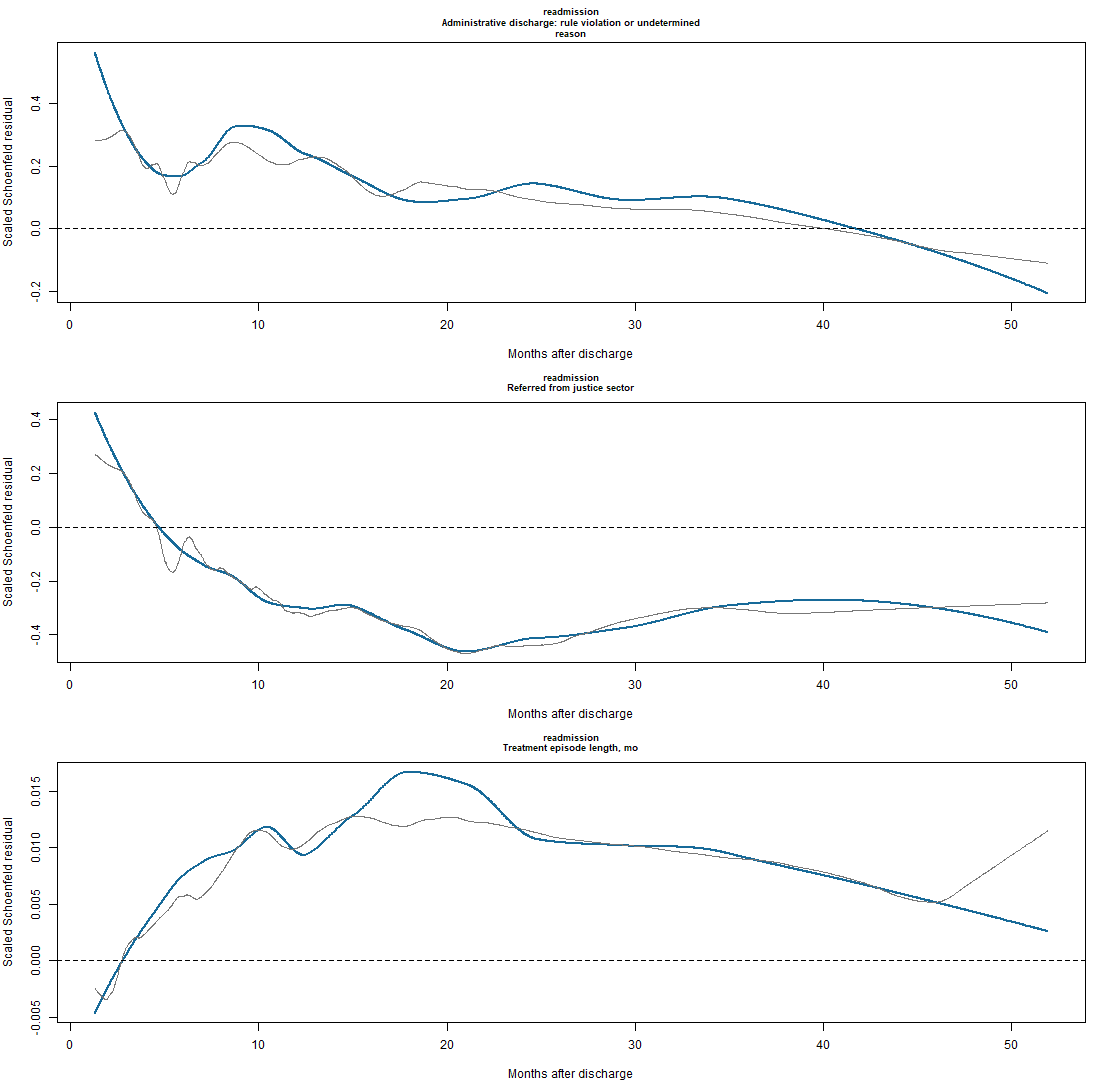

Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
"collapsing to unique 'x' values"


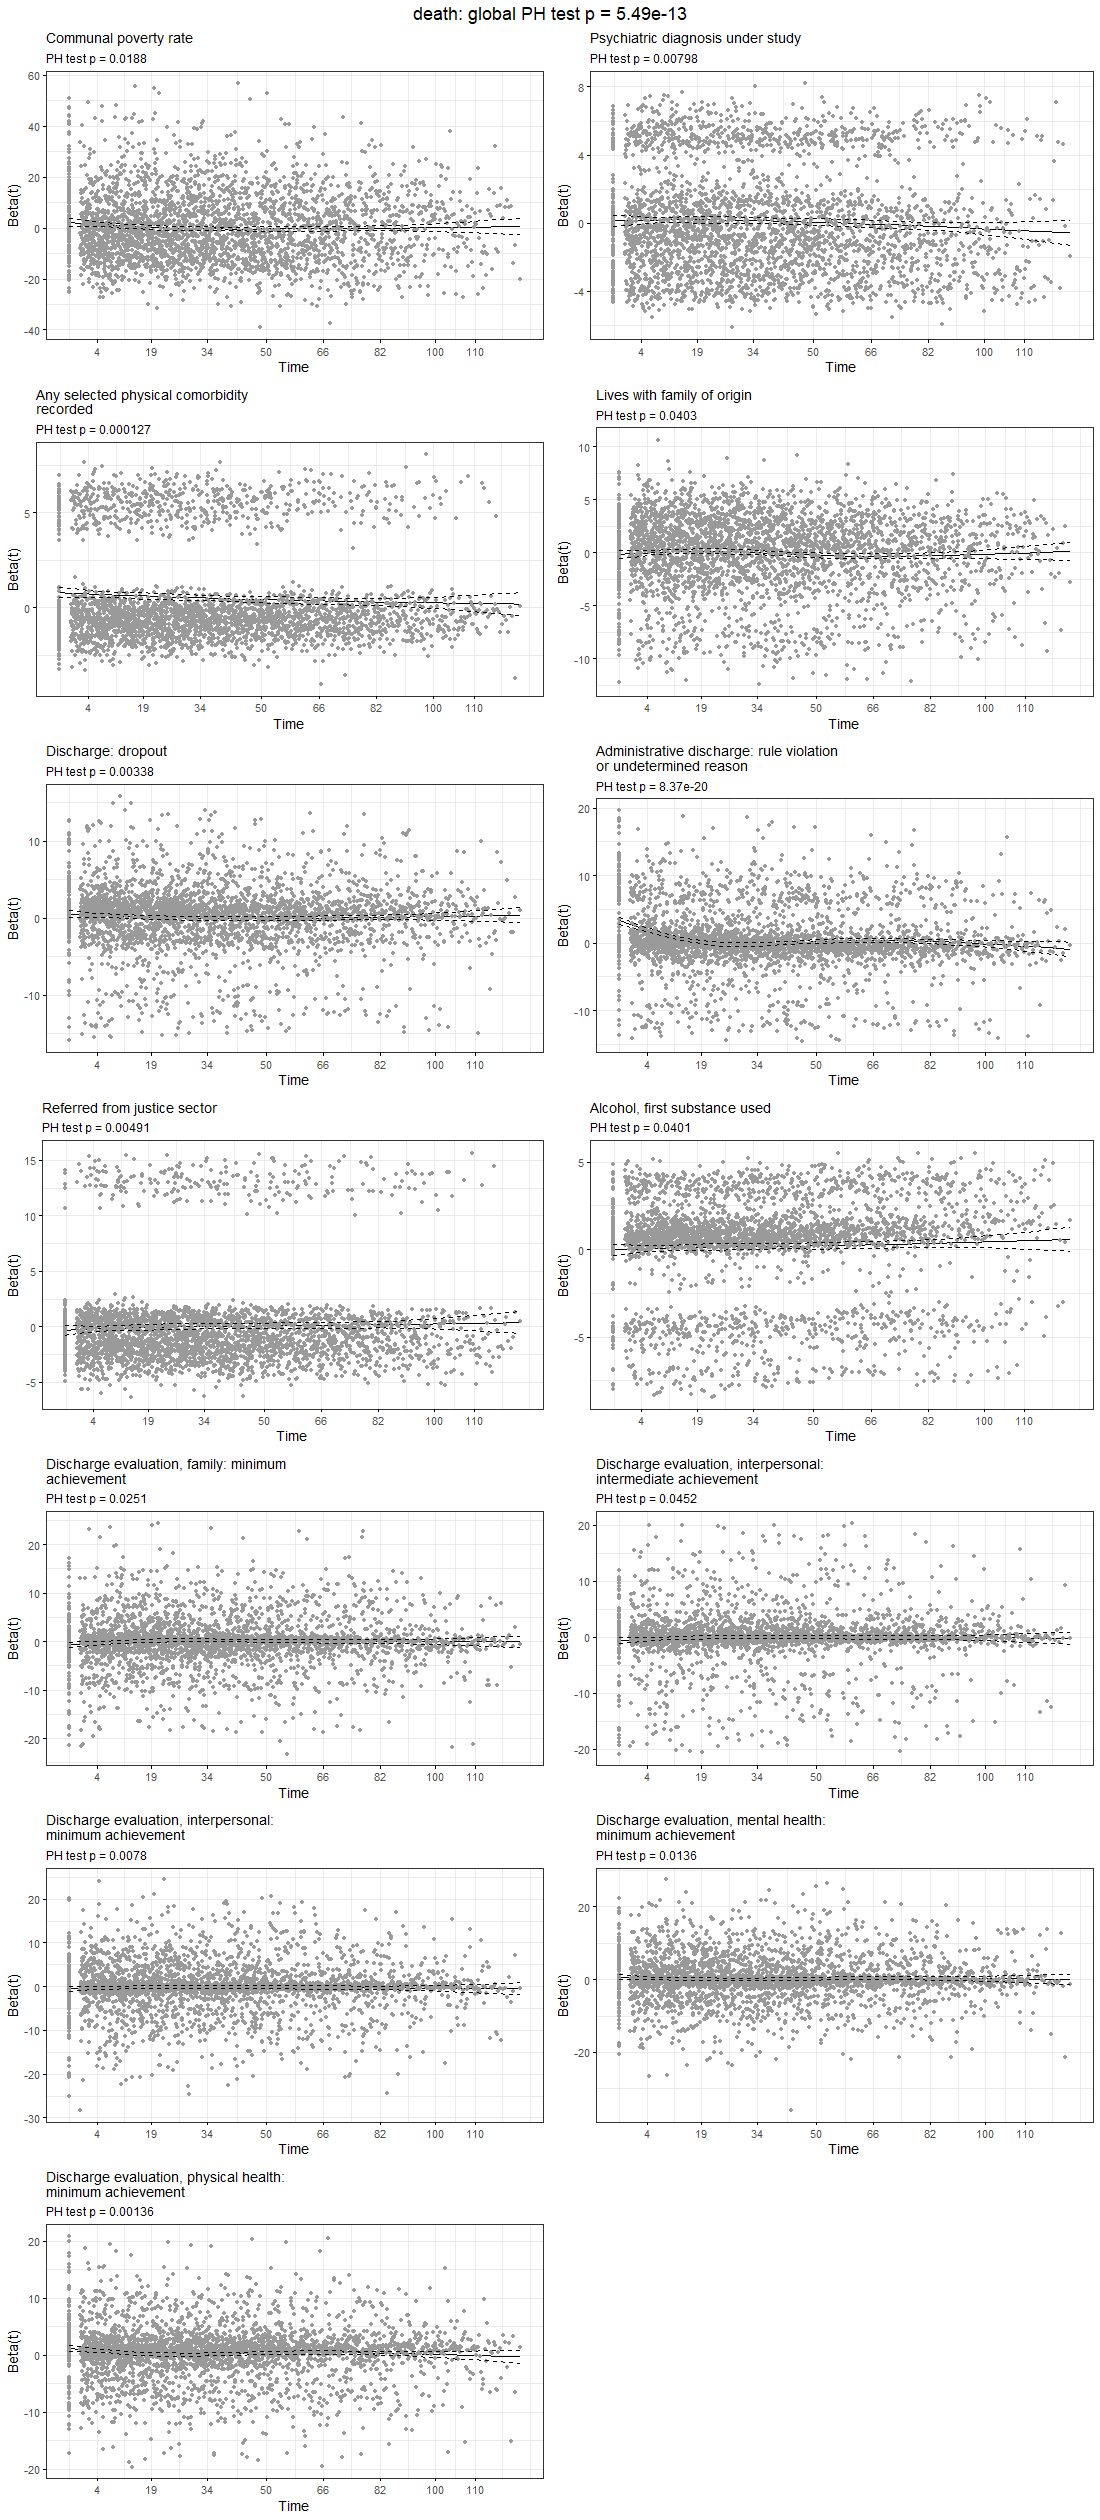

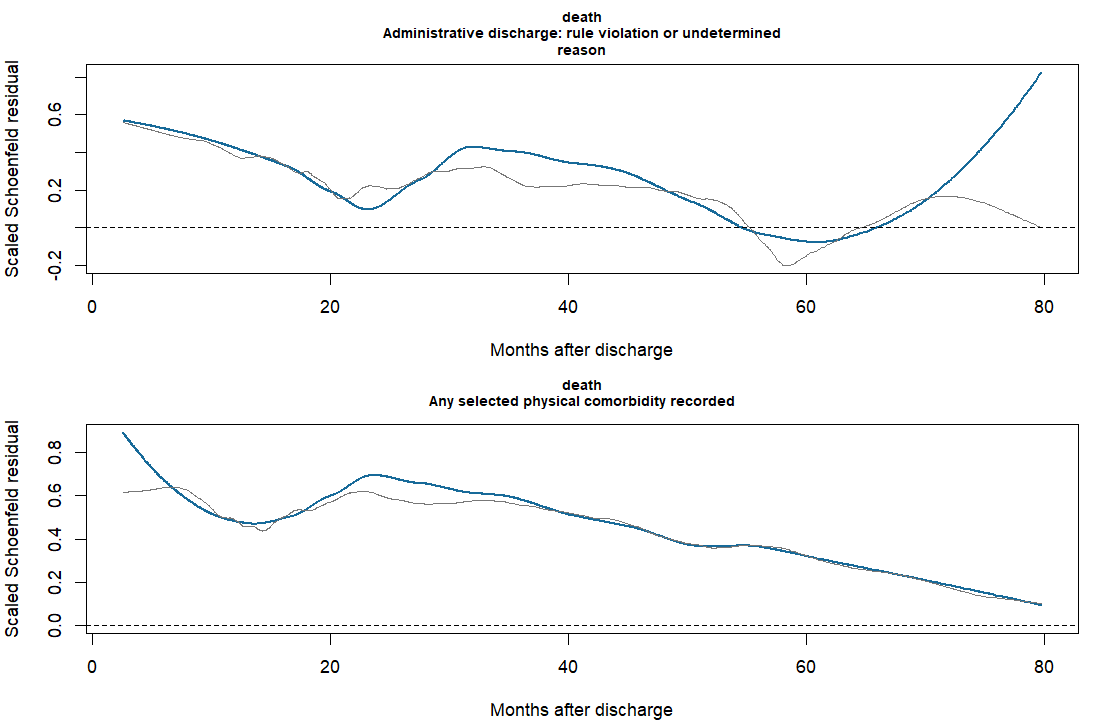

Elapsed: 0.268 minutes


In [37]:
#| label: cox-ph-focused-plots
#| message: false
.t0 <- proc.time()
# Reuse stored scaled Schoenfeld residuals instead of refitting once per plotted variable.
draw_focused_ph <- function(fit, terms, title) {
  residuals <- stats::residuals(fit, type = "scaledsch")
  time <- as.numeric(rownames(residuals))
  limits <- stats::quantile(time, c(0.10, 0.90))
  for (term in terms) {
    column <- which(sub("TRUE$", "", colnames(residuals)) == term)
    stopifnot(length(column) == 1L)
    keep <- is.finite(time) & is.finite(residuals[, column]) & time >= limits[1L] & time <= limits[2L]
    d <- data.frame(time = time[keep], residual = residuals[keep, column])
    smoother <- stats::loess(residual ~ time, data = d, span = 0.50)
    order_time <- order(d$time)
    supersmoother <- stats::supsmu(d$time, d$residual)
    graphics::plot(d$time[order_time], stats::fitted(smoother)[order_time], type = "l", ylim = range(c(stats::fitted(smoother), supersmoother$y, 0)), col = "#176a99", lwd = 2, xlab = "Months after discharge", ylab = "Scaled Schoenfeld residual", main = paste(title, display_term(term, 60L), sep = "\n"), cex.main = 0.75)
    graphics::lines(supersmoother, col = "#777777")
    graphics::abline(h = 0, lty = 2)
  }
}
if (run_cox) {
  for (outcome in names(ph_tests)) {
    test <- ph_tests[[outcome]]
    selected <- setdiff(rownames(test$table)[test$table[, "p"] < 0.05], "GLOBAL")
    if (length(selected)) {
      plot <- survminer::ggcoxzph(test, var = selected, point.col = "#9a9a9a", ggtheme = ggplot2::theme_bw(base_size = 9))
      for (i in seq_along(plot)) {
        title <- display_term(selected[i], 42L)
        plot[[i]] <- plot[[i]] + ggplot2::labs(title = title, subtitle = sprintf("PH test p = %.3g", test$table[selected[i], "p"]), y = "Beta(t)") + ggplot2::theme(plot.title = ggplot2::element_text(size = 9), plot.subtitle = ggplot2::element_text(size = 8), axis.text = ggplot2::element_text(size = 7))
      }
      stopifnot(utils::packageVersion("gridExtra") == base::package_version(lock$Packages$gridExtra$Version))
      show_diagnostic_png(function() gridExtra::grid.arrange(grobs = plot, ncol = 2L, top = sprintf("%s: global PH test p = %.3g", outcome, test$table["GLOBAL", "p"])), 1100L, 360L * ceiling(length(selected) / 2L))
    }
    # The manuscript panel A shows only the leading discharge term, not the full violation grid.
    destination <- file.path(resolve_path(config$paths$figures), paste0(if (outcome == "readmission") "eFigure3" else "eFigure4", "_panelA_full_PH_", cox_date, "_", cox_signature, ".png"))
    grDevices::png(destination, width = 1400, height = 900, res = 180)
    graphics::par(mfrow = c(1L, 1L), mar = c(4, 4, 3, 1))
    draw_focused_ph(cox_fits[[outcome]]$reduced[[1L]], discharge_stratum, paste("A. Full Cox:", outcome))
    grDevices::dev.off()
    cox_written <- c(cox_written, destination)
    focused <- if (outcome == "readmission") c(discharge_stratum, "adm_motive_justice_sector", "dit_m") else c(discharge_stratum, "any_phys_dx")
    show_diagnostic_png(function() {
      graphics::par(mfrow = c(length(focused), 1L), mar = c(4, 4, 3, 1))
      draw_focused_ph(cox_fits[[outcome]]$reduced[[1L]], focused, outcome)
    }, 1100L, 360L * length(focused))
  }
} else cat("Prepared only: Schoenfeld figures are not available until the diagnostic checkpoint passes.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


In [38]:
#| label: cox-discharge-followup-diagnostic
#| message: false
.t0 <- proc.time()
# Preserve original bins while explicitly separating follow-up counts from observed deaths.
data <- py_corrected_datasets[[1L]]
interval <- cut(data$death_time_from_disch_m, c(0, 5, 10, 20, 60, 120), include.lowest = FALSE)
discharge <- factor(ifelse(data[[discharge_stratum]] == 1, "Rule violation/undetermined", ifelse(data$tr_outcome_adm_discharge_adm_reasons == 1, "Administrative other reasons", "Other discharge")))
followup <- stats::aggregate(cbind(Participants = rep(1L, nrow(data)), Observed_deaths = as.integer(data$death_event)) ~ Interval + Discharge, data = data.frame(Interval = interval, Discharge = discharge), FUN = sum)
show_table(followup, "Follow-up ending within each interval, with observed deaths shown separately; no participant is excluded")
cat("Rows outside the original 0-120 month plotting intervals:", sum(is.na(interval)), "\n")
rm(data)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Interval,Discharge,Participants,Observed_deaths
"(0,5]",Administrative other reasons,155,10
"(5,10]",Administrative other reasons,30,2
"(10,20]",Administrative other reasons,159,3
"(20,60]",Administrative other reasons,579,5
"(60,120]",Administrative other reasons,7,0
"(0,5]",Other discharge,5748,271
"(5,10]",Other discharge,1389,194
"(10,20]",Other discharge,5362,392
"(20,60]",Other discharge,23789,1178
"(60,120]",Other discharge,26136,582


Rows outside the original 0-120 month plotting intervals: 2265 


Elapsed: 0.001 minutes


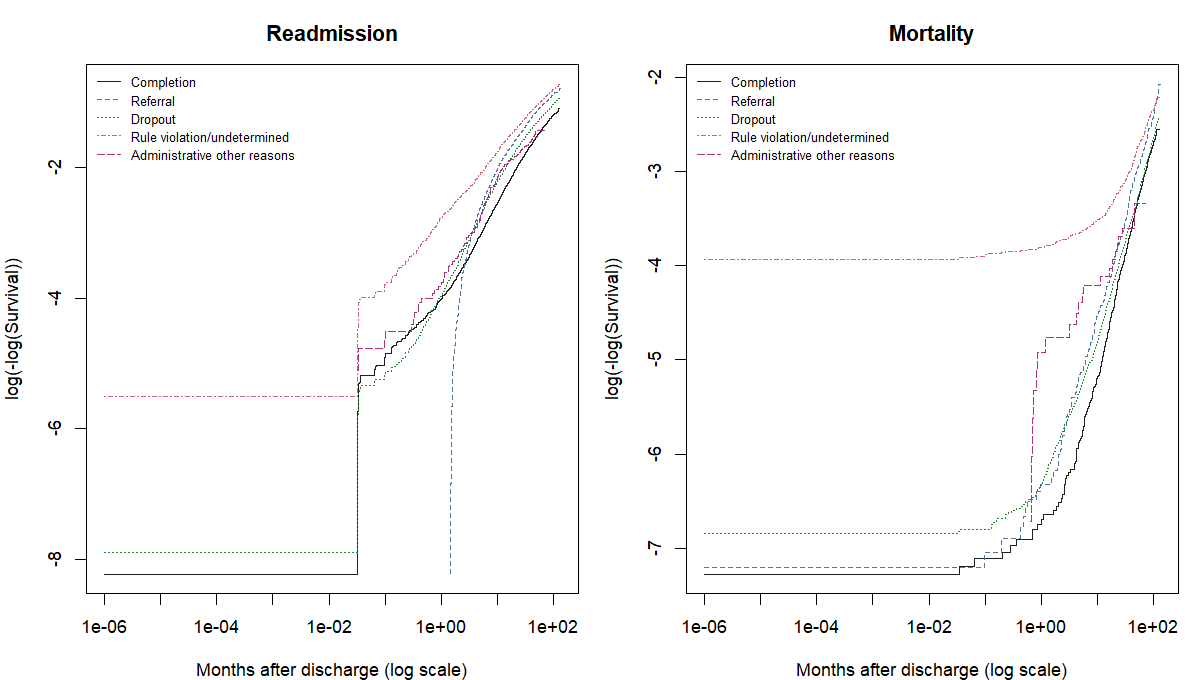

Elapsed: 0.002 minutes


In [39]:
#| label: cox-loglog-discharge
#| message: false
.t0 <- proc.time()
# Keep the original English log-log curves; remove only the duplicate language display.
if (run_cox) {
  data <- py_corrected_datasets[[1L]]
  discharge <- ifelse(data$tr_outcome_referral == 1, "Referral", ifelse(data$tr_outcome_dropout == 1, "Dropout", ifelse(data[[discharge_stratum]] == 1, "Rule violation/undetermined", ifelse(data$tr_outcome_adm_discharge_adm_reasons == 1, "Administrative other reasons", "Completion"))))
  data$discharge_group <- factor(discharge, levels = c("Completion", "Referral", "Dropout", "Rule violation/undetermined", "Administrative other reasons"))
  colors <- c("#202020", "#4477aa", "#228833", "#cc6677", "#aa3377")
  show_diagnostic_png(function() {
  graphics::par(mfrow = c(1L, 2L), mar = c(4, 4, 3, 1))
  for (outcome in names(cox_formulas)) {
    response <- if (outcome == "readmission") "Surv(readmit_time_from_disch_m, readmit_event)" else "Surv(death_time_from_disch_m, death_event)"
    formula <- stats::as.formula(paste(response, "~ discharge_group"), env = formula_environment)
    fit <- survival::survfit(formula, data = data)
    graphics::plot(fit, fun = "cloglog", col = colors, lty = seq_along(colors), conf.int = FALSE, main = if (outcome == "readmission") "Readmission" else "Mortality", xlab = "Months after discharge (log scale)", ylab = "log(-log(Survival))")
    graphics::legend("topleft", legend = levels(data$discharge_group), col = colors, lty = seq_along(colors), cex = 0.7, y.intersp = 1.2, bty = "n")
  }
  }, 1200L, 680L)
} else cat("Prepared only: log-log survival curves have not run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


## Stratified full models and downstream boundary
The original final full models add rule-violation/undetermined discharge as a stratum alongside treatment modality. Other discharge coefficients and any_phys_dx remain covariates. New NPH results must be reviewed before this historical decision is carried forward.
AICc values under different stratification structures are displayed as descriptive source values, not as a valid isolated test of the stratification benefit. The original ancillary D1 tests compare coefficient removal under unchanged treatment strata; they do not compare the newly stratified model.
The manuscript's final discrimination/IBS and calibration engines belong to the later comparison/consolidation notebooks. Their canonical schemes differ from the old exploratory evaluator in prediction21; old exploratory metrics must never be relabelled as final Table 2 results.


Sequential decision contract: treatment modality strata -> original collinearity reduction -> first-imputation PH tests and residual plots -> one additional discharge stratum. This stage does not stratify on physical diagnosis, justice referral or every significant PH term. The later model families must be evaluated in their own original order; no final strata are imposed in advance.


In [40]:
#| label: cox-stratified-full-models
#| message: false
.t0 <- proc.time()
# Preserve the original final formula after the PH investigator checkpoint.
if (run_cox) {
  for (outcome in names(cox_formulas)) {
    cox_fits[[outcome]]$stratified <- lapply(seq_along(py_corrected_datasets), function(i) fit_cox_once(py_corrected_datasets[[i]], cox_formulas[[outcome]]$stratified, paste0("cox_", outcome, "_stratified_imp", i), i == 1L))
    show_table(cox_aicc(cox_fits[[outcome]]$stratified)$per_imputation, paste(outcome, "stratified model: descriptive AICc; not a nested test of stratification"))
  }
  cox_handoff <- cox_cache("cox_full_model_handoff", function() list(formulas = cox_formulas, predictors = predictors, physical_variable = "any_phys_dx", physical_under_study_included = FALSE, nph_imputation = 1L, nph_scope = "Complete development sample, not out-of-fold", data_signature = cox_signature, matrix_columns = matrix_names))
} else cat("Prepared only: final stratified fits and model handoff have not run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Imputation,Terms,Events,AIC,AICc
1,63,15247,272551.2,272551.7
2,63,15247,272557.5,272558.1
3,63,15247,272554.8,272555.4
4,63,15247,272552.0,272552.5
5,63,15247,272553.3,272553.8


Imputation,Terms,Events,AIC,AICc
1,63,3039,51484.83,51487.54
2,63,3039,51493.81,51496.52
3,63,3039,51491.34,51494.05
4,63,3039,51491.85,51494.56
5,63,3039,51492.82,51495.53


Elapsed: 0.011 minutes


In [41]:
#| label: cox-stratified-exploratory-evaluation
#| message: false
.t0 <- proc.time()
# Retain this original comparison checkpoint; heavy execution remains gated.
exploratory_evaluation("stratified")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Prepared only: stratified historical CV/OOB/calibration not run.


Elapsed: 0.000 minutes


In [42]:
#| label: performance-stratified-comparison
#| message: true
.t0 <- proc.time()
# Evaluate the candidate at its original discovery step.
performance_run_stage("stratified")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Stage,Horizon,C,IBS
readmission,stratified,6,0.6437,0.0387
readmission,stratified,12,0.6312,0.0610
readmission,stratified,36,0.6146,0.1085
readmission,stratified,60,0.6094,0.1333


Outcome,Stage,Horizon,C,IBS
death,stratified,6,0.7835,0.0044
death,stratified,12,0.7663,0.0064
death,stratified,36,0.7652,0.0144
death,stratified,60,0.7634,0.0218


time_months,ici_mean,ici_sd,ici_min,ici_p025,ici_p975,ici_max,e50_mean,e50_sd,e50_min,e50_p025,e50_p975,e50_max,e90_mean,e90_sd,e90_min,e90_p025,e90_p975,e90_max,emax_mean,emax_sd,emax_min,emax_p025,emax_p975,emax_max,ece_mean,ece_sd,ece_min,ece_p025,ece_p975,ece_max,eo_mean,eo_sd,eo_min,eo_p025,eo_p975,eo_max,mean_pred,mean_pred_sd,mean_pred_min,mean_pred_p025,mean_pred_p975,mean_pred_max,observed,observed_sd,observed_min,observed_p025,observed_p975,observed_max,n_runs,n_imp
6,0.0065,1e-04,0.0063,0.0063,0.0066,0.0066,0.0020,3e-04,0.0015,0.0015,0.0025,0.0025,0.0198,3e-04,0.0193,0.0193,0.0203,0.0203,0.4314,0.0186,0.4051,0.4051,0.4681,0.4681,0.0021,3e-04,0.0017,0.0017,0.0029,0.0029,0.9899,2e-04,0.9895,0.9895,0.9902,0.9902,0.0718,0,0.0718,0.0718,0.0718,0.0718,0.0726,0,0.0726,0.0726,0.0726,0.0726,20,5
12,0.0080,1e-04,0.0078,0.0078,0.0082,0.0082,0.0028,3e-04,0.0019,0.0019,0.0032,0.0032,0.0216,3e-04,0.0211,0.0211,0.0221,0.0221,0.4805,0.0210,0.4476,0.4476,0.5183,0.5183,0.0027,5e-04,0.0019,0.0019,0.0036,0.0036,0.9901,2e-04,0.9897,0.9897,0.9903,0.9903,0.1134,0,0.1134,0.1134,0.1134,0.1134,0.1146,0,0.1146,0.1146,0.1146,0.1146,20,5
36,0.0096,3e-04,0.0091,0.0091,0.0100,0.0100,0.0037,5e-04,0.0028,0.0028,0.0045,0.0045,0.0214,6e-04,0.0205,0.0205,0.0226,0.0226,0.5589,0.0191,0.5153,0.5153,0.5943,0.5943,0.0040,7e-04,0.0027,0.0027,0.0059,0.0059,0.9882,1e-04,0.9879,0.9879,0.9885,0.9885,0.1995,0,0.1994,0.1994,0.1995,0.1995,0.2019,0,0.2019,0.2019,0.2019,0.2019,20,5
60,0.0102,3e-04,0.0097,0.0097,0.0107,0.0107,0.0050,4e-04,0.0041,0.0041,0.0056,0.0056,0.0204,4e-04,0.0194,0.0194,0.0209,0.0209,0.5742,0.0199,0.5299,0.5299,0.6050,0.6050,0.0050,6e-04,0.0041,0.0041,0.0060,0.0060,0.9849,1e-04,0.9846,0.9846,0.9852,0.9852,0.2425,0,0.2425,0.2425,0.2426,0.2426,0.2462,0,0.2462,0.2462,0.2462,0.2462,20,5


time_months,ici_mean,ici_sd,ici_median,ece_mean,ece_sd,eo_mean,eo_sd,mean_pred_mean,observed_mean,n_bins_mean,n_reps
6,0.0024,1e-04,0.0025,0.0007,1e-04,1.0069,1e-03,0.0069,0.0069,8,20
12,0.0031,0e+00,0.0031,0.0010,1e-04,1.0096,7e-04,0.0108,0.0107,8,20
36,0.0067,1e-04,0.0067,0.0022,2e-04,1.0142,6e-04,0.0290,0.0286,8,20
60,0.0090,2e-04,0.0090,0.0023,3e-04,1.0244,5e-04,0.0463,0.0452,8,20


Elapsed: 0.002 minutes


In [43]:
#| label: cox-original-nested-discharge-checks
#| message: false
.t0 <- proc.time()
# Retain the ancillary nested D1 comparisons, without interpreting them as stratification tests.
if (run_cox) {
  for (outcome in names(cox_formulas)) {
    drop_terms <- c(discharge_stratum, if (outcome == "death") "tr_outcome_adm_discharge_adm_reasons")
    formula <- make_cox_formula(outcome, setdiff(predictors, c(removed_collinear, drop_terms)))
    reduced <- lapply(seq_along(py_corrected_datasets), function(i) fit_cox_once(py_corrected_datasets[[i]], formula, paste0("cox_", outcome, "_nested_discharge_imp", i)))
    cat(outcome, "nested removal under the same treatment strata:", paste(drop_terms, collapse = ", "), "\n")
    print(mice::D1(mice::as.mira(cox_fits[[outcome]]$reduced), mice::as.mira(reduced)))
  }
} else cat("Prepared only: ancillary nested discharge comparisons have not run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


readmission nested removal under the same treatment strata: tr_outcome_adm_discharge_rule_violation_undet 
   test statistic df1 df2 dfcom     p.value          riv
 1 ~~ 2  50.96478   1   4 15183 0.002036263 0.0002015047
death nested removal under the same treatment strata: tr_outcome_adm_discharge_rule_violation_undet, tr_outcome_adm_discharge_adm_reasons 
   test statistic df1      df2 dfcom     p.value         riv
 1 ~~ 2   25.7953   2 2972.272  2975 7.82273e-12 0.000430316


Elapsed: 0.009 minutes


In [44]:
#| label: cox-competing-risk-calibration
#| message: false
.t0 <- proc.time()
# Keep the original final readmission AJ calibration checkpoint and mortality calibration.
if (run_resampling) {
  stopifnot(isTRUE(cox_settings$historical_metric_control_verified))
  for (outcome in names(cox_formulas)) {
    result <- cox_cache(paste0("cox_final_original_calibration_", outcome), function() {
      cox_resampling_new <<- cox_resampling_new + 1L
      future::plan(future::sequential)
      if (outcome == "readmission") calibrate_cscox_aj_grouped(formula_readmit = cox_formulas$readmission$stratified, formula_death = cox_formulas$death$stratified, data = py_corrected_datasets, times = c(12, 36, 60), n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = 20L, compute_ici = TRUE, ici_times = 60, seed = 2125L, make_plots = TRUE, g = 10L, min_bin_n = 20L) else calibrate_cph_grouped(formula = cox_formulas$death$stratified, data = py_corrected_datasets, times = c(12, 36, 60), n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = 20L, compute_ici = TRUE, ici_times = 60, seed = 2125L, make_plots = TRUE)
    })
    show_table(result$pooled_summary, paste(outcome, "original final calibration"))
    print(plot(result))
  }
} else cat("Prepared only: final original calibration has not run. No new repetitions or bootstrap replicates.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Prepared only: final original calibration has not run. No new repetitions or bootstrap replicates.


Elapsed: 0.000 minutes


## Performance checkpoint before 07
Review the size and direction of each sequential change, calibration, and parsimony. A rounded numerical change alone is not evidence of material predictive deterioration. It still requires manuscript discrepancy review if it changes a published value. Formal paired delta bootstrap remains in prediction225_converted_mod.

Outcome,Stage,Horizon,C_previous,IBS_previous,C_new,IBS_new,Delta_C,Delta_IBS,Classification_C_at_3dp,Classification_IBS_at_3dp
readmission,full,6,0.6427,0.0387,0.6426,0.0387,-1e-04,0,trivial,trivial
readmission,full,12,0.6311,0.0610,0.6309,0.0610,-2e-04,0,trivial,trivial
readmission,full,36,0.6149,0.1085,0.6147,0.1085,-2e-04,0,trivial,trivial
readmission,full,60,0.6097,0.1333,0.6095,0.1333,-2e-04,0,trivial,trivial
readmission,reduced,6,0.6427,0.0387,0.6426,0.0387,-1e-04,0,trivial,trivial
readmission,reduced,12,0.6312,0.0610,0.6310,0.0610,-2e-04,0,trivial,trivial
readmission,reduced,36,0.6150,0.1085,0.6148,0.1085,-2e-04,0,trivial,trivial
readmission,reduced,60,0.6098,0.1333,0.6096,0.1333,-2e-04,0,trivial,trivial
readmission,stratified,6,0.6439,0.0387,0.6437,0.0387,-1e-04,0,trivial,trivial
readmission,stratified,12,0.6314,0.0610,0.6312,0.0610,-2e-04,0,trivial,trivial


Outcome,From,To,Horizon,Delta_C,Delta_IBS
readmission,full,reduced,6,0.0000,0e+00
readmission,full,reduced,12,0.0000,0e+00
readmission,full,reduced,36,0.0001,0e+00
readmission,full,reduced,60,0.0000,0e+00
readmission,reduced,stratified,6,0.0011,-1e-04
readmission,reduced,stratified,12,0.0002,0e+00
readmission,reduced,stratified,36,-0.0002,0e+00
readmission,reduced,stratified,60,-0.0001,0e+00
death,full,reduced,6,0.0002,0e+00
death,full,reduced,12,0.0002,0e+00


Outcome,Stage,Horizon,ICI,ECE,EO
readmission,full,6,0.0060,0.0021,0.9913
readmission,full,12,0.0075,0.0026,0.9912
readmission,full,36,0.0095,0.0038,0.9883
readmission,full,60,0.0103,0.0052,0.9840
death,full,6,0.0016,0.0006,1.0079
death,full,12,0.0027,0.0011,1.0099
death,full,36,0.0066,0.0024,1.0117
death,full,60,0.0089,0.0026,1.0191
readmission,reduced,6,0.0060,0.0021,0.9913
readmission,reduced,12,0.0075,0.0025,0.9912


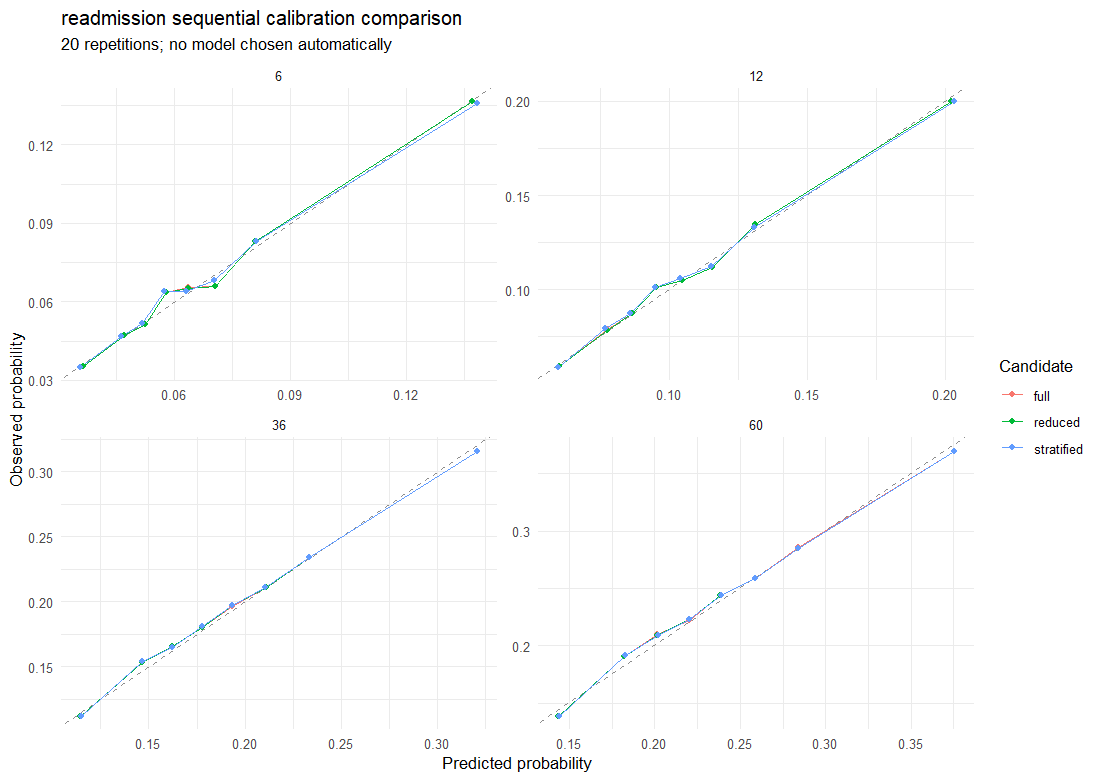

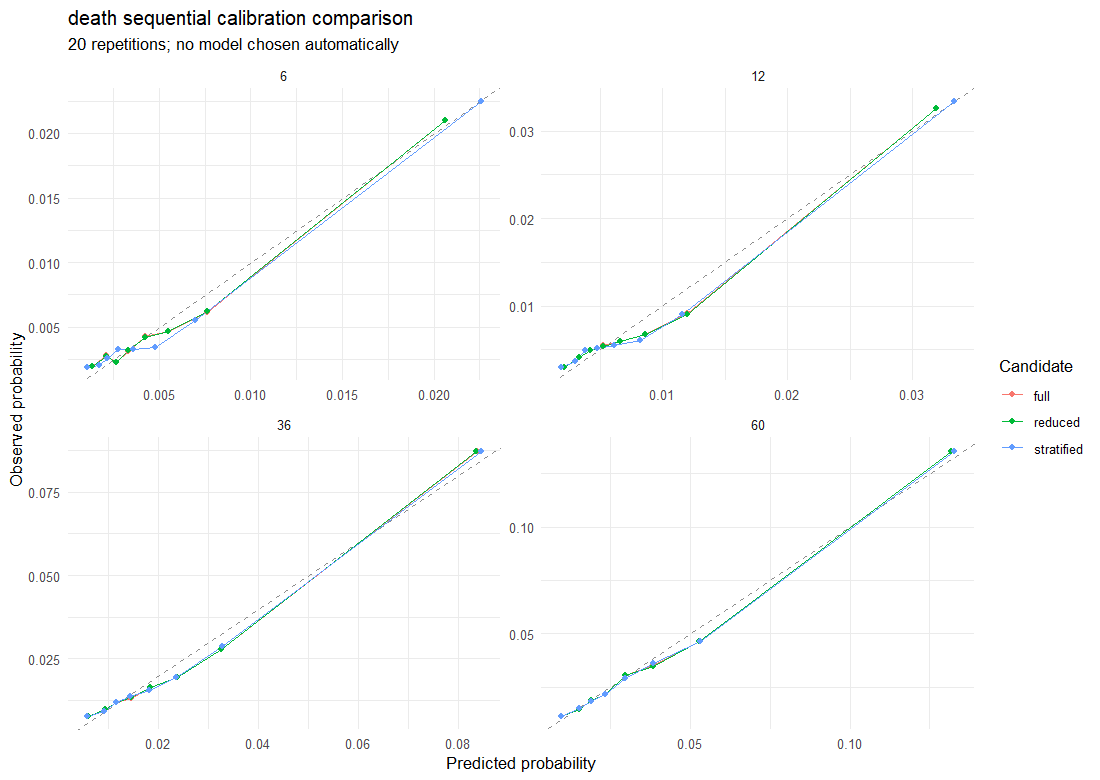

Predictive comparisons completed. New CV/calibration Cox fits in this run: 0 


Elapsed: 0.013 minutes


In [45]:
#| label: performance-sequential-checkpoint
#| message: true
.t0 <- proc.time()
# Show historical and sequential differences without selecting a model automatically.
if (length(performance_results)) {
  performance_table <- do.call(rbind, performance_results)
  paired <- merge(previous_metrics, performance_table, by = c("Outcome", "Stage", "Horizon"), suffixes = c("_previous", "_new"), sort = FALSE)
  paired$Delta_C <- paired$C_new - paired$C_previous
  paired$Delta_IBS <- paired$IBS_new - paired$IBS_previous
  paired$Classification_C_at_3dp <- ifelse(round(paired$C_new, 3) == round(paired$C_previous, 3), "trivial", "review: changes rounded value")
  paired$Classification_IBS_at_3dp <- ifelse(round(paired$IBS_new, 3) == round(paired$IBS_previous, 3), "trivial", "review: changes rounded value")
  show_table(paired, "Historical versus clean-imputation results; intermediate values are not all manuscript entries")
  sequential <- do.call(rbind, lapply(c("readmission", "death"), function(outcome) do.call(rbind, lapply(c("reduced", "stratified"), function(stage) {
    preceding <- if (stage == "reduced") "full" else "reduced"
    a <- performance_table[performance_table$Outcome == outcome & performance_table$Stage == preceding, ]
    b <- performance_table[performance_table$Outcome == outcome & performance_table$Stage == stage, ]
    b <- b[match(a$Horizon, b$Horizon), ]
    data.frame(Outcome = outcome, From = preceding, To = stage, Horizon = a$Horizon, Delta_C = b$C - a$C, Delta_IBS = b$IBS - a$IBS)
  }))))
  show_table(sequential, "Sequential changes: positive delta C and negative delta IBS indicate better performance")
  calibration_summary <- do.call(rbind, lapply(names(performance_calibration), function(stage) do.call(rbind, lapply(c("readmission", "death"), function(outcome) {
    d <- performance_calibration[[stage]][[outcome]]$pooled_summary
    data.frame(Outcome = outcome, Stage = stage, Horizon = d$time_months, ICI = d$ici_mean, ECE = d$ece_mean, EO = d$eo_mean)
  }))))
  show_table(calibration_summary, "Repeated calibration summaries; averages of 20 complete repetitions")
  calibration_curves <- do.call(rbind, lapply(names(performance_calibration), function(stage) do.call(rbind, lapply(c("readmission", "death"), function(outcome) {
    d <- performance_calibration[[stage]][[outcome]]$calibration_curves
    data.frame(Outcome = outcome, Stage = stage, Horizon = d$time_months, Predicted = d$mean_predicted, Observed = d$observed)
  }))))
  calibration_curves$Stage <- factor(calibration_curves$Stage, levels = c("full", "reduced", "stratified"))
  for (outcome in c("readmission", "death")) {
    figure <- ggplot2::ggplot(calibration_curves[calibration_curves$Outcome == outcome, ], ggplot2::aes(Predicted, Observed, colour = Stage)) + ggplot2::geom_abline(slope = 1, intercept = 0, linetype = 2, colour = "grey55") + ggplot2::geom_line() + ggplot2::geom_point(size = 1.4) + ggplot2::facet_wrap(~Horizon, scales = "free", ncol = 2) + ggplot2::theme_minimal(base_size = 11) + ggplot2::labs(title = paste(outcome, "sequential calibration comparison"), subtitle = "20 repetitions; no model chosen automatically", x = "Predicted probability", y = "Observed probability", colour = "Candidate")
    show_diagnostic_png(function() print(figure), width = 1100, height = 780)
  }
  invisible(performance_cache("sequential_checkpoint", function() list(metrics = paired, changes = sequential, calibration = calibration_summary, decision = "Investigator review at opening of 07; no candidate automatically selected")))
  cat("Predictive comparisons completed. New CV/calibration Cox fits in this run:", performance_new_fits, "\n")
} else cat("Predictive comparison is prepared; no new C, IBS or calibration result is available.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

## Preparation checkpoint and limitations
- The same development/holdout membership and five saved imputations are reused. Development imputations were fitted to development as a whole, as agreed; they are not refitted within each Cox validation fold. Do not claim fully independent preprocessing for internal CV.
- The NPH first-imputation scope is accepted. Differences at published precision or changes in selection still require their own checkpoint; this approval does not pre-approve future numerical changes.
- Historical model controls and new model figures have been executed. Prepare mode remains available for input checks. The exploratory resampling engine has a separate unresolved source-version numerical control and remains blocked until that control is recorded.
- Original exploratory CV uses 20 repetitions and its historical metric definitions. It is preserved as an optional diagnostic, not the final article's discrimination/IBS validation scheme. The requested final-definition C/IBS and calibration comparisons are now executed here; formal paired bootstrap contrasts remain in prediction225.
- No extra NPH sensitivity, bootstrap reduction, new dependency, Word change or cohort exclusion was introduced. The code is self-contained; the original helper scripts are provenance only, not runtime dependencies.


## Session info


## Historical calibration and published Table 2 points
The mortality stratified Full specification maps to the all-predictor mortality block in Table 2. Intermediate historical values are displayed separately. Published confidence intervals are not copied onto new point estimates; formal paired bootstrap work remains in prediction225. Changed published rounding requires investigator review before notebook 07.

In [46]:
#| label: comparison-historical-calibration-and-table2
#| message: true
.t0 <- proc.time()
# Display matched historical calibration values without refitting or selecting a candidate.
if (length(performance_results)) {
  old_calibration <- calibration_historical_control[, c("outcome", "stage", "months", "ICI", "ECE", "E_O")]
  names(old_calibration) <- c("Outcome", "Stage", "Horizon", "ICI", "ECE", "EO")
  calibration_comparison <- merge(old_calibration, calibration_summary, by = c("Outcome", "Stage", "Horizon"), suffixes = c("_previous", "_new"), sort = FALSE)
  stopifnot(nrow(calibration_comparison) == 24L)
  for (metric in c("ICI", "ECE", "EO")) calibration_comparison[[paste0("Delta_", metric)]] <- calibration_comparison[[paste0(metric, "_new")]] - calibration_comparison[[paste0(metric, "_previous")]]
  show_table(calibration_comparison, "Historical versus current calibration; these are historical point references, not all published Table 2 entries")
  # Identify point-ranking reversals explicitly; smaller errors and E/O closer to one are preferred.
  calibration_step_rows <- list()
  stage_pairs <- list(c("full", "reduced"), c("full", "stratified"), c("reduced", "stratified"))
  for (outcome in c("readmission", "death")) for (stages in stage_pairs) for (metric in c("ICI", "ECE", "EO")) {
    a <- calibration_comparison[calibration_comparison$Outcome == outcome & calibration_comparison$Stage == stages[1L], ]
    b <- calibration_comparison[calibration_comparison$Outcome == outcome & calibration_comparison$Stage == stages[2L], ]
    b <- b[match(a$Horizon, b$Horizon), ]
    old_a <- a[[paste0(metric, "_previous")]]
    old_b <- b[[paste0(metric, "_previous")]]
    new_a <- a[[paste0(metric, "_new")]]
    new_b <- b[[paste0(metric, "_new")]]
    if (metric == "EO") {
      old_a <- abs(old_a - 1)
      old_b <- abs(old_b - 1)
      new_a <- abs(new_a - 1)
      new_b <- abs(new_b - 1)
    }
    calibration_step_rows[[paste(outcome, paste(stages, collapse = "_"), metric)]] <- data.frame(Outcome = outcome, From = stages[1L], To = stages[2L], Horizon = a$Horizon, Metric = metric, Previous_difference = old_b - old_a, New_difference = new_b - new_a)
  }
  calibration_steps <- do.call(rbind, calibration_step_rows)
  stopifnot(nrow(calibration_steps) == 72L)
  calibration_ranking_reversals <- calibration_steps[calibration_steps$Previous_difference * calibration_steps$New_difference < 0, ]
  calibration_ranking_reversals$Classification <- "substantial: candidate point ranking reverses"
  show_table(calibration_ranking_reversals, "Calibration point-ranking reversals; positive differences indicate larger error; E/O uses distance from one")
  cat("These small calibration reversals require review under the investigator's explicit rule. They do not automatically select another model or establish a performance difference; no new bootstrap is used here.\n")
  # Read Table 2 directly from the authoritative Word document, without changing it.
  table2_node <- xml2::xml_find_all(document, "//w:body/w:p[starts-with(normalize-space(.), 'Table 2.')]/following-sibling::w:tbl[1]", namespace)
  stopifnot(length(table2_node) == 1L)
  table2_matrix <- do.call(rbind, lapply(xml2::xml_find_all(table2_node, "./w:tr", namespace), function(row) vapply(xml2::xml_find_all(row, "./w:tc", namespace), function(cell) paste(xml2::xml_text(xml2::xml_find_all(cell, ".//w:t", namespace)), collapse = ""), character(1L))))
  block_start <- which(table2_matrix[, 1L] == "Mortality, all predictors")
  stopifnot(length(block_start) == 1L)
  published_rows <- table2_matrix[block_start + seq_along(performance_horizons), , drop = FALSE]
  stopifnot(identical(as.numeric(published_rows[, 1L]), performance_horizons))
  current_points <- merge(performance_table[performance_table$Outcome == "death" & performance_table$Stage == "stratified", ], calibration_summary[calibration_summary$Outcome == "death" & calibration_summary$Stage == "stratified", ], by = c("Outcome", "Stage", "Horizon"), sort = FALSE)
  current_points <- current_points[match(performance_horizons, current_points$Horizon), ]
  table2_comparison <- do.call(rbind, lapply(seq_along(performance_horizons), function(i) do.call(rbind, lapply(c("C", "IBS", "ICI", "EO"), function(metric) {
    column <- match(metric, c("C", "IBS", "ICI", "EO")) + 1L
    previous <- parse_numbers(published_rows[i, column])[[1L]]
    digits <- if (metric == "EO") 2L else 3L
    value <- current_points[[metric]][i]
    data.frame(Manuscript = "Table 2: Mortality, all predictors", Outcome = "death", Stage = "stratified", Horizon = performance_horizons[i], Metric = metric, Previous_published = previous, New = value, Difference_from_published = value - previous, Published_decimals = digits, Classification = if (round(value, digits) == previous) "trivial" else "substantial: published rounding changes")
  }))))
  stopifnot(nrow(table2_comparison) == 16L, all(is.finite(table2_comparison$New)))
  show_table(table2_comparison, "Table 2 mortality Full: published versus new point estimates; no new bootstrap confidence intervals in 06")
  destination <- file.path(table_dir, paste0("Table2_mortality_full_point_comparison_", cox_date, "_", performance_signature, ".csv"))
  utils::write.csv(table2_comparison, destination, row.names = FALSE, na = "")
  written <- c(written, destination)
  cat("The readmission Full and intermediate stages have no separate point-estimate block in Table 2. Their published contrasts belong to eTables 11-12; paired bootstrap comparisons remain for prediction225.\n")
  # Reproduce the published point contrasts before comparing current values; no new intervals are inferred.
  point_rows <- list()
  predictor_labels <- c(full = "Full PH base", reduced = "Full PH updated", stratified = "All-predictor, without collinear term")
  for (table_number in c(11L, 12L)) {
    caption <- paste0("eTable ", table_number, ". Paired differences in horizon-specific")
    node <- xml2::xml_find_all(document, paste0("//w:body/w:p[starts-with(normalize-space(.), '", caption, "')]/following-sibling::w:tbl[1]"), namespace)
    stopifnot(length(node) == 1L)
    rows <- lapply(xml2::xml_find_all(node, "./w:tr", namespace), function(row) vapply(xml2::xml_find_all(row, "./w:tc", namespace), function(cell) paste(xml2::xml_text(xml2::xml_find_all(cell, ".//w:t", namespace)), collapse = ""), character(1L)))
    outcome <- NA_character_
    net_arm <- FALSE
    metric <- if (table_number == 11L) "C" else "IBS"
    digits <- if (table_number == 11L) 4L else 6L
    for (row in rows) {
      label <- row[1L]
      if (label == "First readmission") outcome <- "readmission"
      if (grepl("mortality", label, ignore.case = TRUE) && !grepl(" vs ", label, fixed = TRUE) && !startsWith(label, "Cumulative incidence")) outcome <- "death"
      if (startsWith(label, "Net risk")) net_arm <- TRUE
      if (startsWith(label, "Cumulative incidence")) net_arm <- FALSE
      if (is.na(outcome) || (table_number == 12L && (outcome != "readmission" || !net_arm))) next
      pair <- strsplit(label, " vs ", fixed = TRUE)[[1L]]
      if (length(pair) != 2L) next
      a_stage <- names(predictor_labels)[vapply(predictor_labels, function(prefix) startsWith(pair[1L], prefix), logical(1L))]
      b_stage <- names(predictor_labels)[vapply(predictor_labels, function(prefix) startsWith(pair[2L], prefix), logical(1L))]
      if (length(a_stage) != 1L || length(b_stage) != 1L) next
      stopifnot(length(row) == 5L)
      for (i in seq_along(performance_horizons)) {
        horizon <- performance_horizons[i]
        a <- paired[paired$Outcome == outcome & paired$Stage == a_stage & paired$Horizon == horizon, ]
        b <- paired[paired$Outcome == outcome & paired$Stage == b_stage & paired$Horizon == horizon, ]
        stopifnot(nrow(a) == 1L, nrow(b) == 1L)
        previous <- parse_numbers(row[i + 1L])[1L]
        historical <- a[[paste0(metric, "_previous")]] - b[[paste0(metric, "_previous")]]
        current <- a[[paste0(metric, "_new")]] - b[[paste0(metric, "_new")]]
        stopifnot(round(historical, digits) == previous)
        key <- paste(table_number, outcome, a_stage, b_stage, horizon)
        stopifnot(is.null(point_rows[[key]]))
        point_rows[[key]] <- data.frame(Manuscript = paste0("eTable ", table_number), Outcome = outcome, A = a_stage, B = b_stage, Horizon = horizon, Metric = paste0("Delta_", metric), Definition = "A minus B", Previous_published = previous, Historical_control = historical, New = current, New_rounded = round(current, digits), Difference_from_published = current - previous, Published_decimals = digits, Classification = if (round(current, digits) == previous) "trivial" else "substantial: published rounding changes")
      }
    }
  }
  supplement_point_comparison <- do.call(rbind, point_rows)
  stopifnot(nrow(supplement_point_comparison) == 36L, sum(supplement_point_comparison$Manuscript == "eTable 11") == 24L, sum(supplement_point_comparison$Manuscript == "eTable 12") == 12L)
  show_table(supplement_point_comparison, "eTables 11-12: published point contrasts for these three candidates; historical points reproduced first; bootstrap intervals remain pending")
  for (table_number in c(11L, 12L)) {
    destination <- file.path(table_dir, paste0("eTable", table_number, "_full_candidates_point_comparison_", cox_date, "_", performance_signature, ".csv"))
    utils::write.csv(supplement_point_comparison[supplement_point_comparison$Manuscript == paste0("eTable ", table_number), ], destination, row.names = FALSE, na = "")
    written <- c(written, destination)
  }
  cat("These are point contrasts only. Original confidence intervals and significance statements cannot be transferred to the new estimates; paired bootstrap remains in prediction225.\n")
  if (any(table2_comparison$Classification != "trivial")) cat("Substantial Table 2 point differences require investigator review before 07; the manuscript has not been modified.\n")
} else cat("Historical calibration and Table 2 comparisons await the full predictive run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Stage,Horizon,ICI_previous,ECE_previous,EO_previous,ICI_new,ECE_new,EO_new,Delta_ICI,Delta_ECE,Delta_EO
readmission,full,6,0.0060,0.0022,0.9912,0.0060,0.0021,0.9913,0e+00,-1e-04,1e-04
readmission,full,12,0.0075,0.0027,0.9911,0.0075,0.0026,0.9912,0e+00,-1e-04,1e-04
readmission,full,36,0.0095,0.0039,0.9882,0.0095,0.0038,0.9883,0e+00,-1e-04,1e-04
readmission,full,60,0.0103,0.0054,0.9839,0.0103,0.0052,0.9840,0e+00,-2e-04,1e-04
readmission,reduced,6,0.0060,0.0022,0.9913,0.0060,0.0021,0.9913,0e+00,-1e-04,1e-04
readmission,reduced,12,0.0075,0.0026,0.9911,0.0075,0.0025,0.9912,0e+00,-1e-04,1e-04
readmission,reduced,36,0.0095,0.0040,0.9882,0.0095,0.0038,0.9883,0e+00,-2e-04,1e-04
readmission,reduced,60,0.0103,0.0054,0.9839,0.0103,0.0051,0.9840,0e+00,-2e-04,1e-04
readmission,stratified,6,0.0065,0.0022,0.9898,0.0065,0.0021,0.9899,0e+00,0e+00,1e-04
readmission,stratified,12,0.0080,0.0027,0.9900,0.0080,0.0027,0.9901,0e+00,0e+00,1e-04


Outcome,From,To,Horizon,Metric,Previous_difference,New_difference,Classification
readmission,full,reduced,6,ECE,0e+00,0e+00,substantial: candidate point ranking reverses
readmission,full,reduced,36,ECE,0e+00,0e+00,substantial: candidate point ranking reverses
readmission,full,stratified,6,ECE,-1e-04,0e+00,substantial: candidate point ranking reverses
readmission,full,stratified,36,ECE,0e+00,2e-04,substantial: candidate point ranking reverses
readmission,reduced,stratified,6,ECE,0e+00,0e+00,substantial: candidate point ranking reverses
readmission,reduced,stratified,36,ECE,0e+00,2e-04,substantial: candidate point ranking reverses
death,full,reduced,12,ICI,0e+00,0e+00,substantial: candidate point ranking reverses
death,full,reduced,6,ECE,0e+00,0e+00,substantial: candidate point ranking reverses
death,full,reduced,60,ECE,0e+00,0e+00,substantial: candidate point ranking reverses


Manuscript,Outcome,Stage,Horizon,Metric,Previous_published,New,Difference_from_published,Published_decimals,Classification
"Table 2: Mortality, all predictors",death,stratified,6,C,0.784,0.7835,-0.0005,3,substantial: published rounding changes
"Table 2: Mortality, all predictors",death,stratified,6,IBS,0.004,0.0044,0.0004,3,trivial
"Table 2: Mortality, all predictors",death,stratified,6,ICI,0.002,0.0024,0.0004,3,trivial
"Table 2: Mortality, all predictors",death,stratified,6,EO,1.010,1.0069,-0.0031,2,trivial
"Table 2: Mortality, all predictors",death,stratified,12,C,0.767,0.7663,-0.0007,3,substantial: published rounding changes
"Table 2: Mortality, all predictors",death,stratified,12,IBS,0.006,0.0064,0.0004,3,trivial
"Table 2: Mortality, all predictors",death,stratified,12,ICI,0.003,0.0031,0.0001,3,trivial
"Table 2: Mortality, all predictors",death,stratified,12,EO,1.010,1.0096,-0.0004,2,trivial
"Table 2: Mortality, all predictors",death,stratified,36,C,0.765,0.7652,0.0002,3,trivial
"Table 2: Mortality, all predictors",death,stratified,36,IBS,0.014,0.0144,0.0004,3,trivial


Manuscript,Outcome,A,B,Horizon,Metric,Definition,Previous_published,Historical_control,New,New_rounded,Difference_from_published,Published_decimals,Classification
eTable 11,readmission,full,reduced,6,Delta_C,A minus B,0.0000,0.0000,0.0000,0.0000,0e+00,4,trivial
eTable 11,readmission,full,reduced,12,Delta_C,A minus B,-0.0001,-0.0001,0.0000,0.0000,1e-04,4,substantial: published rounding changes
eTable 11,readmission,full,reduced,36,Delta_C,A minus B,-0.0001,-0.0001,-0.0001,-0.0001,0e+00,4,trivial
eTable 11,readmission,full,reduced,60,Delta_C,A minus B,0.0000,0.0000,0.0000,0.0000,0e+00,4,trivial
eTable 11,readmission,full,stratified,6,Delta_C,A minus B,-0.0012,-0.0012,-0.0012,-0.0012,0e+00,4,trivial
eTable 11,readmission,full,stratified,12,Delta_C,A minus B,-0.0003,-0.0003,-0.0003,-0.0003,0e+00,4,trivial
eTable 11,readmission,full,stratified,36,Delta_C,A minus B,0.0001,0.0001,0.0001,0.0001,0e+00,4,trivial
eTable 11,readmission,full,stratified,60,Delta_C,A minus B,0.0001,0.0001,0.0001,0.0001,0e+00,4,trivial
eTable 11,readmission,reduced,stratified,6,Delta_C,A minus B,-0.0011,-0.0011,-0.0011,-0.0011,0e+00,4,trivial
eTable 11,readmission,reduced,stratified,12,Delta_C,A minus B,-0.0002,-0.0002,-0.0002,-0.0002,0e+00,4,trivial


These small calibration reversals require review under the investigator's explicit rule. They do not automatically select another model or establish a performance difference; no new bootstrap is used here.
The readmission Full and intermediate stages have no separate point-estimate block in Table 2. Their published contrasts belong to eTables 11-12; paired bootstrap comparisons remain for prediction225.
These are point contrasts only. Original confidence intervals and significance statements cannot be transferred to the new estimates; paired bootstrap remains in prediction225.
Substantial Table 2 point differences require investigator review before 07; the manuscript has not been modified.


Elapsed: 0.003 minutes


## Complete comparison checks
Every requested candidate, horizon and calibration repetition must be present, with finite metrics and complete prediction coverage. Calibration-bin exclusions are reported separately from cohort exclusions. This verifies execution; candidate selection remains an investigator decision before notebook 07.

In [47]:
#| label: comparison-completeness-check
#| message: true
.t0 <- proc.time()
# Verify every requested result and cached fold before declaring this notebook complete.
if (identical(performance_settings$mode, "full")) {
  stages <- c("full", "reduced", "stratified")
  outcomes <- c("readmission", "death")
  n_participants <- nrow(py_corrected_datasets[[1L]])
  stopifnot(length(performance_results) == 6L, nrow(performance_table) == 24L, !anyDuplicated(performance_table[, c("Outcome", "Stage", "Horizon")]), all(is.finite(as.matrix(performance_table[, c("C", "IBS")]))))
  completeness_rows <- list()
  reference_fold_indices <- list()
  for (stage in stages) for (outcome in outcomes) {
    value <- performance_calibration[[stage]][[outcome]]
    metrics <- if (outcome == "readmission") value$by_repetition else value$rep_results
    stopifnot(nrow(metrics) == 80L, identical(as.numeric(metrics$time_months), rep(performance_horizons, 20L)), all(is.finite(as.matrix(metrics[, c("ici", "ece", "eo_ratio")]))))
    excluded <- 0L
    if (outcome == "readmission") {
      stopifnot(!anyDuplicated(metrics[, c("repetition", "time_months")]), identical(as.integer(metrics$repetition), rep(seq_len(20L), each = 4L)), all(metrics$n_input == n_participants), all(metrics$n_analysis == n_participants), all(metrics$n_dropped == 0L), all(metrics$n_imputations == 5L), all(metrics$n_used_calibration + metrics$n_excluded_calibration == n_participants))
      excluded <- max(metrics$n_excluded_calibration)
    }
    # Reload all prediction tasks: every participant must occur once in each repetition.
    for (repetition in seq_len(20L)) {
      indices <- integer()
      for (fold in seq_len(5L)) {
        cache_name <- sprintf("cal_%s_%s_r%02d_f%02d", outcome, stage, repetition, fold)
        found <- list.files(object_dir, pattern = paste0("^perf06_", cache_name, "_[0-9-]+_", performance_signature, "\\.rds$"), full.names = TRUE)
        stopifnot(length(found) == 1L)
        saved <- readRDS(found[[1L]])
        stopifnot(identical(saved$signature, performance_signature), saved$value$r == repetition)
        rows <- if (outcome == "readmission") saved$value$te_idx else saved$value$test_idx
        risk <- if (outcome == "readmission") saved$value$pred_fold_avg else saved$value$risk_mat
        stopifnot(identical(dim(risk), c(length(rows), length(performance_horizons))), all(is.finite(risk)), all(risk >= 0 & risk <= 1), all(rows >= 1L & rows <= n_participants))
        fold_key <- paste(outcome, repetition, fold, sep = "_")
        if (stage == "full") reference_fold_indices[[fold_key]] <- rows else stopifnot(identical(reference_fold_indices[[fold_key]], rows))
        indices <- c(indices, rows)
      }
      stopifnot(length(indices) == n_participants, all(tabulate(indices, nbins = n_participants) == 1L))
    }
    completeness_rows[[paste(outcome, stage)]] <- data.frame(Outcome = outcome, Stage = stage, Participants_per_repetition = n_participants, Calibration_repetitions = 20L, Prediction_tasks = 100L, Complete_horizon_metrics = nrow(metrics), Maximum_excluded_from_calibration_bins = if (outcome == "readmission") excluded else NA_integer_)
  }
  completeness_table <- do.call(rbind, completeness_rows)
  show_table(completeness_table, "Complete evaluation verified; calibration-bin exclusions are separate from cohort exclusions")
  comparison_check <- list(status = "complete_comparisons_pending_investigator_choice", checked_at = format(Sys.time(), "%Y-%m-%dT%H:%M:%S%z"), cox_signature = cox_signature, performance_signature = performance_signature, historical_c_ibs_control_max_difference = max(metric_control$Maximum_absolute_difference), historical_calibration_reaggregation_max_difference = max(calibration_historical_control$max_abs_difference), new_diagnostic_fits = cox_fits_new, new_performance_fits_this_execution = performance_new_fits, c_ibs_rows = nrow(performance_table), shared_calibration_partitions_verified = TRUE, completeness = completeness_table, decision = "No automatic selection; review sequential changes before 07")
  jsonlite::write_json(comparison_check, file.path(resolve_path(config$paths$docs), "06_full_comparison_check.json"), pretty = TRUE, auto_unbox = TRUE, digits = 16)
  cat("All six comparisons are complete. Candidate selection remains pending.\n")
} else cat("Completeness check awaits the full predictive run.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Stage,Participants_per_repetition,Calibration_repetitions,Prediction_tasks,Complete_horizon_metrics,Maximum_excluded_from_calibration_bins
readmission,full,70521,20,100,80,0
death,full,70521,20,100,80,NA
readmission,reduced,70521,20,100,80,0
death,reduced,70521,20,100,80,NA
readmission,stratified,70521,20,100,80,0
death,stratified,70521,20,100,80,NA


All six comparisons are complete. Candidate selection remains pending.


Elapsed: 0.270 minutes


In [48]:
#| label: cox-session-info
#| message: false
.t0 <- proc.time()
# Use base R session information; display loaded packages in the same browsable table style.
session <- utils::sessionInfo()
quarto_version <- system2(resolve_path(config$runtime$quarto_executable), "--version", stdout = TRUE, stderr = TRUE)
show_table(data.frame(Item = c("R", "Platform", "Operating system", "Run date", "Quarto", "Mode", "Base seed", "Threads"), Value = c(session$R.version$version.string, session$platform, session$running, format(Sys.time(), "%Y-%m-%d %H:%M:%S %Z"), paste(quarto_version, collapse = " "), config$cox_table1$mode, config$imputation$seed, threads)), "Session information")
session_packages <- c(session$otherPkgs, session$loadedOnly)
package_table <- do.call(rbind, lapply(session_packages, function(x) data.frame(Package = x$Package, Version = x$Version, Source = if (is.null(x$Repository)) "Installed library" else x$Repository)))
show_table(package_table[order(package_table$Package), , drop = FALSE], "Loaded R packages")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Item,Value
R,R version 4.4.1 (2024-06-14 ucrt)
Platform,x86_64-w64-mingw32/x64
Operating system,Windows 11 x64 (build 26200)
Run date,2026-10-05 17:47:43 -03
Quarto,1.9.36
Mode,review
Base seed,2125
Threads,2


Package,Version,Source
Cairo,1.6-2,CRAN
Formula,1.2-5,RSPM
Hmisc,5.2-5,CRAN
IRdisplay,1.1,RSPM
IRkernel,1.3.2,CRAN
KMsurv,0.1-6,RSPM
MASS,7.3-60.2,CRAN
Matrix,1.7-0,CRAN
MatrixModels,0.5-3,RSPM
R6,2.6.1,RSPM


Elapsed: 0.008 minutes


## Files written in outputs


In [49]:
#| label: cox-written-files-and-status
#| message: false
.t0 <- proc.time()
# List actual writes and distinguish prepared blocks from executed model results.
written <- unique(c(written, cox_written))
manifest <- data.frame(Path = substring(written, nchar(root) + 2L), Bytes = as.numeric(file.info(written)$size))
show_table(manifest, "Files written in outputs during this run")
cox_status <- if (!run_cox) "cox_prepared_not_fitted" else "cox_diagnostics_executed"
status <- list(status = cox_status, kernel = "r-main", threads = threads, signature = table1_signature, review_signature = review_signature, cox_signature = cox_signature, cox_mode = cox_settings$mode, participants = nrow(completed), development = sum(train), holdout = sum(!train), compared_components = nrow(comparison), substantial = sum(comparison$Classification == "substantial"), historical_control_rows = nrow(control), new_model_fits = cox_fits_new, new_imputation_fits = 0L, new_resampling_batches = cox_resampling_new, elapsed_seconds = as.numeric(difftime(Sys.time(), run_started, units = "secs")), artifacts = manifest$Path, manuscript_sha256 = input_hashes$manuscript)
cat(jsonlite::toJSON(status, auto_unbox = TRUE), "\n")
show_table(data.frame(Measurement = names(ps::ps_memory_info()), Bytes = as.numeric(ps::ps_memory_info())), "Current R process memory")
stopifnot(file.info(source_path("cox_preparation_notebook"))$size < 30000000)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Path,Bytes
outputs/tables/Table2_mortality_full_point_comparison_2026-10-05_d2d6c6bd02f5.csv,2197
outputs/tables/eTable11_full_candidates_point_comparison_2026-10-05_d2d6c6bd02f5.csv,4133
outputs/tables/eTable12_full_candidates_point_comparison_2026-10-05_d2d6c6bd02f5.csv,2195
outputs/tables/eTable10_full_PH_comparison_2026-10-05_fcd1bd763f13.csv,785
outputs/figures/eFigure3_panelA_full_PH_2026-10-05_fcd1bd763f13.png,17904
outputs/figures/eFigure4_panelA_full_PH_2026-10-05_fcd1bd763f13.png,20062


{"status":"cox_diagnostics_executed","kernel":"r-main","threads":2,"signature":"1584a5c4e1ef","review_signature":"b72969a4e086","cox_signature":"fcd1bd763f13","cox_mode":"diagnostics","participants":88152,"development":70521,"holdout":17631,"compared_components":473,"substantial":128,"historical_control_rows":89,"new_model_fits":0,"new_imputation_fits":0,"new_resampling_batches":0,"elapsed_seconds":58.8268,"artifacts":["outputs/tables/Table2_mortality_full_point_comparison_2026-10-05_d2d6c6bd02f5.csv","outputs/tables/eTable11_full_candidates_point_comparison_2026-10-05_d2d6c6bd02f5.csv","outputs/tables/eTable12_full_candidates_point_comparison_2026-10-05_d2d6c6bd02f5.csv","outputs/tables/eTable10_full_PH_comparison_2026-10-05_fcd1bd763f13.csv","outputs/figures/eFigure3_panelA_full_PH_2026-10-05_fcd1bd763f13.png","outputs/figures/eFigure4_panelA_full_PH_2026-10-05_fcd1bd763f13.png"],"manuscript_sha256":"3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a"} 


Measurement,Bytes
num_page_faults,1402331
peak_wset,2200354816
wset,2042040320
peak_paged_pool,523416
paged_pool,510352
peak_non_paged_pool,1122328
non_paged_pool,68520
pagefile,2065367040
peak_pagefile,2223104000
mem_private,2065367040


Elapsed: 0.001 minutes
